# Codigo base

In [1]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos
PBIcf: Propatto. ipc: Ferreres: Fundación Norte y Sur (1935 a 1942) y Argentina.gob DATOS (1943 a 2023). E: Ferreres (1935 a 1939) y Argentina.gob DATOS (1940 a 2025). USDA para precios commodities. NBER (1935 a 1956), FMI (1957 a 2012) y BLS (FRED) (2013 a 2023) para impp_usa

In [2]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_anual_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx]
  Date: 2026-11-02 18:20
  Status: 200
  Content-Type: application/octet-stream
  Size: 17.4 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpVSPpBP/file905016860144.xlsxNULL

In [4]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_anual_crudo |> 
  #dplyr::slice(37:dplyr::n()) |>  # Equivalent to iloc[36:] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))
print(tail(df_Arg, 6))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405739 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720435 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276261 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765392 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826696 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165913 0.8466667 1.0356667  0.7390833
    año          ipc            E  PBIcf  impp_usa Psoja_USA Pmaíz_USA
1  1935 7.378080e-14 3.802200e-13  64823  4.405739 0.9775000 0.7735000
2  1936 8.002798e-14 3.594700e-13  66725  4.720435 0.9666667 0.7676667
3  1937 8.214241e-14 3.328900e-13  71248  5.276261 1.2591667 0.9477500
4  1938 8.159778e-14 3.915700e-13  73059  4.765392 0.7941667 0.4900833
5  1939 8.287925e-14 4.328000e-13  75573  4.826696 0.7716667 0.4761667
6  1940 8.473739e-14 

In [5]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405739 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720435 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276261 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765392 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826696 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165913 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIcf impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -30.23768 -28.59803 11.07942 1.482908 -0.02275699 -0.25682961
2 1936 -30.15640 -28.65415 11.10833 1.551901 -0.03390155 -0.26439967
3 1937 -30.13032 -28.73096 11.17392 1.663218  0.23045013 -0.05366452
4 1938 -30.13697 -28.56861 11.19902 1.561380 -0.23046193 -0.71317983
5 1939 -30.12139 -28.46850 11.23285 1.574162 -0.25920260 -0.74198735
6 1940 -30.09922 -28.45924 11.247

In [6]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "PBIcf", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año          ipc            E PBIcf impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 7.378080e-14 3.802200e-13 64823 4.405739 0.9775000 0.7735000  0.8595833
2 1936 8.002798e-14 3.594700e-13 66725 4.720435 0.9666667 0.7676667  0.9578333
3 1937 8.214241e-14 3.328900e-13 71248 5.276261 1.2591667 0.9477500  1.0713333
4 1938 8.159778e-14 3.915700e-13 73059 4.765392 0.7941667 0.4900833  0.6611667
5 1939 8.287925e-14 4.328000e-13 75573 4.826696 0.7716667 0.4761667  0.6355833
6 1940 8.473739e-14 4.368283e-13 76724 5.165913 0.8466667 1.0356667  0.7390833


   año       ipc         E    PBIcf impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -30.23768 -28.59803 11.07942 1.482908 -0.02275699 -0.25682961
2 1936 -30.15640 -28.65415 11.10833 1.551901 -0.03390155 -0.26439967
3 1937 -30.13032 -28.73096 11.17392 1.663218  0.23045013 -0.05366452
4 1938 -30.13697 -28.56861 11.19902 1.561380 -0.23046193 -0.71317983
5 1939 -30.12139 -28.46850 11.23285 1.574162 -0.25920260 -0.74198735
6 1940 -30.09922 -28.45924 11.24797 1.642082 -0.16644821  0.03504534
   Ptrigo_USA
1 -0.15130750
2 -0.04308149
3  0.06890398
4 -0.41374933
5 -0.45321207
6 -0.30234460
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
2 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
3 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
4 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
5 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
6 1940  0.022172162

### Recorto Dataframe: 1935 a 2023

In [7]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_2023 <- df_ERPT_Arg |> 
  dplyr::slice(1: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023, 6))
print(tail(df_ERPT_Arg_1935_2023, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1974

In [8]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1974 <- df_ERPT_Arg |> 
  dplyr::slice(1:39 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974, 6))
print(tail(df_ERPT_Arg_1935_1974, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1975

In [9]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1975 <- df_ERPT_Arg |> 
  dplyr::slice(1:40 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975, 6))
print(tail(df_ERPT_Arg_1935_1975, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1982

In [10]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1982 <- df_ERPT_Arg |> 
  dplyr::slice(1:47 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982, 6))
print(tail(df_ERPT_Arg_1935_1982, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1987

In [11]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1987 <- df_ERPT_Arg |> 
  dplyr::slice(1:52 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987, 6))
print(tail(df_ERPT_Arg_1935_1987, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

### Recorto dataframe: 1935 a 1990

In [12]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1990 <- df_ERPT_Arg |> 
  dplyr::slice(1:55 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIcf, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990, 6))
print(tail(df_ERPT_Arg_1935_1990, 6))

   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0.10011143 0.03383174  0.01278245 -0.02874067 -0.028807512
5 1940  0.022172162  0.00926456 0.01511549  0.06791976  0.09275439  0.777032688
6 1941  0.026120888 -0.03080969 0.04844005  0.06434072  0.36461577 -0.477174434
   Ptrigo_USA
1  0.10822601
2  0.11198547
3 -0.48265331
4 -0.03946274
5  0.15086747
6  0.12739580
   año          ipc           E      PBIcf    impp_usa   Psoja_USA    Pmaíz_USA
1 1936  0.081277791 -0.05611931 0.02891922  0.06899287 -0.01114456 -0.007570059
2 1937  0.026078127 -0.07681862 0.06558705  0.11131677  0.26435168  0.210735143
3 1938 -0.006652343  0.16235219 0.02510059 -0.10183802 -0.46091206 -0.659515310
4 1939  0.015582707  0

    año       ipc         E        PBIcf    impp_usa   Psoja_USA   Pmaíz_USA
50 1985 2.0440492 2.1229946 -0.069853331 -0.02487960 -0.25791994 -0.20170426
51 1986 0.6423295 0.4342140  0.059720648 -0.03324891 -0.07997866 -0.24052356
52 1987 0.8386953 0.9144561  0.022943442  0.06623556  0.01405563 -0.22954699
53 1988 1.4882954 1.5494671 -0.013656293  0.05381166  0.35137356  0.37870040
54 1989 3.4592946 3.7338591 -0.059774246  0.08809110 -0.08359264  0.06835728
55 1990 3.1838548 2.3784170 -0.008324026  0.03187302 -0.13037772 -0.01483041
    Ptrigo_USA
50 -0.07988227
51 -0.16608290
52 -0.05895243
53  0.26489753
54  0.15278989
55 -0.26255779


# Regresiones

### 1935-2023. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"impp_usa, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6185443,-0.6185443,-0.6185443
2,impp_usa,E,1,0.8677216,-0.1619036,1.8973467
3,impp_usa,E,2,2.0043492,0.7804608,3.2282375
4,impp_usa,E,3,0.6886815,-0.4637490,1.8411120
5,impp_usa,E,4,0.2636564,-1.2319771,1.7592899


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.05212636,-0.4201721,0.3159194
38,ipc,E,2,-0.02830088,-0.4099945,0.3533928
39,ipc,E,3,0.14412813,-0.3700292,0.6582855
40,ipc,E,4,0.44124107,-0.1203171,1.0027993


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.00000000,0.0000000,0.00000000
52,PBIcf,E,1,0.44775859,-0.5970969,1.49261412
53,PBIcf,E,2,-0.02604916,-1.3850337,1.33293541
54,PBIcf,E,3,-1.41658303,-2.7844911,-0.04867498
55,PBIcf,E,4,-2.57195685,-4.0804064,-1.06350726


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
57,PBIcf,ipc,1,1.1786416,0.3454833,2.01180003
58,PBIcf,ipc,2,0.3859276,-0.7353650,1.50722027
59,PBIcf,ipc,3,-0.6751342,-2.0325612,0.68229283
60,PBIcf,ipc,4,-1.2235194,-2.5384094,0.09137068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIcf,0,-0.046192230,-0.04619223,-0.04619223
27,E,PBIcf,1,-0.011257059,-0.04503549,0.02252137
28,E,PBIcf,2,0.002193155,-0.02756420,0.03195051
29,E,PBIcf,3,0.003114001,-0.04234777,0.04857577
30,E,PBIcf,4,0.002791023,-0.01863527,0.02421732


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIcf,0,0.21029028,0.210290282,0.21029028
12,impp_usa,PBIcf,1,-0.05646861,-0.137341202,0.02440398
13,impp_usa,PBIcf,2,-0.05826988,-0.129258928,0.01271917
14,impp_usa,PBIcf,3,0.05634832,-0.001044851,0.11374149
15,impp_usa,PBIcf,4,0.05500822,-0.046597722,0.15661416


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIcf,0,0.011489700,0.01148970,0.011489700
42,ipc,PBIcf,1,0.010935361,-0.01391082,0.035781538
43,ipc,PBIcf,2,0.007990192,-0.01628161,0.032261989
44,ipc,PBIcf,3,-0.006371903,-0.03877465,0.026030846
45,ipc,PBIcf,4,-0.025582944,-0.04633483,-0.004831054


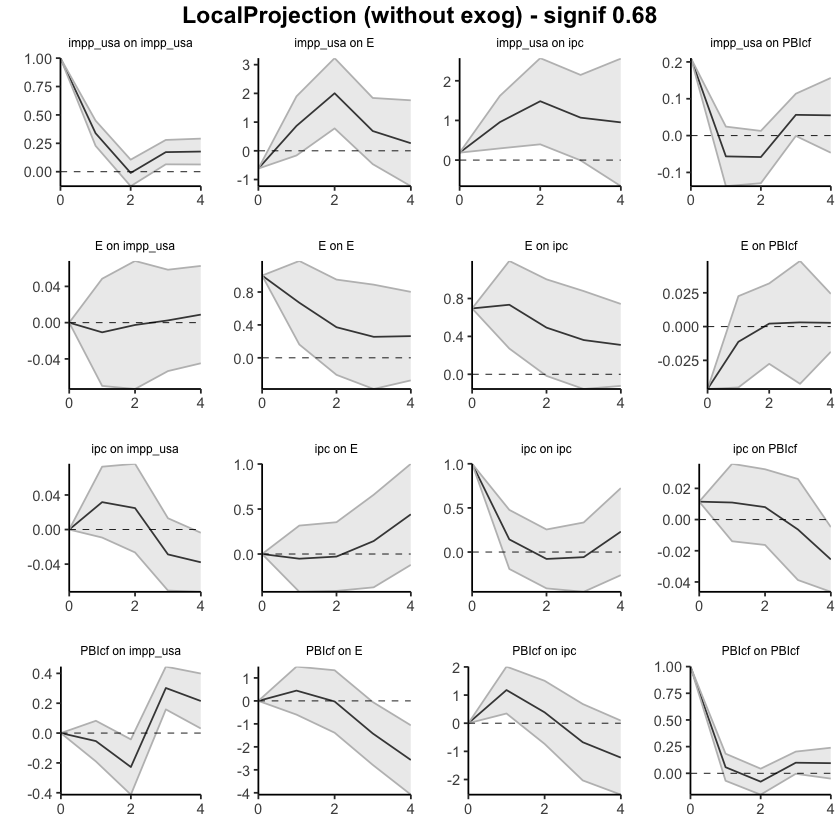

In [13]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("impp_usa", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.0146232,-0.3410060,0.3702524
38,ipc,E,2,0.0770998,-0.7231068,0.8773064
39,ipc,E,3,0.2708591,-1.0803544,1.6220727
40,ipc,E,4,0.7585382,-1.1810537,2.6981301


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.8222116,-0.1050500,1.749473
53,PBIcf,E,2,1.3303269,-0.5941675,3.254821
54,PBIcf,E,3,0.3372349,-2.9889596,3.663429
55,PBIcf,E,4,-1.7064366,-6.3795741,2.966701


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.45019591,-0.4501959,-0.4501959
2,Psoja_USA,E,1,-0.50107511,-0.8195458,-0.1826044
3,Psoja_USA,E,2,-0.06826267,-0.6038253,0.4672999
4,Psoja_USA,E,3,-0.17805357,-1.0934011,0.7372940
5,Psoja_USA,E,4,-0.63560589,-1.8164144,0.5452026


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.07051282,0.07051282,0.07051282
12,Psoja_USA,PBIcf,1,0.07087553,0.04606782,0.09568324
13,Psoja_USA,PBIcf,2,0.05595440,0.01514641,0.09676239
14,Psoja_USA,PBIcf,3,0.12429026,0.05813092,0.19044960
15,Psoja_USA,PBIcf,4,0.18331918,0.09621650,0.27042185


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.0000000000,0.00000000,0.00000000
17,E,Psoja_USA,1,0.0019529620,-0.08731586,0.09122178
18,E,Psoja_USA,2,0.0007241802,-0.16803295,0.16948131
19,E,Psoja_USA,3,-0.0370485689,-0.31789319,0.24379605
20,E,Psoja_USA,4,-0.0635457967,-0.41291236,0.28582077


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.08873266,-0.1605138,-0.01695155
33,ipc,Psoja_USA,2,-0.15916558,-0.2997570,-0.01857413
34,ipc,Psoja_USA,3,-0.13085504,-0.3575906,0.09588055
35,ipc,Psoja_USA,4,-0.11447158,-0.4017714,0.17282825


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,-0.1206643,-0.5807427,0.3394142
48,PBIcf,Psoja_USA,2,-0.7677175,-1.6689608,0.1335259
49,PBIcf,Psoja_USA,3,-0.4484156,-1.8411705,0.9443393
50,PBIcf,Psoja_USA,4,0.3528833,-1.5329235,2.2386901


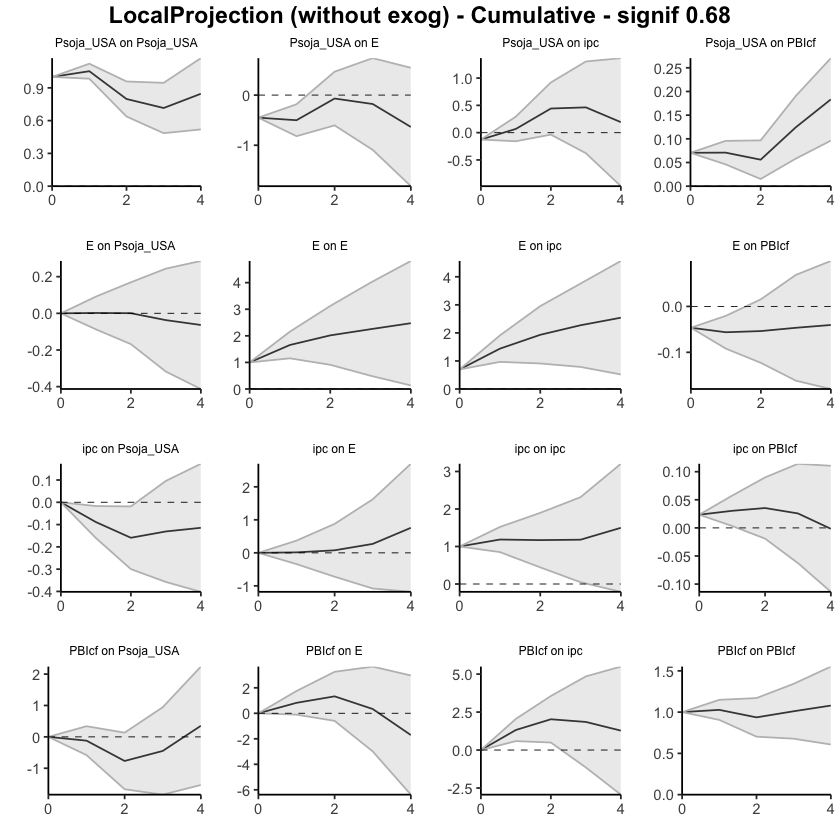

In [15]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,-0.004213461,-0.3623595,0.3539326
38,ipc,E,2,0.089365187,-0.3391094,0.5178398
39,ipc,E,3,0.222697059,-0.3376965,0.7830906
40,ipc,E,4,0.492521831,-0.1182112,1.1032548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.7984627,-0.1104553,1.7073808
53,PBIcf,E,2,0.7980025,-0.3597754,1.9557803
54,PBIcf,E,3,-0.9076282,-2.3271808,0.5119244
55,PBIcf,E,4,-2.2148070,-3.5914846,-0.8381294


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.04170239,-0.041702391,-0.04170239
2,Pmaíz_USA,E,1,0.31669419,-0.002101962,0.63549035
3,Pmaíz_USA,E,2,0.29193973,-0.135959624,0.71983908
4,Pmaíz_USA,E,3,-0.22028584,-0.811572536,0.37100086
5,Pmaíz_USA,E,4,-0.29502617,-0.718391566,0.12833922


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.032600973,0.0326009730,0.03260097
12,Pmaíz_USA,PBIcf,1,-0.006523785,-0.0319844525,0.01893688
13,Pmaíz_USA,PBIcf,2,-0.001152945,-0.0236167899,0.02131090
14,Pmaíz_USA,PBIcf,3,0.035534498,-0.0003655078,0.07143450
15,Pmaíz_USA,PBIcf,4,0.055847751,0.0287785209,0.08291698


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.03326903,-0.1225676,0.05602958
18,E,Pmaíz_USA,2,-0.01246917,-0.1050841,0.08014577
19,E,Pmaíz_USA,3,-0.03238023,-0.1317378,0.06697737
20,E,Pmaíz_USA,4,-0.02075902,-0.1278946,0.08637653


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.000000000
32,ipc,Pmaíz_USA,1,0.01504489,-0.06183503,0.091924807
33,ipc,Pmaíz_USA,2,-0.07043359,-0.14756495,0.006697756
34,ipc,Pmaíz_USA,3,0.03187920,-0.04773163,0.111490032
35,ipc,Pmaíz_USA,4,0.01611718,-0.06279055,0.095024907


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.20204560,-0.7299624,0.3258712
48,PBIcf,Pmaíz_USA,2,-0.24937914,-0.7830612,0.2843029
49,PBIcf,Pmaíz_USA,3,-0.07451926,-0.5521357,0.4030972
50,PBIcf,Pmaíz_USA,4,0.70979735,0.2424509,1.1771438


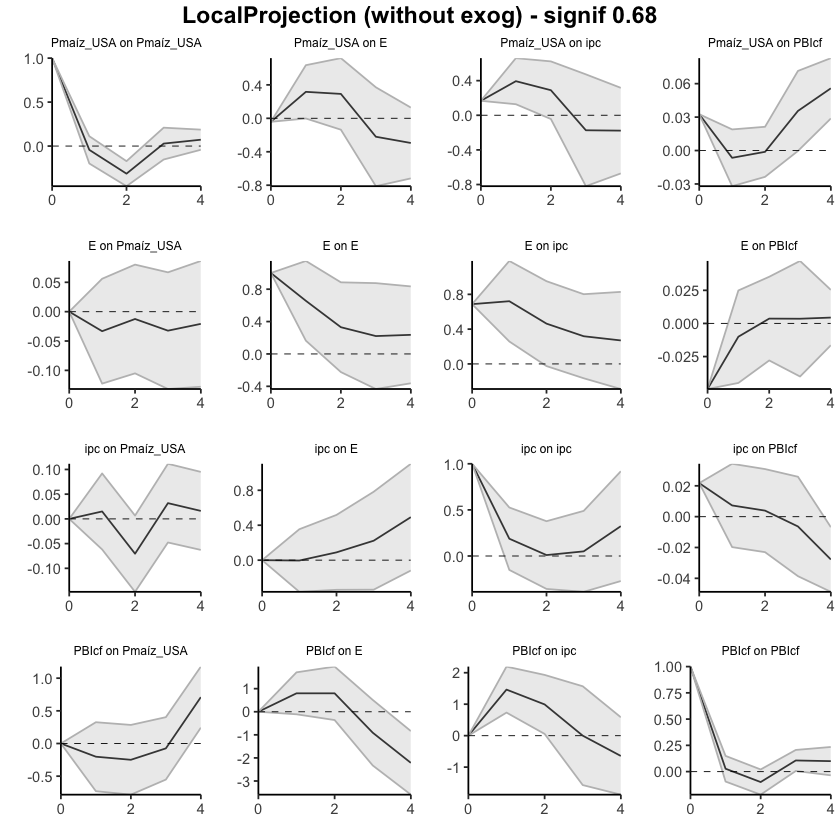

In [17]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,-0.004213461,-0.3623595,0.3539326
38,ipc,E,2,0.085151726,-0.7014689,0.8717724
39,ipc,E,3,0.307848785,-1.0391654,1.6548630
40,ipc,E,4,0.800370616,-1.1573766,2.7581178


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.7984627,-0.1104553,1.707381
53,PBIcf,E,2,1.5964652,-0.4702307,3.663161
54,PBIcf,E,3,0.6888370,-2.7974115,4.175086
55,PBIcf,E,4,-1.5259700,-6.3888961,3.336956


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.04170239,-0.04170239,-0.04170239
2,Pmaíz_USA,E,1,0.27499180,-0.04380435,0.59378795
3,Pmaíz_USA,E,2,0.56693153,-0.17976398,1.31362704
4,Pmaíz_USA,E,3,0.34664569,-0.99133651,1.68462790
5,Pmaíz_USA,E,4,0.05161952,-1.70972808,1.81296712


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.03260097,0.0326009730,0.03260097
12,Pmaíz_USA,PBIcf,1,0.02607719,0.0006165206,0.05153786
13,Pmaíz_USA,PBIcf,2,0.02492424,-0.0230002693,0.07284875
14,Pmaíz_USA,PBIcf,3,0.06045874,-0.0233657772,0.14428326
15,Pmaíz_USA,PBIcf,4,0.11630649,0.0054127437,0.22720024


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.03326903,-0.1225676,0.05602958
18,E,Pmaíz_USA,2,-0.04573820,-0.2276517,0.13617535
19,E,Pmaíz_USA,3,-0.07811843,-0.3593896,0.20315272
20,E,Pmaíz_USA,4,-0.09887744,-0.4872841,0.28952926


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.01504489,-0.06183503,0.09192481
33,ipc,Pmaíz_USA,2,-0.05538871,-0.20939998,0.09862256
34,ipc,Pmaíz_USA,3,-0.02350951,-0.25713161,0.21011259
35,ipc,Pmaíz_USA,4,-0.00739233,-0.31992216,0.30513750


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.2020456,-0.7299624,0.3258712
48,PBIcf,Pmaíz_USA,2,-0.4514247,-1.5130236,0.6101741
49,PBIcf,Pmaíz_USA,3,-0.5259440,-2.0651593,1.0132713
50,PBIcf,Pmaíz_USA,4,0.1838533,-1.8227084,2.1904151


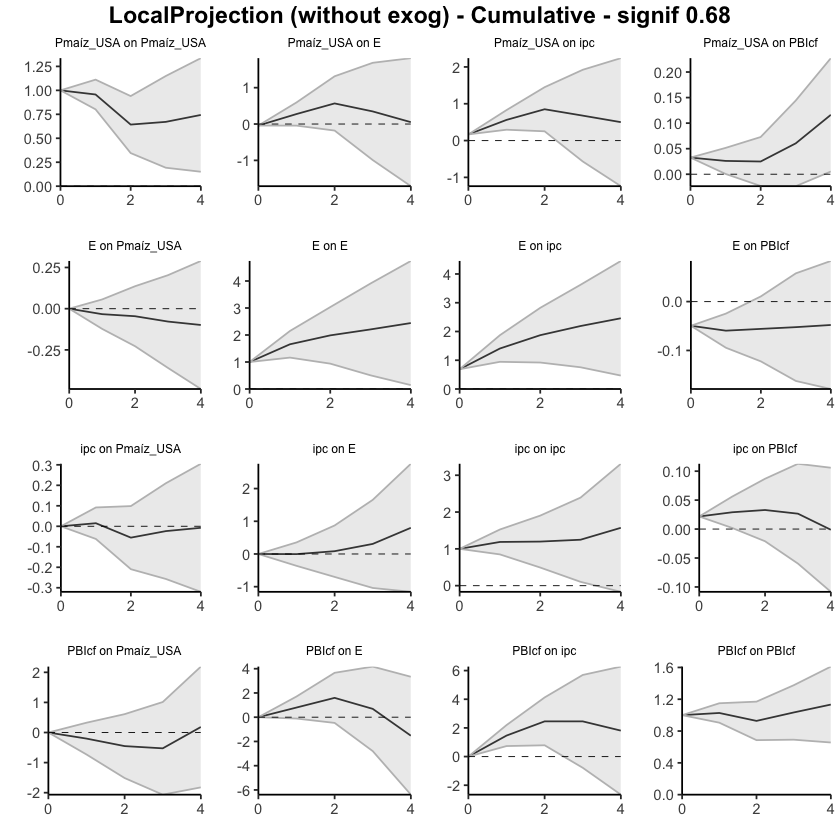

In [16]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,0.009313487,-0.3436622,0.3622891
38,ipc,E,2,0.088843613,-0.3000660,0.4777532
39,ipc,E,3,0.178043045,-0.3289468,0.6850329
40,ipc,E,4,0.455046093,-0.1635562,1.0736484


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.00000000,0.0000000
52,PBIcf,E,1,0.8801310,-0.06075075,1.8210127
53,PBIcf,E,2,0.8196702,-0.30871869,1.9480591
54,PBIcf,E,3,-1.0065225,-2.30359265,0.2905477
55,PBIcf,E,4,-2.3039780,-3.66109028,-0.9468657


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1335758,-0.13357583,-0.1335758
2,Ptrigo_USA,E,1,0.3348559,0.05152991,0.6181819
3,Ptrigo_USA,E,2,0.5331387,0.07975447,0.9865230
4,Ptrigo_USA,E,3,0.1882430,-0.39308214,0.7695681
5,Ptrigo_USA,E,4,-0.1513148,-0.50061989,0.1979902


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.035257179,0.03525718,0.03525718
12,Ptrigo_USA,PBIcf,1,-0.008437436,-0.04018163,0.02330676
13,Ptrigo_USA,PBIcf,2,-0.010558861,-0.03469994,0.01358222
14,Ptrigo_USA,PBIcf,3,0.044302763,0.01487532,0.07373021
15,Ptrigo_USA,PBIcf,4,0.070495017,0.03328936,0.10770067


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.053653248,-0.14854669,0.04124020
18,E,Ptrigo_USA,2,-0.035162072,-0.12842481,0.05810066
19,E,Ptrigo_USA,3,0.007804085,-0.09993226,0.11554043
20,E,Ptrigo_USA,4,0.022043390,-0.06395505,0.10804183


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,0.02982907,-0.04261774,0.10227589
33,ipc,Ptrigo_USA,2,0.03846247,-0.04754691,0.12447185
34,ipc,Ptrigo_USA,3,-0.03401198,-0.11359645,0.04557249
35,ipc,Ptrigo_USA,4,-0.06909608,-0.14296715,0.00477499


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.07621418,-0.47238825,0.3199599
48,PBIcf,Ptrigo_USA,2,-0.32303820,-0.87377960,0.2277032
49,PBIcf,Ptrigo_USA,3,0.34924072,-0.07235091,0.7708323
50,PBIcf,Ptrigo_USA,4,0.33942283,-0.11681938,0.7956650


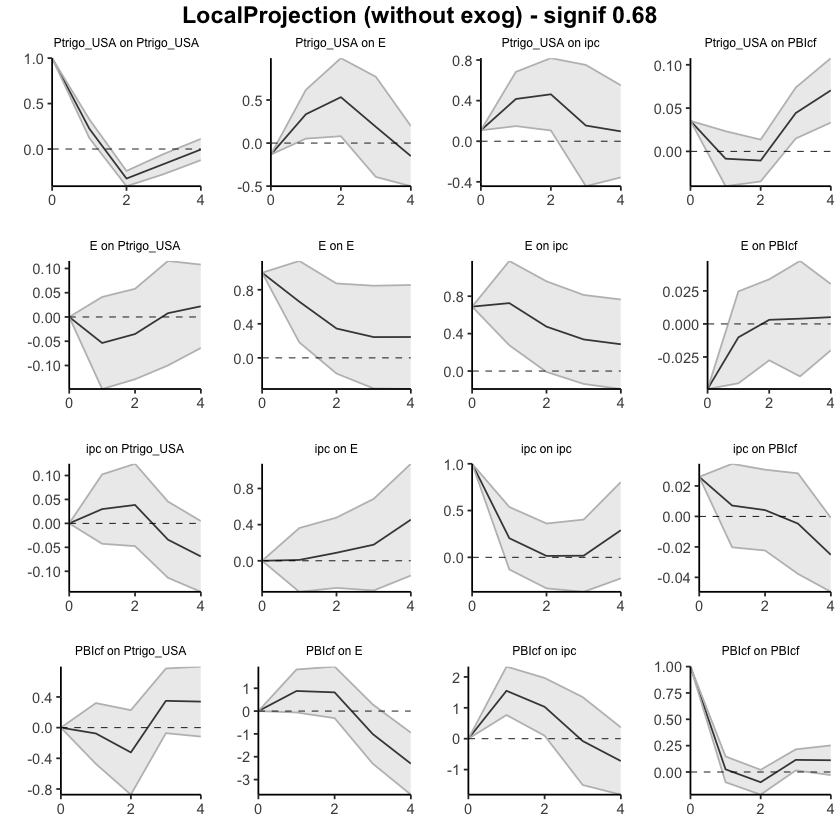

In [18]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.000000000,0.0000000,0.0000000
37,ipc,E,1,0.009313487,-0.3436622,0.3622891
38,ipc,E,2,0.098157100,-0.6437282,0.8400424
39,ipc,E,3,0.276200144,-0.9726750,1.5250753
40,ipc,E,4,0.731246238,-1.1362312,2.5987237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.00000000,0.000000
52,PBIcf,E,1,0.8801310,-0.06075075,1.821013
53,PBIcf,E,2,1.6998012,-0.36946944,3.769072
54,PBIcf,E,3,0.6932787,-2.67306209,4.059619
55,PBIcf,E,4,-1.6106993,-6.33415237,3.112754


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.1335758,-0.133575826,-0.1335758
2,Ptrigo_USA,E,1,0.2012801,-0.082045917,0.4846060
3,Ptrigo_USA,E,2,0.7344188,-0.002291442,1.4711290
4,Ptrigo_USA,E,3,0.9226617,-0.395373585,2.2406971
5,Ptrigo_USA,E,4,0.7713469,-0.895993471,2.4386873


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.03525718,0.035257179,0.03525718
12,Ptrigo_USA,PBIcf,1,0.02681974,-0.004924453,0.05856394
13,Ptrigo_USA,PBIcf,2,0.01626088,-0.039624395,0.07214616
14,Ptrigo_USA,PBIcf,3,0.06056364,-0.024749075,0.14587636
15,Ptrigo_USA,PBIcf,4,0.13105866,0.008540284,0.25357704


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.05365325,-0.1485467,0.04124020
18,E,Ptrigo_USA,2,-0.08881532,-0.2769715,0.09934086
19,E,Ptrigo_USA,3,-0.08101124,-0.3769038,0.21488129
20,E,Ptrigo_USA,4,-0.05896785,-0.4408588,0.32292312


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,0.02982907,-0.04261774,0.1022759
33,ipc,Ptrigo_USA,2,0.06829155,-0.09016465,0.2267477
34,ipc,Ptrigo_USA,3,0.03427956,-0.20376110,0.2723202
35,ipc,Ptrigo_USA,4,-0.03481652,-0.34672826,0.2770952


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.07621418,-0.4723883,0.3199599
48,PBIcf,Ptrigo_USA,2,-0.39925238,-1.3461679,0.5476631
49,PBIcf,Ptrigo_USA,3,-0.05001166,-1.4185188,1.3184954
50,PBIcf,Ptrigo_USA,4,0.28941117,-1.5353381,2.1141605


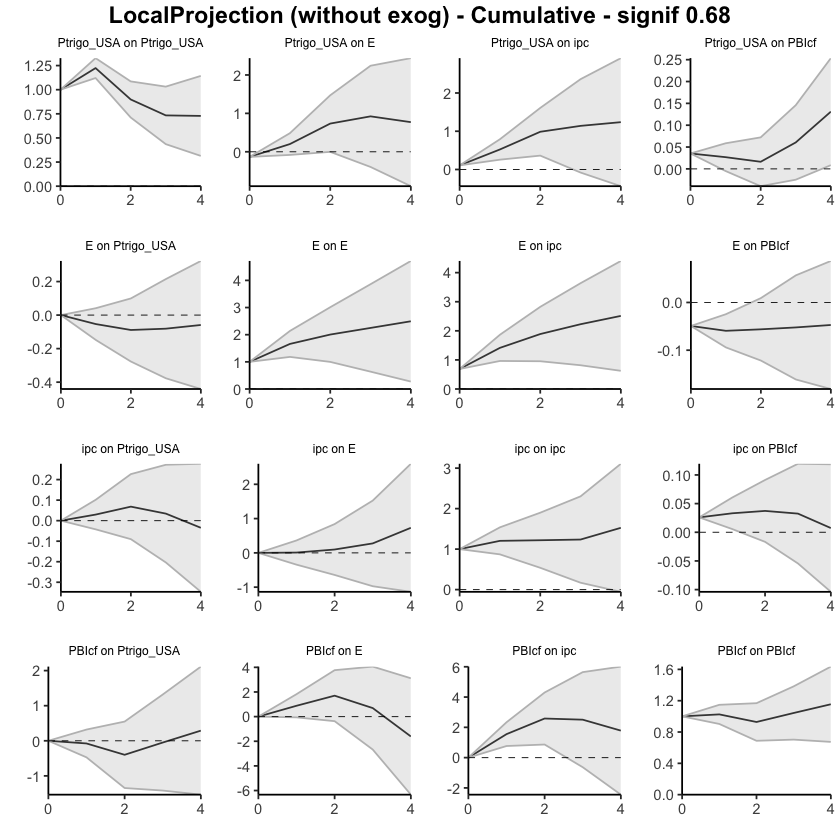

In [19]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.000000000,0.00000000
37,ipc,E,1,0.38394711,-0.004323595,0.77221782
38,ipc,E,2,-0.01956961,-0.441080613,0.40194139
39,ipc,E,3,-0.62620916,-1.285356775,0.03293845
40,ipc,E,4,-0.21574145,-0.714483594,0.28300070


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,1.1833310,0.1490596,2.2176023
53,PBIcf,E,2,0.7281456,-0.1395844,1.5958757
54,PBIcf,E,3,-1.4973096,-2.5975552,-0.3970641
55,PBIcf,E,4,-2.8330065,-4.2780958,-1.3879172


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.006623734,-0.006623734,-0.006623734
2,Ptrigo_USA,E,1,0.327960356,-0.101309948,0.757230661
3,Ptrigo_USA,E,2,0.595969283,0.162608928,1.029329637
4,Ptrigo_USA,E,3,0.352452347,-0.329856001,1.034760695
5,Ptrigo_USA,E,4,-0.106263593,-0.529271063,0.316743878


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.033689735,0.033689735,0.03368974
12,Ptrigo_USA,PBIcf,1,-0.006043704,-0.045155957,0.03306855
13,Ptrigo_USA,PBIcf,2,-0.019847226,-0.052583043,0.01288859
14,Ptrigo_USA,PBIcf,3,0.029712742,-0.009639099,0.06906458
15,Ptrigo_USA,PBIcf,4,0.081094376,0.033518884,0.12866987


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.055039518,-0.15320615,0.04312711
18,E,Ptrigo_USA,2,-0.053260204,-0.16918205,0.06266164
19,E,Ptrigo_USA,3,0.002008203,-0.11151985,0.11553625
20,E,Ptrigo_USA,4,0.021979050,-0.09477084,0.13872894


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.01118840,-0.0936119,0.07123509
33,ipc,Ptrigo_USA,2,-0.02316193,-0.1345571,0.08823329
34,ipc,Ptrigo_USA,3,-0.04868574,-0.1427076,0.04533610
35,ipc,Ptrigo_USA,4,-0.09592435,-0.2082245,0.01637582


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.1468758,-0.4921898,0.1984381
48,PBIcf,Ptrigo_USA,2,-0.4455154,-0.9911784,0.1001476
49,PBIcf,Ptrigo_USA,3,0.3014839,-0.1036135,0.7065812
50,PBIcf,Ptrigo_USA,4,0.3141020,-0.1109206,0.7391246


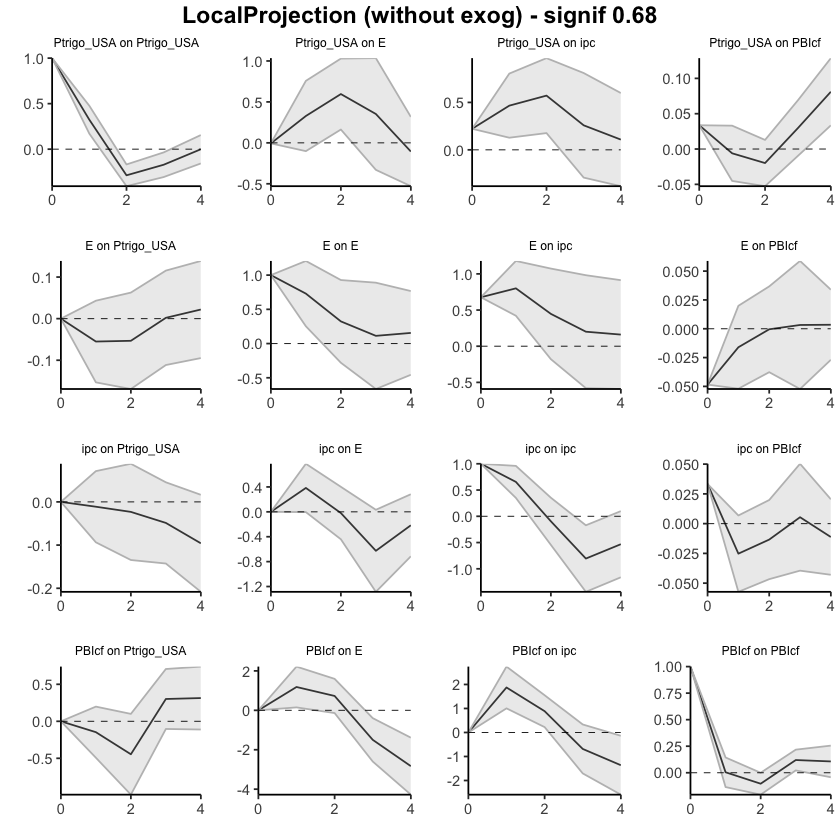

In [20]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.000000000,0.0000000
37,ipc,E,1,0.3839471,-0.004323595,0.7722178
38,ipc,E,2,0.3643775,-0.445404208,1.1741592
39,ipc,E,3,-0.2618317,-1.730760983,1.2070977
40,ipc,E,4,-0.4775731,-2.445244577,1.4900984


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000000,0.000000
52,PBIcf,E,1,1.183331,0.149059633,2.217602
53,PBIcf,E,2,1.911477,0.009475218,3.813478
54,PBIcf,E,3,0.414167,-2.588079941,3.416414
55,PBIcf,E,4,-2.418840,-6.866175779,2.028497


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.006623734,-0.006623734,-0.006623734
2,Ptrigo_USA,E,1,0.321336623,-0.107933682,0.750606928
3,Ptrigo_USA,E,2,0.917305906,0.054675246,1.779936565
4,Ptrigo_USA,E,3,1.269758253,-0.275180755,2.814697261
5,Ptrigo_USA,E,4,1.163494660,-0.804451818,3.131441138


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.033689735,0.03368974,0.03368974
12,Ptrigo_USA,PBIcf,1,0.027646032,-0.01146622,0.06675828
13,Ptrigo_USA,PBIcf,2,0.007798805,-0.06404927,0.07964688
14,Ptrigo_USA,PBIcf,3,0.037511548,-0.07368836,0.14871146
15,Ptrigo_USA,PBIcf,4,0.118605924,-0.04016948,0.27738133


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.05503952,-0.1532061,0.04312711
18,E,Ptrigo_USA,2,-0.10829972,-0.3223882,0.10578875
19,E,Ptrigo_USA,3,-0.10629152,-0.4339080,0.22132501
20,E,Ptrigo_USA,4,-0.08431247,-0.5286789,0.36005395


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.01118840,-0.0936119,0.07123509
33,ipc,Ptrigo_USA,2,-0.03435033,-0.2281690,0.15946839
34,ipc,Ptrigo_USA,3,-0.08303607,-0.3708766,0.20480449
35,ipc,Ptrigo_USA,4,-0.17896042,-0.5791012,0.22118031


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.14687581,-0.4921898,0.1984381
48,PBIcf,Ptrigo_USA,2,-0.59239122,-1.4833682,0.2985858
49,PBIcf,Ptrigo_USA,3,-0.29090737,-1.5869817,1.0051669
50,PBIcf,Ptrigo_USA,4,0.02319462,-1.6979023,1.7442915


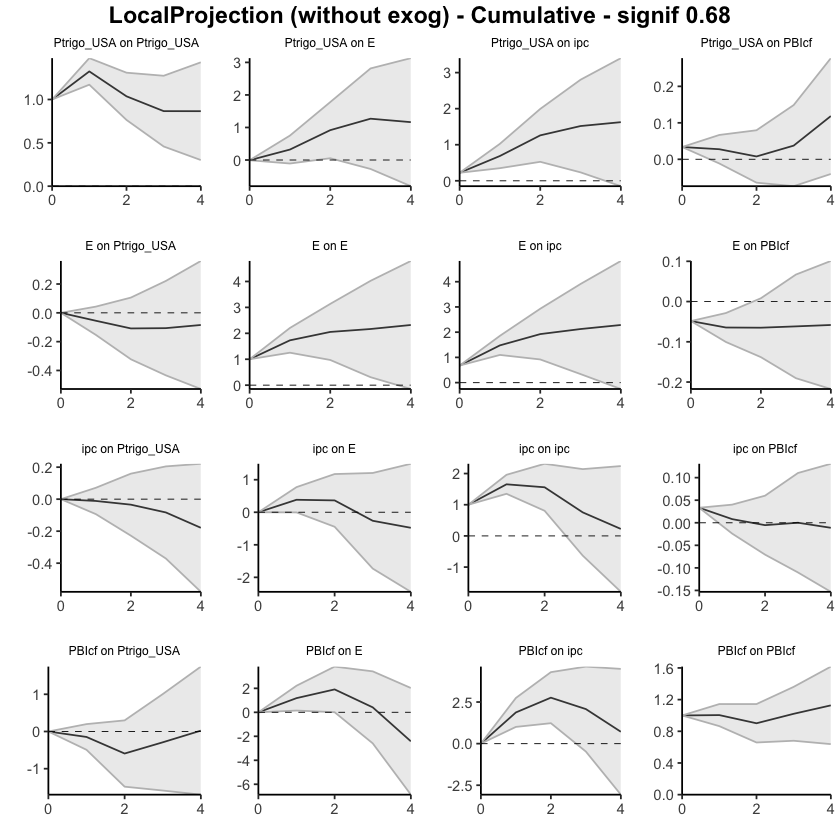

In [21]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, cumulative=TRUE)

### 1935-2023. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.02434921,-0.3422486,0.3909470
13,ipc,E,2,0.06848714,-0.3878867,0.5248610
14,ipc,E,3,0.18201197,-0.3855758,0.7495997
15,ipc,E,4,0.46350429,-0.1408072,1.0678158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.8222116,-0.1050500,1.7494732
23,PBIcf,E,2,0.5081153,-0.4891175,1.5053482
24,PBIcf,E,3,-0.9930921,-2.3947920,0.4086079
25,PBIcf,E,4,-2.0436715,-3.3906145,-0.6967284


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6863928,0.68639277,0.6863928
2,E,ipc,1,0.7349523,0.26905715,1.2008474
3,E,ipc,2,0.4917885,-0.05214941,1.0357265
4,E,ipc,3,0.3412808,-0.11385391,0.7964155
5,E,ipc,4,0.2667814,-0.26030785,0.7938706


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.00000000,0.0000000
27,PBIcf,ipc,1,1.3207109,0.58835018,2.0530716
28,PBIcf,ipc,2,0.7059644,-0.09332533,1.5052542
29,PBIcf,ipc,3,-0.1760687,-1.64295850,1.2908211
30,PBIcf,ipc,4,-0.5721385,-1.78846739,0.6441904


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.049402242,-0.04940224,-0.04940224
7,E,PBIcf,1,-0.010000809,-0.04513215,0.02513053
8,E,PBIcf,2,0.002756377,-0.03010500,0.03561775
9,E,PBIcf,3,0.007060186,-0.03832702,0.05244739
10,E,PBIcf,4,0.006244449,-0.01736841,0.02985731


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.035305204,0.03530520,0.035305204
17,ipc,PBIcf,1,0.007244921,-0.02121764,0.035707477
18,ipc,PBIcf,2,0.003884673,-0.02484672,0.032616064
19,ipc,PBIcf,3,-0.008761088,-0.04388927,0.026367096
20,ipc,PBIcf,4,-0.026540749,-0.05194817,-0.001133328


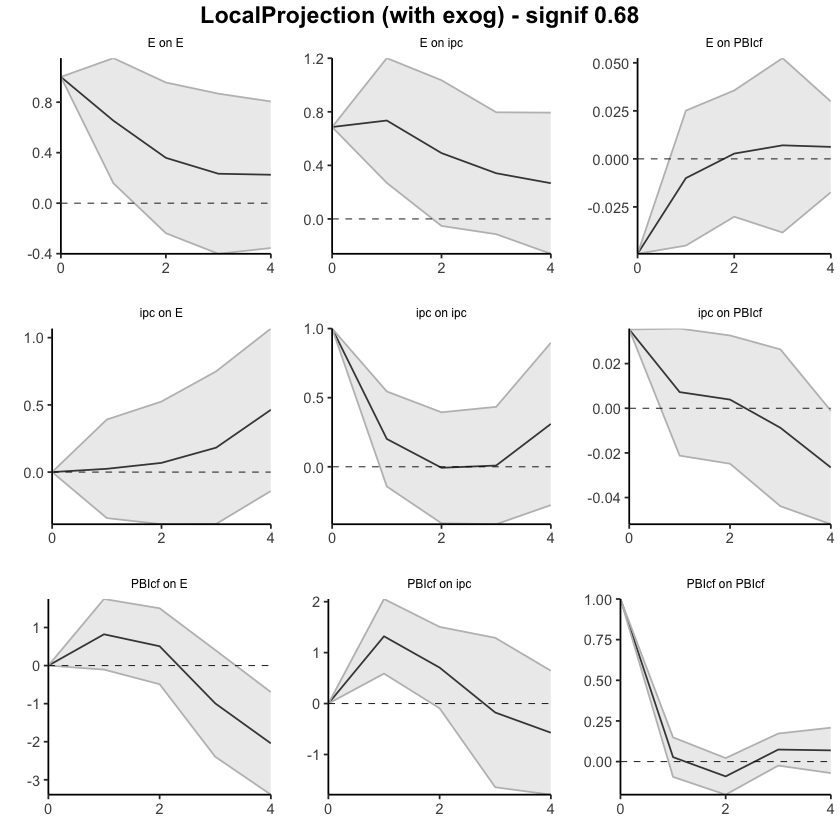

In [22]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.000000
12,ipc,E,1,0.02434921,-0.3422486,0.390947
13,ipc,E,2,0.09283636,-0.7301353,0.915808
14,ipc,E,3,0.27484832,-1.1157110,1.665408
15,ipc,E,4,0.73835261,-1.2565183,2.733223


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.8222116,-0.1050500,1.749473
23,PBIcf,E,2,1.3303269,-0.5941675,3.254821
24,PBIcf,E,3,0.3372349,-2.9889596,3.663429
25,PBIcf,E,4,-1.7064366,-6.3795741,2.966701


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6863928,0.6863928,0.6863928
2,E,ipc,1,1.4213450,0.9554499,1.8872402
3,E,ipc,2,1.9131336,0.9033005,2.9229666
4,E,ipc,3,2.2544144,0.7894466,3.7193821
5,E,ipc,4,2.5211957,0.5291388,4.5132527


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.320711,0.5883502,2.053072
28,PBIcf,ipc,2,2.026675,0.4950249,3.558326
29,PBIcf,ipc,3,1.850607,-1.1479336,4.849147
30,PBIcf,ipc,4,1.278468,-2.9364010,5.493337


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04940224,-0.04940224,-0.04940224
7,E,PBIcf,1,-0.05940305,-0.09453439,-0.02427171
8,E,PBIcf,2,-0.05664667,-0.12463938,0.01134604
9,E,PBIcf,3,-0.04958649,-0.16296640,0.06379343
10,E,PBIcf,4,-0.04334204,-0.18033481,0.09365074


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.03530520,0.03530520,0.03530520
17,ipc,PBIcf,1,0.04255013,0.01408757,0.07101268
18,ipc,PBIcf,2,0.04643480,-0.01075915,0.10362875
19,ipc,PBIcf,3,0.03767371,-0.05464842,0.12999584
20,ipc,PBIcf,4,0.01113296,-0.10659659,0.12886251


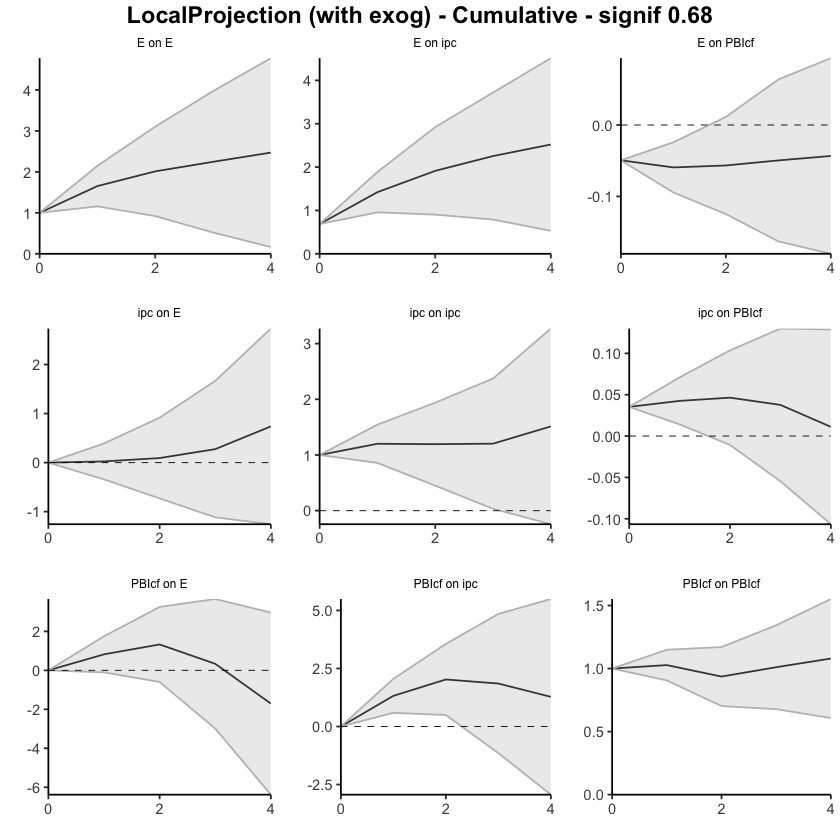

In [23]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.34889204,-0.0174638,0.7152479
13,ipc,E,2,0.03331015,-0.4124003,0.4790206
14,ipc,E,3,-0.49341324,-1.1963272,0.2095007
15,ipc,E,4,-0.23928458,-0.8405746,0.3620054


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.0000000
22,PBIcf,E,1,1.2199048,0.09514291,2.3446666
23,PBIcf,E,2,0.4424806,-0.32860109,1.2135623
24,PBIcf,E,3,-1.5764691,-2.72074787,-0.4321904
25,PBIcf,E,4,-2.6381646,-4.06742986,-1.2088993


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6739518,0.6739518,0.6739518
2,E,ipc,1,0.8147919,0.4460222,1.1835617
3,E,ipc,2,0.4745729,-0.1712029,1.1203487
4,E,ipc,3,0.2260807,-0.4789725,0.9311338
5,E,ipc,4,0.1725391,-0.6057302,0.9508083


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.00000000,0.00000000
27,PBIcf,ipc,1,1.7304210,0.89937857,2.56146345
28,PBIcf,ipc,2,0.6319829,0.05625316,1.20771261
29,PBIcf,ipc,3,-0.8273701,-1.86439538,0.20965523
30,PBIcf,ipc,4,-1.2423708,-2.52540359,0.04066191


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-4.859309e-02,-0.04859309,-0.04859309
7,E,PBIcf,1,-1.587612e-02,-0.05596921,0.02421697
8,E,PBIcf,2,-2.788873e-05,-0.04229624,0.04224046
9,E,PBIcf,3,9.089124e-03,-0.04194542,0.06012367
10,E,PBIcf,4,6.603133e-03,-0.02575185,0.03895811


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.041216343,0.04121634,0.041216343
17,ipc,PBIcf,1,-0.025160999,-0.06103379,0.010711796
18,ipc,PBIcf,2,-0.033433121,-0.07099095,0.004124708
19,ipc,PBIcf,3,-0.010213316,-0.05217871,0.031752081
20,ipc,PBIcf,4,0.007076233,-0.02780063,0.041953098


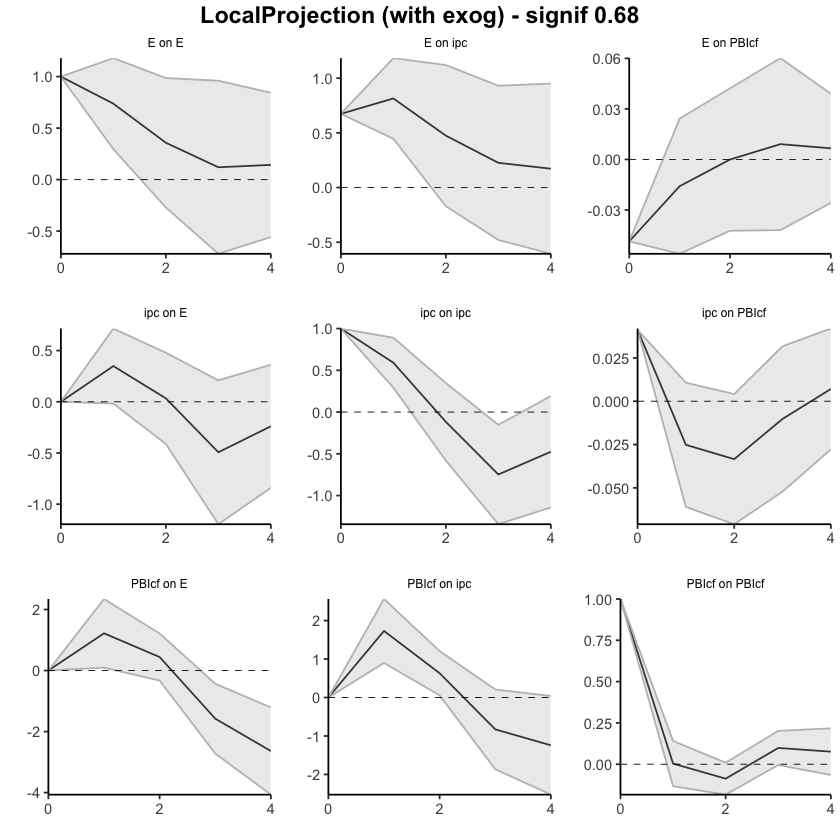

In [24]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.3488920,-0.0174638,0.7152479
13,ipc,E,2,0.3822022,-0.4298641,1.1942684
14,ipc,E,3,-0.1112111,-1.6261912,1.4037691
15,ipc,E,4,-0.3504956,-2.4667658,1.7657746


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.00000000,0.00000000,0.000000
22,PBIcf,E,1,1.21990477,0.09514291,2.344667
23,PBIcf,E,2,1.66238538,-0.23345818,3.558229
24,PBIcf,E,3,0.08591626,-2.95420605,3.126039
25,PBIcf,E,4,-2.55224833,-7.02163591,1.917139


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6739518,0.6739518,0.6739518
2,E,ipc,1,1.4887438,1.1199740,1.8575136
3,E,ipc,2,1.9633167,0.9487712,2.9778623
4,E,ipc,3,2.1893974,0.4697987,3.9089961
5,E,ipc,4,2.3619365,-0.1359315,4.8598045


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.730421,0.8993786,2.561463
28,PBIcf,ipc,2,2.362404,0.9556317,3.769176
29,PBIcf,ipc,3,1.535034,-0.9087636,3.978831
30,PBIcf,ipc,4,0.292663,-3.4341672,4.019493


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04859309,-0.04859309,-0.04859309
7,E,PBIcf,1,-0.06446920,-0.10456229,-0.02437611
8,E,PBIcf,2,-0.06449709,-0.14685854,0.01786435
9,E,PBIcf,3,-0.05540797,-0.18880396,0.07798802
10,E,PBIcf,4,-0.04880484,-0.21455580,0.11694613


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.04121634,0.04121634,0.04121634
17,ipc,PBIcf,1,0.01605534,-0.01981745,0.05192814
18,ipc,PBIcf,2,-0.01737778,-0.09080840,0.05605285
19,ipc,PBIcf,3,-0.02759109,-0.14298711,0.08780493
20,ipc,PBIcf,4,-0.02051486,-0.17078774,0.12975803


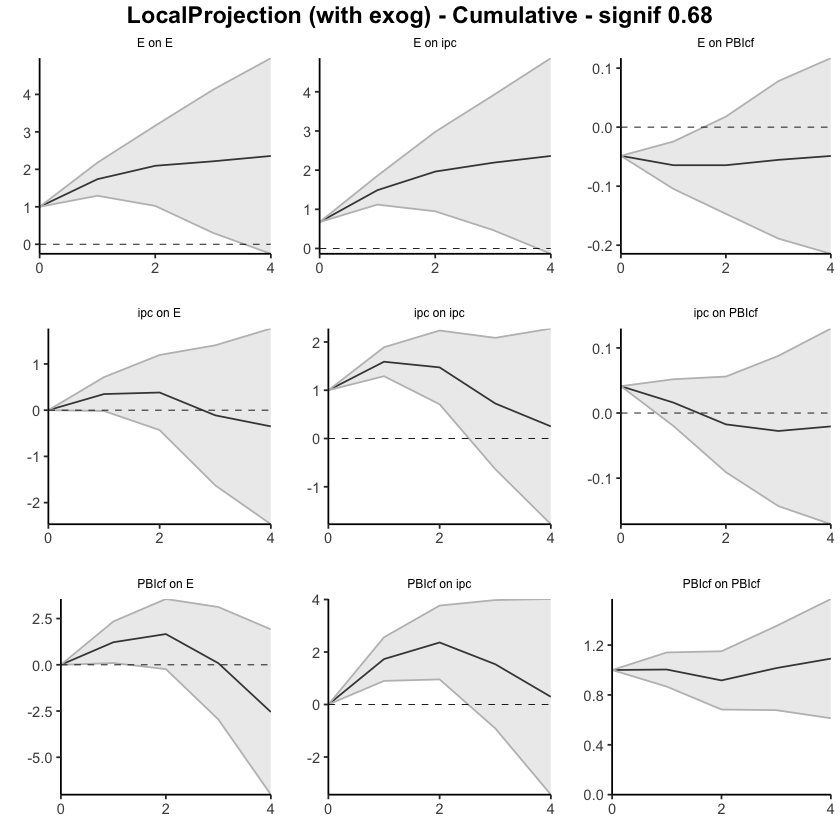

In [25]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,0.004119074,-0.3635122,0.3717503
13,ipc,E,2,0.097692919,-0.3428639,0.5382498
14,ipc,E,3,0.213225304,-0.3619823,0.7884329
15,ipc,E,4,0.469408721,-0.1556909,1.0945083


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.7984627,-0.1104553,1.7073808
23,PBIcf,E,2,0.7980025,-0.3597754,1.9557803
24,PBIcf,E,3,-0.9076282,-2.3271808,0.5119244
25,PBIcf,E,4,-2.2148070,-3.5914846,-0.8381294


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6857730,0.68577297,0.6857730
2,E,ipc,1,0.7204648,0.25815223,1.1827773
3,E,ipc,2,0.4629957,-0.02427145,0.9502629
4,E,ipc,3,0.3183060,-0.16391801,0.8005300
5,E,ipc,4,0.2695652,-0.28766804,0.8267984


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000000,0.00000000,0.0000000
27,PBIcf,ipc,1,1.4639098798,0.73298986,2.1948299
28,PBIcf,ipc,2,0.9928428987,0.05519351,1.9304923
29,PBIcf,ipc,3,-0.0006339644,-1.57079814,1.5695302
30,PBIcf,ipc,4,-0.6459457473,-1.87520865,0.5833172


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.049765716,-0.04976572,-0.04976572
7,E,PBIcf,1,-0.010027304,-0.04486271,0.02480811
8,E,PBIcf,2,0.003668748,-0.02784301,0.03518050
9,E,PBIcf,3,0.003541843,-0.04000440,0.04708808
10,E,PBIcf,4,0.004457196,-0.01636594,0.02528033


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.032179933,0.03217993,0.032179933
17,ipc,PBIcf,1,0.007554558,-0.02074846,0.035857572
18,ipc,PBIcf,2,0.002875464,-0.02532284,0.031073768
19,ipc,PBIcf,3,-0.005258203,-0.03854633,0.028029926
20,ipc,PBIcf,4,-0.026760108,-0.04913474,-0.004385473


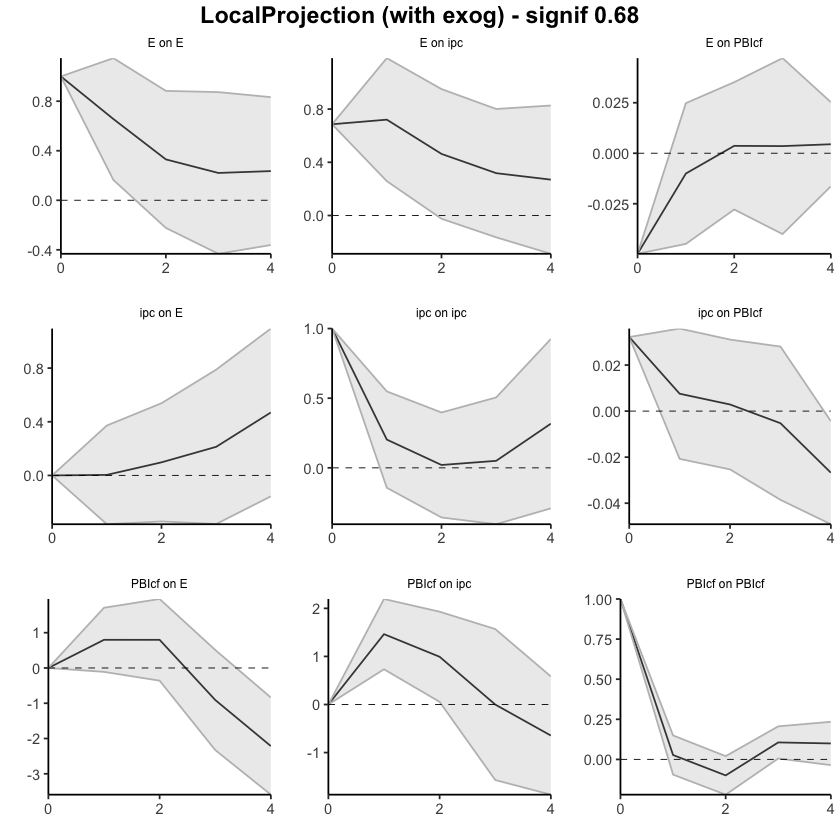

In [26]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,0.004119074,-0.3635122,0.3717503
13,ipc,E,2,0.101811992,-0.7063761,0.9100001
14,ipc,E,3,0.315037297,-1.0683585,1.6984330
15,ipc,E,4,0.784446018,-1.2240493,2.7929414


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.7984627,-0.1104553,1.707381
23,PBIcf,E,2,1.5964652,-0.4702307,3.663161
24,PBIcf,E,3,0.6888370,-2.7974115,4.175086
25,PBIcf,E,4,-1.5259700,-6.3888961,3.336956


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.685773,0.6857730,0.685773
2,E,ipc,1,1.406238,0.9439252,1.868550
3,E,ipc,2,1.869233,0.9196537,2.818813
4,E,ipc,3,2.187539,0.7557357,3.619343
5,E,ipc,4,2.457105,0.4680677,4.446142


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.463910,0.7329899,2.194830
28,PBIcf,ipc,2,2.456753,0.7881834,4.125322
29,PBIcf,ipc,3,2.456119,-0.7826148,5.694852
30,PBIcf,ipc,4,1.810173,-2.6578234,6.278170


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04976572,-0.04976572,-0.04976572
7,E,PBIcf,1,-0.05979302,-0.09462843,-0.02495761
8,E,PBIcf,2,-0.05612427,-0.12247144,0.01022289
9,E,PBIcf,3,-0.05258243,-0.16247583,0.05731097
10,E,PBIcf,4,-0.04812523,-0.17884177,0.08259131


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.03217993,0.03217993,0.03217993
17,ipc,PBIcf,1,0.03973449,0.01143148,0.06803751
18,ipc,PBIcf,2,0.04260995,-0.01389136,0.09911127
19,ipc,PBIcf,3,0.03735175,-0.05243770,0.12714120
20,ipc,PBIcf,4,0.01059164,-0.10157244,0.12275573


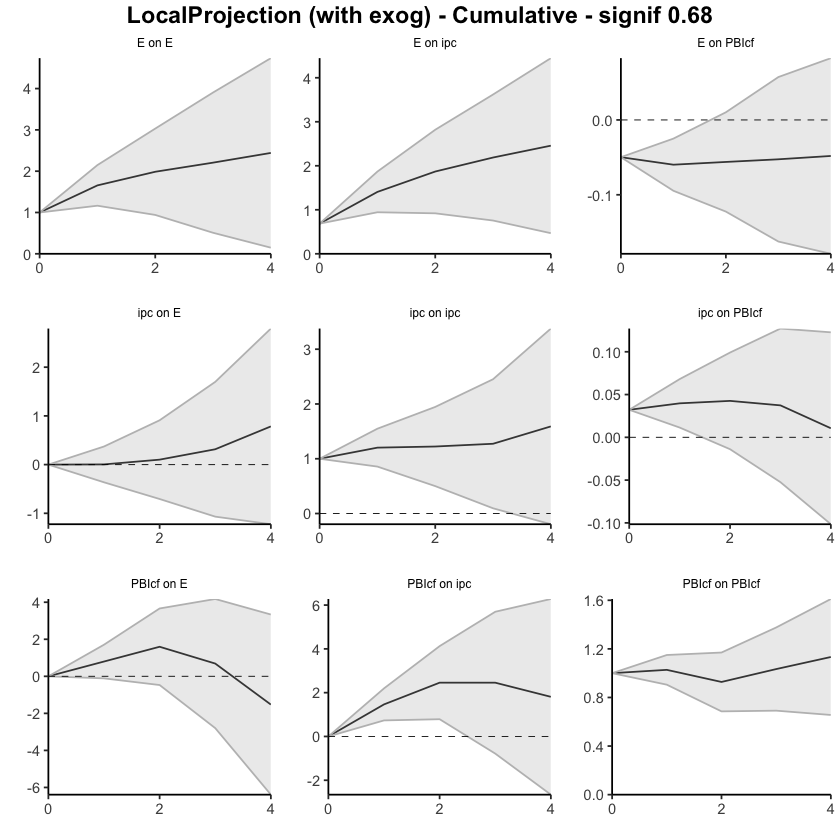

In [27]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.01486211,-0.3440452,0.3737694
13,ipc,E,2,0.09401107,-0.3020123,0.4900344
14,ipc,E,3,0.17169761,-0.3434694,0.6868646
15,ipc,E,4,0.44052109,-0.1866369,1.0676790


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.0000000
22,PBIcf,E,1,0.8801310,-0.06075075,1.8210127
23,PBIcf,E,2,0.8196702,-0.30871869,1.9480591
24,PBIcf,E,3,-1.0065225,-2.30359265,0.2905477
25,PBIcf,E,4,-2.3039780,-3.66109028,-0.9468657


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6847519,0.684751874,0.6847519
2,E,ipc,1,0.7247159,0.275679608,1.1737523
3,E,ipc,2,0.4741750,-0.008402097,0.9567521
4,E,ipc,3,0.3378271,-0.135469059,0.8111232
5,E,ipc,4,0.2856699,-0.190276704,0.7616165


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.00000000,0.00000000,0.0000000
27,PBIcf,ipc,1,1.55060736,0.76678165,2.3344331
28,PBIcf,ipc,2,1.03226487,0.09851995,1.9660098
29,PBIcf,ipc,3,-0.07669508,-1.49891210,1.3455219
30,PBIcf,ipc,4,-0.72306806,-1.81158719,0.3654511


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.049773463,-0.04977346,-0.04977346
7,E,PBIcf,1,-0.010175400,-0.04479616,0.02444536
8,E,PBIcf,2,0.003137740,-0.02735151,0.03362699
9,E,PBIcf,3,0.003943397,-0.03956378,0.04745057
10,E,PBIcf,4,0.005162941,-0.01973232,0.03005820


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.032255687,0.03225569,0.0322556869
17,ipc,PBIcf,1,0.007300812,-0.02088637,0.0354879954
18,ipc,PBIcf,2,0.003548421,-0.02371722,0.0308140621
19,ipc,PBIcf,3,-0.003985301,-0.03760640,0.0296358018
20,ipc,PBIcf,4,-0.024504223,-0.04968007,0.0006716272


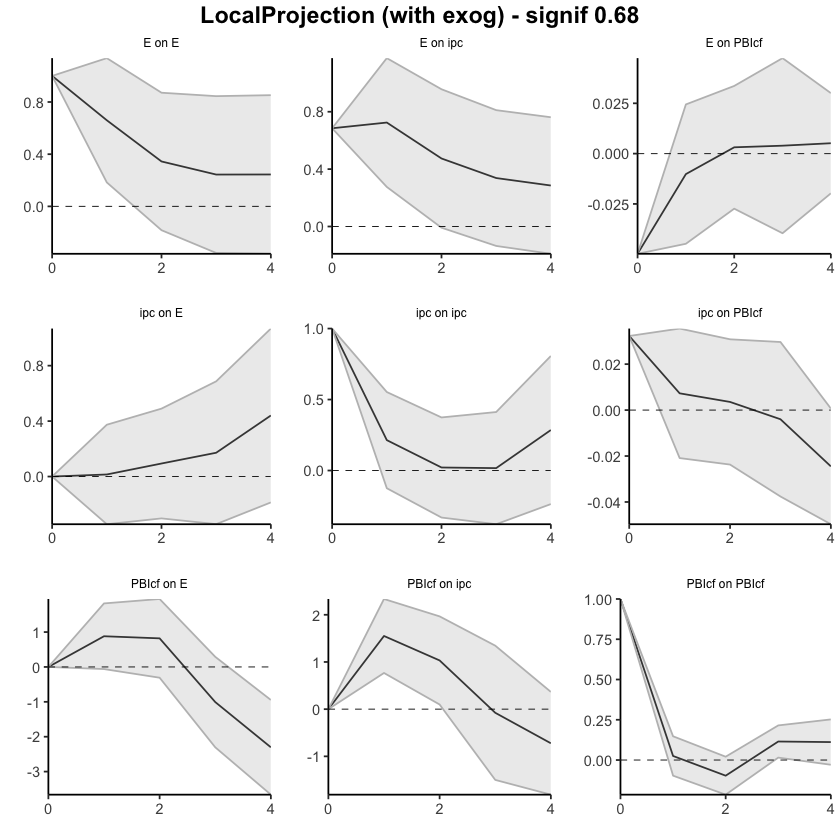

In [30]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.01486211,-0.3440452,0.3737694
13,ipc,E,2,0.10887318,-0.6460574,0.8638038
14,ipc,E,3,0.28057079,-0.9895268,1.5506684
15,ipc,E,4,0.72109188,-1.1761637,2.6183475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.000000
22,PBIcf,E,1,0.8801310,-0.06075075,1.821013
23,PBIcf,E,2,1.6998012,-0.36946944,3.769072
24,PBIcf,E,3,0.6932787,-2.67306209,4.059619
25,PBIcf,E,4,-1.6106993,-6.33415237,3.112754


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6847519,0.6847519,0.6847519
2,E,ipc,1,1.4094678,0.9604315,1.8585041
3,E,ipc,2,1.8836428,0.9520294,2.8152562
4,E,ipc,3,2.2214699,0.8165603,3.6263794
5,E,ipc,4,2.5071398,0.6262836,4.3879959


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.550607,0.7667817,2.334433
28,PBIcf,ipc,2,2.582872,0.8653016,4.300443
29,PBIcf,ipc,3,2.506177,-0.6336105,5.645965
30,PBIcf,ipc,4,1.783109,-2.4451977,6.011416


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04977346,-0.04977346,-0.049773463
7,E,PBIcf,1,-0.05994886,-0.09456963,-0.025328098
8,E,PBIcf,2,-0.05681112,-0.12192113,0.008298889
9,E,PBIcf,3,-0.05286772,-0.16148491,0.055749460
10,E,PBIcf,4,-0.04770478,-0.18121723,0.085807662


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.03225569,0.03225569,0.03225569
17,ipc,PBIcf,1,0.03955650,0.01136932,0.06774368
18,ipc,PBIcf,2,0.04310492,-0.01234790,0.09855774
19,ipc,PBIcf,3,0.03911962,-0.04995431,0.12819355
20,ipc,PBIcf,4,0.01461540,-0.09963438,0.12886517


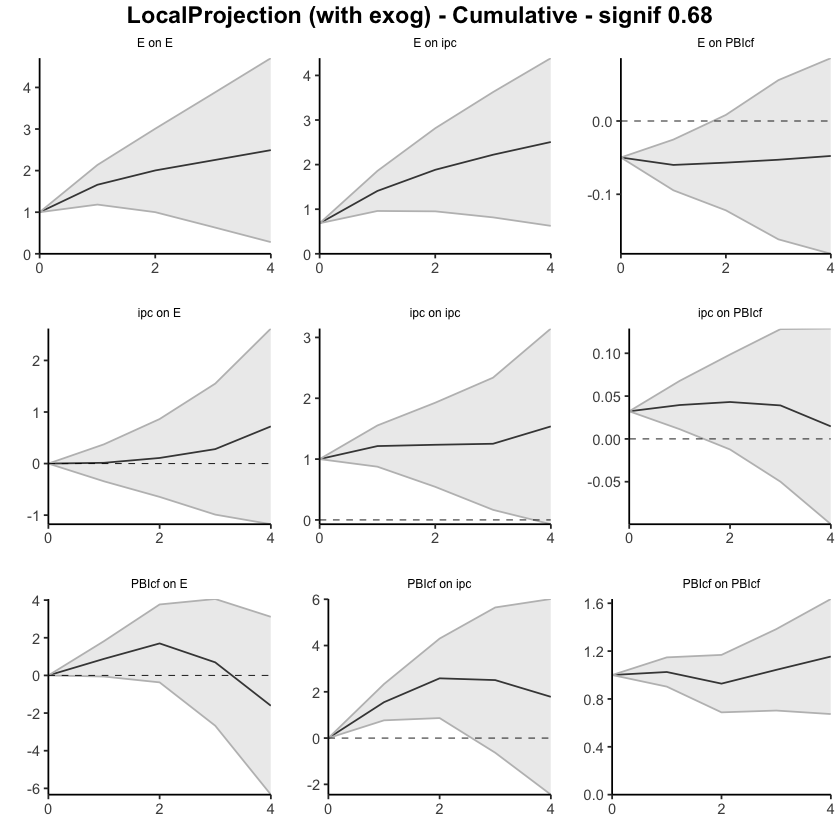

In [29]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1974. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.06074921,-0.1420080,0.02050953
38,ipc,E,2,-0.15344314,-0.2687489,-0.03813736
39,ipc,E,3,0.03409150,-0.1177708,0.18595376
40,ipc,E,4,0.61565575,0.4531970,0.77811445


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,1.8144459,1.1943152,2.4345766
53,PBIcf,E,2,2.3211236,1.6549716,2.9872757
54,PBIcf,E,3,1.6930391,0.6891155,2.6969628
55,PBIcf,E,4,-0.3864484,-1.7689099,0.9960132


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.28405861,-0.2840586,-0.2840586
2,Psoja_USA,E,1,-0.34312675,-0.5163489,-0.1699046
3,Psoja_USA,E,2,-0.07487089,-0.2530124,0.1032707
4,Psoja_USA,E,3,-0.03751613,-0.1780332,0.1030010
5,Psoja_USA,E,4,-0.02939371,-0.2055446,0.1467572


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.034463581,0.034463581,0.03446358
12,Psoja_USA,PBIcf,1,0.001636942,-0.016003328,0.01927721
13,Psoja_USA,PBIcf,2,-0.005580819,-0.021796724,0.01063509
14,Psoja_USA,PBIcf,3,0.023456696,-0.008916907,0.05583030
15,Psoja_USA,PBIcf,4,0.056438503,0.025492988,0.08738402


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.000000000
17,E,Psoja_USA,1,0.14186526,-0.10268981,0.386420326
18,E,Psoja_USA,2,0.07495696,-0.06382579,0.213739705
19,E,Psoja_USA,3,-0.07426687,-0.28581885,0.137285113
20,E,Psoja_USA,4,-0.13671503,-0.27514124,0.001711173


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Psoja_USA,1,0.02287427,-0.1044556,0.1502042
33,ipc,Psoja_USA,2,0.26514988,0.1846108,0.3456889
34,ipc,Psoja_USA,3,-0.51314208,-0.6588721,-0.3674120
35,ipc,Psoja_USA,4,-0.32711782,-0.3853310,-0.2689046


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,0.1952847,-0.6260178,1.0165871
48,PBIcf,Psoja_USA,2,-1.7779056,-2.5949489,-0.9608623
49,PBIcf,Psoja_USA,3,0.3391067,-0.5298648,1.2080782
50,PBIcf,Psoja_USA,4,0.4505353,-0.4621590,1.3632295


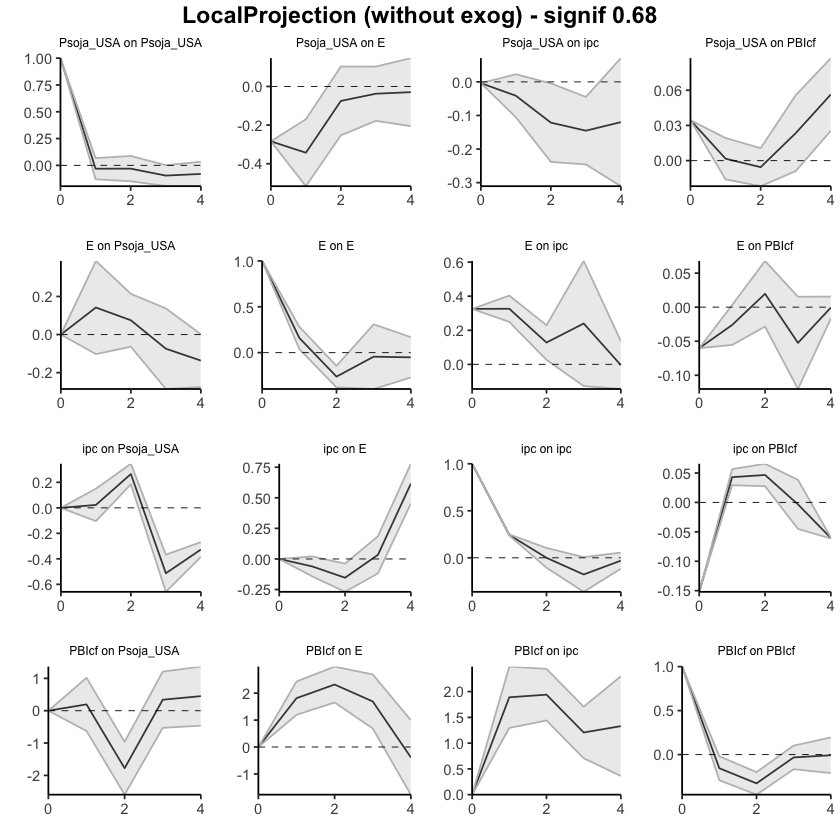

In [31]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.06074921,-0.14200795,0.02050953
38,ipc,E,2,-0.21419235,-0.41075687,-0.01762783
39,ipc,E,3,-0.18010085,-0.52852763,0.16832593
40,ipc,E,4,0.43555490,-0.07533059,0.94644038


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000,0.000000
52,PBIcf,E,1,1.814446,1.194315,2.434577
53,PBIcf,E,2,4.135570,2.849287,5.421852
54,PBIcf,E,3,5.828609,3.538402,8.118815
55,PBIcf,E,4,5.442160,1.769492,9.114828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.2840586,-0.2840586,-0.2840586
2,Psoja_USA,E,1,-0.6271854,-0.8004075,-0.4539632
3,Psoja_USA,E,2,-0.7020563,-1.0534199,-0.3506926
4,Psoja_USA,E,3,-0.7395724,-1.2314532,-0.2476916
5,Psoja_USA,E,4,-0.7689661,-1.4369978,-0.1009344


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.03446358,0.034463581,0.03446358
12,Psoja_USA,PBIcf,1,0.03610052,0.018460253,0.05374079
13,Psoja_USA,PBIcf,2,0.03051970,-0.003336471,0.06437588
14,Psoja_USA,PBIcf,3,0.05397640,-0.012253378,0.12020618
15,Psoja_USA,PBIcf,4,0.11041490,0.013239610,0.20759020


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.14186526,-0.1026898,0.3864203
18,E,Psoja_USA,2,0.21682222,-0.1665156,0.6001600
19,E,Psoja_USA,3,0.14255535,-0.4523345,0.7374451
20,E,Psoja_USA,4,0.00584031,-0.7274757,0.7391563


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Psoja_USA,1,0.02287427,-0.10445562,0.1502042
33,ipc,Psoja_USA,2,0.28802416,0.08015522,0.4958931
34,ipc,Psoja_USA,3,-0.22511793,-0.57871691,0.1284811
35,ipc,Psoja_USA,4,-0.55223575,-0.96404794,-0.1404236


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.00000000
47,PBIcf,Psoja_USA,1,0.1952847,-0.6260178,1.01658714
48,PBIcf,Psoja_USA,2,-1.5826209,-3.2209667,0.05572487
49,PBIcf,Psoja_USA,3,-1.2435142,-3.7508315,1.26380310
50,PBIcf,Psoja_USA,4,-0.7929790,-4.2129905,2.62703263


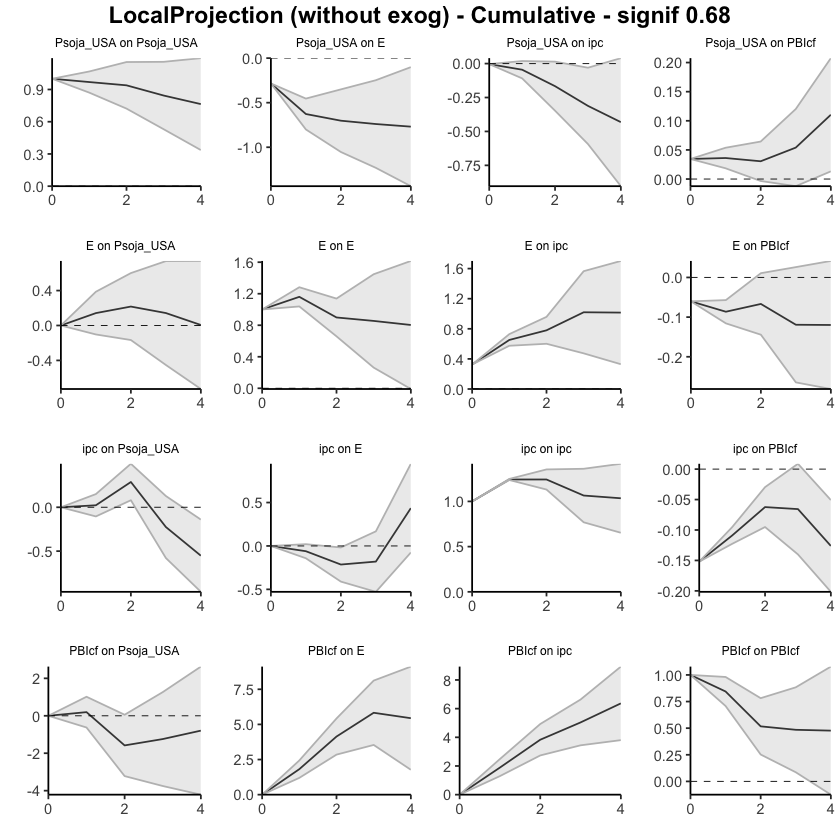

In [32]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,0.44063749,0.3363602,0.54491475
38,ipc,E,2,-0.70555106,-1.6259452,0.21484306
39,ipc,E,3,-0.86137707,-0.9353480,-0.78740611
40,ipc,E,4,-0.02061521,-0.1285557,0.08732525


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,1.3600500,0.8183523,1.9017477
53,PBIcf,E,2,1.7091962,-1.4950782,4.9134706
54,PBIcf,E,3,1.1573188,0.3894984,1.9251391
55,PBIcf,E,4,0.4534853,0.3300037,0.5769668


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.33649300,-0.33649300,-0.33649300
2,Psoja_USA,E,1,-0.01962152,-0.19097350,0.15173047
3,Psoja_USA,E,2,-0.68758861,-1.22824499,-0.14693223
4,Psoja_USA,E,3,-0.77012819,-0.87328426,-0.66697212
5,Psoja_USA,E,4,0.07647347,0.05489345,0.09805349


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.036700731,0.03670073,0.03670073
12,Psoja_USA,PBIcf,1,0.008243021,-0.01300775,0.02949379
13,Psoja_USA,PBIcf,2,-0.006363539,-0.04349804,0.03077096
14,Psoja_USA,PBIcf,3,0.205129760,0.18303992,0.22721960
15,Psoja_USA,PBIcf,4,0.085531649,0.01929508,0.15176822


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.0000000,0.00000000,0.0000000
17,E,Psoja_USA,1,-0.2439893,-0.34511938,-0.1428593
18,E,Psoja_USA,2,0.1696266,-0.07789667,0.4171498
19,E,Psoja_USA,3,-0.5606531,-0.64938975,-0.4719164
20,E,Psoja_USA,4,-0.2510948,-0.82065005,0.3184605


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.000000000,0.0000000,0.0000000
32,ipc,Psoja_USA,1,0.443263862,0.4964761,0.3900516
33,ipc,Psoja_USA,2,0.404090986,0.3054478,0.5027342
34,ipc,Psoja_USA,3,-1.302321349,-1.3064119,-1.2982308
35,ipc,Psoja_USA,4,0.002672595,-0.4474463,0.4527915


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.000000,0.000000
47,PBIcf,Psoja_USA,1,0.01272657,-1.009689,1.035142
48,PBIcf,Psoja_USA,2,-1.99854196,-2.480855,-1.516229
49,PBIcf,Psoja_USA,3,2.15610946,1.532542,2.779677
50,PBIcf,Psoja_USA,4,2.42515801,2.202370,2.647946


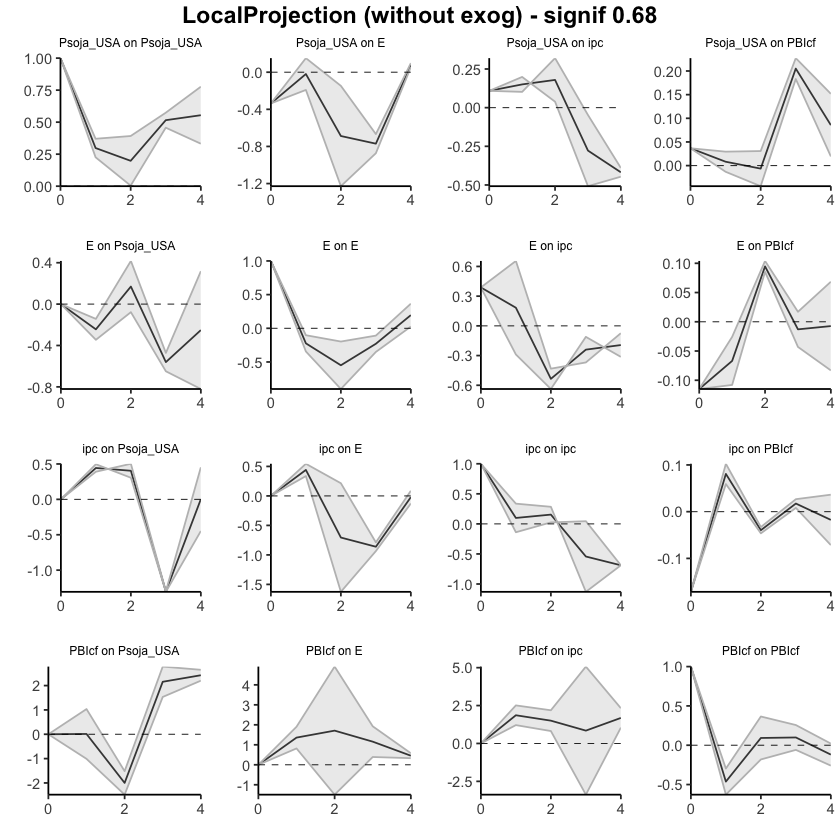

In [33]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,0.4406375,0.3363602,0.54491475
38,ipc,E,2,-0.2649136,-1.2895850,0.75975781
39,ipc,E,3,-1.1262906,-2.2249330,-0.02764830
40,ipc,E,4,-1.1469059,-2.3534887,0.05967695


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.360050,0.81835235,1.901748
53,PBIcf,E,2,3.069246,-0.67672588,6.815218
54,PBIcf,E,3,4.226565,-0.28722747,8.740357
55,PBIcf,E,4,4.680050,0.04277623,9.317324


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.3364930,-0.3364930,-0.3364930
2,Psoja_USA,E,1,-0.3561145,-0.5274665,-0.1847625
3,Psoja_USA,E,2,-1.0437031,-1.7557115,-0.3316948
4,Psoja_USA,E,3,-1.8138313,-2.6289958,-0.9986669
5,Psoja_USA,E,4,-1.7373579,-2.5741023,-0.9006134


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.03670073,0.03670073,0.03670073
12,Psoja_USA,PBIcf,1,0.04494375,0.02369298,0.06619452
13,Psoja_USA,PBIcf,2,0.03858021,-0.01980506,0.09696548
14,Psoja_USA,PBIcf,3,0.24370997,0.16323486,0.32418509
15,Psoja_USA,PBIcf,4,0.32924162,0.18252994,0.47595330


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,-0.24398935,-0.3451194,-0.1428593
18,E,Psoja_USA,2,-0.07436278,-0.4230160,0.2742905
19,E,Psoja_USA,3,-0.63501585,-1.0724058,-0.1976259
20,E,Psoja_USA,4,-0.88611060,-1.8930558,0.1208346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,0.4432639,0.4964761,0.39005163
33,ipc,Psoja_USA,2,0.8473548,0.8019239,0.89278579
34,ipc,Psoja_USA,3,-0.4549665,-0.5044880,-0.40544499
35,ipc,Psoja_USA,4,-0.4522939,-0.9519343,0.04734651


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,0.01272657,-1.0096890,1.0351421
48,PBIcf,Psoja_USA,2,-1.98581540,-3.4905441,-0.4810867
49,PBIcf,Psoja_USA,3,0.17029406,-1.9580019,2.2985900
50,PBIcf,Psoja_USA,4,2.59545208,0.2443684,4.9465358


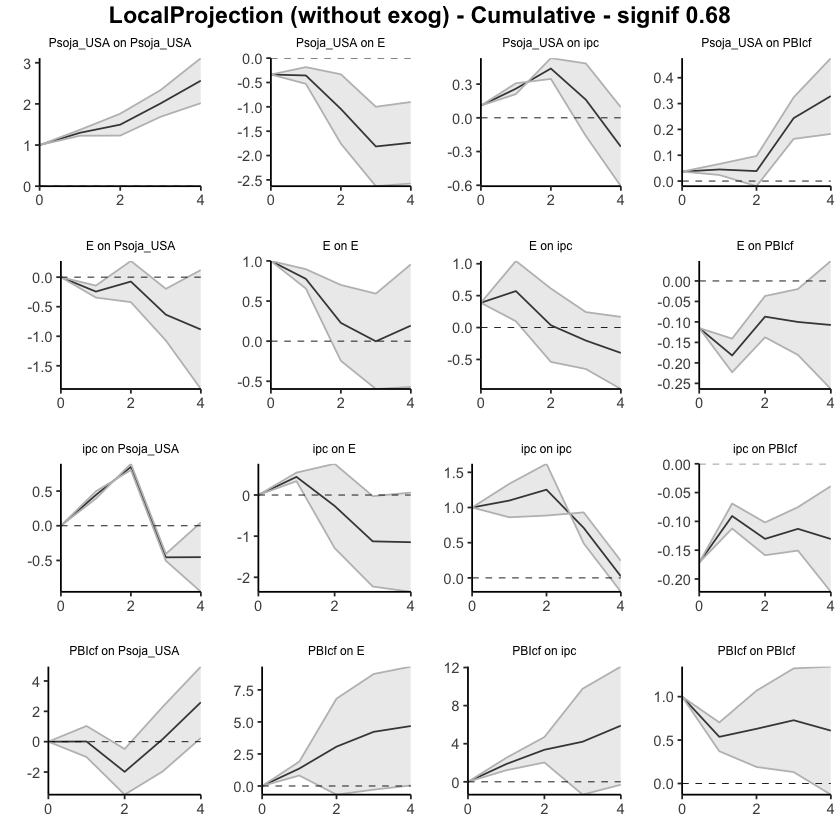

In [35]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.10652437,-0.17704047,-0.03600827
38,ipc,E,2,-0.14564863,-0.26543218,-0.02586507
39,ipc,E,3,0.03847828,-0.09605823,0.17301478
40,ipc,E,4,0.61639594,0.46806266,0.76472921


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,1.4791570,0.9153999,2.0429141
53,PBIcf,E,2,2.1376181,1.5631521,2.7120842
54,PBIcf,E,3,1.5903966,0.5502326,2.6305605
55,PBIcf,E,4,-0.4660004,-1.8426182,0.9106175


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.218969447,-0.218969447,-0.21896945
2,Pmaíz_USA,E,1,-0.237542108,-0.350343592,-0.12474062
3,Pmaíz_USA,E,2,-0.006760052,-0.073887468,0.06036736
4,Pmaíz_USA,E,3,0.043231938,0.004312799,0.08215108
5,Pmaíz_USA,E,4,0.058094497,-0.010990250,0.12717924


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.0149057249,0.014905725,0.014905725
12,Pmaíz_USA,PBIcf,1,0.0235440504,0.015478371,0.031609729
13,Pmaíz_USA,PBIcf,2,-0.0001322648,-0.008041354,0.007776825
14,Pmaíz_USA,PBIcf,3,-0.0101170013,-0.033100466,0.012866463
15,Pmaíz_USA,PBIcf,4,0.0568013590,0.036483869,0.077118849


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,0.03620249,-0.1616989,0.23410389
18,E,Pmaíz_USA,2,0.17348431,-0.3781812,0.72514984
19,E,Pmaíz_USA,3,-0.08080817,-0.2301732,0.06855686
20,E,Pmaíz_USA,4,-0.09421572,-0.2208695,0.03243808


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.27022595,0.07906947,0.46138243
33,ipc,Pmaíz_USA,2,-0.04380192,-0.20517756,0.11757372
34,ipc,Pmaíz_USA,3,-0.14751982,-0.21267282,-0.08236682
35,ipc,Pmaíz_USA,4,-0.19045352,-0.23980343,-0.14110362


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,0.01381695,-0.7354122,0.7630461
48,PBIcf,Pmaíz_USA,2,-0.69986467,-2.0804253,0.6806959
49,PBIcf,Pmaíz_USA,3,0.01842476,-0.9590929,0.9959424
50,PBIcf,Pmaíz_USA,4,-0.05605122,-1.0332046,0.9211021


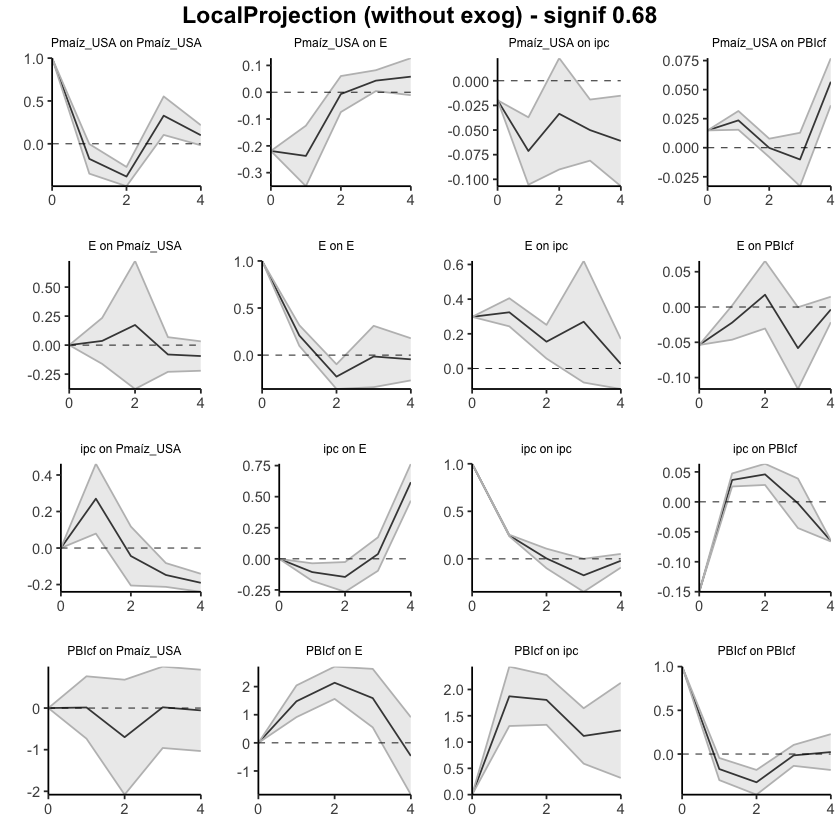

In [36]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.1065244,-0.17704047,-0.03600827
38,ipc,E,2,-0.2521730,-0.44247265,-0.06187334
39,ipc,E,3,-0.2136947,-0.53853088,0.11114144
40,ipc,E,4,0.4027012,-0.07046822,0.87587066


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,1.479157,0.9153999,2.042914
53,PBIcf,E,2,3.616775,2.4785520,4.754998
54,PBIcf,E,3,5.207172,3.0287846,7.385559
55,PBIcf,E,4,4.741171,1.1861664,8.296176


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.2189694,-0.2189694,-0.21896945
2,Pmaíz_USA,E,1,-0.4565116,-0.5693130,-0.34371007
3,Pmaíz_USA,E,2,-0.4632716,-0.6432005,-0.28334271
4,Pmaíz_USA,E,3,-0.4200397,-0.6388877,-0.20119163
5,Pmaíz_USA,E,4,-0.3619452,-0.6498780,-0.07401238


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.01490572,0.01490572,0.01490572
12,Pmaíz_USA,PBIcf,1,0.03844978,0.03038410,0.04651545
13,Pmaíz_USA,PBIcf,2,0.03831751,0.02234274,0.05429228
14,Pmaíz_USA,PBIcf,3,0.02820051,-0.01075772,0.06715874
15,Pmaíz_USA,PBIcf,4,0.08500187,0.02572614,0.14427759


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.03620249,-0.1616989,0.2341039
18,E,Pmaíz_USA,2,0.20968681,-0.5398801,0.9592537
19,E,Pmaíz_USA,3,0.12887864,-0.7700533,1.0278106
20,E,Pmaíz_USA,4,0.03466292,-0.9909228,1.0602487


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.2702259,0.07906947,0.4613824
33,ipc,Pmaíz_USA,2,0.2264240,-0.12610810,0.5789562
34,ipc,Pmaíz_USA,3,0.0789042,-0.33878092,0.4965893
35,ipc,Pmaíz_USA,4,-0.1115493,-0.57858435,0.3554857


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,0.01381695,-0.7354122,0.7630461
48,PBIcf,Pmaíz_USA,2,-0.68604772,-2.8158375,1.4437421
49,PBIcf,Pmaíz_USA,3,-0.66762296,-3.7749304,2.4396845
50,PBIcf,Pmaíz_USA,4,-0.72367418,-4.8081350,3.3607866


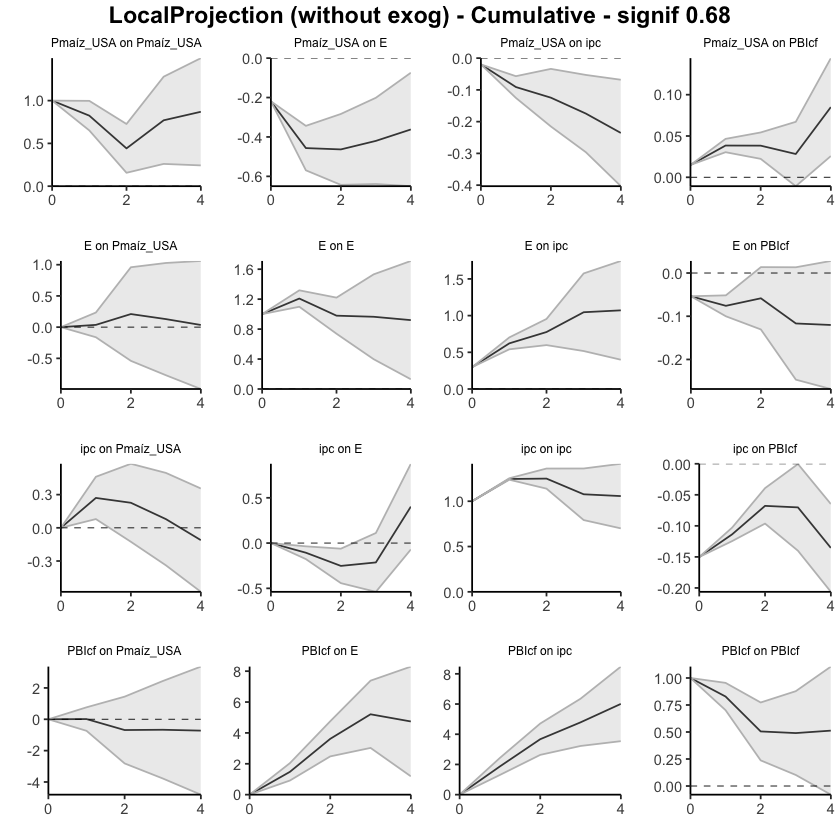

In [37]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2273883,0.1504002,0.3043765
38,ipc,E,2,-0.7837187,-1.0064520,-0.5609854
39,ipc,E,3,-0.4395151,-0.5753051,-0.3037252
40,ipc,E,4,0.8460298,-0.2835310,1.9755906


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,1.0678518,0.1456720,1.990031
53,PBIcf,E,2,1.5536683,0.4701102,2.637226
54,PBIcf,E,3,1.7041982,0.8755289,2.532868
55,PBIcf,E,4,-0.3777108,-1.8386674,1.083246


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.05472809,-0.05472809,-0.05472809
2,Pmaíz_USA,E,1,-0.55098579,-0.69154135,-0.41043023
3,Pmaíz_USA,E,2,-0.33015380,-0.46595524,-0.19435236
4,Pmaíz_USA,E,3,0.22562849,0.06886201,0.38239497
5,Pmaíz_USA,E,4,0.39004287,-0.10546359,0.88554932


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.030775908,0.03077591,0.03077591
12,Pmaíz_USA,PBIcf,1,-0.033810510,-0.05237557,-0.01524545
13,Pmaíz_USA,PBIcf,2,0.086060875,0.04564721,0.12647454
14,Pmaíz_USA,PBIcf,3,0.025745829,-0.95344378,1.00493544
15,Pmaíz_USA,PBIcf,4,0.006591796,0.00198574,0.01119785


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.215116886,-0.3128410,-0.1173928
18,E,Pmaíz_USA,2,0.380017633,0.3502718,0.4097634
19,E,Pmaíz_USA,3,-0.004927493,-0.1141997,0.1043447
20,E,Pmaíz_USA,4,-0.384278040,-0.5372338,-0.2313223


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Pmaíz_USA,1,0.52919581,0.3975891,0.6608025
33,ipc,Pmaíz_USA,2,0.09565017,0.0742610,0.1170393
34,ipc,Pmaíz_USA,3,-0.92362662,-1.0152421,-0.8320111
35,ipc,Pmaíz_USA,4,-0.58680130,-0.5931519,-0.5804507


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
47,PBIcf,Pmaíz_USA,1,1.2374398,0.6707514,1.80412814
48,PBIcf,Pmaíz_USA,2,-0.5288778,-1.1569199,0.09916428
49,PBIcf,Pmaíz_USA,3,-0.2801521,-1.1278324,0.56752814
50,PBIcf,Pmaíz_USA,4,0.8604674,0.1622978,1.55863692


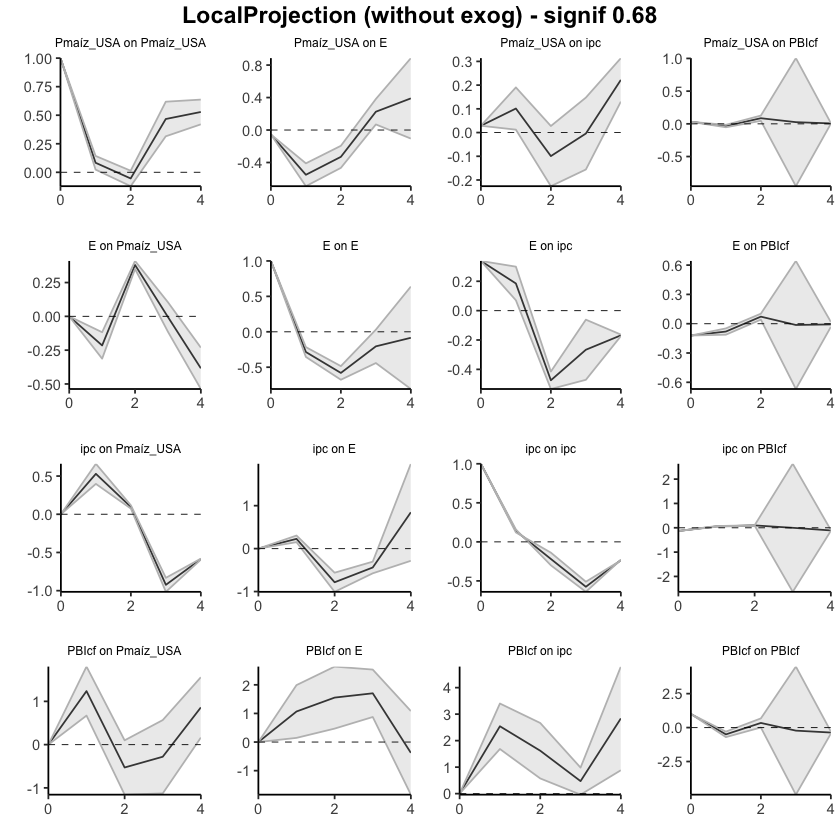

In [38]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2273883,0.1504002,0.3043765
38,ipc,E,2,-0.5563304,-0.8560518,-0.2566089
39,ipc,E,3,-0.9958455,-1.4313568,-0.5603341
40,ipc,E,4,-0.1498157,-1.7148878,1.4152564


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,1.067852,0.1456720,1.990031
53,PBIcf,E,2,2.621520,0.6157822,4.627258
54,PBIcf,E,3,4.325718,1.4913110,7.160125
55,PBIcf,E,4,3.948007,-0.3473564,8.243371


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.05472809,-0.05472809,-0.05472809
2,Pmaíz_USA,E,1,-0.60571388,-0.74626945,-0.46515832
3,Pmaíz_USA,E,2,-0.93586768,-1.21222468,-0.65951068
4,Pmaíz_USA,E,3,-0.71023919,-1.14336267,-0.27711571
5,Pmaíz_USA,E,4,-0.32019632,-1.24882626,0.60843361


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.030775908,0.03077591,0.03077591
12,Pmaíz_USA,PBIcf,1,-0.003034602,-0.02159966,0.01553046
13,Pmaíz_USA,PBIcf,2,0.083026273,0.02404755,0.14200500
14,Pmaíz_USA,PBIcf,3,0.108772102,-0.92939623,1.14694044
15,Pmaíz_USA,PBIcf,4,0.115363899,-0.92741049,1.15813829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.0000000,0.00000000,0.0000000
17,E,Pmaíz_USA,1,-0.2151169,-0.31284095,-0.1173928
18,E,Pmaíz_USA,2,0.1649007,0.03743088,0.2923706
19,E,Pmaíz_USA,3,0.1599733,-0.07676879,0.3967153
20,E,Pmaíz_USA,4,-0.2243048,-0.61400261,0.1653930


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Pmaíz_USA,1,0.5291958,0.3975891,0.66080253
33,ipc,Pmaíz_USA,2,0.6248460,0.4718501,0.77784187
34,ipc,Pmaíz_USA,3,-0.2987806,-0.5433921,-0.05416923
35,ipc,Pmaíz_USA,4,-0.8855819,-1.1365440,-0.63461989


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.000000
47,PBIcf,Pmaíz_USA,1,1.2374398,0.6707514,1.804128
48,PBIcf,Pmaíz_USA,2,0.7085620,-0.4861685,1.903292
49,PBIcf,Pmaíz_USA,3,0.4284099,-1.6140008,2.470821
50,PBIcf,Pmaíz_USA,4,1.2888772,-1.4517030,4.029457


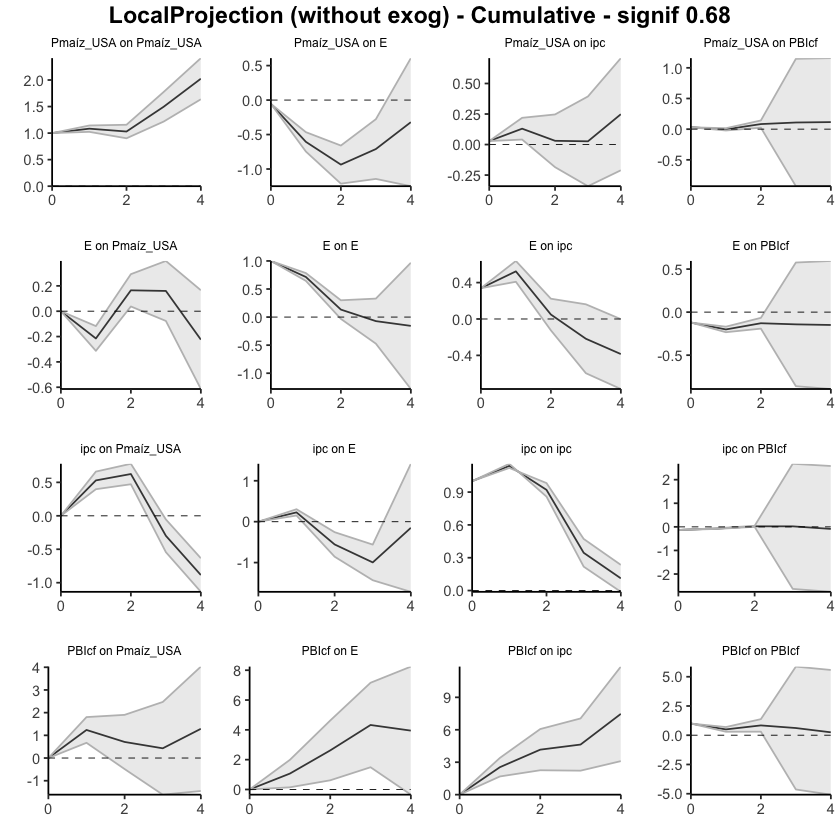

In [39]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.000000000
37,ipc,E,1,-0.06443786,-0.12513805,-0.003737678
38,ipc,E,2,-0.13281878,-0.26990362,0.004266058
39,ipc,E,3,0.04238109,-0.08979102,0.174553207
40,ipc,E,4,0.61673124,0.46505389,0.768408583


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,1.4409155,0.8120054,2.0698255
53,PBIcf,E,2,2.1082130,1.5440745,2.6723516
54,PBIcf,E,3,1.5841955,0.4471932,2.7211977
55,PBIcf,E,4,-0.4510237,-1.8304660,0.9284187


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.24770326,-0.2477033,-0.24770326
2,Ptrigo_USA,E,1,-0.28845171,-0.4193190,-0.15758438
3,Ptrigo_USA,E,2,-0.21368174,-0.4160460,-0.01131747
4,Ptrigo_USA,E,3,-0.05565316,-0.2797815,0.16847515
5,Ptrigo_USA,E,4,0.11915615,-0.1065982,0.34491048


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.005968466,0.0059684661,0.005968466
12,Ptrigo_USA,PBIcf,1,0.021370894,-0.0003313285,0.043073116
13,Ptrigo_USA,PBIcf,2,0.005001423,-0.0092428270,0.019245673
14,Ptrigo_USA,PBIcf,3,0.013997865,-0.0150126503,0.043008380
15,Ptrigo_USA,PBIcf,4,0.053003652,0.0269828720,0.079024433


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.000000000,0.00000000
17,E,Ptrigo_USA,1,0.20374047,0.004863639,0.40261731
18,E,Ptrigo_USA,2,0.05910454,-0.275344434,0.39355350
19,E,Ptrigo_USA,3,-0.04974397,-0.183078002,0.08359007
20,E,Ptrigo_USA,4,-0.07501722,-0.193033365,0.04299892


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Ptrigo_USA,1,0.03789376,-0.02929185,0.10507936
33,ipc,Ptrigo_USA,2,0.01980750,-0.13101994,0.17063494
34,ipc,Ptrigo_USA,3,-0.18151667,-0.27017166,-0.09286169
35,ipc,Ptrigo_USA,4,-0.32287573,-0.35828803,-0.28746342


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.1489256,-0.5470885,0.8449396
48,PBIcf,Ptrigo_USA,2,0.3757787,-1.1933993,1.9449568
49,PBIcf,Ptrigo_USA,3,-0.2889002,-0.9606259,0.3828255
50,PBIcf,Ptrigo_USA,4,-0.6561400,-1.4327531,0.1204730


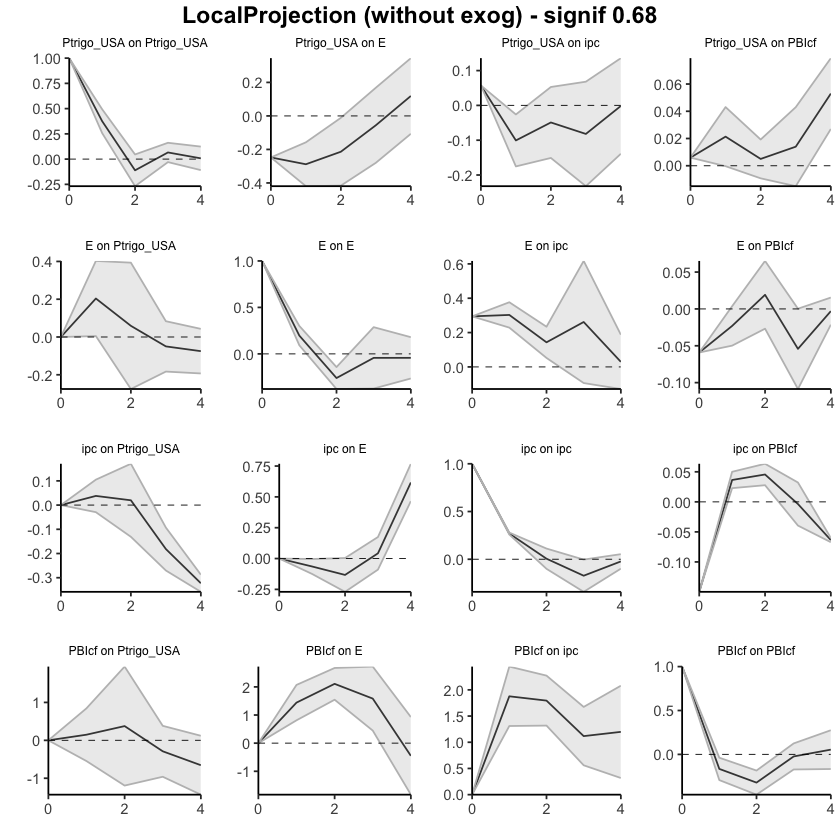

In [40]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000000
37,ipc,E,1,-0.06443786,-0.1251380,-0.0037376781
38,ipc,E,2,-0.19725664,-0.3950417,0.0005283797
39,ipc,E,3,-0.15487555,-0.4848327,0.1750815862
40,ipc,E,4,0.46185568,-0.0197788,0.9434901693


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,1.440915,0.8120054,2.069826
53,PBIcf,E,2,3.549128,2.3560799,4.742177
54,PBIcf,E,3,5.133324,2.8032731,7.463375
55,PBIcf,E,4,4.682300,0.9728071,8.391793


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.2477033,-0.2477033,-0.24770326
2,Ptrigo_USA,E,1,-0.5361550,-0.6670223,-0.40528764
3,Ptrigo_USA,E,2,-0.7498367,-1.0830683,-0.41660511
4,Ptrigo_USA,E,3,-0.8054899,-1.3628498,-0.24812997
5,Ptrigo_USA,E,4,-0.6863337,-1.4694480,0.09678051


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.005968466,0.005968466,0.005968466
12,Ptrigo_USA,PBIcf,1,0.027339360,0.005637138,0.049041582
13,Ptrigo_USA,PBIcf,2,0.032340783,-0.003605689,0.068287255
14,Ptrigo_USA,PBIcf,3,0.046338648,-0.018618340,0.111295636
15,Ptrigo_USA,PBIcf,4,0.099342300,0.008364532,0.190320068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.000000000,0.0000000
17,E,Ptrigo_USA,1,0.2037405,0.004863639,0.4026173
18,E,Ptrigo_USA,2,0.2628450,-0.270480795,0.7961708
19,E,Ptrigo_USA,3,0.2131010,-0.453558797,0.8797609
20,E,Ptrigo_USA,4,0.1380838,-0.646592161,0.9227598


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,0.03789376,-0.02929185,0.1050794
33,ipc,Ptrigo_USA,2,0.05770126,-0.16031179,0.2757143
34,ipc,Ptrigo_USA,3,-0.12381542,-0.43048345,0.1828526
35,ipc,Ptrigo_USA,4,-0.44669114,-0.78877148,-0.1046108


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.1489256,-0.5470885,0.8449396
48,PBIcf,Ptrigo_USA,2,0.5247043,-1.7404878,2.7898964
49,PBIcf,Ptrigo_USA,3,0.2358041,-2.7011136,3.1727219
50,PBIcf,Ptrigo_USA,4,-0.4203359,-4.1338667,3.2931949


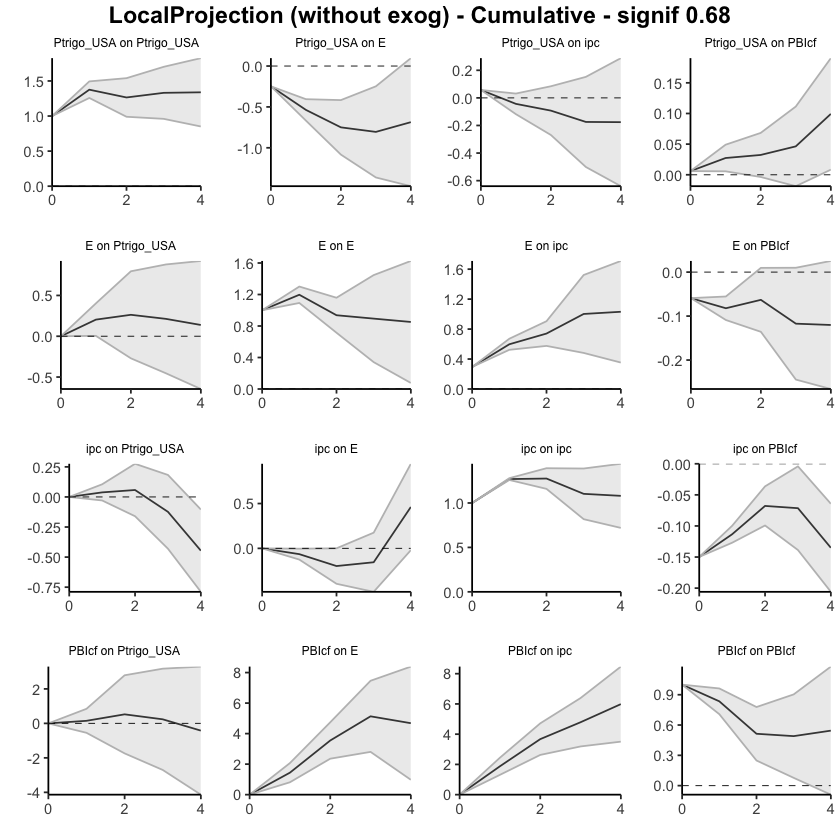

In [41]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.4257493,-0.5984801,-0.2530185
38,ipc,E,2,-1.0520979,-1.0989286,-1.0052672
39,ipc,E,3,-1.0225237,-1.1350104,-0.9100369
40,ipc,E,4,0.7699826,0.8118658,0.7280993


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.7334140,0.2648327,1.201995
53,PBIcf,E,2,1.6585423,1.0792928,2.237792
54,PBIcf,E,3,2.5540664,1.7535294,3.354603
55,PBIcf,E,4,-0.1884082,-2.0355212,1.658705


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.5590641,-0.55906406,-0.5590641
2,Ptrigo_USA,E,1,0.1905340,-0.05393425,0.4350022
3,Ptrigo_USA,E,2,-0.9788606,-1.26324137,-0.6944798
4,Ptrigo_USA,E,3,0.4792175,-0.07085756,1.0292925
5,Ptrigo_USA,E,4,0.8192910,0.67782095,0.9607610


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.004493583,0.004493583,0.004493583
12,Ptrigo_USA,PBIcf,1,0.069703382,0.026725355,0.112681409
13,Ptrigo_USA,PBIcf,2,-0.004149221,-0.035125349,0.026826907
14,Ptrigo_USA,PBIcf,3,0.034986515,0.021273355,0.048699676
15,Ptrigo_USA,PBIcf,4,-0.050248788,-0.068268409,-0.032229167


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.20810256,0.1441488,0.2720563
18,E,Ptrigo_USA,2,0.01219806,-0.1355842,0.1599803
19,E,Ptrigo_USA,3,-0.50343721,-0.4735882,-0.5332862
20,E,Ptrigo_USA,4,-0.32643103,-0.4718990,-0.1809631


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.09416599,-0.04802264,-0.1403093
33,ipc,Ptrigo_USA,2,-0.29725326,-0.32404004,-0.2704665
34,ipc,Ptrigo_USA,3,-0.53792085,-0.44385887,-0.6319828
35,ipc,Ptrigo_USA,4,-0.53274310,-0.66851127,-0.3969749


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.6883027,-0.2062602,1.5828656
48,PBIcf,Ptrigo_USA,2,-0.3957703,-1.0231094,0.2315689
49,PBIcf,Ptrigo_USA,3,0.6477630,-0.4875053,1.7830314
50,PBIcf,Ptrigo_USA,4,1.1889908,0.9293971,1.4485844


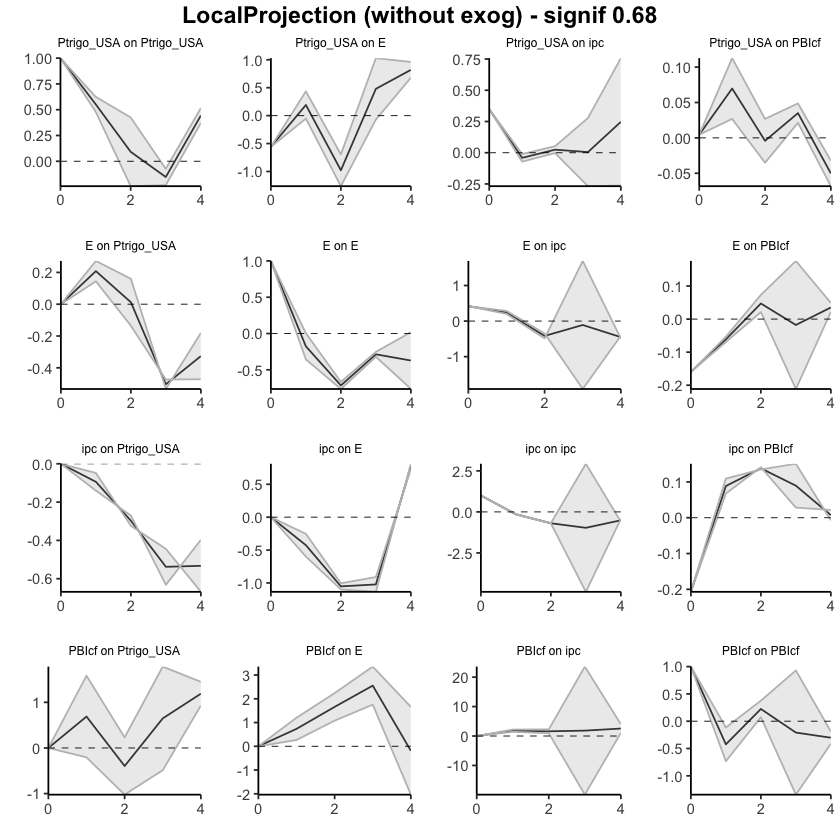

In [42]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.4257493,-0.5984801,-0.2530185
38,ipc,E,2,-1.4778472,-1.6974087,-1.2582857
39,ipc,E,3,-2.5003709,-2.8324192,-2.1683226
40,ipc,E,4,-1.7303883,-2.0205534,-1.4402233


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,0.733414,0.2648327,1.201995
53,PBIcf,E,2,2.391956,1.3441255,3.439787
54,PBIcf,E,3,4.946023,3.0976549,6.794390
55,PBIcf,E,4,4.757615,1.0621337,8.453095


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.55906406,-0.5590641,-0.5590641
2,Ptrigo_USA,E,1,-0.36853007,-0.6129983,-0.1240618
3,Ptrigo_USA,E,2,-1.34739064,-1.8762397,-0.8185416
4,Ptrigo_USA,E,3,-0.86817315,-1.9470972,0.2107509
5,Ptrigo_USA,E,4,-0.04888216,-1.2692763,1.1715120


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.004493583,0.004493583,0.004493583
12,Ptrigo_USA,PBIcf,1,0.074196965,0.031218939,0.117174992
13,Ptrigo_USA,PBIcf,2,0.070047744,-0.003906410,0.144001899
14,Ptrigo_USA,PBIcf,3,0.105034260,0.017366945,0.192701575
15,Ptrigo_USA,PBIcf,4,0.054785472,-0.050901465,0.160472408


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.000000000,0.0000000
17,E,Ptrigo_USA,1,0.2081026,0.144148816,0.2720563
18,E,Ptrigo_USA,2,0.2203006,0.008564608,0.4320366
19,E,Ptrigo_USA,3,-0.2831366,-0.465023608,-0.1012496
20,E,Ptrigo_USA,4,-0.6095676,-0.936922602,-0.2822127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.09416599,-0.04802264,-0.1403093
33,ipc,Ptrigo_USA,2,-0.39141925,-0.37206268,-0.4107758
34,ipc,Ptrigo_USA,3,-0.92934010,-0.81592155,-1.0427586
35,ipc,Ptrigo_USA,4,-1.46208320,-1.48443282,-1.4397336


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.000000
47,PBIcf,Ptrigo_USA,1,0.6883027,-0.2062602,1.582866
48,PBIcf,Ptrigo_USA,2,0.2925324,-1.2293696,1.814434
49,PBIcf,Ptrigo_USA,3,0.9402955,-1.7168749,3.597466
50,PBIcf,Ptrigo_USA,4,2.1292862,-0.7874778,5.046050


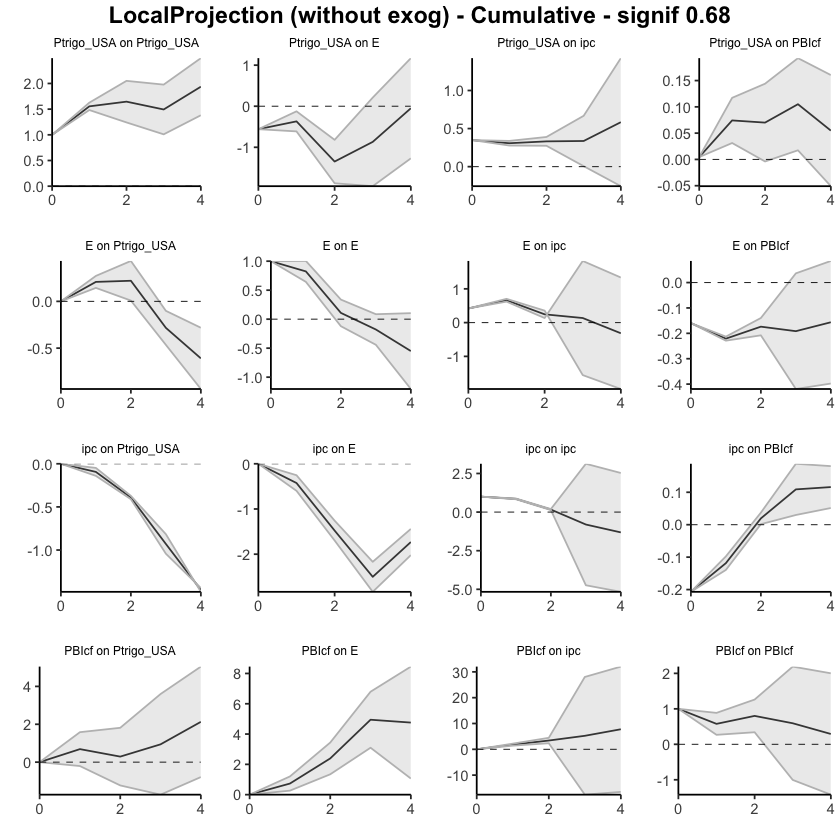

In [43]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1974. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.04277648,-0.1301778,0.04462487
13,ipc,E,2,-0.13045159,-0.2523558,-0.00854734
14,ipc,E,3,0.05086165,-0.1109448,0.21266813
15,ipc,E,4,0.61182784,0.4356754,0.78798032


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,1.8144459,1.1943152,2.4345766
23,PBIcf,E,2,2.3211236,1.6549716,2.9872757
24,PBIcf,E,3,1.6930391,0.6891155,2.6969628
25,PBIcf,E,4,-0.3864484,-1.7689099,0.9960132


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.29618100,0.29618100,0.2961810
2,E,ipc,1,0.29994988,0.22897905,0.3709207
3,E,ipc,2,0.10818777,0.01481701,0.2015585
4,E,ipc,3,0.23271186,-0.12385384,0.5892776
5,E,ipc,4,-0.01699991,-0.14492931,0.1109295


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.890278,1.2947141,2.485843
28,PBIcf,ipc,2,1.940890,1.4401063,2.441675
29,PBIcf,ipc,3,1.206879,0.7064448,1.707314
30,PBIcf,ipc,4,1.329903,0.3623168,2.297488


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.065999192,-0.06599919,-0.065999192
7,E,PBIcf,1,-0.025851314,-0.05336656,0.001663937
8,E,PBIcf,2,0.021610974,-0.02474638,0.067968333
9,E,PBIcf,3,-0.052017038,-0.11719271,0.013158634
10,E,PBIcf,4,0.001262775,-0.01274672,0.015272264


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.142080981,-0.14208098,-0.14208098
17,ipc,PBIcf,1,0.041402393,0.02632718,0.05647761
18,ipc,PBIcf,2,0.043443905,0.02313475,0.06375306
19,ipc,PBIcf,3,-0.003632646,-0.04665291,0.03938761
20,ipc,PBIcf,4,-0.060606918,-0.06352912,-0.05768472


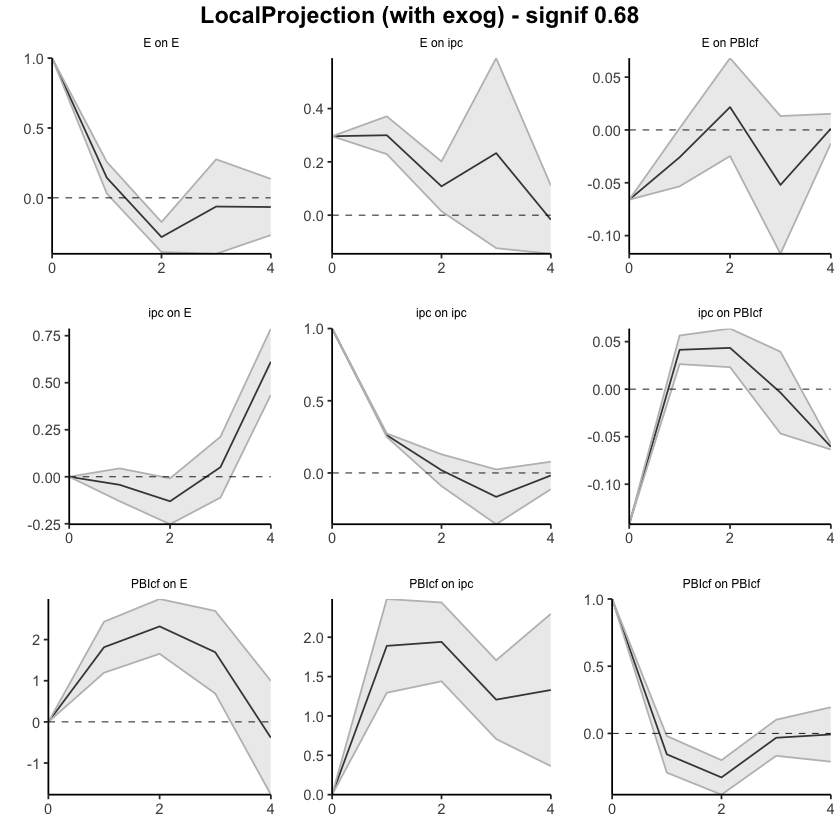

In [44]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,-0.04277648,-0.13017784,0.04462487
13,ipc,E,2,-0.17322807,-0.38253367,0.03607753
14,ipc,E,3,-0.12236642,-0.49347851,0.24874566
15,ipc,E,4,0.48946142,-0.05780314,1.03672598


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.000000,0.000000
22,PBIcf,E,1,1.814446,1.194315,2.434577
23,PBIcf,E,2,4.135570,2.849287,5.421852
24,PBIcf,E,3,5.828609,3.538402,8.118815
25,PBIcf,E,4,5.442160,1.769492,9.114828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2961810,0.2961810,0.2961810
2,E,ipc,1,0.5961309,0.5251600,0.6671017
3,E,ipc,2,0.7043186,0.5399771,0.8686602
4,E,ipc,3,0.9370305,0.4161232,1.4579378
5,E,ipc,4,0.9200306,0.2711939,1.5688673


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.890278,1.294714,2.485843
28,PBIcf,ipc,2,3.831169,2.734820,4.927517
29,PBIcf,ipc,3,5.038048,3.441265,6.634831
30,PBIcf,ipc,4,6.367951,3.803582,8.932319


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.06599919,-0.06599919,-0.065999192
7,E,PBIcf,1,-0.09185051,-0.11936576,-0.064335255
8,E,PBIcf,2,-0.07023953,-0.14411214,0.003633078
9,E,PBIcf,3,-0.12225657,-0.26130485,0.016791712
10,E,PBIcf,4,-0.12099380,-0.27405157,0.032063976


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14208098,-0.14208098,-0.14208098
17,ipc,PBIcf,1,-0.10067859,-0.11575380,-0.08560338
18,ipc,PBIcf,2,-0.05723468,-0.09261905,-0.02185031
19,ipc,PBIcf,3,-0.06086733,-0.13927196,0.01753730
20,ipc,PBIcf,4,-0.12147425,-0.20280108,-0.04014742


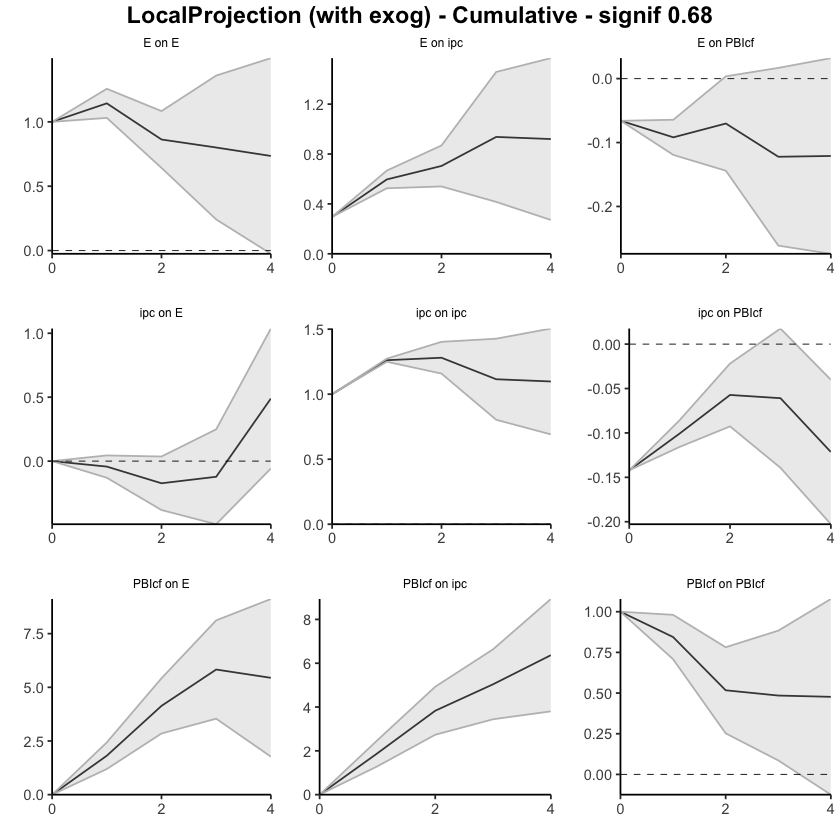

In [45]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,-0.10274948,-0.17470432,-0.03079463
13,ipc,E,2,-0.14019331,-0.26144293,-0.01894368
14,ipc,E,3,0.04253706,-0.09465401,0.17972812
15,ipc,E,4,0.61520668,0.46336020,0.76705316


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,1.4791570,0.9153999,2.0429141
23,PBIcf,E,2,2.1376181,1.5631521,2.7120842
24,PBIcf,E,3,1.5903966,0.5502326,2.6305605
25,PBIcf,E,4,-0.4660004,-1.8426182,0.9106175


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.28066575,0.28066575,0.2806658
2,E,ipc,1,0.31288770,0.23413273,0.3916427
3,E,ipc,2,0.14759237,0.05400087,0.2411839
4,E,ipc,3,0.26843860,-0.07721914,0.6140963
5,E,ipc,4,0.02150568,-0.11805688,0.1610682


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.870232,1.3054012,2.435062
28,PBIcf,ipc,2,1.801670,1.3284885,2.274852
29,PBIcf,ipc,3,1.116277,0.5896755,1.642879
30,PBIcf,ipc,4,1.222228,0.3183201,2.126135


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.054961357,-0.05496136,-0.054961357
7,E,PBIcf,1,-0.022071683,-0.04564043,0.001497068
8,E,PBIcf,2,0.017841443,-0.02920121,0.064884098
9,E,PBIcf,3,-0.058165496,-0.11495032,-0.001380668
10,E,PBIcf,4,-0.002462534,-0.01978888,0.014863813


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.147617322,-0.14761732,-0.14761732
17,ipc,PBIcf,1,0.036058081,0.02486313,0.04725303
18,ipc,PBIcf,2,0.045039775,0.02700099,0.06307856
19,ipc,PBIcf,3,-0.002486605,-0.04407657,0.03910336
20,ipc,PBIcf,4,-0.065243308,-0.06665212,-0.06383450


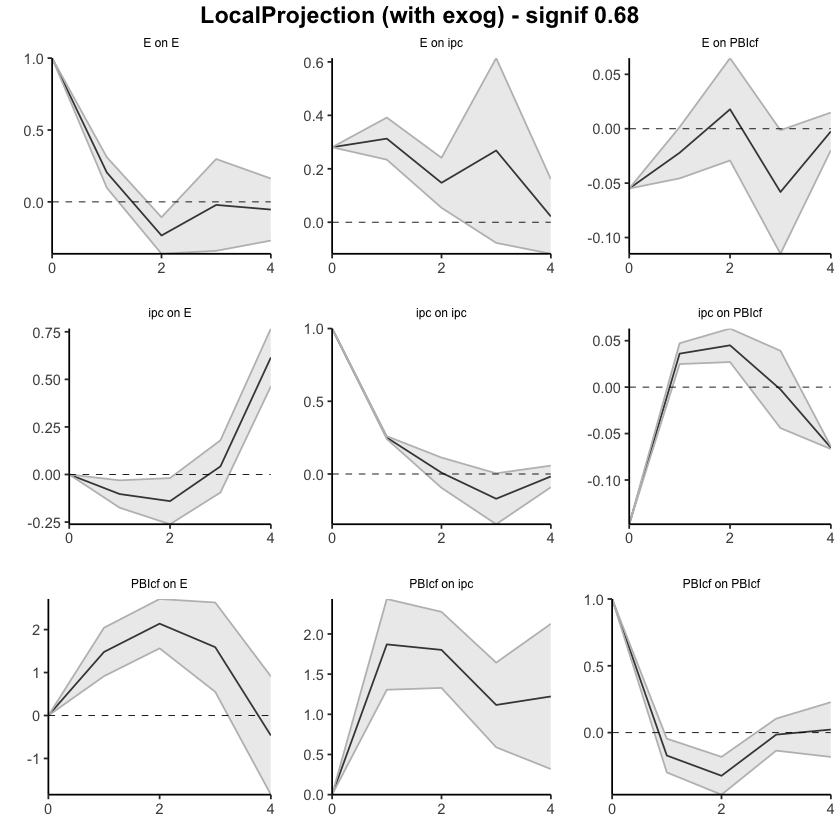

In [46]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1027495,-0.17470432,-0.03079463
13,ipc,E,2,-0.2429428,-0.43614725,-0.04973832
14,ipc,E,3,-0.2004057,-0.53080125,0.12998981
15,ipc,E,4,0.4148010,-0.06744106,0.89704297


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.479157,0.9153999,2.042914
23,PBIcf,E,2,3.616775,2.4785520,4.754998
24,PBIcf,E,3,5.207172,3.0287846,7.385559
25,PBIcf,E,4,4.741171,1.1861664,8.296176


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2806658,0.2806658,0.2806658
2,E,ipc,1,0.5935535,0.5147985,0.6723084
3,E,ipc,2,0.7411458,0.5687994,0.9134923
4,E,ipc,3,1.0095844,0.4915802,1.5275886
5,E,ipc,4,1.0310901,0.3735233,1.6886569


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.870232,1.305401,2.435062
28,PBIcf,ipc,2,3.671902,2.633890,4.709914
29,PBIcf,ipc,3,4.788179,3.223565,6.352793
30,PBIcf,ipc,4,6.010407,3.541885,8.478928


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.05496136,-0.05496136,-0.05496136
7,E,PBIcf,1,-0.07703304,-0.10060179,-0.05346429
8,E,PBIcf,2,-0.05919160,-0.12980300,0.01141981
9,E,PBIcf,3,-0.11735709,-0.24475333,0.01003914
10,E,PBIcf,4,-0.11981963,-0.26454221,0.02490296


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14761732,-0.14761732,-0.147617322
17,ipc,PBIcf,1,-0.11155924,-0.12275419,-0.100364290
18,ipc,PBIcf,2,-0.06651947,-0.09575321,-0.037285726
19,ipc,PBIcf,3,-0.06900607,-0.13982978,0.001817636
20,ipc,PBIcf,4,-0.13424938,-0.20648190,-0.062016861


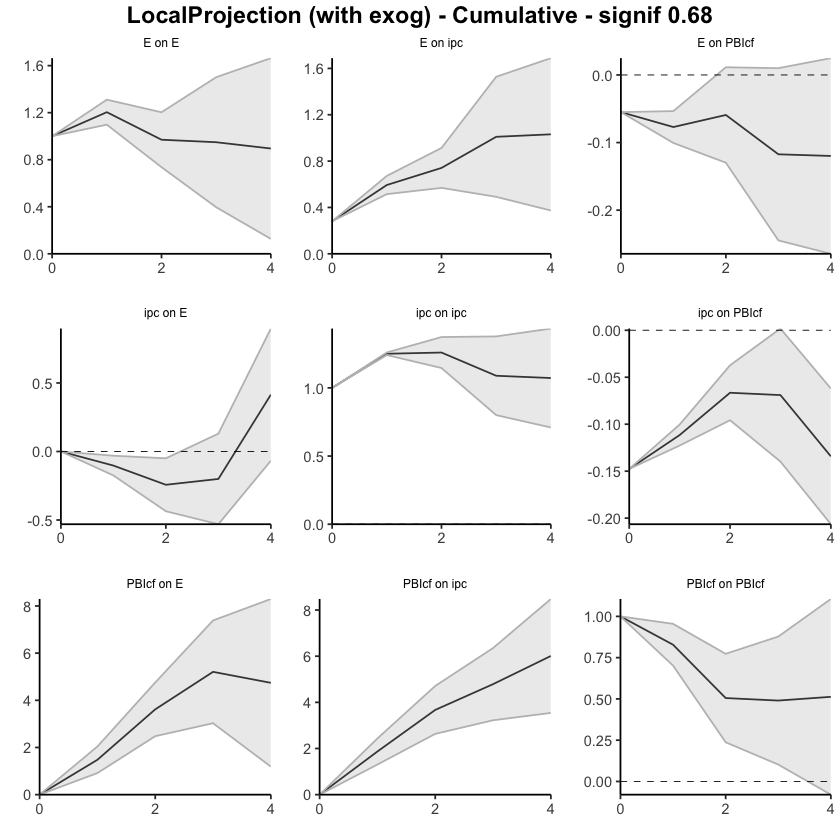

In [47]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.000000000
12,ipc,E,1,-0.05915208,-0.12215933,0.003855163
13,ipc,E,2,-0.12508512,-0.26423942,0.014069175
14,ipc,E,3,0.04819247,-0.08815056,0.184535508
15,ipc,E,4,0.61507672,0.45833910,0.771814346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,1.4409155,0.8120054,2.0698255
23,PBIcf,E,2,2.1082130,1.5440745,2.6723516
24,PBIcf,E,3,1.5841955,0.4471932,2.7211977
25,PBIcf,E,4,-0.4510237,-1.8304660,0.9284187


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.27013379,0.27013379,0.2701338
2,E,ipc,1,0.29237286,0.21985158,0.3648941
3,E,ipc,2,0.13941740,0.05210438,0.2267304
4,E,ipc,3,0.26350627,-0.08676671,0.6137793
5,E,ipc,4,0.02753063,-0.12689907,0.1819603


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.877034,1.3100845,2.443984
28,PBIcf,ipc,2,1.795002,1.3180788,2.271925
29,PBIcf,ipc,3,1.117273,0.5604164,1.674130
30,PBIcf,ipc,4,1.198512,0.3174876,2.079536


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.057527469,-0.05752747,-0.0575274686
7,E,PBIcf,1,-0.023601263,-0.04976416,0.0025616377
8,E,PBIcf,2,0.018666201,-0.02658183,0.0639142270
9,E,PBIcf,3,-0.054042848,-0.10734238,-0.0007433177
10,E,PBIcf,4,-0.001546483,-0.01945089,0.0163579220


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.146123314,-0.14612331,-0.14612331
17,ipc,PBIcf,1,0.035820572,0.02172730,0.04991385
18,ipc,PBIcf,2,0.044390185,0.02605545,0.06272492
19,ipc,PBIcf,3,-0.003726548,-0.04012197,0.03266887
20,ipc,PBIcf,4,-0.063498293,-0.06782574,-0.05917085


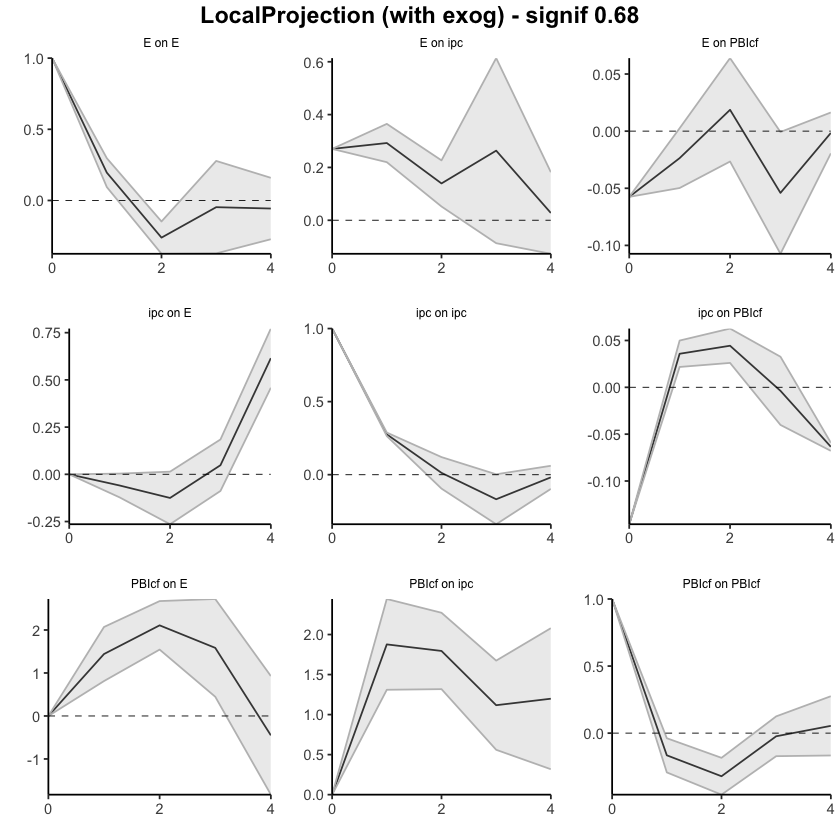

In [48]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.000000000
12,ipc,E,1,-0.05915208,-0.12215933,0.003855163
13,ipc,E,2,-0.18423720,-0.38639874,0.017924338
14,ipc,E,3,-0.13604473,-0.47454931,0.202459846
15,ipc,E,4,0.47903199,-0.01621021,0.974274192


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.440915,0.8120054,2.069826
23,PBIcf,E,2,3.549128,2.3560799,4.742177
24,PBIcf,E,3,5.133324,2.8032731,7.463375
25,PBIcf,E,4,4.682300,0.9728071,8.391793


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2701338,0.2701338,0.2701338
2,E,ipc,1,0.5625066,0.4899854,0.6350279
3,E,ipc,2,0.7019240,0.5420897,0.8617583
4,E,ipc,3,0.9654303,0.4553230,1.4755376
5,E,ipc,4,0.9929609,0.3284240,1.6574979


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.877034,1.310084,2.443984
28,PBIcf,ipc,2,3.672036,2.628163,4.715909
29,PBIcf,ipc,3,4.789310,3.188580,6.390040
30,PBIcf,ipc,4,5.987822,3.506067,8.469576


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.05752747,-0.05752747,-0.057527469
7,E,PBIcf,1,-0.08112873,-0.10729163,-0.054965831
8,E,PBIcf,2,-0.06246253,-0.13387346,0.008948396
9,E,PBIcf,3,-0.11650538,-0.24121584,0.008205078
10,E,PBIcf,4,-0.11805186,-0.26066672,0.024563000


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14612331,-0.14612331,-0.1461233138
17,ipc,PBIcf,1,-0.11030274,-0.12439602,-0.0962094657
18,ipc,PBIcf,2,-0.06591256,-0.09834057,-0.0334845466
19,ipc,PBIcf,3,-0.06963910,-0.13846253,-0.0008156761
20,ipc,PBIcf,4,-0.13313740,-0.20628827,-0.0599865266


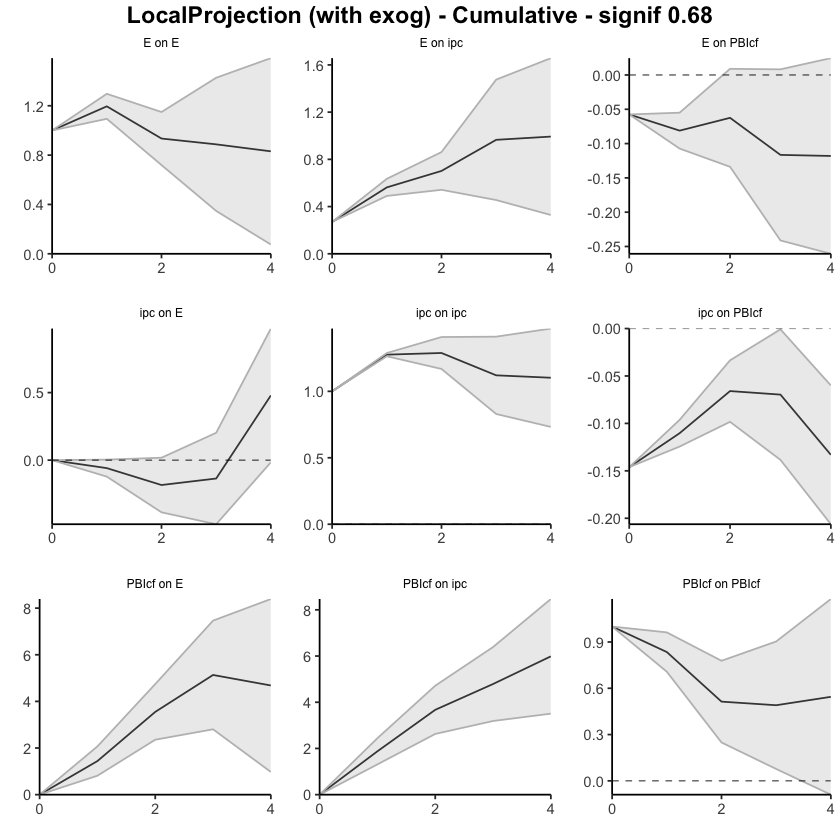

In [49]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.05307937,-0.1058926,0.2120513
13,ipc,E,2,-0.39476569,-0.5067137,-0.2828177
14,ipc,E,3,-0.06677990,-0.3763447,0.2427848
15,ipc,E,4,0.62029898,0.4949963,0.7456016


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000000,0.0000000
22,PBIcf,E,1,1.6836331,0.5218104072,2.8454557
23,PBIcf,E,2,1.8364041,1.2726151435,2.4001930
24,PBIcf,E,3,1.0687191,-0.0004627443,2.1379010
25,PBIcf,E,4,-0.6249773,-2.1640626942,0.9141082


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.27295410,0.27295410,0.2729541
2,E,ipc,1,0.30574766,0.21799944,0.3934959
3,E,ipc,2,0.07543425,-0.07081670,0.2216852
4,E,ipc,3,0.23354092,-0.12563625,0.5927181
5,E,ipc,4,0.04936293,-0.06414645,0.1628723


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.0445986,1.3691200,2.720077
28,PBIcf,ipc,2,1.8139999,1.2495492,2.378451
29,PBIcf,ipc,3,0.9139309,0.4668534,1.361008
30,PBIcf,ipc,4,1.1035090,0.2833007,1.923717


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04283095,-0.04283095,-0.042830953
7,E,PBIcf,1,-0.01655752,-0.04543891,0.012323871
8,E,PBIcf,2,0.03593298,-0.01460831,0.086474264
9,E,PBIcf,3,-0.05594835,-0.12353741,0.011640707
10,E,PBIcf,4,-0.02880344,-0.05299926,-0.004607607


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14357816,-0.14357816,-0.14357816
17,ipc,PBIcf,1,0.04709084,0.02664053,0.06754114
18,ipc,PBIcf,2,0.10811005,0.07813833,0.13808177
19,ipc,PBIcf,3,0.01414945,-0.03156540,0.05986429
20,ipc,PBIcf,4,-0.13950159,-0.16561109,-0.11339209


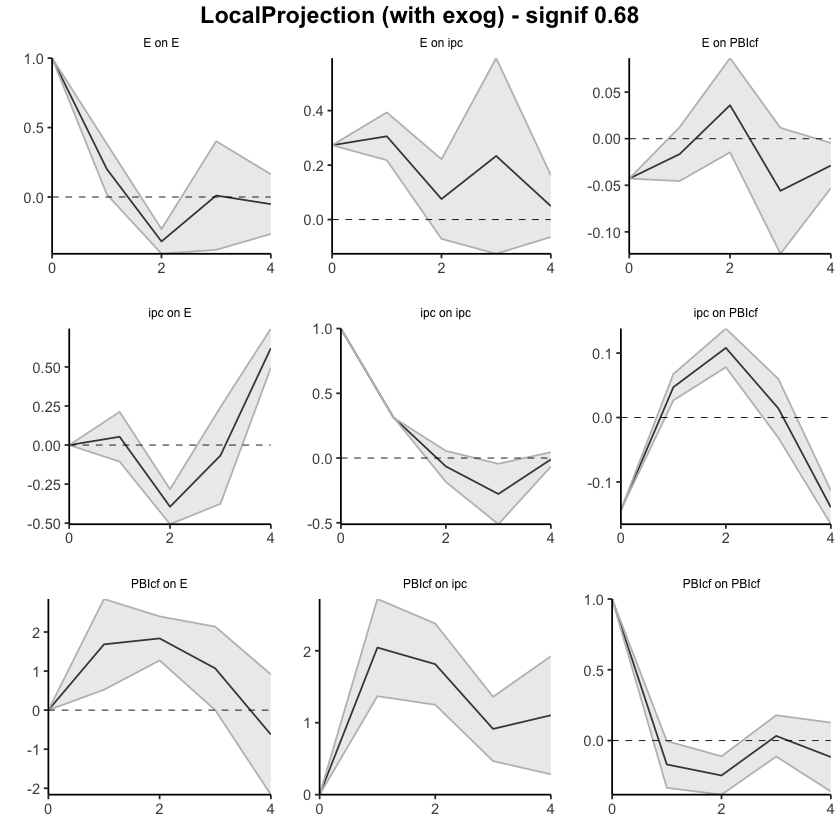

In [51]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,0.05307937,-0.1058926,0.21205130
13,ipc,E,2,-0.34168632,-0.6126063,-0.07076639
14,ipc,E,3,-0.40846623,-0.9889509,0.17201846
15,ipc,E,4,0.21183275,-0.4939546,0.91762009


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.683633,0.5218104,2.845456
23,PBIcf,E,2,3.520037,1.7944256,5.245649
24,PBIcf,E,3,4.588756,1.7939628,7.383550
25,PBIcf,E,4,3.963779,-0.3700999,8.297658


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2729541,0.2729541,0.2729541
2,E,ipc,1,0.5787018,0.4909535,0.6664500
3,E,ipc,2,0.6541360,0.4201368,0.8881352
4,E,ipc,3,0.8876769,0.2945006,1.4808533
5,E,ipc,4,0.9370399,0.2303541,1.6437256


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.044599,1.369120,2.720077
28,PBIcf,ipc,2,3.858599,2.618669,5.098528
29,PBIcf,ipc,3,4.772529,3.085523,6.459536
30,PBIcf,ipc,4,5.876038,3.368823,8.383254


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04283095,-0.04283095,-0.04283095
7,E,PBIcf,1,-0.05938847,-0.08826986,-0.03050708
8,E,PBIcf,2,-0.02345549,-0.10287817,0.05596718
9,E,PBIcf,3,-0.07940385,-0.22641558,0.06760789
10,E,PBIcf,4,-0.10820728,-0.27941485,0.06300028


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.14357816,-0.14357816,-0.143578162
17,ipc,PBIcf,1,-0.09648733,-0.11693763,-0.076037018
18,ipc,PBIcf,2,0.01162272,-0.03879930,0.062044751
19,ipc,PBIcf,3,0.02577217,-0.07036471,0.121909045
20,ipc,PBIcf,4,-0.11372942,-0.23597579,0.008516954


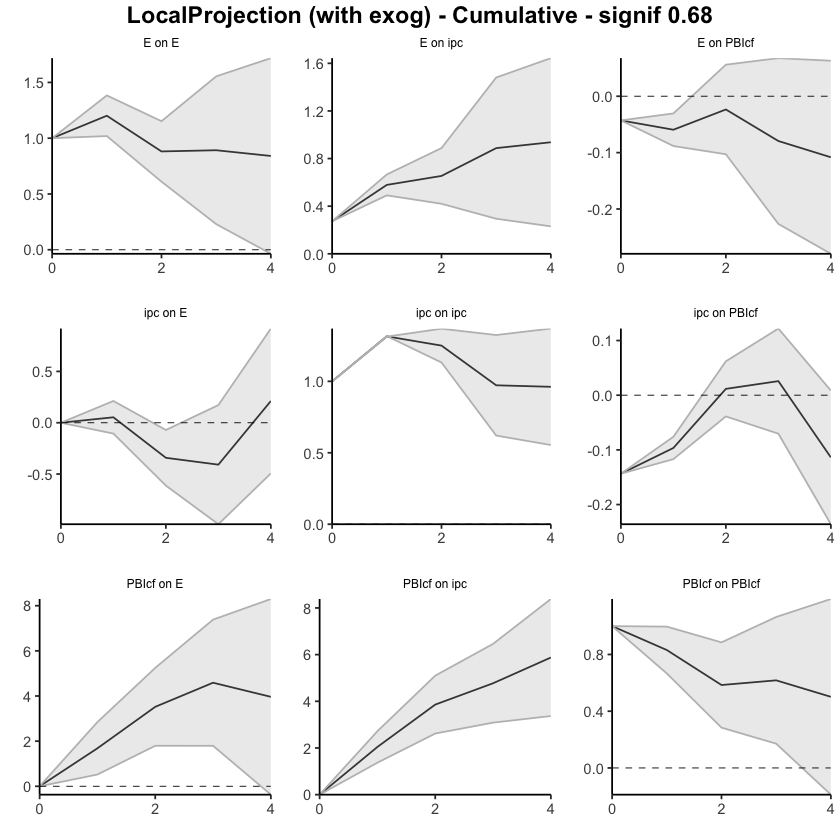

In [50]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1975. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.000000000,0.0000000
37,ipc,E,1,0.2348483,0.008329824,0.4613669
38,ipc,E,2,0.4826008,0.235763565,0.7294380
39,ipc,E,3,0.3210022,0.161151425,0.4808529
40,ipc,E,4,0.6997621,0.391215652,1.0083086


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.000000,0.000000
52,PBIcf,E,1,2.3999223,1.276460,3.523384
53,PBIcf,E,2,2.3258753,1.414485,3.237266
54,PBIcf,E,3,2.3605102,1.379726,3.341295
55,PBIcf,E,4,0.2277066,-1.413296,1.868709


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.458750740,-0.45875074,-0.4587507
2,Psoja_USA,E,1,-0.448022556,-0.56133635,-0.3347088
3,Psoja_USA,E,2,0.451786896,0.21963839,0.6839354
4,Psoja_USA,E,3,-0.052794708,-0.12266001,0.0170706
5,Psoja_USA,E,4,0.003123845,-0.09437904,0.1006267


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.038858532,0.038858532,0.03885853
12,Psoja_USA,PBIcf,1,0.007371171,-0.003358407,0.01810075
13,Psoja_USA,PBIcf,2,-0.020757739,-0.024228831,-0.01728665
14,Psoja_USA,PBIcf,3,0.033342863,0.017663163,0.04902256
15,Psoja_USA,PBIcf,4,0.059233325,0.035570388,0.08289626


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.00000000
17,E,Psoja_USA,1,0.17372525,-0.1489210,0.49637145
18,E,Psoja_USA,2,0.02886831,-0.1898760,0.24761261
19,E,Psoja_USA,3,-0.21932448,-0.4935040,0.05485509
20,E,Psoja_USA,4,-0.22963276,-0.4280832,-0.03118234


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Psoja_USA,1,-0.00634986,-0.18246596,0.1697662
33,ipc,Psoja_USA,2,0.06860697,-0.05663381,0.1938477
34,ipc,Psoja_USA,3,-0.52227121,-0.70956929,-0.3349731
35,ipc,Psoja_USA,4,-0.32216800,-0.43440278,-0.2099332


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,0.08339193,-0.7428824,0.9096662
48,PBIcf,Psoja_USA,2,-1.77888563,-2.5618074,-0.9959638
49,PBIcf,Psoja_USA,3,0.25246033,-0.6101711,1.1150918
50,PBIcf,Psoja_USA,4,0.34546450,-0.5694343,1.2603633


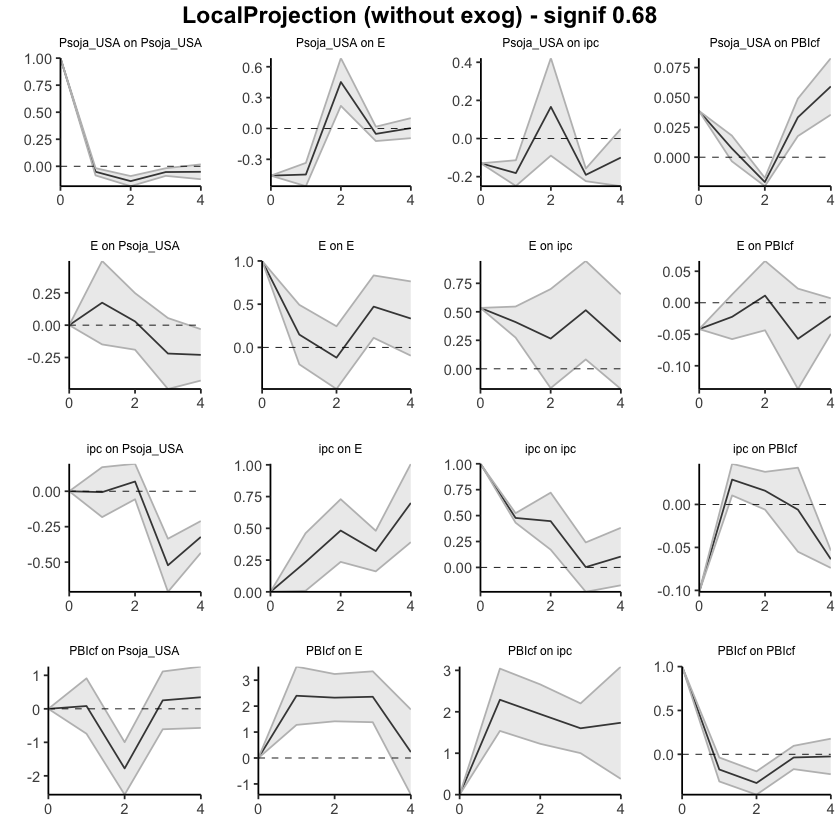

In [52]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.000000000,0.0000000
37,ipc,E,1,0.2348483,0.008329824,0.4613669
38,ipc,E,2,0.7174491,0.244093388,1.1908048
39,ipc,E,3,1.0384513,0.405244814,1.6716577
40,ipc,E,4,1.7382134,0.796460465,2.6799663


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000,0.000000
52,PBIcf,E,1,2.399922,1.276460,3.523384
53,PBIcf,E,2,4.725798,2.690945,6.760650
54,PBIcf,E,3,7.086308,4.070671,10.101945
55,PBIcf,E,4,7.314014,2.657375,11.970654


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.4587507,-0.4587507,-0.458750740
2,Psoja_USA,E,1,-0.9067733,-1.0200871,-0.793459500
3,Psoja_USA,E,2,-0.4549864,-0.8004487,-0.109524097
4,Psoja_USA,E,3,-0.5077811,-0.9231087,-0.092453501
5,Psoja_USA,E,4,-0.5046573,-1.0174878,0.008173232


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.03885853,0.03885853,0.03885853
12,Psoja_USA,PBIcf,1,0.04622970,0.03550012,0.05695928
13,Psoja_USA,PBIcf,2,0.02547196,0.01127129,0.03967264
14,Psoja_USA,PBIcf,3,0.05881483,0.02893446,0.08869520
15,Psoja_USA,PBIcf,4,0.11804815,0.06450484,0.17159146


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.17372525,-0.1489210,0.4963715
18,E,Psoja_USA,2,0.20259356,-0.3387969,0.7439841
19,E,Psoja_USA,3,-0.01673092,-0.8323010,0.7988391
20,E,Psoja_USA,4,-0.24636368,-1.2603842,0.7676568


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.00634986,-0.1824660,0.16976624
33,ipc,Psoja_USA,2,0.06225711,-0.2390998,0.36361399
34,ipc,Psoja_USA,3,-0.46001410,-0.9486691,0.02864086
35,ipc,Psoja_USA,4,-0.78218210,-1.3830718,-0.18129237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.0000000,0.00000000
47,PBIcf,Psoja_USA,1,0.08339193,-0.7428824,0.90966621
48,PBIcf,Psoja_USA,2,-1.69549370,-3.3046898,-0.08629763
49,PBIcf,Psoja_USA,3,-1.44303337,-3.9148609,1.02879413
50,PBIcf,Psoja_USA,4,-1.09756887,-4.4842952,2.28915747


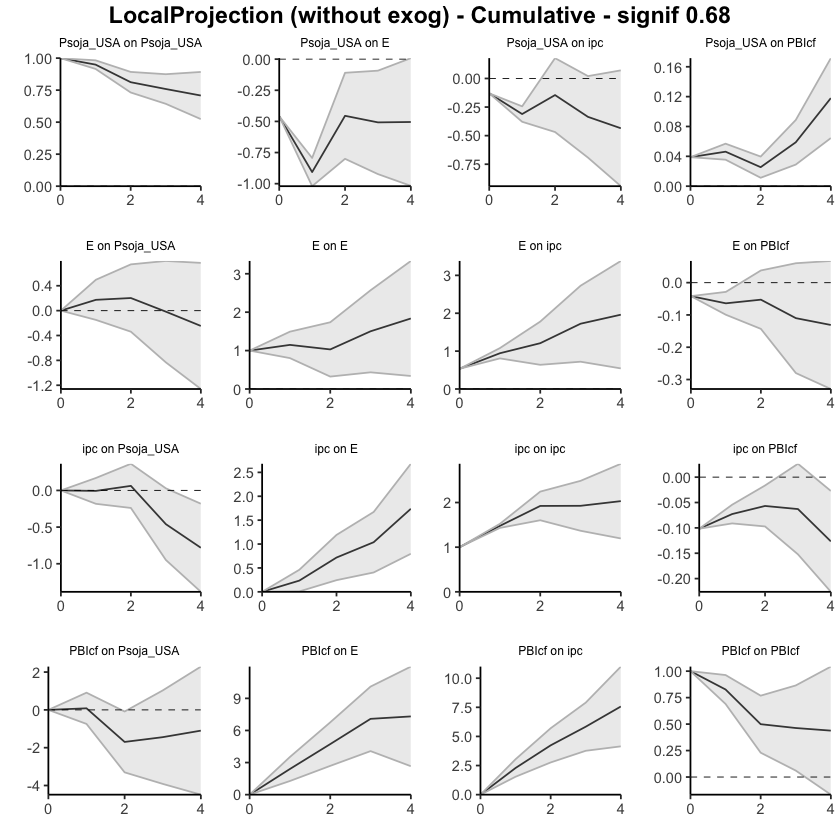

In [53]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.05649756,-0.09752063,0.2105158
38,ipc,E,2,0.51817174,0.10614509,0.9301984
39,ipc,E,3,0.30089255,0.15627818,0.4455069
40,ipc,E,4,0.69524535,0.38380793,1.0066828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.000000,0.000000
52,PBIcf,E,1,1.8064215,1.006791,2.606052
53,PBIcf,E,2,2.6027451,1.890880,3.314610
54,PBIcf,E,3,2.4127149,1.367707,3.457723
55,PBIcf,E,4,0.2711764,-1.403120,1.945473


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.25023573,-0.250235735,-0.250235735
2,Pmaíz_USA,E,1,-0.01301548,-0.115059892,0.089028922
3,Pmaíz_USA,E,2,0.24616906,0.183297187,0.309040942
4,Pmaíz_USA,E,3,-0.04837264,-0.090442702,-0.006302577
5,Pmaíz_USA,E,4,0.03650630,-0.002289145,0.075301739


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.015894472,0.015894472,1.589447e-02
12,Pmaíz_USA,PBIcf,1,0.016783005,0.009544994,2.402102e-02
13,Pmaíz_USA,PBIcf,2,-0.007472226,-0.014881526,-6.292589e-05
14,Pmaíz_USA,PBIcf,3,-0.007761036,-0.028842213,1.332014e-02
15,Pmaíz_USA,PBIcf,4,0.057956673,0.039509541,7.640380e-02


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,0.09224328,-0.1917387,0.37622530
18,E,Pmaíz_USA,2,0.13545323,-0.1654501,0.43635653
19,E,Pmaíz_USA,3,-0.12177360,-0.3197590,0.07621177
20,E,Pmaíz_USA,4,-0.15336788,-0.3301089,0.02337309


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.000000000,0.00000000
32,ipc,Pmaíz_USA,1,0.26630889,0.008525158,0.52409262
33,ipc,Pmaíz_USA,2,-0.01705096,-0.149219744,0.11511783
34,ipc,Pmaíz_USA,3,-0.15339281,-0.248071816,-0.05871381
35,ipc,Pmaíz_USA,4,-0.20033995,-0.296058312,-0.10462158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.000000e+00,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-6.757552e-05,-0.7795691,0.7794339
48,PBIcf,Pmaíz_USA,2,-6.564344e-01,-1.5255487,0.2126799
49,PBIcf,Pmaíz_USA,3,-8.673838e-03,-0.9306953,0.9133477
50,PBIcf,Pmaíz_USA,4,-1.144384e-01,-1.0858324,0.8569555


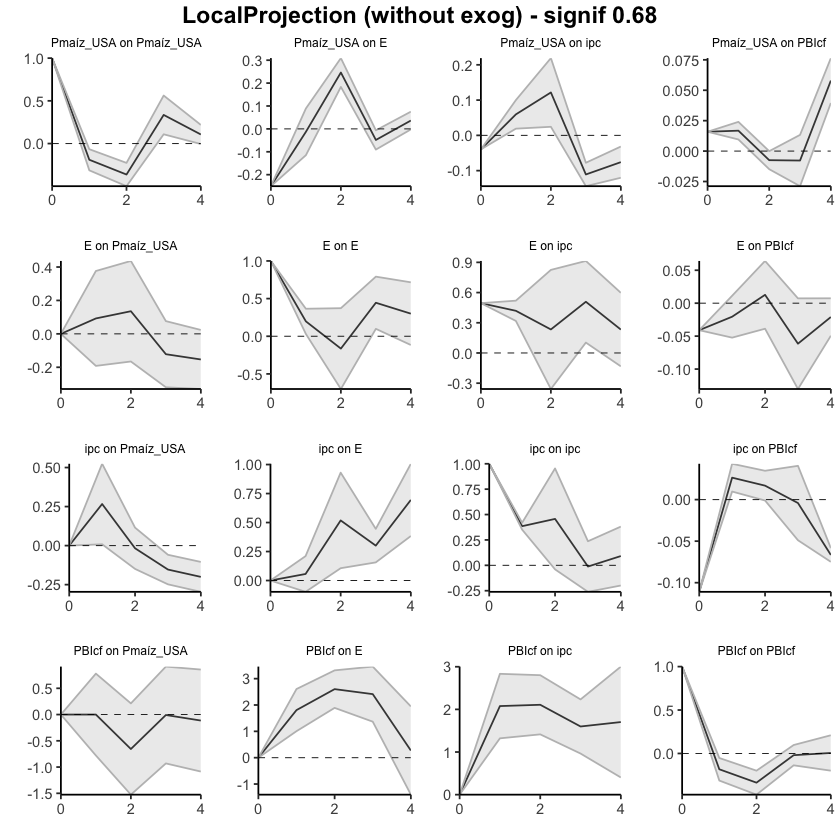

In [54]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.000000000,0.0000000
37,ipc,E,1,0.05649756,-0.097520634,0.2105158
38,ipc,E,2,0.57466930,0.008624459,1.1407141
39,ipc,E,3,0.87556184,0.164902635,1.5862211
40,ipc,E,4,1.57080719,0.548710566,2.5929038


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000,0.000000
52,PBIcf,E,1,1.806421,1.006791,2.606052
53,PBIcf,E,2,4.409167,2.897671,5.920662
54,PBIcf,E,3,6.821881,4.265378,9.378385
55,PBIcf,E,4,7.093058,2.862258,11.323858


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.25023573,-0.2502357,-0.2502357
2,Pmaíz_USA,E,1,-0.26325122,-0.3652956,-0.1612068
3,Pmaíz_USA,E,2,-0.01708216,-0.1819984,0.1478341
4,Pmaíz_USA,E,3,-0.06545479,-0.2724411,0.1415316
5,Pmaíz_USA,E,4,-0.02894850,-0.2747303,0.2168333


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.01589447,0.01589447,0.01589447
12,Pmaíz_USA,PBIcf,1,0.03267748,0.02543947,0.03991549
13,Pmaíz_USA,PBIcf,2,0.02520525,0.01055794,0.03985256
14,Pmaíz_USA,PBIcf,3,0.01744422,-0.01828427,0.05317270
15,Pmaíz_USA,PBIcf,4,0.07540089,0.02122527,0.12957651


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,0.09224328,-0.1917387,0.3762253
18,E,Pmaíz_USA,2,0.22769651,-0.3571888,0.8125818
19,E,Pmaíz_USA,3,0.10592290,-0.6769478,0.8887936
20,E,Pmaíz_USA,4,-0.04744498,-1.0070567,0.9121667


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.000000000,0.0000000
32,ipc,Pmaíz_USA,1,0.26630889,0.008525158,0.5240926
33,ipc,Pmaíz_USA,2,0.24925793,-0.140694586,0.6392105
34,ipc,Pmaíz_USA,3,0.09586512,-0.388766402,0.5804966
35,ipc,Pmaíz_USA,4,-0.10447482,-0.684824714,0.4758751


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.000000e+00,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-6.757552e-05,-0.7795691,0.7794339
48,PBIcf,Pmaíz_USA,2,-6.565020e-01,-2.3051178,0.9921138
49,PBIcf,Pmaíz_USA,3,-6.651759e-01,-3.2358131,1.9054614
50,PBIcf,Pmaíz_USA,4,-7.796143e-01,-4.3216455,2.7624170


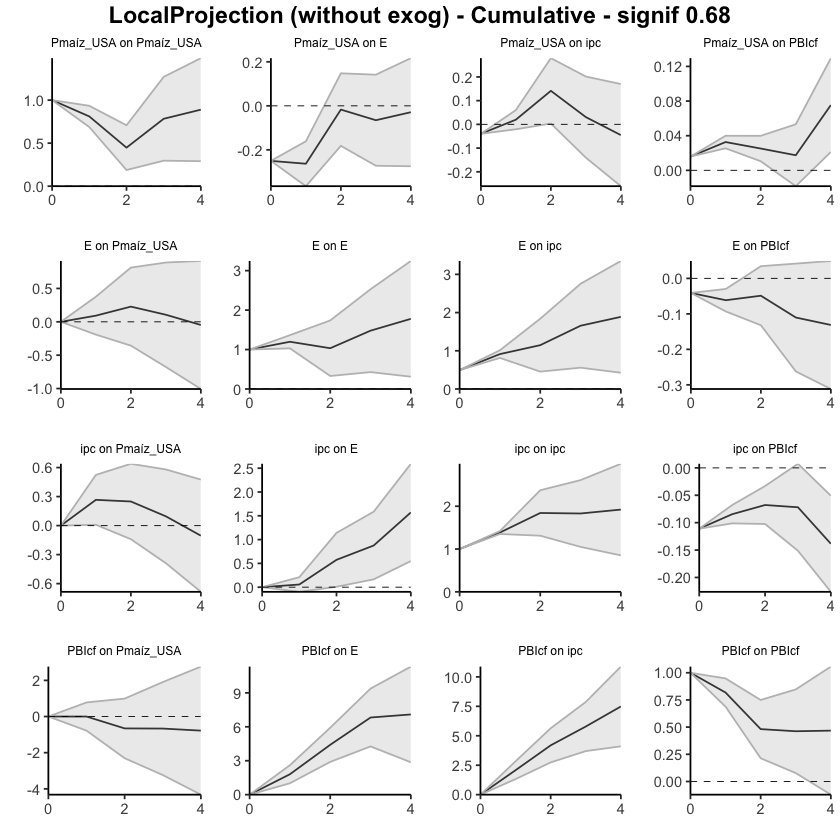

In [55]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,0.05564189,-0.1034748,0.2147586
38,ipc,E,2,0.42497364,0.1754517,0.6744956
39,ipc,E,3,0.32049417,0.1776821,0.4633062
40,ipc,E,4,0.70021616,0.3823803,1.0180520


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,1.7868460,0.9743588,2.599333
53,PBIcf,E,2,2.5514555,1.7434308,3.359480
54,PBIcf,E,3,2.4173684,1.3597466,3.474990
55,PBIcf,E,4,0.3099931,-1.3110603,1.931047


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.60513603,-0.60513603,-0.6051360284
2,Ptrigo_USA,E,1,-0.05286558,-0.10632042,0.0005892562
3,Ptrigo_USA,E,2,0.54606355,0.29766202,0.7944650819
4,Ptrigo_USA,E,3,-0.01512631,-0.06021707,0.0299644546
5,Ptrigo_USA,E,4,0.01176033,0.01442523,0.0090954350


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.01672267,0.016722666,0.01672267
12,Ptrigo_USA,PBIcf,1,0.01942384,0.012631325,0.02621636
13,Ptrigo_USA,PBIcf,2,-0.01750672,-0.009723455,-0.02528998
14,Ptrigo_USA,PBIcf,3,0.03425668,0.036758143,0.03175522
15,Ptrigo_USA,PBIcf,4,0.06274541,0.051700142,0.07379068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,0.23096527,-0.03093322,0.49286377
18,E,Ptrigo_USA,2,0.07363518,-0.25032552,0.39759589
19,E,Ptrigo_USA,3,-0.17010943,-0.31177585,-0.02844302
20,E,Ptrigo_USA,4,-0.21306655,-0.37866380,-0.04746930


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,0.03398551,-0.1011561,0.1691272
33,ipc,Ptrigo_USA,2,-0.01912288,-0.1436511,0.1054054
34,ipc,Ptrigo_USA,3,-0.22847678,-0.3488310,-0.1081226
35,ipc,Ptrigo_USA,4,-0.37412841,-0.4543560,-0.2939009


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.06003783,-0.6330949,0.7531705
48,PBIcf,Ptrigo_USA,2,0.31801262,-0.6963213,1.3323465
49,PBIcf,Ptrigo_USA,3,-0.42485826,-1.0144057,0.1646892
50,PBIcf,Ptrigo_USA,4,-0.77857208,-1.5403488,-0.0167954


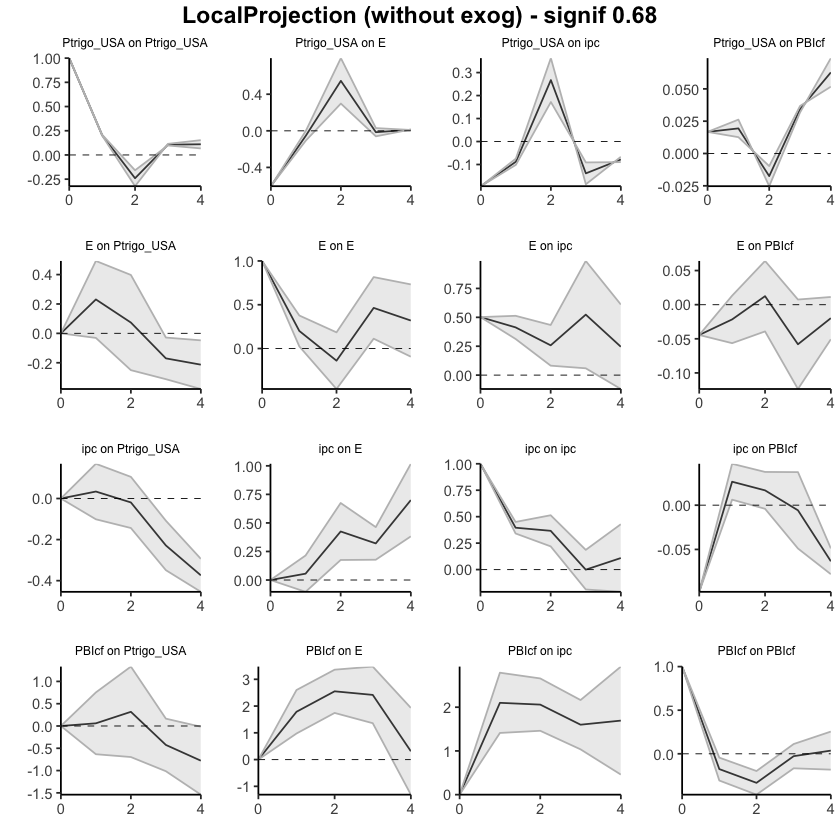

In [56]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.05564189,-0.10347479,0.2147586
38,ipc,E,2,0.48061553,0.07197691,0.8892542
39,ipc,E,3,0.80110970,0.24965902,1.3525604
40,ipc,E,4,1.50132586,0.63203933,2.3706124


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,1.786846,0.9743588,2.599333
53,PBIcf,E,2,4.338301,2.7177895,5.958813
54,PBIcf,E,3,6.755670,4.0775361,9.433804
55,PBIcf,E,4,7.065663,2.7664758,11.364850


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6051360,-0.6051360,-0.6051360
2,Ptrigo_USA,E,1,-0.6580016,-0.7114564,-0.6045468
3,Ptrigo_USA,E,2,-0.1119381,-0.4137944,0.1899183
4,Ptrigo_USA,E,3,-0.1270644,-0.4740115,0.2198828
5,Ptrigo_USA,E,4,-0.1153040,-0.4595863,0.2289782


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.01672267,0.01672267,0.01672267
12,Ptrigo_USA,PBIcf,1,0.03614651,0.02935399,0.04293902
13,Ptrigo_USA,PBIcf,2,0.01863979,0.01963054,0.01764904
14,Ptrigo_USA,PBIcf,3,0.05289647,0.05638868,0.04940425
15,Ptrigo_USA,PBIcf,4,0.11564188,0.10808882,0.12319493


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
17,E,Ptrigo_USA,1,0.23096527,-0.03093322,0.4928638
18,E,Ptrigo_USA,2,0.30460046,-0.28125874,0.8904597
19,E,Ptrigo_USA,3,0.13449102,-0.59303459,0.8620166
20,E,Ptrigo_USA,4,-0.07857553,-0.97169839,0.8145473


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,0.03398551,-0.1011561,0.1691272
33,ipc,Ptrigo_USA,2,0.01486264,-0.2448073,0.2745325
34,ipc,Ptrigo_USA,3,-0.21361414,-0.5936382,0.1664100
35,ipc,Ptrigo_USA,4,-0.58774255,-1.0479942,-0.1274909


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.06003783,-0.6330949,0.7531705
48,PBIcf,Ptrigo_USA,2,0.37805045,-1.3294162,2.0855171
49,PBIcf,Ptrigo_USA,3,-0.04680782,-2.3438219,2.2502063
50,PBIcf,Ptrigo_USA,4,-0.82537990,-3.8841707,2.2334109


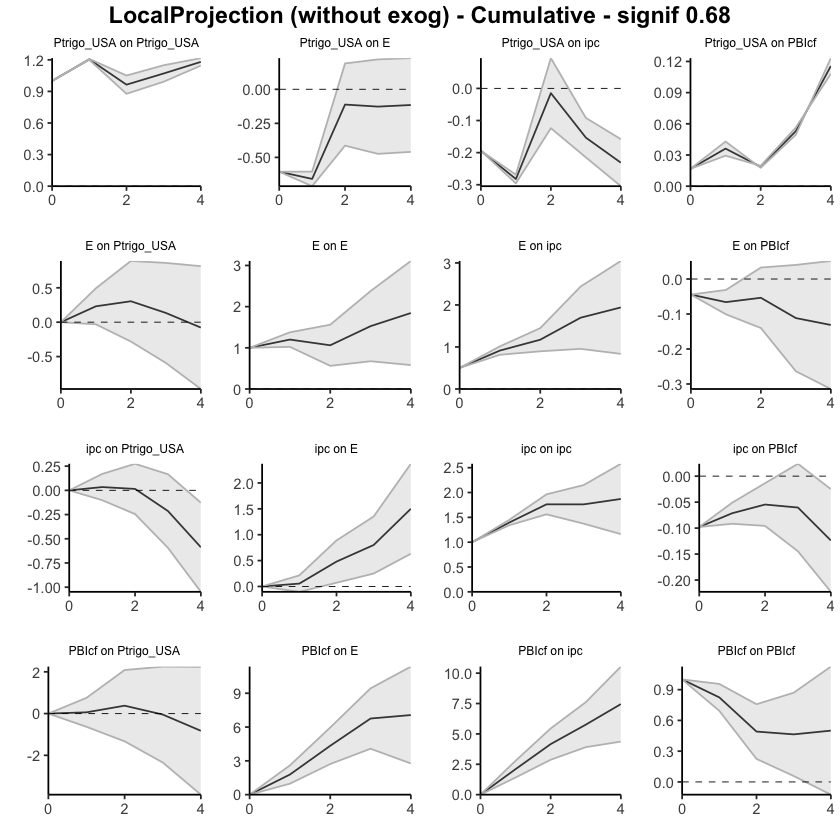

In [57]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.8239584,-0.87597935,-0.7719375
38,ipc,E,2,-1.1235973,-1.38862778,-0.8585668
39,ipc,E,3,-1.0417460,-2.75489487,0.6714029
40,ipc,E,4,0.1927791,0.08326487,0.3022933


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.347016,-0.02107392,2.715106
53,PBIcf,E,2,2.917320,2.09142427,3.743216
54,PBIcf,E,3,3.669785,-26.41066776,33.750238
55,PBIcf,E,4,2.310807,1.64230373,2.979311


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6516095,-0.6516095,-0.651609532
2,Ptrigo_USA,E,1,-0.1693450,-0.3308756,-0.007814297
3,Ptrigo_USA,E,2,0.8083360,0.3328988,1.283773200
4,Ptrigo_USA,E,3,1.3762022,-9.8199168,12.572321085
5,Ptrigo_USA,E,4,1.6825173,0.3893980,2.975636473


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.001577247,0.001577247,0.001577247
12,Ptrigo_USA,PBIcf,1,0.071707486,0.034256863,0.109158108
13,Ptrigo_USA,PBIcf,2,0.010003383,0.001630997,0.018375769
14,Ptrigo_USA,PBIcf,3,0.078794784,-0.015471709,0.173061276
15,Ptrigo_USA,PBIcf,4,-0.015084010,-0.032403365,0.002235344


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.2897751,0.1885034,0.3910468
18,E,Ptrigo_USA,2,-0.0576914,-0.3039983,0.1886155
19,E,Ptrigo_USA,3,-0.5196942,-1.9692980,0.9299096
20,E,Ptrigo_USA,4,-0.3137907,-0.4291728,-0.1984085


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.0965582,-0.07608864,-0.1170278
33,ipc,Ptrigo_USA,2,-0.2859287,-0.31701152,-0.2548458
34,ipc,Ptrigo_USA,3,-0.5596102,-0.85466443,-0.2645559
35,ipc,Ptrigo_USA,4,-0.4265770,-0.43670076,-0.4164533


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.00000000,0.00000000
47,PBIcf,Ptrigo_USA,1,0.6696305,-0.01591673,1.35517768
48,PBIcf,Ptrigo_USA,2,-0.5042570,-1.05136675,0.04285268
49,PBIcf,Ptrigo_USA,3,0.3610137,-6.16577663,6.88780402
50,PBIcf,Ptrigo_USA,4,0.6279261,0.31268247,0.94316983


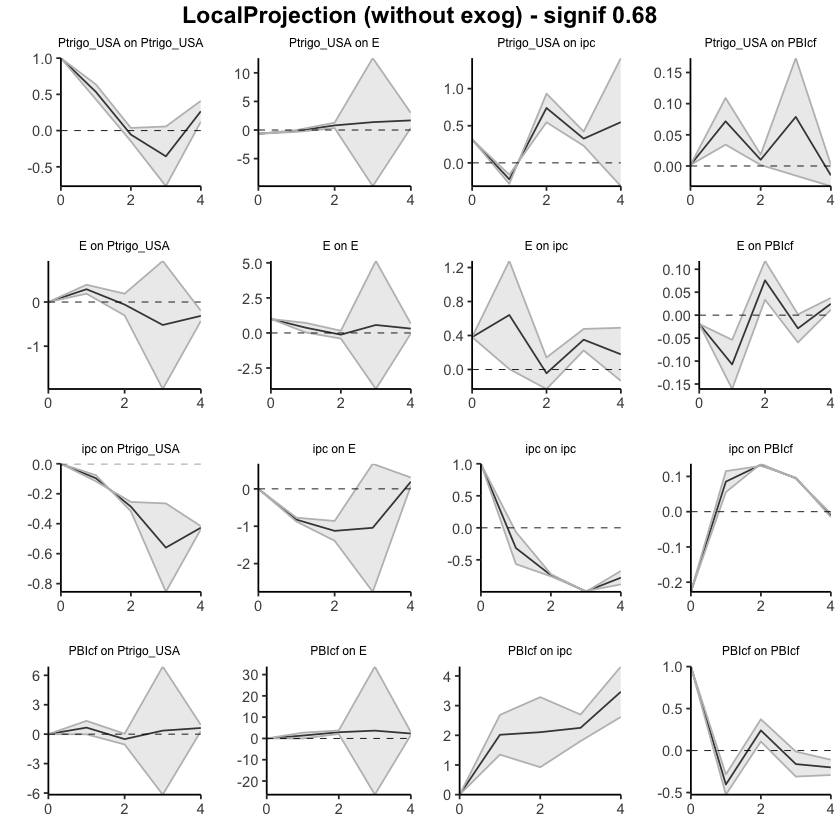

In [58]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
6,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.8239584,-0.8759794,-0.7719375
38,ipc,E,2,-1.9475557,-2.2646071,-1.6305043
39,ipc,E,3,-2.9893017,-5.0195020,-0.9591014
40,ipc,E,4,-2.7965226,-4.9362371,-0.6568080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.347016,-0.02107392,2.715106
53,PBIcf,E,2,4.264336,2.07035035,6.458322
54,PBIcf,E,3,7.934121,-24.34031741,40.208560
55,PBIcf,E,4,10.244929,-22.69801368,43.187871


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.6516095,-0.6516095,-0.6516095
2,Ptrigo_USA,E,1,-0.8209545,-0.9824852,-0.6594238
3,Ptrigo_USA,E,2,-0.0126185,-0.6495864,0.6243494
4,Ptrigo_USA,E,3,1.3635837,-10.4695031,13.1966705
5,Ptrigo_USA,E,4,3.0461009,-10.0801051,16.1723069


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.001577247,0.001577247,0.001577247
12,Ptrigo_USA,PBIcf,1,0.073284733,0.035834110,0.110735355
13,Ptrigo_USA,PBIcf,2,0.083288116,0.037465108,0.129111124
14,Ptrigo_USA,PBIcf,3,0.162082900,0.021993399,0.302172400
15,Ptrigo_USA,PBIcf,4,0.146998889,-0.010409966,0.304407744


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,0.2897751,0.1885034,0.3910468
18,E,Ptrigo_USA,2,0.2320837,-0.1154949,0.5796622
19,E,Ptrigo_USA,3,-0.2876105,-2.0847929,1.5095718
20,E,Ptrigo_USA,4,-0.6014012,-2.5139657,1.3111633


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,-0.0965582,-0.07608864,-0.1170278
33,ipc,Ptrigo_USA,2,-0.3824869,-0.39310016,-0.3718736
34,ipc,Ptrigo_USA,3,-0.9420971,-1.24776460,-0.6364295
35,ipc,Ptrigo_USA,4,-1.3686741,-1.68446535,-1.0528828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.00000000,0.000000
47,PBIcf,Ptrigo_USA,1,0.6696305,-0.01591673,1.355178
48,PBIcf,Ptrigo_USA,2,0.1653734,-1.06728348,1.398030
49,PBIcf,Ptrigo_USA,3,0.5263871,-7.23306011,8.285834
50,PBIcf,Ptrigo_USA,4,1.1543133,-6.92037765,9.229004


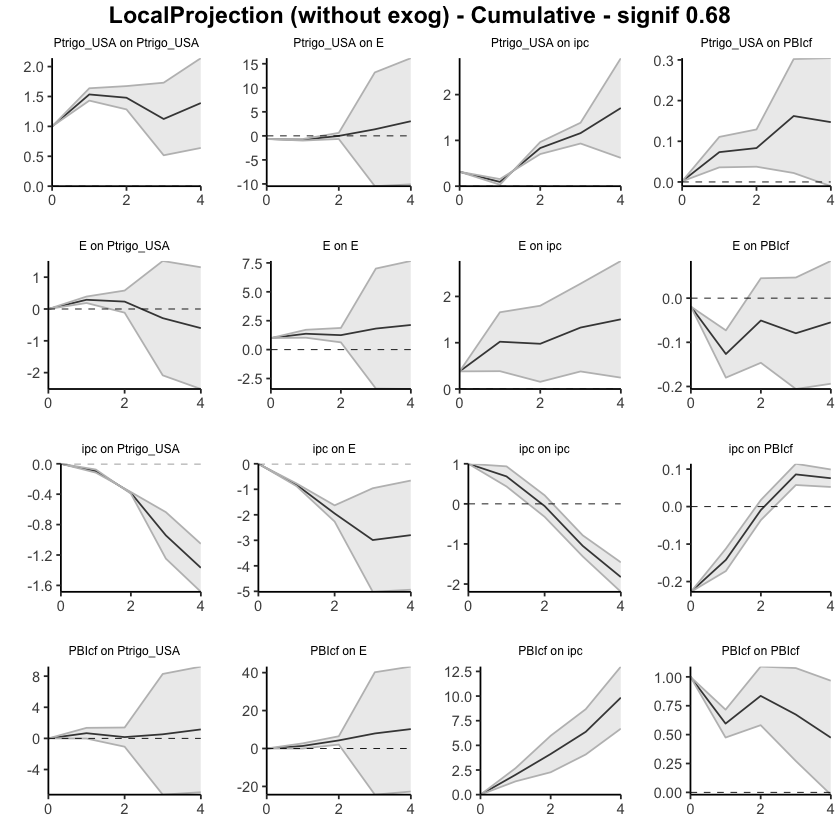

In [59]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 6, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1975. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.2597299,0.02156374,0.4978961
13,ipc,E,2,0.5067147,0.25042848,0.7630009
14,ipc,E,3,0.3454752,0.17545597,0.5154944
15,ipc,E,4,0.7021229,0.37656306,1.0276828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.000000,0.000000
22,PBIcf,E,1,2.3999223,1.276460,3.523384
23,PBIcf,E,2,2.3258753,1.414485,3.237266
24,PBIcf,E,3,2.3605102,1.379726,3.341295
25,PBIcf,E,4,0.2277066,-1.413296,1.868709


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5047575,0.50475755,0.5047575
2,E,ipc,1,0.3776359,0.24899974,0.5062721
3,E,ipc,2,0.2362540,-0.18444231,0.6569504
4,E,ipc,3,0.5011892,0.08096198,0.9214164
5,E,ipc,4,0.2215172,-0.17524392,0.6182784


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.290346,1.538430,3.042262
28,PBIcf,ipc,2,1.944084,1.227177,2.660990
29,PBIcf,ipc,3,1.601843,1.001875,2.201811
30,PBIcf,ipc,4,1.735368,0.379955,3.090781


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04680829,-0.04680829,-0.04680829
7,E,PBIcf,1,-0.02173412,-0.05553433,0.01206609
8,E,PBIcf,2,0.01348865,-0.03979523,0.06677252
9,E,PBIcf,3,-0.05675452,-0.13387159,0.02036256
10,E,PBIcf,4,-0.01908730,-0.04538183,0.00720723


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.091312101,-0.09131210,-0.09131210
17,ipc,PBIcf,1,0.027117268,0.00728706,0.04694748
18,ipc,PBIcf,2,0.012572505,-0.01077285,0.03591786
19,ipc,PBIcf,3,-0.006490487,-0.05676887,0.04378790
20,ipc,PBIcf,4,-0.064006066,-0.07624418,-0.05176795


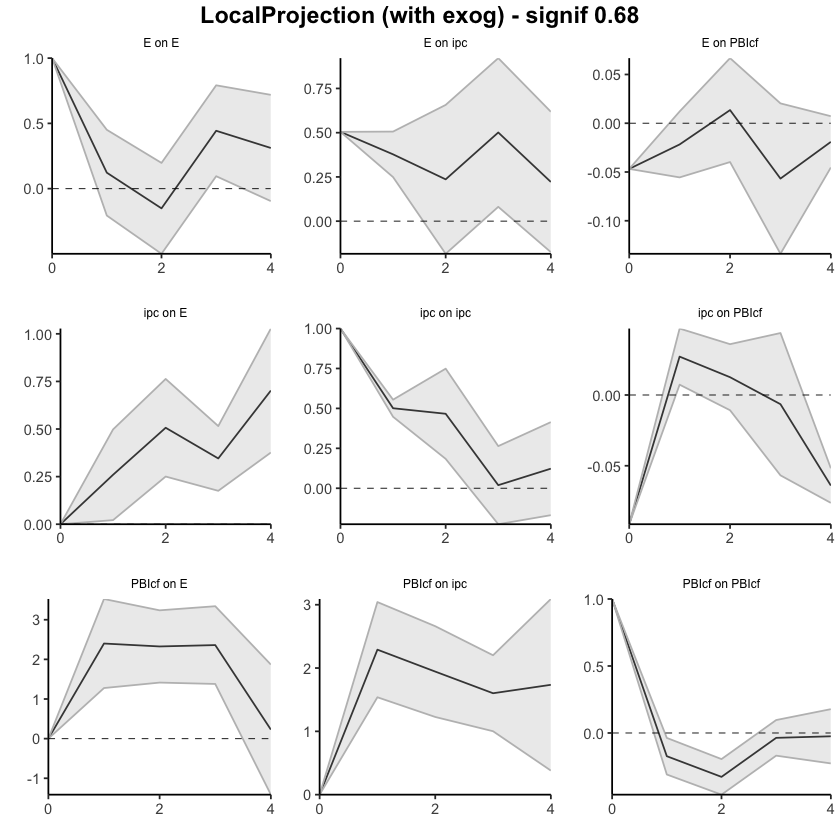

In [60]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.2597299,0.02156374,0.4978961
13,ipc,E,2,0.7664446,0.27199222,1.2608970
14,ipc,E,3,1.1119198,0.44744819,1.7763914
15,ipc,E,4,1.8140427,0.82401126,2.8040741


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.000000,0.000000
22,PBIcf,E,1,2.399922,1.276460,3.523384
23,PBIcf,E,2,4.725798,2.690945,6.760650
24,PBIcf,E,3,7.086308,4.070671,10.101945
25,PBIcf,E,4,7.314014,2.657375,11.970654


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5047575,0.5047575,0.5047575
2,E,ipc,1,0.8823935,0.7537573,1.0110297
3,E,ipc,2,1.1186475,0.5693150,1.6679801
4,E,ipc,3,1.6198367,0.6502770,2.5893964
5,E,ipc,4,1.8413539,0.4750330,3.2076748


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.290346,1.538430,3.042262
28,PBIcf,ipc,2,4.234429,2.765607,5.703252
29,PBIcf,ipc,3,5.836272,3.767482,7.905063
30,PBIcf,ipc,4,7.571640,4.147437,10.995844


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04680829,-0.04680829,-0.04680829
7,E,PBIcf,1,-0.06854241,-0.10234262,-0.03474220
8,E,PBIcf,2,-0.05505376,-0.14213785,0.03203033
9,E,PBIcf,3,-0.11180828,-0.27600944,0.05239289
10,E,PBIcf,4,-0.13089558,-0.32139127,0.05960012


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.09131210,-0.09131210,-0.091312101
17,ipc,PBIcf,1,-0.06419483,-0.08402504,-0.044364625
18,ipc,PBIcf,2,-0.05162233,-0.09479789,-0.008446765
19,ipc,PBIcf,3,-0.05811281,-0.15156676,0.035341133
20,ipc,PBIcf,4,-0.12211888,-0.22781095,-0.016426816


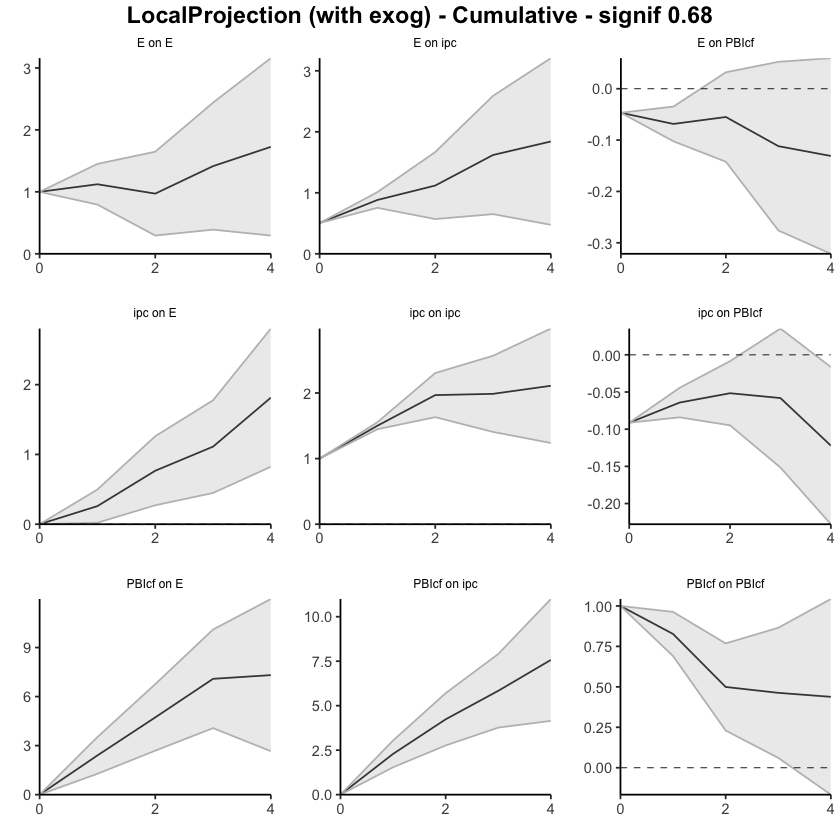

In [61]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.06717491,-0.09156972,0.2259195
13,ipc,E,2,0.53355597,0.11732166,0.9497903
14,ipc,E,3,0.31515356,0.16436238,0.4659447
15,ipc,E,4,0.69684821,0.37551440,1.0181820


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.000000,0.000000
22,PBIcf,E,1,1.8064215,1.006791,2.606052
23,PBIcf,E,2,2.6027451,1.890880,3.314610
24,PBIcf,E,3,2.4127149,1.367707,3.457723
25,PBIcf,E,4,0.2711764,-1.403120,1.945473


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4789575,0.4789575,0.4789575
2,E,ipc,1,0.4068410,0.3087692,0.5049129
3,E,ipc,2,0.2203703,-0.3612820,0.8020227
4,E,ipc,3,0.5042677,0.1045973,0.9039380
5,E,ipc,4,0.2258819,-0.1310042,0.5827681


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.077572,1.3209242,2.834220
28,PBIcf,ipc,2,2.108184,1.4143023,2.802066
29,PBIcf,ipc,3,1.598772,0.9640533,2.233491
30,PBIcf,ipc,4,1.703000,0.4025008,3.003500


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04203788,-0.04203788,-0.042037881
7,E,PBIcf,1,-0.02041843,-0.05156707,0.010730220
8,E,PBIcf,2,0.01335581,-0.03740965,0.064121268
9,E,PBIcf,3,-0.06134073,-0.12908959,0.006408137
10,E,PBIcf,4,-0.01994679,-0.04766577,0.007772181


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.105088636,-0.105088636,-0.10508864
17,ipc,PBIcf,1,0.025337985,0.007857103,0.04281887
18,ipc,PBIcf,2,0.014812663,-0.003905267,0.03353059
19,ipc,PBIcf,3,-0.004237076,-0.049704945,0.04123079
20,ipc,PBIcf,4,-0.066612407,-0.076098232,-0.05712658


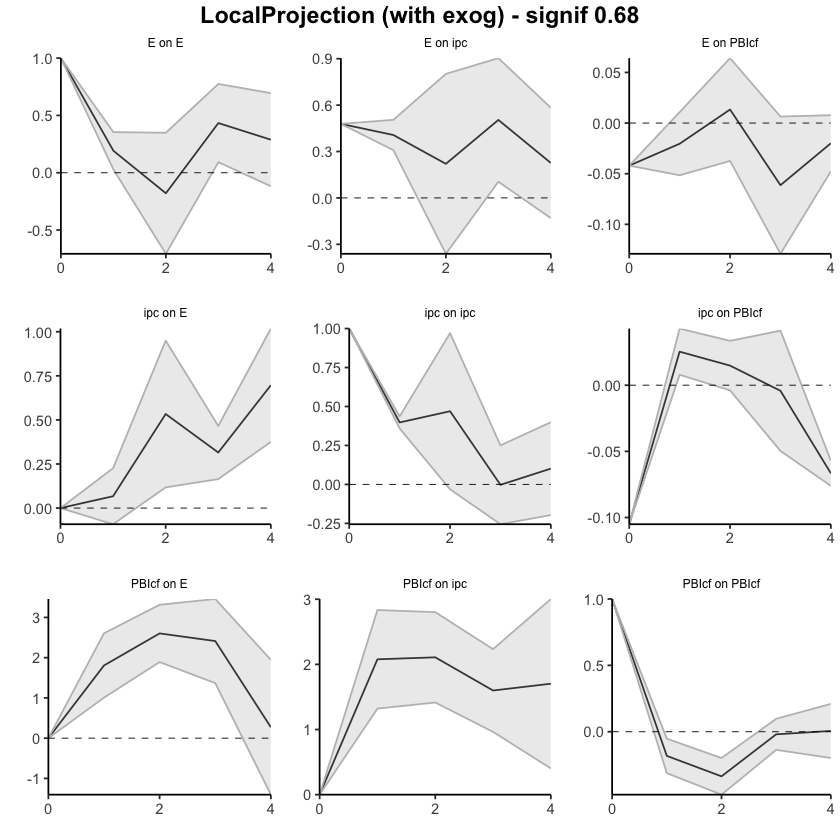

In [62]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.06717491,-0.09156972,0.2259195
13,ipc,E,2,0.60073089,0.02575194,1.1757098
14,ipc,E,3,0.91588444,0.19011432,1.6416546
15,ipc,E,4,1.61273265,0.56562872,2.6598366


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.000000,0.000000
22,PBIcf,E,1,1.806421,1.006791,2.606052
23,PBIcf,E,2,4.409167,2.897671,5.920662
24,PBIcf,E,3,6.821881,4.265378,9.378385
25,PBIcf,E,4,7.093058,2.862258,11.323858


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4789575,0.4789575,0.4789575
2,E,ipc,1,0.8857985,0.7877266,0.9838704
3,E,ipc,2,1.1061688,0.4264446,1.7858930
4,E,ipc,3,1.6104365,0.5310419,2.6898311
5,E,ipc,4,1.8363185,0.4000378,3.2725992


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.077572,1.320924,2.834220
28,PBIcf,ipc,2,4.185756,2.735227,5.636286
29,PBIcf,ipc,3,5.784528,3.699280,7.869777
30,PBIcf,ipc,4,7.487529,4.101781,10.873277


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04203788,-0.04203788,-0.04203788
7,E,PBIcf,1,-0.06245631,-0.09360496,-0.03130766
8,E,PBIcf,2,-0.04910050,-0.13101460,0.03281361
9,E,PBIcf,3,-0.11044123,-0.26010420,0.03922174
10,E,PBIcf,4,-0.13038802,-0.30776997,0.04699393


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.10508864,-0.10508864,-0.10508864
17,ipc,PBIcf,1,-0.07975065,-0.09723153,-0.06226977
18,ipc,PBIcf,2,-0.06493799,-0.10113680,-0.02873918
19,ipc,PBIcf,3,-0.06917506,-0.15084174,0.01249162
20,ipc,PBIcf,4,-0.13578747,-0.22693998,-0.04463497


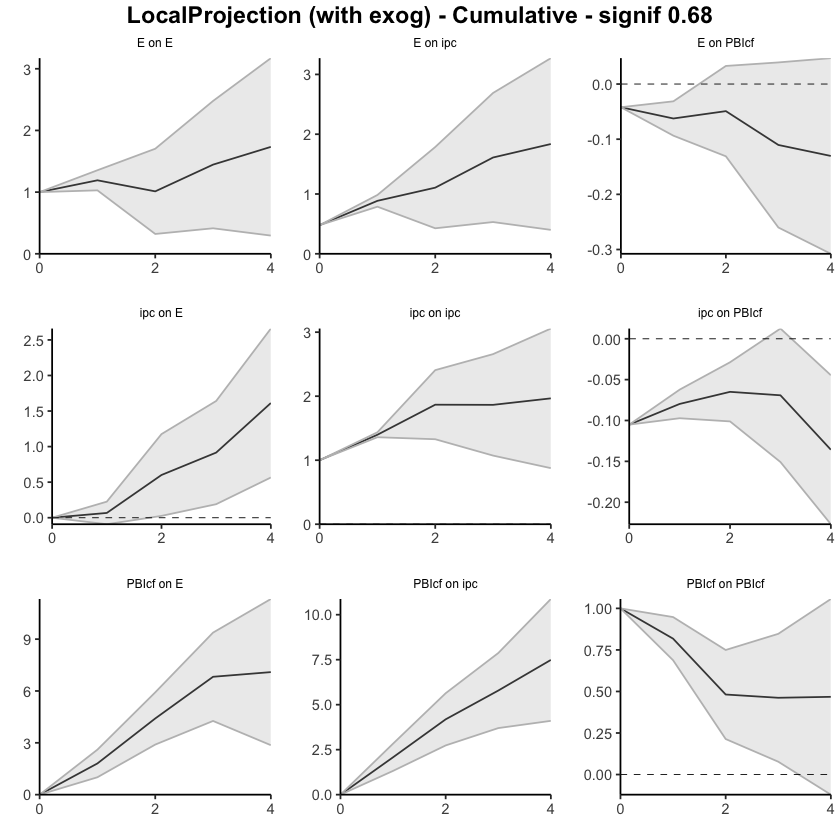

In [63]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.05586488,-0.1033532,0.2150830
13,ipc,E,2,0.42529205,0.1756693,0.6749148
14,ipc,E,3,0.32079585,0.1778518,0.4637399
15,ipc,E,4,0.70025484,0.3822167,1.0182930


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,1.7868460,0.9743588,2.599333
23,PBIcf,E,2,2.5514555,1.7434308,3.359480
24,PBIcf,E,3,2.4173684,1.3597466,3.474990
25,PBIcf,E,4,0.3099931,-1.3110603,1.931047


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4773656,0.47736557,0.4773656
2,E,ipc,1,0.4031298,0.30445223,0.5018073
3,E,ipc,2,0.2485012,0.07628098,0.4207215
4,E,ipc,3,0.5232471,0.06353571,0.9829584
5,E,ipc,4,0.2423034,-0.11498023,0.5995870


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.100010,1.4111329,2.788888
28,PBIcf,ipc,2,2.059221,1.4607441,2.657698
29,PBIcf,ipc,3,1.599755,1.0359042,2.163606
30,PBIcf,ipc,4,1.693603,0.4588066,2.928400


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04212960,-0.04212960,-0.042129598
7,E,PBIcf,1,-0.02224091,-0.05653339,0.012051563
8,E,PBIcf,2,0.01207586,-0.03902098,0.063172711
9,E,PBIcf,3,-0.05788722,-0.12235487,0.006580432
10,E,PBIcf,4,-0.01816505,-0.04879771,0.012467610


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.097763971,-0.097763971,-0.09776397
17,ipc,PBIcf,1,0.026484987,0.006188555,0.04678142
18,ipc,PBIcf,2,0.016703660,-0.004128434,0.03753575
19,ipc,PBIcf,3,-0.005790078,-0.048953310,0.03737315
20,ipc,PBIcf,4,-0.063392567,-0.078019879,-0.04876526


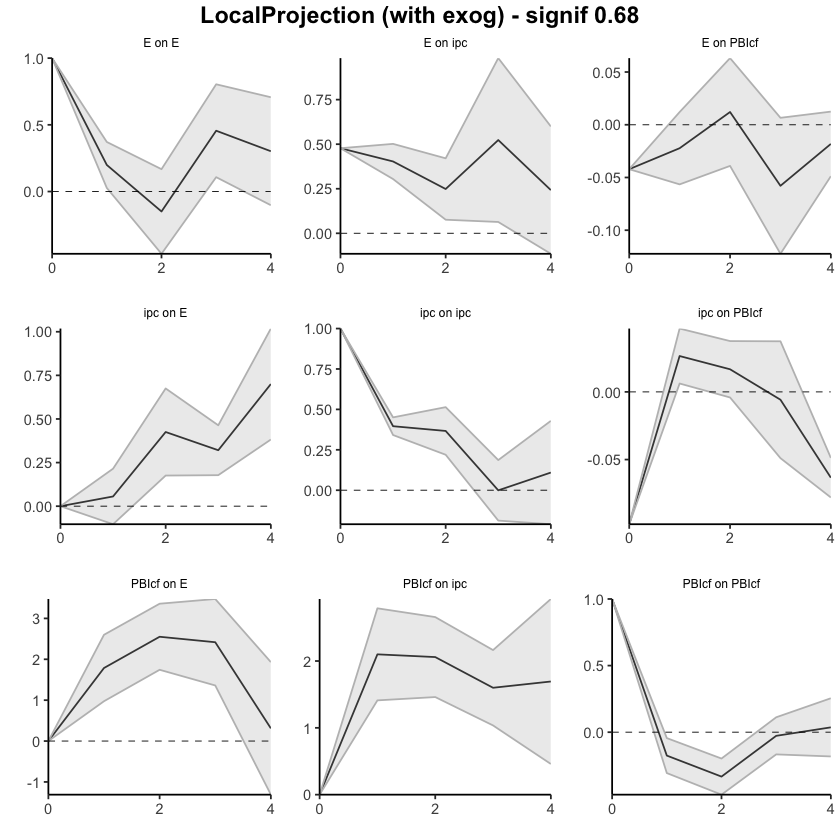

In [64]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.05586488,-0.10335320,0.2150830
13,ipc,E,2,0.48115693,0.07231607,0.8899978
14,ipc,E,3,0.80195278,0.25016788,1.3537377
15,ipc,E,4,1.50220762,0.63238457,2.3720307


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.786846,0.9743588,2.599333
23,PBIcf,E,2,4.338301,2.7177895,5.958813
24,PBIcf,E,3,6.755670,4.0775361,9.433804
25,PBIcf,E,4,7.065663,2.7664758,11.364850


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4773656,0.4773656,0.4773656
2,E,ipc,1,0.8804953,0.7818178,0.9791728
3,E,ipc,2,1.1289966,0.8580988,1.3998943
4,E,ipc,3,1.6522436,0.9216345,2.3828528
5,E,ipc,4,1.8945470,0.8066543,2.9824398


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.100010,1.411133,2.788888
28,PBIcf,ipc,2,4.159232,2.871877,5.446586
29,PBIcf,ipc,3,5.758987,3.907781,7.610193
30,PBIcf,ipc,4,7.452590,4.366588,10.538593


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04212960,-0.04212960,-0.04212960
7,E,PBIcf,1,-0.06437051,-0.09866299,-0.03007803
8,E,PBIcf,2,-0.05229465,-0.13768397,0.03309468
9,E,PBIcf,3,-0.11018187,-0.26003884,0.03967511
10,E,PBIcf,4,-0.12834691,-0.30883655,0.05214272


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.09776397,-0.09776397,-0.09776397
17,ipc,PBIcf,1,-0.07127898,-0.09157542,-0.05098255
18,ipc,PBIcf,2,-0.05457532,-0.09570385,-0.01344680
19,ipc,PBIcf,3,-0.06036540,-0.14465716,0.02392636
20,ipc,PBIcf,4,-0.12375797,-0.22267704,-0.02483890


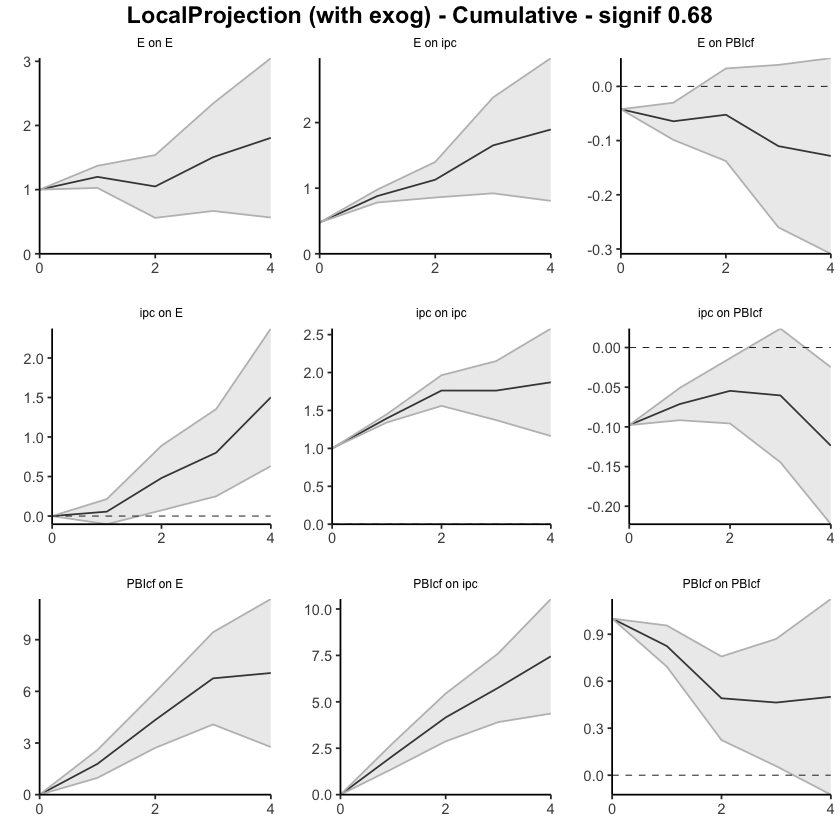

In [65]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1982. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2273912,0.1478307,0.3069516
38,ipc,E,2,0.9756325,0.5497594,1.4015057
39,ipc,E,3,0.8493647,0.6042199,1.0945095
40,ipc,E,4,0.9219692,0.4169451,1.4269933


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,1.0441303,-0.3186297,2.406890
53,PBIcf,E,2,3.1865329,2.2932579,4.079808
54,PBIcf,E,3,1.0787516,-0.1824699,2.339973
55,PBIcf,E,4,-0.5836098,-1.8242406,0.657021


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.67004881,-0.67004881,-0.67004881
2,Psoja_USA,E,1,-0.77700151,-0.99370723,-0.56029579
3,Psoja_USA,E,2,0.33741889,0.35926749,0.31557029
4,Psoja_USA,E,3,0.48212753,0.07115079,0.89310428
5,Psoja_USA,E,4,0.06293645,0.17131142,-0.04543852


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.052499806,0.052499806,0.05249981
12,Psoja_USA,PBIcf,1,0.007528324,-0.006283438,0.02134009
13,Psoja_USA,PBIcf,2,-0.014649407,-0.011504654,-0.01779416
14,Psoja_USA,PBIcf,3,0.021428022,0.019024695,0.02383135
15,Psoja_USA,PBIcf,4,0.040282496,0.034042620,0.04652237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.00000000,0.00000000
17,E,Psoja_USA,1,0.05007249,-0.10914530,0.20929028
18,E,Psoja_USA,2,0.05423019,-0.05535015,0.16381052
19,E,Psoja_USA,3,-0.04438434,-0.18085691,0.09208823
20,E,Psoja_USA,4,-0.04816969,-0.14140037,0.04506099


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.04470430,-0.1363446,0.04693602
33,ipc,Psoja_USA,2,-0.03939808,-0.1033099,0.02451373
34,ipc,Psoja_USA,3,-0.18847756,-0.2678319,-0.10912319
35,ipc,Psoja_USA,4,-0.14366251,-0.1845622,-0.10276286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,0.1074890,-0.4747654,0.6897434
48,PBIcf,Psoja_USA,2,-1.3047129,-1.9332900,-0.6761358
49,PBIcf,Psoja_USA,3,0.5405287,-0.2327728,1.3138301
50,PBIcf,Psoja_USA,4,0.7678843,-0.0430085,1.5787771


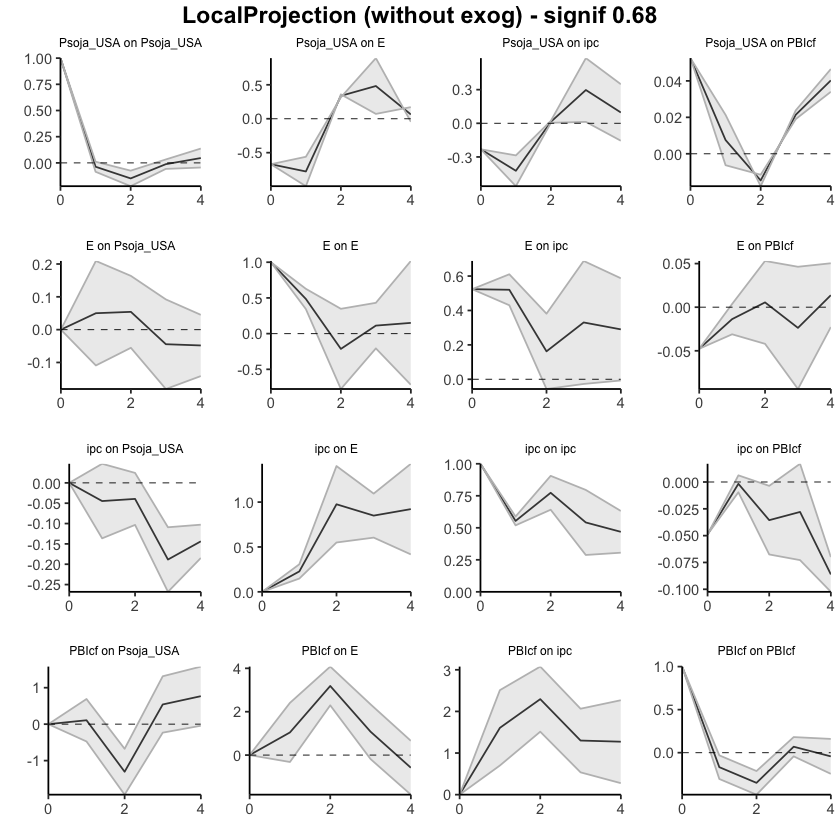

In [66]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2273912,0.1478307,0.3069516
38,ipc,E,2,1.2030237,0.6975901,1.7084573
39,ipc,E,3,2.0523884,1.3018100,2.8029668
40,ipc,E,4,2.9743576,1.7187550,4.2299601


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.00000000,0.000000
52,PBIcf,E,1,1.044130,-0.31862974,2.406890
53,PBIcf,E,2,4.230663,1.97462817,6.486698
54,PBIcf,E,3,5.309415,1.79215828,8.826671
55,PBIcf,E,4,4.725805,-0.03208233,9.483692


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6700488,-0.6700488,-0.67004881
2,Psoja_USA,E,1,-1.4470503,-1.6637560,-1.23034459
3,Psoja_USA,E,2,-1.1096314,-1.3044885,-0.91477430
4,Psoja_USA,E,3,-0.6275039,-1.2333378,-0.02167002
5,Psoja_USA,E,4,-0.5645674,-1.0620263,-0.06710853


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.05249981,0.05249981,0.05249981
12,Psoja_USA,PBIcf,1,0.06002813,0.04621637,0.07383989
13,Psoja_USA,PBIcf,2,0.04537872,0.03471171,0.05604573
14,Psoja_USA,PBIcf,3,0.06680675,0.05373641,0.07987708
15,Psoja_USA,PBIcf,4,0.10708924,0.08777903,0.12639946


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.00000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.05007249,-0.1091453,0.2092903
18,E,Psoja_USA,2,0.10430268,-0.1644954,0.3731008
19,E,Psoja_USA,3,0.05991834,-0.3453523,0.4651890
20,E,Psoja_USA,4,0.01174865,-0.4867527,0.5102500


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.04470430,-0.1363446,0.04693602
33,ipc,Psoja_USA,2,-0.08410239,-0.2396545,0.07144975
34,ipc,Psoja_USA,3,-0.27257995,-0.5074865,-0.03767343
35,ipc,Psoja_USA,4,-0.41624246,-0.6920486,-0.14043630


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.00000000
47,PBIcf,Psoja_USA,1,0.1074890,-0.4747654,0.68974339
48,PBIcf,Psoja_USA,2,-1.1972239,-2.4080554,0.01360764
49,PBIcf,Psoja_USA,3,-0.6566952,-2.6408283,1.32743778
50,PBIcf,Psoja_USA,4,0.1111891,-2.6838368,2.90621487


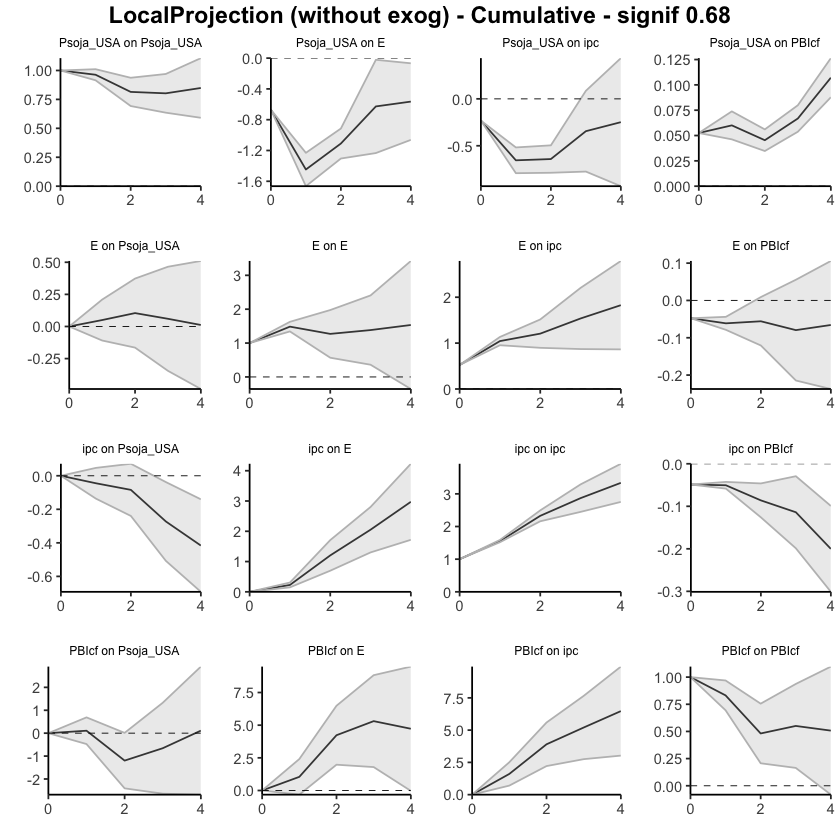

In [67]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1127101,0.04656735,0.1788528
38,ipc,E,2,0.8885448,0.48932766,1.2877619
39,ipc,E,3,0.8904979,0.59602588,1.1849698
40,ipc,E,4,0.9392569,0.56201135,1.3165024


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.5913648,-0.9628118,2.1455414
53,PBIcf,E,2,3.0844778,2.0968069,4.0721486
54,PBIcf,E,3,1.4600053,0.4318352,2.4881754
55,PBIcf,E,4,-0.5033950,-1.8374798,0.8306899


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.28274498,-0.2827450,-0.28274498
2,Pmaíz_USA,E,1,-0.03980026,-0.2442842,0.16468365
3,Pmaíz_USA,E,2,0.57465764,0.2828634,0.86645191
4,Pmaíz_USA,E,3,0.42065716,0.2319375,0.60937684
5,Pmaíz_USA,E,4,0.07900481,0.1131586,0.04485106


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.01498649,0.014986492,0.014986492
12,Pmaíz_USA,PBIcf,1,0.01561711,0.004448392,0.026785828
13,Pmaíz_USA,PBIcf,2,-0.02160996,-0.032034795,-0.011185126
14,Pmaíz_USA,PBIcf,3,-0.01599091,-0.028963679,-0.003018149
15,Pmaíz_USA,PBIcf,4,0.04173233,0.030523841,0.052940817


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.000000000,0.00000000,0.000000000
17,E,Pmaíz_USA,1,-0.118507056,-0.23102153,-0.005992586
18,E,Pmaíz_USA,2,0.008873812,-0.12468747,0.142435095
19,E,Pmaíz_USA,3,0.033098841,-0.11968131,0.185878988
20,E,Pmaíz_USA,4,0.018729715,-0.07699136,0.114450794


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.000000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.152245143,0.08104008,0.22345021
33,ipc,Pmaíz_USA,2,-0.003639702,-0.06563499,0.05835559
34,ipc,Pmaíz_USA,3,-0.098798981,-0.22013878,0.02254082
35,ipc,Pmaíz_USA,4,-0.156059430,-0.21292017,-0.09919869


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
47,PBIcf,Pmaíz_USA,1,-0.32053447,-0.9476483,0.30657936
48,PBIcf,Pmaíz_USA,2,-0.64909697,-1.2094867,-0.08870719
49,PBIcf,Pmaíz_USA,3,0.09482933,-0.6055288,0.79518747
50,PBIcf,Pmaíz_USA,4,0.60487370,-0.2710951,1.48084256


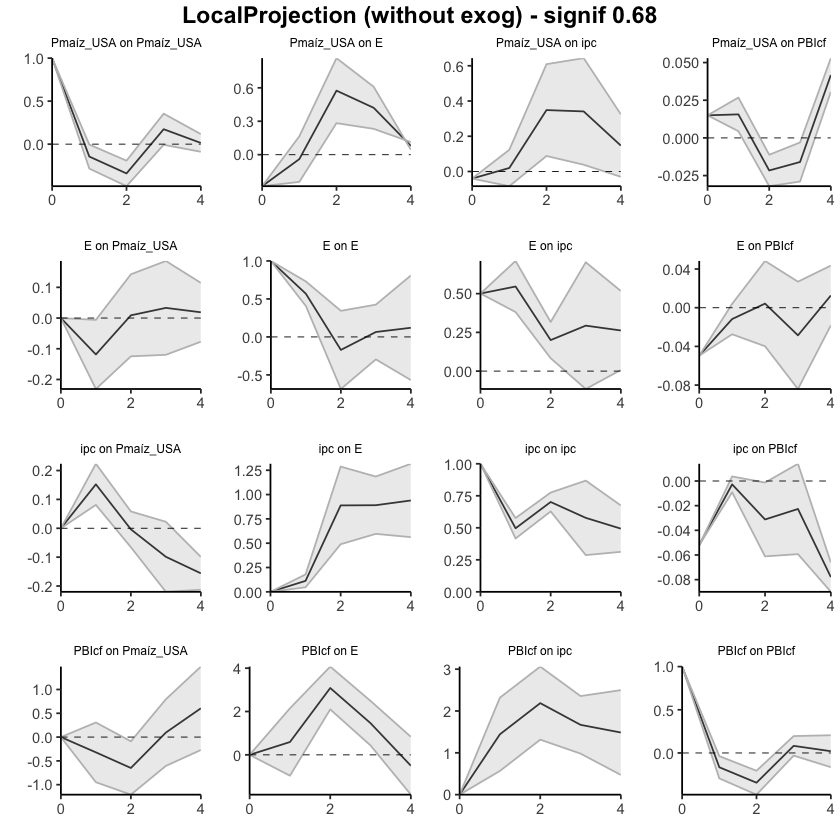

In [68]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1127101,0.04656735,0.1788528
38,ipc,E,2,1.0012549,0.53589501,1.4666147
39,ipc,E,3,1.8917527,1.13192089,2.6515845
40,ipc,E,4,2.8310096,1.69393224,3.9680869


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.5913648,-0.9628118,2.145541
53,PBIcf,E,2,3.6758425,1.1339952,6.217690
54,PBIcf,E,3,5.1358478,1.5658303,8.705865
55,PBIcf,E,4,4.6324528,-0.2716495,9.536555


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.2827450,-0.28274498,-0.2827450
2,Pmaíz_USA,E,1,-0.3225452,-0.52702915,-0.1180613
3,Pmaíz_USA,E,2,0.2521124,-0.24416578,0.7483906
4,Pmaíz_USA,E,3,0.6727696,-0.01222829,1.3577674
5,Pmaíz_USA,E,4,0.7517744,0.10093028,1.4026185


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.014986492,0.01498649,0.01498649
12,Pmaíz_USA,PBIcf,1,0.030603602,0.01943488,0.04177232
13,Pmaíz_USA,PBIcf,2,0.008993642,-0.01259991,0.03058719
14,Pmaíz_USA,PBIcf,3,-0.006997272,-0.04156359,0.02756904
15,Pmaíz_USA,PBIcf,4,0.034735056,-0.01103975,0.08050986


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.000000000
17,E,Pmaíz_USA,1,-0.11850706,-0.2310215,-0.005992586
18,E,Pmaíz_USA,2,-0.10963324,-0.3557090,0.136442509
19,E,Pmaíz_USA,3,-0.07653440,-0.4753903,0.322321497
20,E,Pmaíz_USA,4,-0.05780469,-0.5523817,0.436772291


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.15224514,0.08104008,0.2234502
33,ipc,Pmaíz_USA,2,0.14860544,0.01540508,0.2818058
34,ipc,Pmaíz_USA,3,0.04980646,-0.20473370,0.3043466
35,ipc,Pmaíz_USA,4,-0.10625297,-0.41765387,0.2051479


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.3205345,-0.9476483,0.3065794
48,PBIcf,Pmaíz_USA,2,-0.9696314,-2.1571350,0.2178722
49,PBIcf,Pmaíz_USA,3,-0.8748021,-2.7626638,1.0130596
50,PBIcf,Pmaíz_USA,4,-0.2699284,-3.0337590,2.4939022


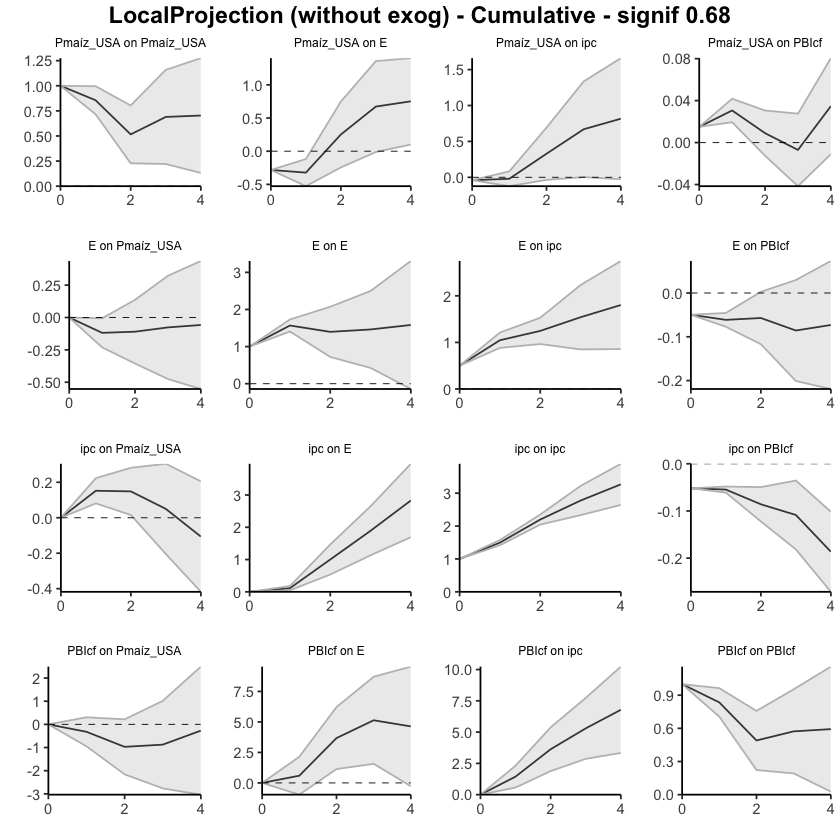

In [69]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.3252028,-0.71744441,0.06703886
38,ipc,E,2,0.3444428,0.15038819,0.53849742
39,ipc,E,3,0.8972236,0.37914292,1.41530436
40,ipc,E,4,0.3097044,0.06793044,0.55147829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.5569749,-0.7102384,1.8241882
53,PBIcf,E,2,2.3906450,1.1378532,3.6434368
54,PBIcf,E,3,1.2236183,0.3753187,2.0719179
55,PBIcf,E,4,-1.5600674,-3.5703474,0.4502126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.01534435,0.01534435,0.01534435
2,Pmaíz_USA,E,1,0.12748646,-0.16376902,0.41874193
3,Pmaíz_USA,E,2,0.57652266,0.17446737,0.97857795
4,Pmaíz_USA,E,3,0.44966366,0.10388992,0.79543741
5,Pmaíz_USA,E,4,0.13685953,-0.09913136,0.37285042


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,-0.004209764,-0.004209764,-0.004209764
12,Pmaíz_USA,PBIcf,1,0.016471629,-0.003614531,0.036557789
13,Pmaíz_USA,PBIcf,2,-0.023259184,-0.049121016,0.002602647
14,Pmaíz_USA,PBIcf,3,-0.013353722,-0.048376412,0.021668968
15,Pmaíz_USA,PBIcf,4,0.041259015,0.013605267,0.068912764


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.11961414,-0.2951008,0.05587253
18,E,Pmaíz_USA,2,-0.01600514,-0.2129898,0.18097950
19,E,Pmaíz_USA,3,0.01518986,-0.1524139,0.18279363
20,E,Pmaíz_USA,4,0.05407821,-0.1445992,0.25275558


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Pmaíz_USA,1,0.38130471,0.2396738,0.52293567
33,ipc,Pmaíz_USA,2,-0.08564371,-0.2513279,0.08004047
34,ipc,Pmaíz_USA,3,-0.15054951,-0.3133569,0.01225791
35,ipc,Pmaíz_USA,4,-0.18020772,-0.3369569,-0.02345859


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,0.12280253,-0.3974061,0.6430112
48,PBIcf,Pmaíz_USA,2,-1.22774389,-2.0708539,-0.3846338
49,PBIcf,Pmaíz_USA,3,0.07228513,-0.5928213,0.7373915
50,PBIcf,Pmaíz_USA,4,1.05938831,0.1204604,1.9983162


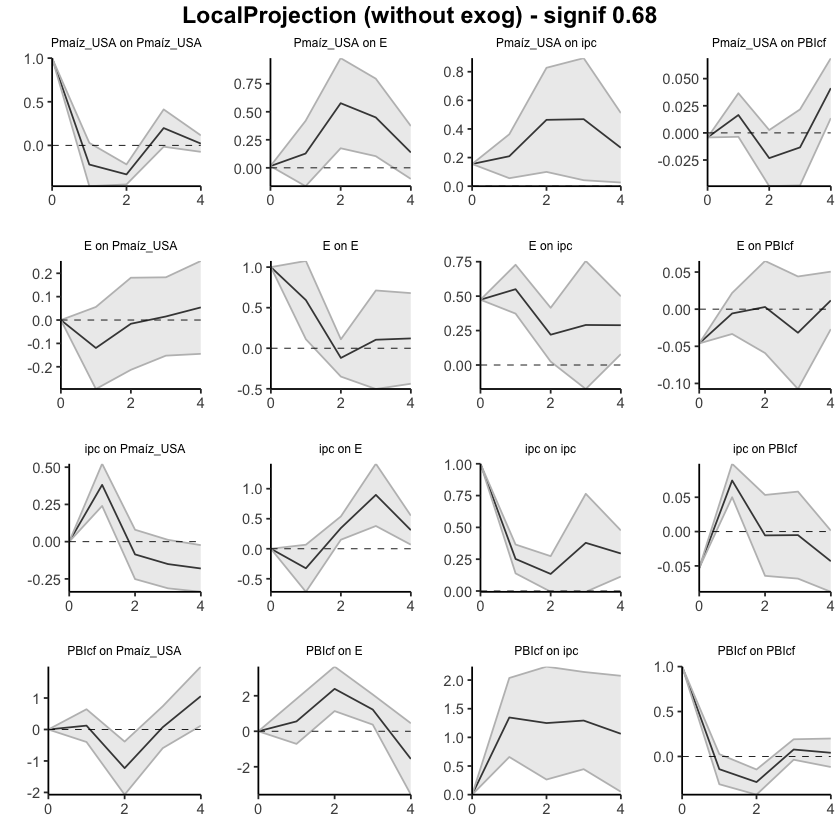

In [71]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.32520277,-0.7174444,0.06703886
38,ipc,E,2,0.01924003,-0.5670562,0.60553629
39,ipc,E,3,0.91646368,-0.1879133,2.02084065
40,ipc,E,4,1.22616804,-0.1199829,2.57231894


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.5569749,-0.7102384,1.824188
53,PBIcf,E,2,2.9476199,0.4276148,5.467625
54,PBIcf,E,3,4.1712382,0.8029336,7.539543
55,PBIcf,E,4,2.6111708,-2.7674139,7.989756


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.01534435,0.01534435,0.01534435
2,Pmaíz_USA,E,1,0.14283081,-0.14842467,0.43408628
3,Pmaíz_USA,E,2,0.71935347,0.02604270,1.41266423
4,Pmaíz_USA,E,3,1.16901713,0.12993262,2.20810163
5,Pmaíz_USA,E,4,1.30587666,0.03080126,2.58095205


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,-0.004209764,-0.004209764,-0.004209764
12,Pmaíz_USA,PBIcf,1,0.012261865,-0.007824295,0.032348025
13,Pmaíz_USA,PBIcf,2,-0.010997319,-0.056945311,0.034950673
14,Pmaíz_USA,PBIcf,3,-0.024351042,-0.105321723,0.056619640
15,Pmaíz_USA,PBIcf,4,0.016907974,-0.091716457,0.125532404


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.11961414,-0.2951008,0.05587253
18,E,Pmaíz_USA,2,-0.13561929,-0.5080906,0.23685203
19,E,Pmaíz_USA,3,-0.12042943,-0.6605045,0.41964565
20,E,Pmaíz_USA,4,-0.06635121,-0.8051037,0.67240123


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.38130471,0.23967376,0.5229357
33,ipc,Pmaíz_USA,2,0.29566101,-0.01165412,0.6029761
34,ipc,Pmaíz_USA,3,0.14511150,-0.32501104,0.6152340
35,ipc,Pmaíz_USA,4,-0.03509623,-0.66196790,0.5917754


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,0.12280253,-0.3974061,0.6430112
48,PBIcf,Pmaíz_USA,2,-1.10494136,-2.4682600,0.2583773
49,PBIcf,Pmaíz_USA,3,-1.03265623,-3.0610813,0.9957689
50,PBIcf,Pmaíz_USA,4,0.02673208,-2.9406209,2.9940850


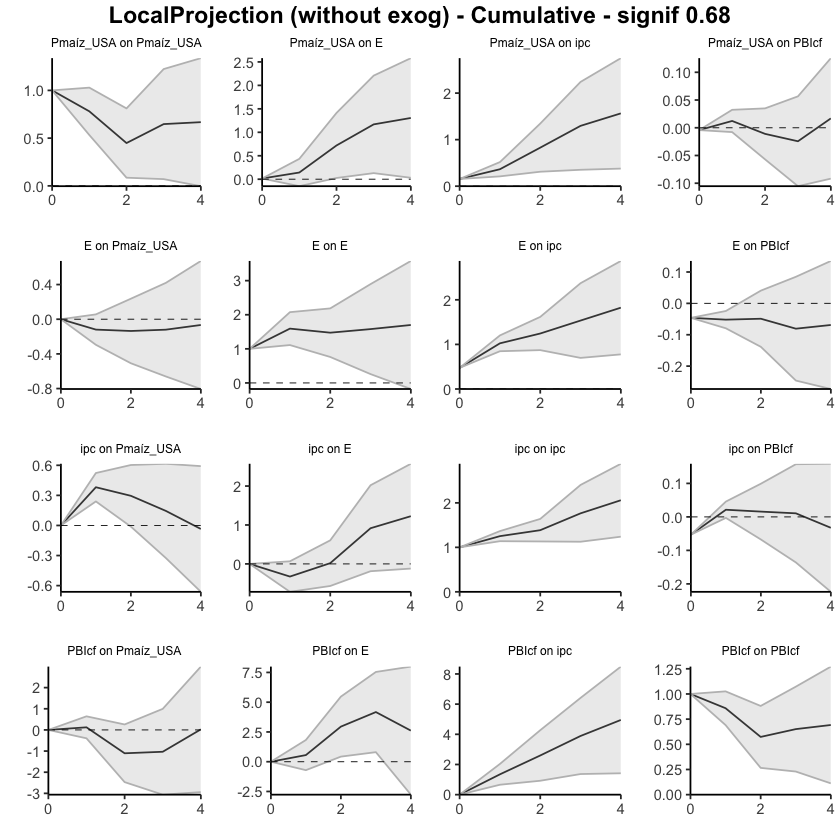

In [70]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1238678,0.03045609,0.2172795
38,ipc,E,2,0.8309593,0.49399345,1.1679252
39,ipc,E,3,0.7048948,0.45789113,0.9518985
40,ipc,E,4,0.8649049,0.37186197,1.3579478


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.6207971,-0.9621767,2.2037710
53,PBIcf,E,2,3.4440456,2.2726467,4.6154446
54,PBIcf,E,3,1.9419061,1.1987730,2.6850392
55,PBIcf,E,4,-0.3042288,-1.5727511,0.9642935


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.5666631,-0.5666631,-0.5666631
2,Ptrigo_USA,E,1,-0.2511478,-0.3644592,-0.1378364
3,Ptrigo_USA,E,2,0.8662848,0.6208097,1.1117599
4,Ptrigo_USA,E,3,1.0607441,0.7393626,1.3821256
5,Ptrigo_USA,E,4,0.4236616,0.5681052,0.2792179


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.0002681548,0.0002681548,0.0002681548
12,Ptrigo_USA,PBIcf,1,0.0276192031,0.0131345603,0.0421038458
13,Ptrigo_USA,PBIcf,2,-0.0389268379,-0.0480406286,-0.0298130473
14,Ptrigo_USA,PBIcf,3,-0.0139747650,-0.0093783985,-0.0185711316
15,Ptrigo_USA,PBIcf,4,0.0180952153,0.0193577017,0.0168327289


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
17,E,Ptrigo_USA,1,-0.04678340,-0.22545527,0.1318885
18,E,Ptrigo_USA,2,-0.03155029,-0.26343287,0.2003323
19,E,Ptrigo_USA,3,0.04928825,-0.06413350,0.1627100
20,E,Ptrigo_USA,4,0.02275110,-0.09296746,0.1384697


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.000000000
32,ipc,Ptrigo_USA,1,0.05672995,-0.02953474,0.142994647
33,ipc,Ptrigo_USA,2,0.05705788,-0.09759393,0.211709685
34,ipc,Ptrigo_USA,3,-0.08504207,-0.16311947,-0.006964659
35,ipc,Ptrigo_USA,4,-0.19536874,-0.24989678,-0.140840693


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.17200527,-0.6552932,0.3112826
48,PBIcf,Ptrigo_USA,2,0.15300414,-0.4083524,0.7143607
49,PBIcf,Ptrigo_USA,3,-0.01637006,-0.5601787,0.5274386
50,PBIcf,Ptrigo_USA,4,-0.00481464,-0.8658790,0.8562497


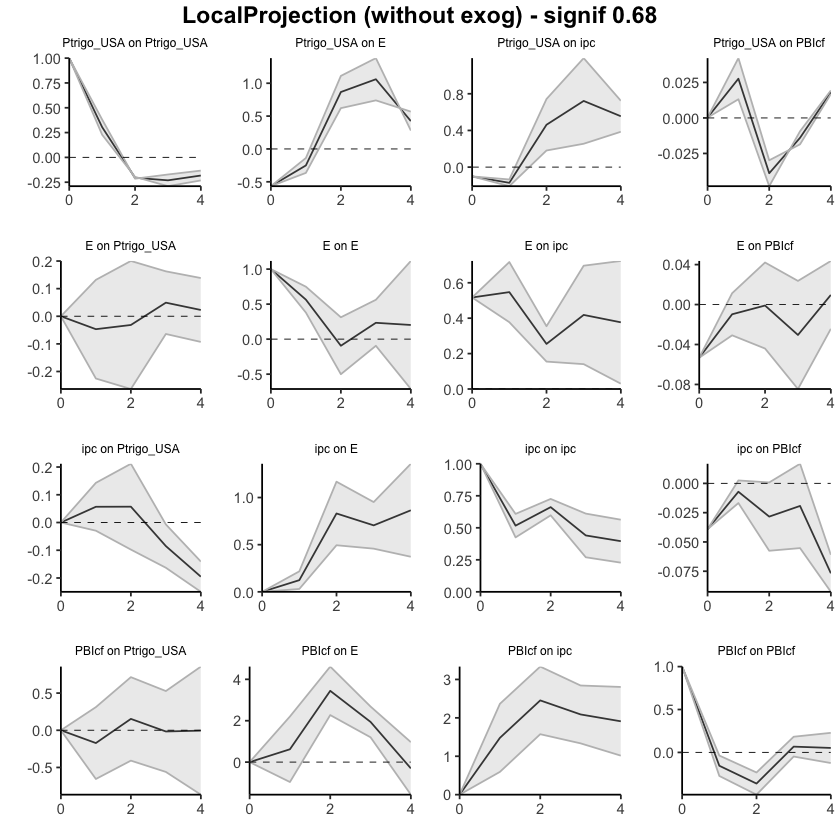

In [72]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1238678,0.03045609,0.2172795
38,ipc,E,2,0.9548271,0.52444954,1.3852047
39,ipc,E,3,1.6597219,0.98234066,2.3371031
40,ipc,E,4,2.5246268,1.35420263,3.6950509


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.6207971,-0.9621767,2.203771
53,PBIcf,E,2,4.0648427,1.3104699,6.819216
54,PBIcf,E,3,6.0067488,2.5092429,9.504255
55,PBIcf,E,4,5.7025200,0.9364918,10.468548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.56666310,-0.5666631,-0.5666631
2,Ptrigo_USA,E,1,-0.81781089,-0.9311223,-0.7044995
3,Ptrigo_USA,E,2,0.04847391,-0.3103126,0.4072604
4,Ptrigo_USA,E,3,1.10921803,0.4290500,1.7893860
5,Ptrigo_USA,E,4,1.53287958,0.9971553,2.0686039


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,0.0002681548,0.0002681548,0.0002681548
12,Ptrigo_USA,PBIcf,1,0.0278873579,0.0134027152,0.0423720007
13,Ptrigo_USA,PBIcf,2,-0.0110394800,-0.0346379134,0.0125589533
14,Ptrigo_USA,PBIcf,3,-0.0250142451,-0.0440163119,-0.0060121782
15,Ptrigo_USA,PBIcf,4,-0.0069190298,-0.0246586102,0.0108205506


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.04678340,-0.2254553,0.1318885
18,E,Ptrigo_USA,2,-0.07833369,-0.4888881,0.3322208
19,E,Ptrigo_USA,3,-0.02904544,-0.5530216,0.4949308
20,E,Ptrigo_USA,4,-0.00629434,-0.6459891,0.6334004


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Ptrigo_USA,1,0.05672995,-0.02953474,0.1429946
33,ipc,Ptrigo_USA,2,0.11378783,-0.12712867,0.3547043
34,ipc,Ptrigo_USA,3,0.02874576,-0.29024815,0.3477397
35,ipc,Ptrigo_USA,4,-0.16662297,-0.54014493,0.2068990


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.17200527,-0.6552932,0.3112826
48,PBIcf,Ptrigo_USA,2,-0.01900113,-1.0636456,1.0256433
49,PBIcf,Ptrigo_USA,3,-0.03537119,-1.6238243,1.5530819
50,PBIcf,Ptrigo_USA,4,-0.04018583,-2.4897033,2.4093316


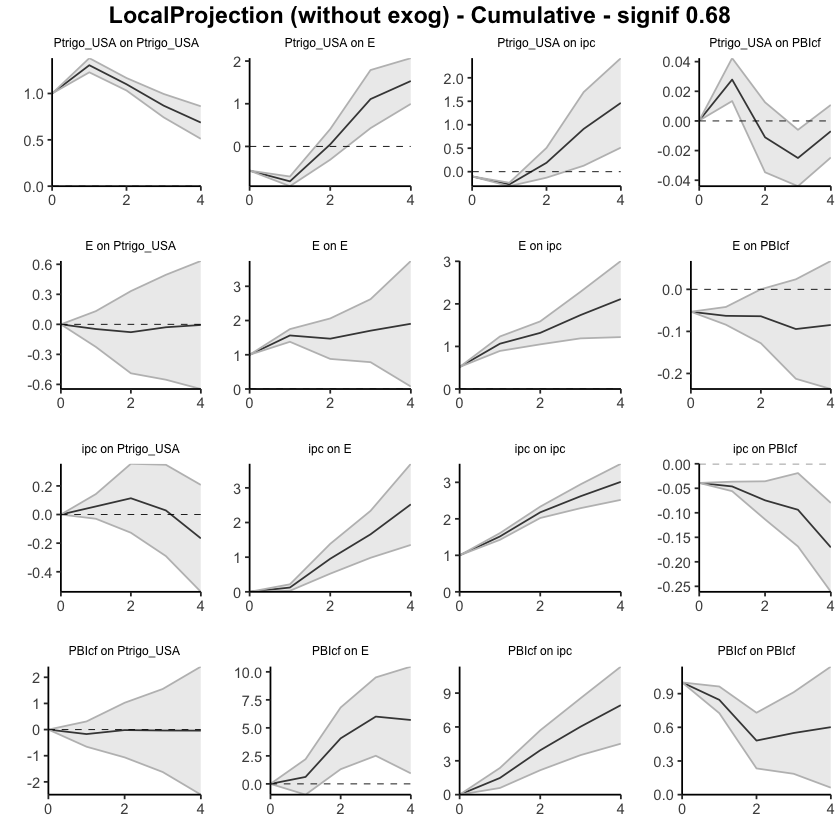

In [73]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.1603221,-0.5906386,0.2699943
38,ipc,E,2,0.3058749,0.1117285,0.5000213
39,ipc,E,3,0.5052147,0.1663300,0.8440995
40,ipc,E,4,0.1845613,-0.3333799,0.7025025


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.0000000
52,PBIcf,E,1,0.3927689,-1.0334408,1.8189785
53,PBIcf,E,2,2.3930060,1.2193628,3.5666492
54,PBIcf,E,3,1.4098916,0.4447643,2.3750189
55,PBIcf,E,4,-1.3524470,-2.8213734,0.1164794


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.3453892,-0.3453892,-0.3453892
2,Ptrigo_USA,E,1,-0.4524161,-0.6142582,-0.2905739
3,Ptrigo_USA,E,2,0.6238248,0.4146125,0.8330370
4,Ptrigo_USA,E,3,1.1018555,0.6558195,1.5478916
5,Ptrigo_USA,E,4,0.4127831,0.3858834,0.4396828


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.007211197,-0.007211197,-0.007211197
12,Ptrigo_USA,PBIcf,1,0.041622934,0.019586804,0.063659065
13,Ptrigo_USA,PBIcf,2,-0.041516370,-0.069051607,-0.013981133
14,Ptrigo_USA,PBIcf,3,-0.021596570,-0.038739875,-0.004453265
15,Ptrigo_USA,PBIcf,4,0.030044785,0.016690478,0.043399091


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.05467047,-0.21166895,0.10232801
18,E,Ptrigo_USA,2,-0.06913031,-0.23403815,0.09577754
19,E,Ptrigo_USA,3,0.04014475,-0.09885101,0.17914050
20,E,Ptrigo_USA,4,0.03381647,-0.11344412,0.18107705


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.00000000,0.0000000000
32,ipc,Ptrigo_USA,1,-0.1038286,-0.22065773,0.0130004917
33,ipc,Ptrigo_USA,2,0.0815976,-0.02161913,0.1848143338
34,ipc,Ptrigo_USA,3,0.1688960,0.02865653,0.3091353855
35,ipc,Ptrigo_USA,4,-0.1266355,-0.25262496,-0.0006460356


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.02263032,-0.4733932,0.5186539
48,PBIcf,Ptrigo_USA,2,0.13857840,-0.5702620,0.8474188
49,PBIcf,Ptrigo_USA,3,0.40125539,-0.3850647,1.1875755
50,PBIcf,Ptrigo_USA,4,0.21936296,-0.6942343,1.1329602


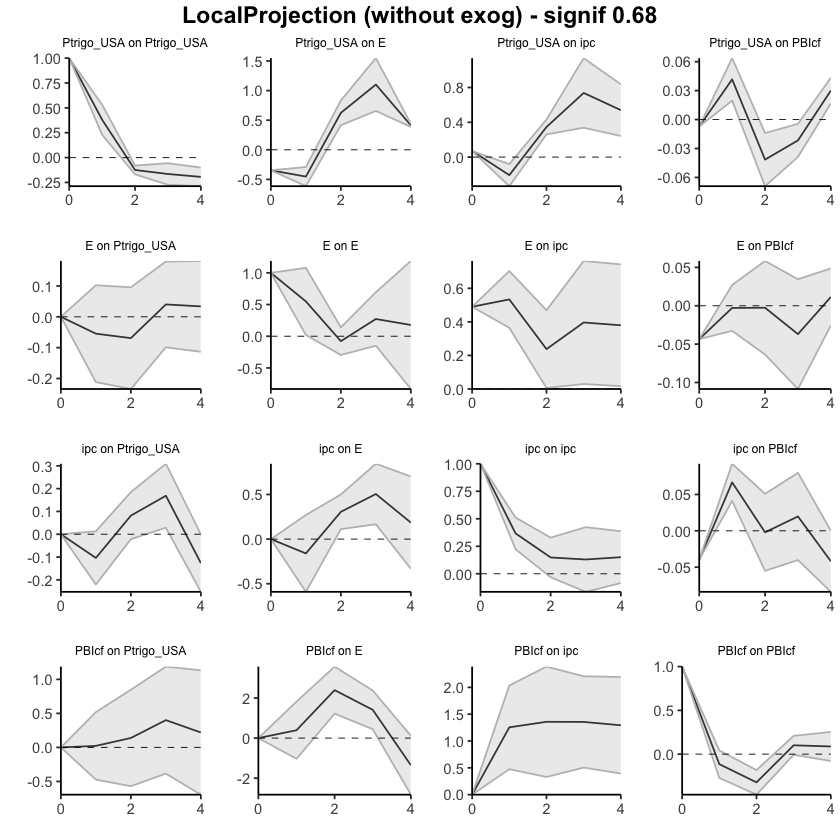

In [74]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.1603221,-0.5906386,0.2699943
38,ipc,E,2,0.1455528,-0.4789100,0.7700156
39,ipc,E,3,0.6507675,-0.3125801,1.6141151
40,ipc,E,4,0.8353288,-0.6459600,2.3166176


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,0.3927689,-1.0334408,1.818979
53,PBIcf,E,2,2.7857749,0.1859220,5.385628
54,PBIcf,E,3,4.1956664,0.6306863,7.760647
55,PBIcf,E,4,2.8432194,-2.1906871,7.877126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.3453892,-0.3453892,-0.3453892
2,Ptrigo_USA,E,1,-0.7978053,-0.9596475,-0.6359632
3,Ptrigo_USA,E,2,-0.1739806,-0.5450349,0.1970738
4,Ptrigo_USA,E,3,0.9278750,0.1107846,1.7449653
5,Ptrigo_USA,E,4,1.3406581,0.4966681,2.1846482


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.007211197,-0.007211197,-0.007211197
12,Ptrigo_USA,PBIcf,1,0.034411737,0.012375607,0.056447867
13,Ptrigo_USA,PBIcf,2,-0.007104633,-0.056676000,0.042466735
14,Ptrigo_USA,PBIcf,3,-0.028701202,-0.095415875,0.038013470
15,Ptrigo_USA,PBIcf,4,0.001343582,-0.078725397,0.081412561


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.05467047,-0.2116690,0.1023280
18,E,Ptrigo_USA,2,-0.12380078,-0.4457071,0.1981055
19,E,Ptrigo_USA,3,-0.08365603,-0.5445581,0.3772460
20,E,Ptrigo_USA,4,-0.04983957,-0.6580022,0.5583231


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.10382862,-0.2206577,0.01300049
33,ipc,Ptrigo_USA,2,-0.02223102,-0.2422769,0.19781483
34,ipc,Ptrigo_USA,3,0.14666494,-0.2136203,0.50695021
35,ipc,Ptrigo_USA,4,0.02002944,-0.4662453,0.50630418


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.02263032,-0.4733932,0.5186539
48,PBIcf,Ptrigo_USA,2,0.16120873,-1.0436552,1.3660727
49,PBIcf,Ptrigo_USA,3,0.56246411,-1.4287199,2.5536481
50,PBIcf,Ptrigo_USA,4,0.78182707,-2.1229542,3.6866084


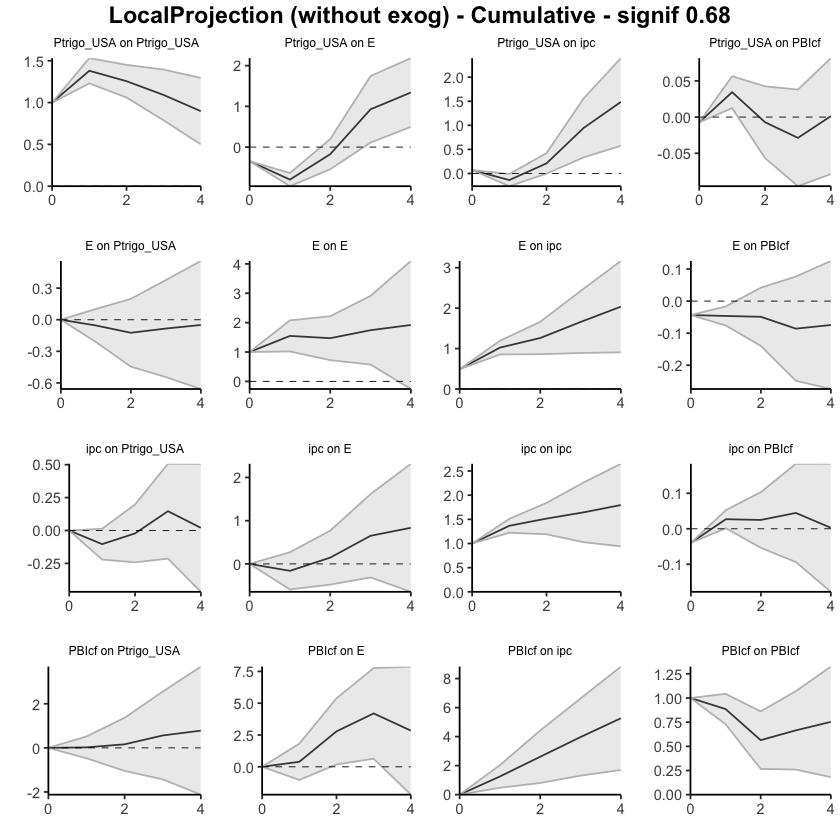

In [75]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,-0.3066168,-0.73514486,0.1219113
38,ipc,E,2,0.1650563,-0.08907421,0.4191869
39,ipc,E,3,0.3360431,-0.07308706,0.7451733
40,ipc,E,4,0.1919149,-0.19904888,0.5828786


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,1.1690623,-0.1348772,2.473002
53,PBIcf,E,2,2.1685925,0.8755176,3.461667
54,PBIcf,E,3,1.7650336,0.8197935,2.710274
55,PBIcf,E,4,-0.2366704,-1.5532452,1.079904


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4567605,-0.4567605,-0.4567605
2,Ptrigo_USA,E,1,-0.4584261,-0.4994812,-0.4173710
3,Ptrigo_USA,E,2,0.6846647,0.4245917,0.9447378
4,Ptrigo_USA,E,3,1.0610469,0.7042300,1.4178637
5,Ptrigo_USA,E,4,0.2850121,0.2818698,0.2881544


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.01765728,-0.01765728,-0.01765728
12,Ptrigo_USA,PBIcf,1,0.04866752,0.03631557,0.06101948
13,Ptrigo_USA,PBIcf,2,-0.02371672,-0.02577725,-0.02165620
14,Ptrigo_USA,PBIcf,3,-0.02392721,-0.02362086,-0.02423355
15,Ptrigo_USA,PBIcf,4,0.03687750,0.02967845,0.04407656


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.05022763,-0.1984895,0.09803421
18,E,Ptrigo_USA,2,-0.03687111,-0.1471608,0.07341858
19,E,Ptrigo_USA,3,0.03607500,-0.1029257,0.17507573
20,E,Ptrigo_USA,4,0.07911671,-0.0870224,0.24525581


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.0000000,0.00000000,0.000000000
32,ipc,Ptrigo_USA,1,-0.0982020,-0.20020132,0.003797322
33,ipc,Ptrigo_USA,2,0.1894229,0.10952555,0.269320197
34,ipc,Ptrigo_USA,3,0.2534791,0.07845809,0.428500202
35,ipc,Ptrigo_USA,4,-0.1891907,-0.35594772,-0.022433779


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.2924698,-0.1749698,0.7599095
48,PBIcf,Ptrigo_USA,2,0.1590763,-0.6624180,0.9805706
49,PBIcf,Ptrigo_USA,3,0.5554029,-0.2946677,1.4054735
50,PBIcf,Ptrigo_USA,4,0.3926869,-0.6496209,1.4349948


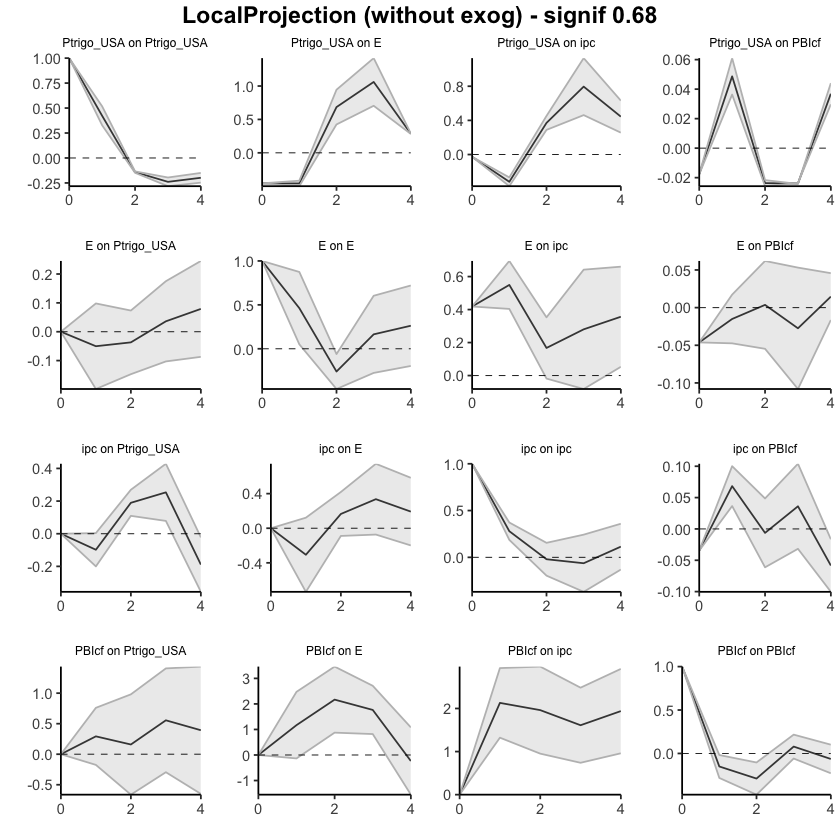

In [77]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 3, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.3066168,-0.7351449,0.1219113
38,ipc,E,2,-0.1415604,-0.8242191,0.5410982
39,ipc,E,3,0.1944827,-0.8973061,1.2862714
40,ipc,E,4,0.3863975,-1.0963550,1.8691501


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.000000000,0.000000
52,PBIcf,E,1,1.169062,-0.134877238,2.473002
53,PBIcf,E,2,3.337655,0.740640403,5.934669
54,PBIcf,E,3,5.102688,1.560433905,8.644943
55,PBIcf,E,4,4.866018,0.007188736,9.724847


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4567605,-0.4567605,-0.45676046
2,Ptrigo_USA,E,1,-0.9151865,-0.9562416,-0.87413144
3,Ptrigo_USA,E,2,-0.2305218,-0.5316500,0.07060635
4,Ptrigo_USA,E,3,0.8305251,0.1725800,1.48847007
5,Ptrigo_USA,E,4,1.1155371,0.4544498,1.77662444


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.017657280,-0.017657280,-0.017657280
12,Ptrigo_USA,PBIcf,1,0.031010241,0.018658285,0.043362197
13,Ptrigo_USA,PBIcf,2,0.007293519,-0.007118961,0.021706000
14,Ptrigo_USA,PBIcf,3,-0.016633686,-0.030739818,-0.002527554
15,Ptrigo_USA,PBIcf,4,0.020243817,-0.001061373,0.041549007


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.05022763,-0.1984895,0.09803421
18,E,Ptrigo_USA,2,-0.08709874,-0.3456503,0.17145279
19,E,Ptrigo_USA,3,-0.05102373,-0.4485760,0.34652853
20,E,Ptrigo_USA,4,0.02809297,-0.5355984,0.59178434


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.00000000,0.000000000
32,ipc,Ptrigo_USA,1,-0.09820200,-0.20020132,0.003797322
33,ipc,Ptrigo_USA,2,0.09122088,-0.09067576,0.273117519
34,ipc,Ptrigo_USA,3,0.34470002,-0.01221767,0.701617721
35,ipc,Ptrigo_USA,4,0.15550928,-0.36816539,0.679183942


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.2924698,-0.1749698,0.7599095
48,PBIcf,Ptrigo_USA,2,0.4515461,-0.8373878,1.7404801
49,PBIcf,Ptrigo_USA,3,1.0069490,-1.1320555,3.1459535
50,PBIcf,Ptrigo_USA,4,1.3996359,-1.7816765,4.5809483


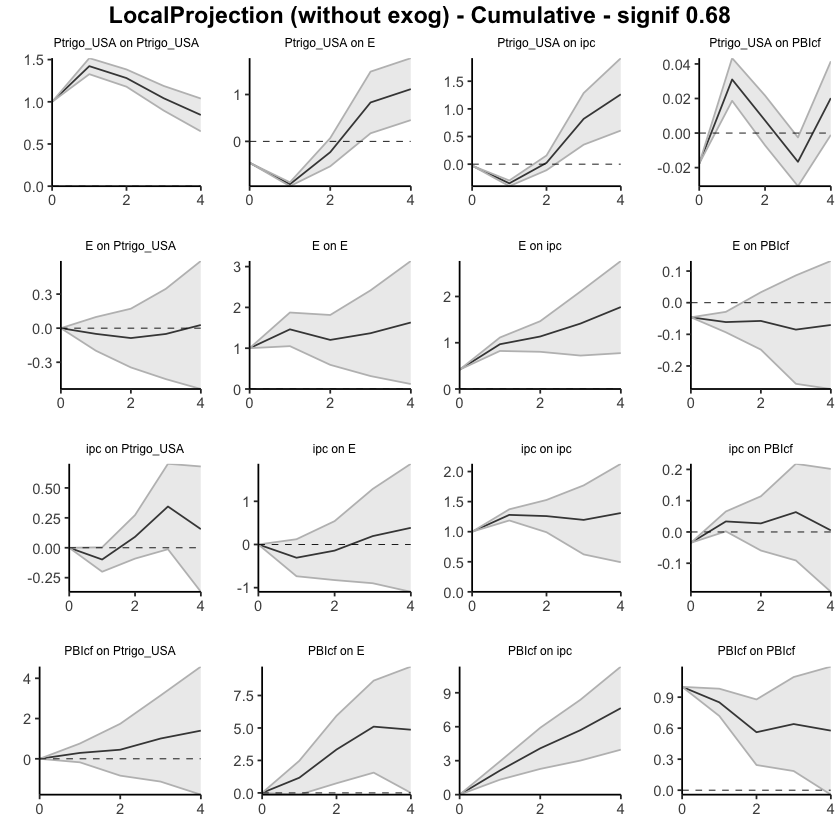

In [76]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 3, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1943-1982. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.2342074,0.1457507,0.3226642
13,ipc,E,2,0.9964348,0.5647302,1.4281394
14,ipc,E,3,0.8564070,0.6030287,1.1097852
15,ipc,E,4,0.9181593,0.4050361,1.4312825


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,1.0441303,-0.3186297,2.406890
23,PBIcf,E,2,3.1865329,2.2932579,4.079808
24,PBIcf,E,3,1.0787516,-0.1824699,2.339973
25,PBIcf,E,4,-0.5836098,-1.8242406,0.657021


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5002067,0.50020665,0.5002067
2,E,ipc,1,0.4989656,0.41448871,0.5834424
3,E,ipc,2,0.1322240,-0.07951507,0.3439630
4,E,ipc,3,0.3108160,-0.03672849,0.6583604
5,E,ipc,4,0.2724073,-0.01557444,0.5603891


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.606250,0.7010388,2.511461
28,PBIcf,ipc,2,2.295037,1.5129208,3.077154
29,PBIcf,ipc,3,1.300479,0.5360896,2.064868
30,PBIcf,ipc,4,1.272566,0.2757737,2.269357


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.051722112,-0.05172211,-0.051722112
7,E,PBIcf,1,-0.012758020,-0.02925467,0.003738632
8,E,PBIcf,2,0.008176335,-0.03787747,0.054230144
9,E,PBIcf,3,-0.023426011,-0.09188249,0.045030464
10,E,PBIcf,4,0.016045821,-0.01910927,0.051200912


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.042307978,-0.04230798,-0.042307978
17,ipc,PBIcf,1,-0.002795604,-0.01159404,0.006002829
18,ipc,PBIcf,2,-0.037857959,-0.07072269,-0.004993231
19,ipc,PBIcf,3,-0.027460584,-0.07309143,0.018170260
20,ipc,PBIcf,4,-0.086463421,-0.10398911,-0.068937728


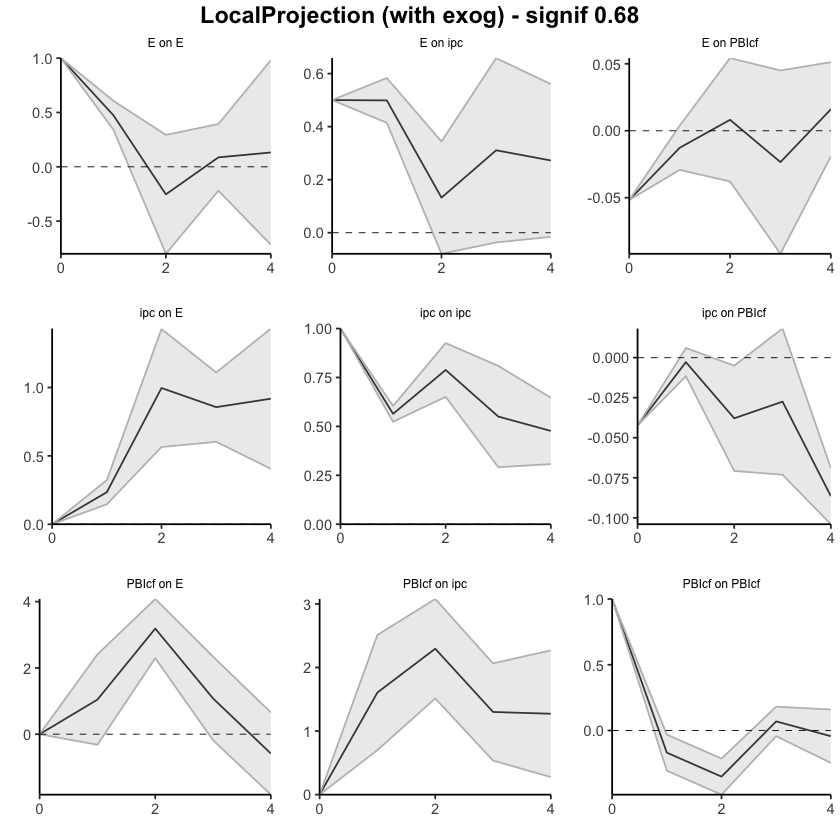

In [78]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.2342074,0.1457507,0.3226642
13,ipc,E,2,1.2306423,0.7104808,1.7508037
14,ipc,E,3,2.0870492,1.3135095,2.8605889
15,ipc,E,4,3.0052085,1.7185456,4.2918714


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.00000000,0.000000
22,PBIcf,E,1,1.044130,-0.31862974,2.406890
23,PBIcf,E,2,4.230663,1.97462817,6.486698
24,PBIcf,E,3,5.309415,1.79215828,8.826671
25,PBIcf,E,4,4.725805,-0.03208233,9.483692


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5002067,0.5002067,0.5002067
2,E,ipc,1,0.9991722,0.9146954,1.0836491
3,E,ipc,2,1.1313962,0.8351803,1.4276121
4,E,ipc,3,1.4422121,0.7984518,2.0859725
5,E,ipc,4,1.7146195,0.7828774,2.6463616


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.606250,0.7010388,2.511461
28,PBIcf,ipc,2,3.901287,2.2139596,5.588615
29,PBIcf,ipc,3,5.201766,2.7500493,7.653483
30,PBIcf,ipc,4,6.474332,3.0258229,9.922840


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.05172211,-0.05172211,-0.051722112
7,E,PBIcf,1,-0.06448013,-0.08097678,-0.047983480
8,E,PBIcf,2,-0.05630380,-0.11885426,0.006246663
9,E,PBIcf,3,-0.07972981,-0.21073674,0.051277128
10,E,PBIcf,4,-0.06368399,-0.22984601,0.102478040


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04230798,-0.04230798,-0.04230798
17,ipc,PBIcf,1,-0.04510358,-0.05390201,-0.03630515
18,ipc,PBIcf,2,-0.08296154,-0.12462470,-0.04129838
19,ipc,PBIcf,3,-0.11042212,-0.19771613,-0.02312812
20,ipc,PBIcf,4,-0.19688555,-0.30170524,-0.09206585


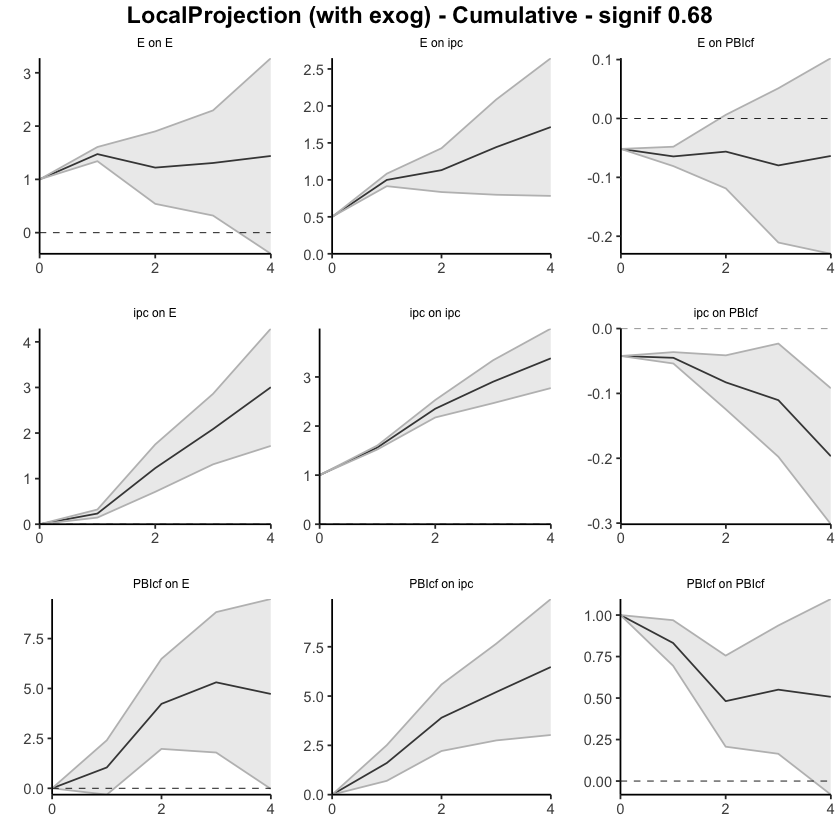

In [79]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.1891880,-0.7423754,0.3639994
13,ipc,E,2,0.5405257,0.2750901,0.8059613
14,ipc,E,3,0.7886541,0.4126040,1.1647043
15,ipc,E,4,0.1708946,-0.2755212,0.6173104


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.00000000
22,PBIcf,E,1,1.480768,-0.4913825,3.45291792
23,PBIcf,E,2,3.048304,1.8149281,4.28168089
24,PBIcf,E,3,0.672245,-0.4400797,1.78456968
25,PBIcf,E,4,-1.445615,-2.7989666,-0.09226306


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4831721,0.48317214,0.4831721
2,E,ipc,1,0.5850830,0.42061465,0.7495513
3,E,ipc,2,0.2586010,0.04412843,0.4730736
4,E,ipc,3,0.4229465,-0.01531990,0.8612129
5,E,ipc,4,0.4727670,0.05584252,0.8896915


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.877910,1.0301249,2.725694
28,PBIcf,ipc,2,2.124631,1.1657474,3.083514
29,PBIcf,ipc,3,1.303024,0.3331779,2.272870
30,PBIcf,ipc,4,1.236824,0.1010889,2.372558


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.047727528,-0.04772753,-0.04772753
7,E,PBIcf,1,-0.008587421,-0.03588477,0.01870992
8,E,PBIcf,2,0.009840216,-0.05596383,0.07564427
9,E,PBIcf,3,-0.023228948,-0.08944464,0.04298674
10,E,PBIcf,4,0.011053781,-0.02863054,0.05073810


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.0478049573,-0.04780496,-0.0478049573
17,ipc,PBIcf,1,0.0746772694,0.05100242,0.0983521159
18,ipc,PBIcf,2,-0.0253163642,-0.08808226,0.0374495336
19,ipc,PBIcf,3,-0.0006214665,-0.05501618,0.0537732510
20,ipc,PBIcf,4,-0.0386461994,-0.07819209,0.0008996944


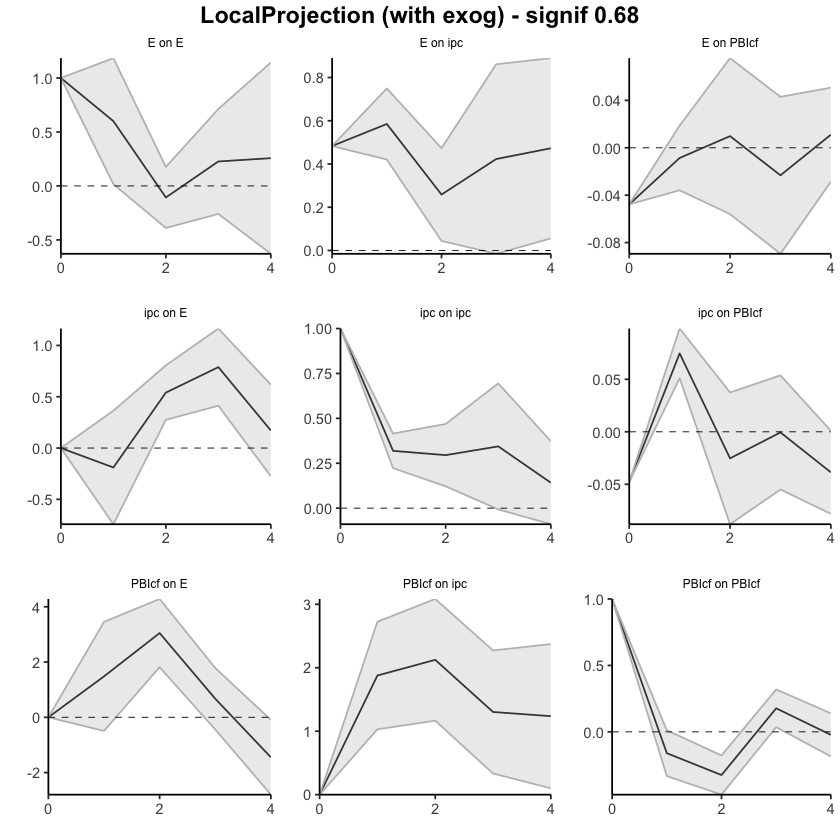

In [82]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,-0.1891880,-0.74237544,0.3639994
13,ipc,E,2,0.3513377,-0.46728537,1.1699607
14,ipc,E,3,1.1399918,-0.05468142,2.3346651
15,ipc,E,4,1.3108864,-0.33020257,2.9519755


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.480768,-0.4913825,3.452918
23,PBIcf,E,2,4.529072,1.3235456,7.734599
24,PBIcf,E,3,5.201317,0.8834660,9.519168
25,PBIcf,E,4,3.755702,-1.9155007,9.426905


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4831721,0.4831721,0.4831721
2,E,ipc,1,1.0682551,0.9037868,1.2327234
3,E,ipc,2,1.3268561,0.9479152,1.7057970
4,E,ipc,3,1.7498027,0.9325953,2.5670100
5,E,ipc,4,2.2225696,0.9884378,3.4567014


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.877910,1.030125,2.725694
28,PBIcf,ipc,2,4.002540,2.195872,5.809208
29,PBIcf,ipc,3,5.305564,2.529050,8.082078
30,PBIcf,ipc,4,6.542388,2.630139,10.454637


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04772753,-0.04772753,-0.04772753
7,E,PBIcf,1,-0.05631495,-0.08361229,-0.02901760
8,E,PBIcf,2,-0.04647473,-0.13957613,0.04662666
9,E,PBIcf,3,-0.06970368,-0.22902076,0.08961340
10,E,PBIcf,4,-0.05864990,-0.25765130,0.14035150


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.0478049573,-0.047804957,-0.04780496
17,ipc,PBIcf,1,0.0268723121,0.003197466,0.05054716
18,ipc,PBIcf,2,0.0015559479,-0.084884796,0.08799669
19,ipc,PBIcf,3,0.0009344814,-0.139900980,0.14176994
20,ipc,PBIcf,4,-0.0377117180,-0.218093074,0.14266964


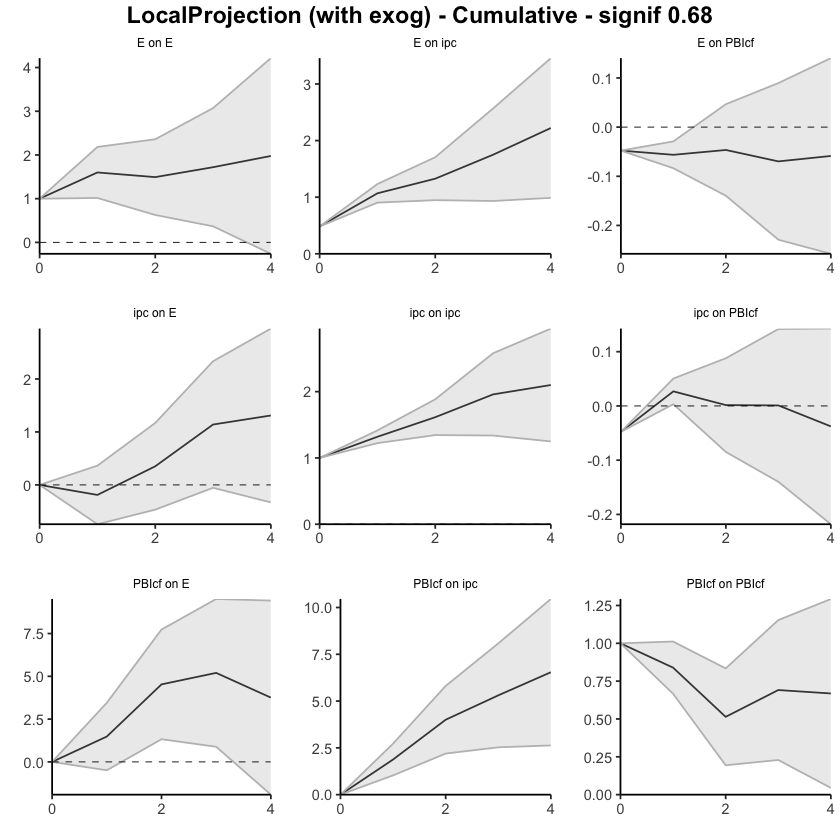

In [81]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1139807,0.04449868,0.1834627
13,ipc,E,2,0.8951720,0.49383281,1.2965112
14,ipc,E,3,0.8936348,0.59695371,1.1903159
15,ipc,E,4,0.9381753,0.55806339,1.3182872


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.5913648,-0.9628118,2.1455414
23,PBIcf,E,2,3.0844778,2.0968069,4.0721486
24,PBIcf,E,3,1.4600053,0.4318352,2.4881754
25,PBIcf,E,4,-0.5033950,-1.8374798,0.8306899


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4890357,0.489035745,0.4890357
2,E,ipc,1,0.5392375,0.375851307,0.7026237
3,E,ipc,2,0.1904399,0.075069863,0.3058100
4,E,ipc,3,0.2855943,-0.119543200,0.6907319
5,E,ipc,4,0.2554349,0.003533054,0.5073367


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.443063,0.5670306,2.319095
28,PBIcf,ipc,2,2.188000,1.3146271,3.061373
29,PBIcf,ipc,3,1.669039,0.9813509,2.356727
30,PBIcf,ipc,4,1.485236,0.4713885,2.499083


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.049718670,-0.04971867,-0.049718670
7,E,PBIcf,1,-0.011584160,-0.02715714,0.003988822
8,E,PBIcf,2,0.004855118,-0.03878432,0.048494554
9,E,PBIcf,3,-0.028371869,-0.08333799,0.026594253
10,E,PBIcf,4,0.013545410,-0.01706594,0.044156760


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.049798626,-0.049798626,-0.049798626
17,ipc,PBIcf,1,-0.003086694,-0.009798521,0.003625132
18,ipc,PBIcf,2,-0.031935073,-0.062179964,-0.001690182
19,ipc,PBIcf,3,-0.022496194,-0.059391169,0.014398782
20,ipc,PBIcf,4,-0.077920322,-0.090238205,-0.065602438


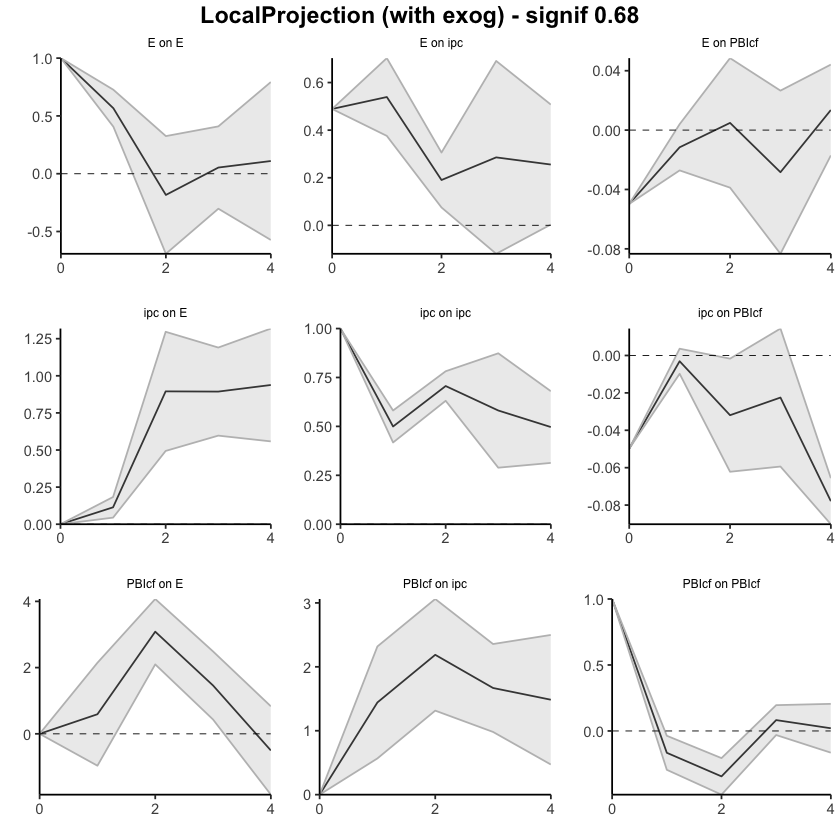

In [80]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1139807,0.04449868,0.1834627
13,ipc,E,2,1.0091527,0.53833149,1.4799739
14,ipc,E,3,1.9027875,1.13528520,2.6702897
15,ipc,E,4,2.8409628,1.69334858,3.9885769


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.5913648,-0.9628118,2.145541
23,PBIcf,E,2,3.6758425,1.1339952,6.217690
24,PBIcf,E,3,5.1358478,1.5658303,8.705865
25,PBIcf,E,4,4.6324528,-0.2716495,9.536555


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4890357,0.4890357,0.4890357
2,E,ipc,1,1.0282732,0.8648871,1.1916594
3,E,ipc,2,1.2187131,0.9399569,1.4974694
4,E,ipc,3,1.5043075,0.8204137,2.1882013
5,E,ipc,4,1.7597424,0.8239468,2.6955380


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.443063,0.5670306,2.319095
28,PBIcf,ipc,2,3.631063,1.8816577,5.380469
29,PBIcf,ipc,3,5.300102,2.8630086,7.737196
30,PBIcf,ipc,4,6.785338,3.3343971,10.236278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04971867,-0.04971867,-0.049718670
7,E,PBIcf,1,-0.06130283,-0.07687581,-0.045729849
8,E,PBIcf,2,-0.05644771,-0.11566013,0.002764705
9,E,PBIcf,3,-0.08481958,-0.19899812,0.029358958
10,E,PBIcf,4,-0.07127417,-0.21606406,0.073515718


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04979863,-0.04979863,-0.04979863
17,ipc,PBIcf,1,-0.05288532,-0.05959715,-0.04617349
18,ipc,PBIcf,2,-0.08482039,-0.12177711,-0.04786368
19,ipc,PBIcf,3,-0.10731659,-0.18116828,-0.03346489
20,ipc,PBIcf,4,-0.18523691,-0.27140649,-0.09906733


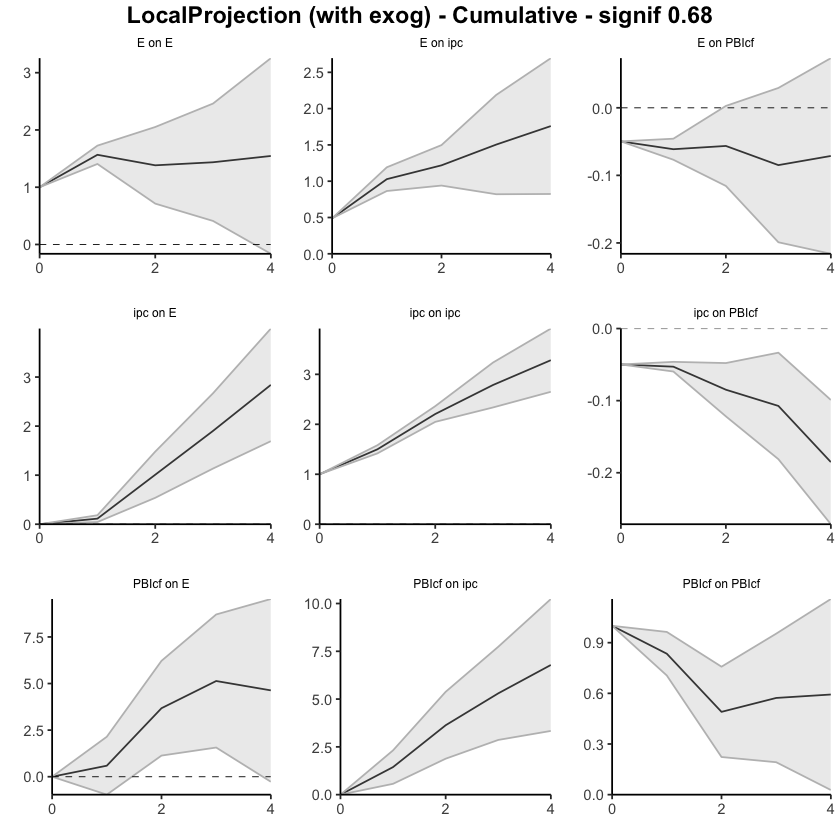

In [83]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.3241674,-0.71876462,0.07042972
13,ipc,E,2,0.3488866,0.15250327,0.54526997
14,ipc,E,3,0.8994981,0.37984058,1.41915571
15,ipc,E,4,0.3068045,0.06129376,0.55231516


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.5569749,-0.7102384,1.8241882
23,PBIcf,E,2,2.3906450,1.1378532,3.6434368
24,PBIcf,E,3,1.2236183,0.3753187,2.0719179
25,PBIcf,E,4,-1.5600674,-3.5703474,0.4502126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4751556,0.47515562,0.4751556
2,E,ipc,1,0.5507808,0.37334972,0.7282119
3,E,ipc,2,0.2202949,0.02473364,0.4158561
4,E,ipc,3,0.2911583,-0.17418461,0.7565013
5,E,ipc,4,0.2893572,0.07910471,0.4996096


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.00000000,0.000000
27,PBIcf,ipc,1,1.347035,0.65754400,2.036526
28,PBIcf,ipc,2,1.249560,0.26406815,2.235051
29,PBIcf,ipc,3,1.293265,0.44479741,2.141733
30,PBIcf,ipc,4,1.062527,0.05042871,2.074626


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.046132999,-0.04613300,-0.04613300
7,E,PBIcf,1,-0.005690477,-0.03333820,0.02195725
8,E,PBIcf,2,0.002908492,-0.05917784,0.06499483
9,E,PBIcf,3,-0.031743140,-0.10759076,0.04410448
10,E,PBIcf,4,0.011772789,-0.02700303,0.05054861


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.051182538,-0.05118254,-0.051182538
17,ipc,PBIcf,1,0.074145894,0.04949281,0.098798974
18,ipc,PBIcf,2,-0.006091441,-0.06526445,0.053081573
19,ipc,PBIcf,3,-0.005004660,-0.06857843,0.058569111
20,ipc,PBIcf,4,-0.043148862,-0.08798904,0.001691313


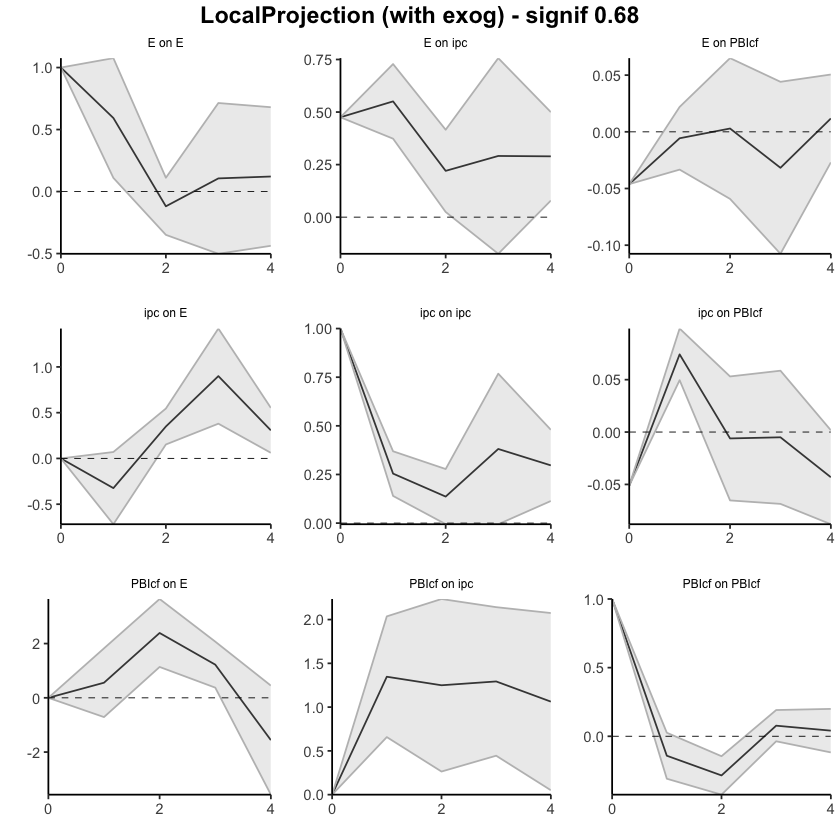

In [84]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.32416745,-0.7187646,0.07042972
13,ipc,E,2,0.02471917,-0.5662614,0.61569969
14,ipc,E,3,0.92421731,-0.1864208,2.03485540
15,ipc,E,4,1.23102177,-0.1251270,2.58717057


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.5569749,-0.7102384,1.824188
23,PBIcf,E,2,2.9476199,0.4276148,5.467625
24,PBIcf,E,3,4.1712382,0.8029336,7.539543
25,PBIcf,E,4,2.6111708,-2.7674139,7.989756


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4751556,0.4751556,0.4751556
2,E,ipc,1,1.0259365,0.8485053,1.2033676
3,E,ipc,2,1.2462314,0.8732390,1.6192237
4,E,ipc,3,1.5373897,0.6990544,2.3757250
5,E,ipc,4,1.8267469,0.7781591,2.8753346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.347035,0.6575440,2.036526
28,PBIcf,ipc,2,2.596595,0.9216121,4.271577
29,PBIcf,ipc,3,3.889860,1.3664096,6.413311
30,PBIcf,ipc,4,4.952387,1.4168383,8.487937


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04613300,-0.0461330,-0.04613300
7,E,PBIcf,1,-0.05182348,-0.0794712,-0.02417575
8,E,PBIcf,2,-0.04891498,-0.1386490,0.04081907
9,E,PBIcf,3,-0.08065812,-0.2462398,0.08492355
10,E,PBIcf,4,-0.06888534,-0.2732428,0.13547217


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.05118254,-0.051182538,-0.05118254
17,ipc,PBIcf,1,0.02296336,-0.001689724,0.04761644
18,ipc,PBIcf,2,0.01687192,-0.066954179,0.10069801
19,ipc,PBIcf,3,0.01186726,-0.135532610,0.15926712
20,ipc,PBIcf,4,-0.03128161,-0.223521646,0.16095843


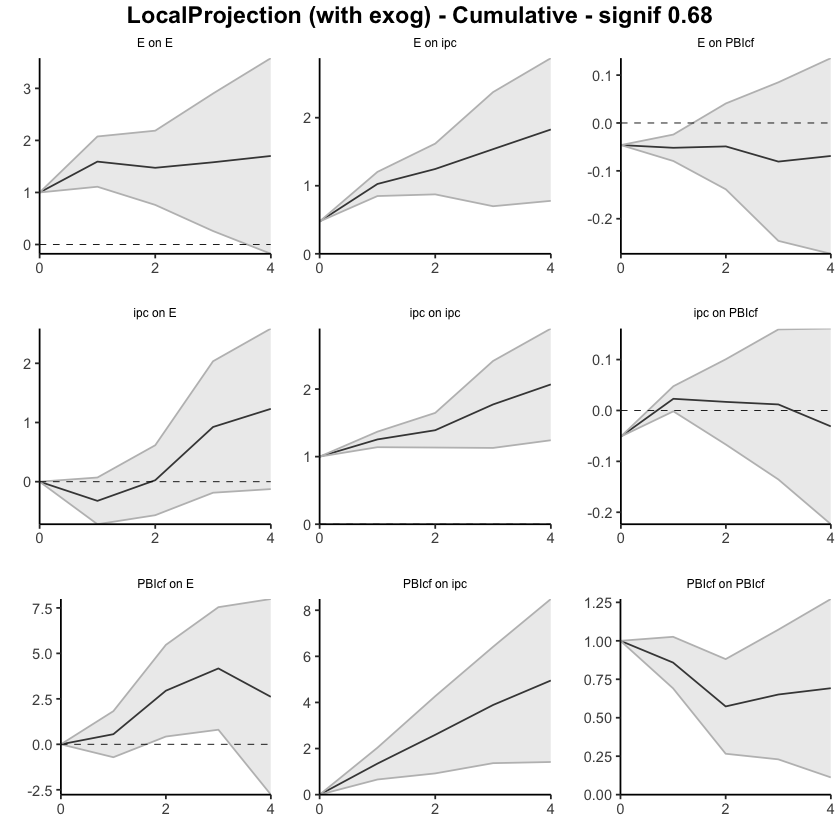

In [85]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1188490,0.03823466,0.1994634
13,ipc,E,2,0.8031164,0.47562057,1.1306123
14,ipc,E,3,0.6891957,0.44819982,0.9301916
15,ipc,E,4,0.8673644,0.38457664,1.3501522


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.6207971,-0.9621767,2.2037710
23,PBIcf,E,2,3.4440456,2.2726467,4.6154446
24,PBIcf,E,3,1.9419061,1.1987730,2.6850392
25,PBIcf,E,4,-0.3042288,-1.5727511,0.9642935


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4911345,0.4911345,0.4911345
2,E,ipc,1,0.5383515,0.3681981,0.7085049
3,E,ipc,2,0.2450559,0.1441785,0.3459334
4,E,ipc,3,0.4133282,0.1374318,0.6892246
5,E,ipc,4,0.3721530,0.0271488,0.7171573


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.479752,0.593404,2.366100
28,PBIcf,ipc,2,2.454530,1.574354,3.334705
29,PBIcf,ipc,3,2.089344,1.336108,2.842580
30,PBIcf,ipc,4,1.909986,1.015441,2.804532


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.049222030,-0.04922203,-0.04922203
7,E,PBIcf,1,-0.010011484,-0.03120546,0.01118249
8,E,PBIcf,2,-0.001329934,-0.04403735,0.04137748
9,E,PBIcf,3,-0.029748864,-0.08327981,0.02378208
10,E,PBIcf,4,0.011807541,-0.02229901,0.04591409


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.047161649,-0.04716165,-0.047161649
17,ipc,PBIcf,1,-0.005882191,-0.01459130,0.002826916
18,ipc,PBIcf,2,-0.025421147,-0.05354410,0.002701806
19,ipc,PBIcf,3,-0.019791000,-0.05485632,0.015274324
20,ipc,PBIcf,4,-0.077188916,-0.09158396,-0.062793871


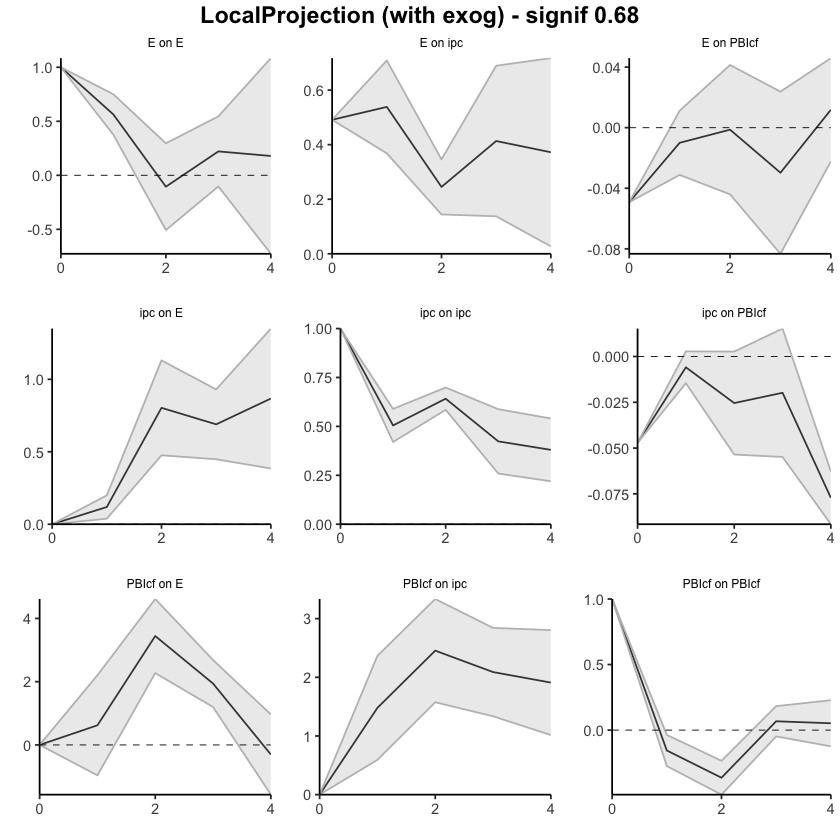

In [86]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1188490,0.03823466,0.1994634
13,ipc,E,2,0.9219655,0.51385523,1.3300757
14,ipc,E,3,1.6111612,0.96205506,2.2602673
15,ipc,E,4,2.4785256,1.34663170,3.6104195


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.6207971,-0.9621767,2.203771
23,PBIcf,E,2,4.0648427,1.3104699,6.819216
24,PBIcf,E,3,6.0067488,2.5092429,9.504255
25,PBIcf,E,4,5.7025200,0.9364918,10.468548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4911345,0.4911345,0.4911345
2,E,ipc,1,1.0294860,0.8593326,1.1996394
3,E,ipc,2,1.2745419,1.0035110,1.5455728
4,E,ipc,3,1.6878701,1.1409428,2.2347974
5,E,ipc,4,2.0600231,1.1680916,2.9519546


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,1.479752,0.593404,2.366100
28,PBIcf,ipc,2,3.934282,2.167758,5.700805
29,PBIcf,ipc,3,6.023626,3.503866,8.543385
30,PBIcf,ipc,4,7.933612,4.519307,11.347918


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04922203,-0.04922203,-0.049222030
7,E,PBIcf,1,-0.05923351,-0.08042749,-0.038039538
8,E,PBIcf,2,-0.06056345,-0.12446484,0.003337943
9,E,PBIcf,3,-0.09031231,-0.20774465,0.027120026
10,E,PBIcf,4,-0.07850477,-0.23004366,0.073034119


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04716165,-0.04716165,-0.04716165
17,ipc,PBIcf,1,-0.05304384,-0.06175295,-0.04433473
18,ipc,PBIcf,2,-0.07846499,-0.11529704,-0.04163293
19,ipc,PBIcf,3,-0.09825599,-0.17015337,-0.02635860
20,ipc,PBIcf,4,-0.17544490,-0.26173733,-0.08915247


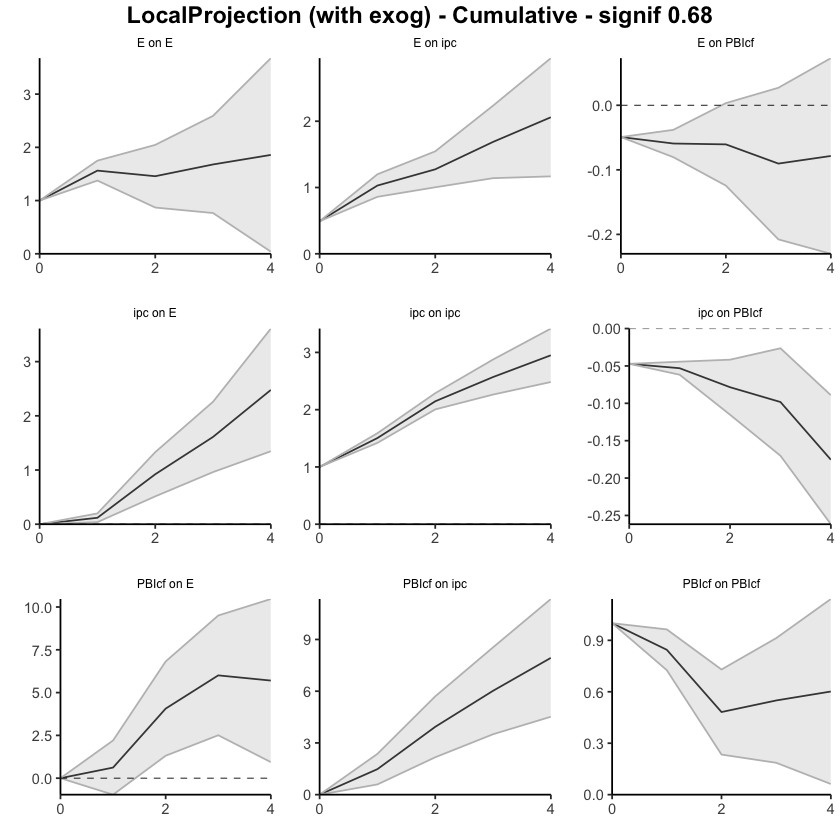

In [87]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.1624309,-0.5850901,0.2602284
13,ipc,E,2,0.2930271,0.1051819,0.4808723
14,ipc,E,3,0.4976452,0.1639421,0.8313483
15,ipc,E,4,0.1918224,-0.3182322,0.7018771


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,0.3927689,-1.0334408,1.8189785
23,PBIcf,E,2,2.3930060,1.2193628,3.5666492
24,PBIcf,E,3,1.4098916,0.4447643,2.3750189
25,PBIcf,E,4,-1.3524470,-2.8213734,0.1164794


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4584941,0.458494079,0.4584941
2,E,ipc,1,0.5241416,0.358314171,0.6899691
3,E,ipc,2,0.2353270,0.007628985,0.4630250
4,E,ipc,3,0.3944672,0.035697263,0.7532371
5,E,ipc,4,0.3771546,0.020241534,0.7340676


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.255028,0.4749789,2.035076
28,PBIcf,ipc,2,1.358425,0.3294859,2.387363
29,PBIcf,ipc,3,1.355949,0.5047508,2.207146
30,PBIcf,ipc,4,1.293774,0.3938488,2.193700


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.040531083,-0.04053108,-0.04053108
7,E,PBIcf,1,-0.005156449,-0.03450481,0.02419191
8,E,PBIcf,2,-0.003048416,-0.06256384,0.05646701
9,E,PBIcf,3,-0.037430986,-0.10722472,0.03236275
10,E,PBIcf,4,0.012953673,-0.02317780,0.04908514


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.0450641666,-0.04506417,-0.045064167
17,ipc,PBIcf,1,0.0672495776,0.04255573,0.091943424
18,ipc,PBIcf,2,-0.0003451246,-0.05254831,0.051858060
19,ipc,PBIcf,3,0.0192138727,-0.04016896,0.078596704
20,ipc,PBIcf,4,-0.0423790828,-0.08348035,-0.001277814


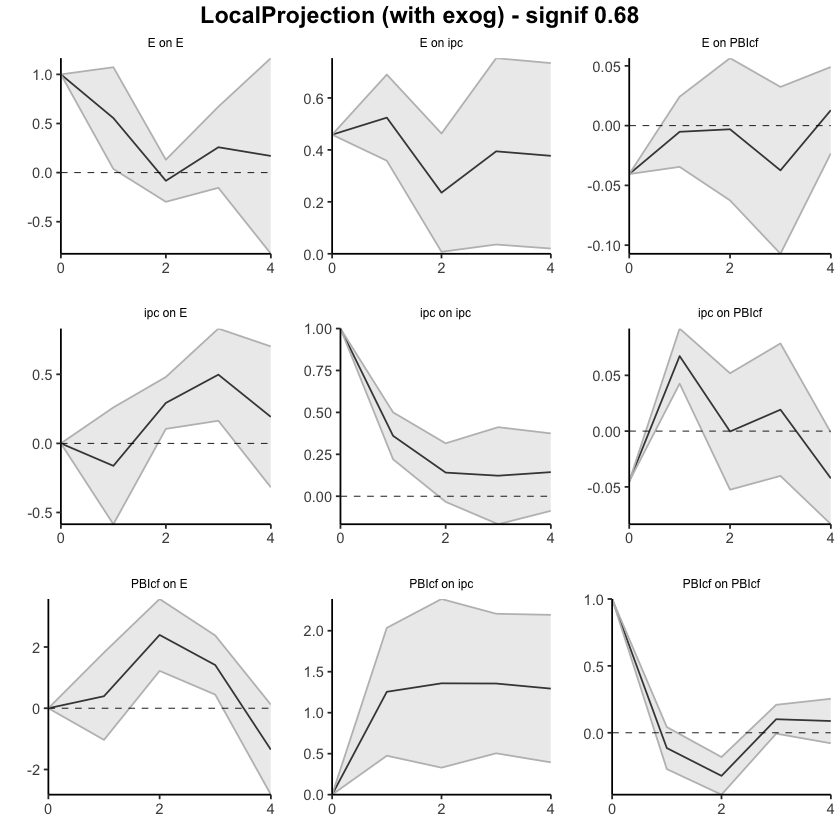

In [88]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.1624309,-0.5850901,0.2602284
13,ipc,E,2,0.1305962,-0.4799082,0.7411007
14,ipc,E,3,0.6282414,-0.3159662,1.5724490
15,ipc,E,4,0.8200638,-0.6341984,2.2743261


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,0.3927689,-1.0334408,1.818979
23,PBIcf,E,2,2.7857749,0.1859220,5.385628
24,PBIcf,E,3,4.1956664,0.6306863,7.760647
25,PBIcf,E,4,2.8432194,-2.1906871,7.877126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4584941,0.4584941,0.4584941
2,E,ipc,1,0.9826357,0.8168083,1.1484631
3,E,ipc,2,1.2179627,0.8244372,1.6114882
4,E,ipc,3,1.6124299,0.8601345,2.3647253
5,E,ipc,4,1.9895845,0.8803760,3.0987929


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,1.255028,0.4749789,2.035076
28,PBIcf,ipc,2,2.613452,0.8044649,4.422439
29,PBIcf,ipc,3,3.969401,1.3092157,6.629585
30,PBIcf,ipc,4,5.263175,1.7030645,8.823285


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04053108,-0.04053108,-0.04053108
7,E,PBIcf,1,-0.04568753,-0.07503589,-0.01633917
8,E,PBIcf,2,-0.04873595,-0.13759973,0.04012783
9,E,PBIcf,3,-0.08616693,-0.24482445,0.07249058
10,E,PBIcf,4,-0.07321326,-0.26800225,0.12157573


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.045064167,-0.045064167,-0.04506417
17,ipc,PBIcf,1,0.022185411,-0.002508436,0.04687926
18,ipc,PBIcf,2,0.021840286,-0.055056745,0.09873732
19,ipc,PBIcf,3,0.041054159,-0.095225704,0.17733402
20,ipc,PBIcf,4,-0.001324924,-0.178706055,0.17605621


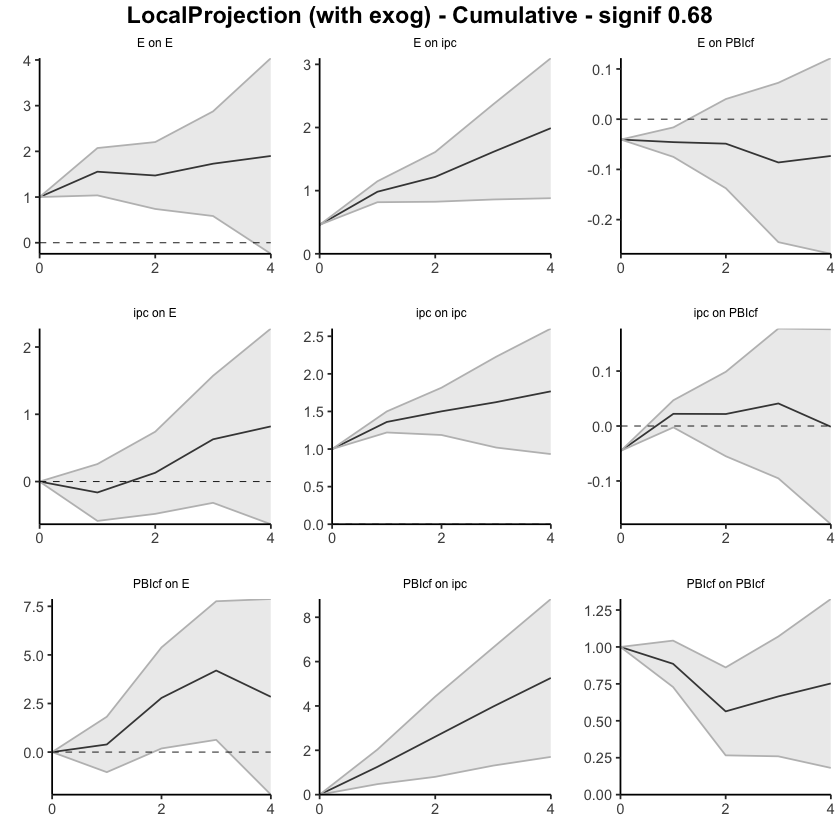

In [89]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1987. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2221725,0.0531303,0.3912147
38,ipc,E,2,0.5162377,0.1700918,0.8623835
39,ipc,E,3,0.4314233,-0.1260614,0.9889079
40,ipc,E,4,1.0372601,0.6934475,1.3810728


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.0000000
52,PBIcf,E,1,3.018303,1.0092730,5.0273325
53,PBIcf,E,2,1.506700,0.1901214,2.8232782
54,PBIcf,E,3,-2.080742,-4.4737985,0.3123147
55,PBIcf,E,4,-2.345254,-4.3245093,-0.3659978


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.63726736,-0.63726736,-0.6372674
2,Psoja_USA,E,1,-0.56004556,-0.80876745,-0.3113237
3,Psoja_USA,E,2,0.21772460,0.23654410,0.1989051
4,Psoja_USA,E,3,0.17153112,-0.16607808,0.5091403
5,Psoja_USA,E,4,0.04957117,-0.06613273,0.1652751


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.057103008,0.05710301,0.05710301
12,Psoja_USA,PBIcf,1,-0.006470199,-0.02703384,0.01409344
13,Psoja_USA,PBIcf,2,-0.022826064,-0.02631461,-0.01933751
14,Psoja_USA,PBIcf,3,0.032260402,0.01668513,0.04783568
15,Psoja_USA,PBIcf,4,0.036547610,0.01908250,0.05401272


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.00000000,0.000000000
17,E,Psoja_USA,1,0.008871183,-0.13994484,0.157687201
18,E,Psoja_USA,2,0.004174205,-0.09734112,0.105689531
19,E,Psoja_USA,3,-0.076704059,-0.17342704,0.020018919
20,E,Psoja_USA,4,-0.091700564,-0.17502467,-0.008376459


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,-0.11556286,-0.21364333,-0.01748239
33,ipc,Psoja_USA,2,-0.09231618,-0.16101488,-0.02361748
34,ipc,Psoja_USA,3,-0.09200027,-0.15058066,-0.03341988
35,ipc,Psoja_USA,4,-0.03036980,-0.07991445,0.01917485


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,-0.1004744,-0.6057503,0.4048015
48,PBIcf,Psoja_USA,2,-1.4284781,-1.9660061,-0.8909501
49,PBIcf,Psoja_USA,3,0.5717240,-0.1762452,1.3196933
50,PBIcf,Psoja_USA,4,1.1798258,0.4198902,1.9397613


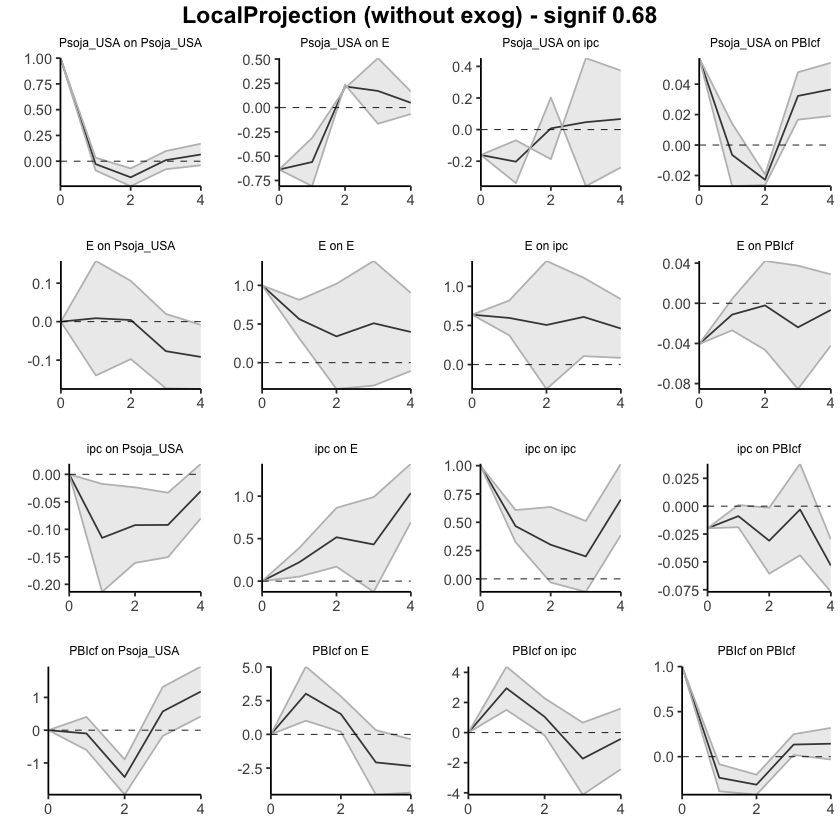

In [90]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,0.2221725,0.0531303,0.3912147
38,ipc,E,2,0.7384102,0.2232221,1.2535982
39,ipc,E,3,1.1698334,0.0971607,2.2425062
40,ipc,E,4,2.2070936,0.7906082,3.6235789


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.00000000,0.000000,0.000000
52,PBIcf,E,1,3.01830277,1.009273,5.027333
53,PBIcf,E,2,4.52500257,1.199394,7.850611
54,PBIcf,E,3,2.44426064,-3.274404,8.162925
55,PBIcf,E,4,0.09900711,-7.598913,7.796928


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.6372674,-0.6372674,-0.63726736
2,Psoja_USA,E,1,-1.1973129,-1.4460348,-0.94859103
3,Psoja_USA,E,2,-0.9795883,-1.2094907,-0.74968592
4,Psoja_USA,E,3,-0.8080572,-1.3755688,-0.24054560
5,Psoja_USA,E,4,-0.7584860,-1.4417015,-0.07527052


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.05710301,0.057103008,0.05710301
12,Psoja_USA,PBIcf,1,0.05063281,0.030069170,0.07119645
13,Psoja_USA,PBIcf,2,0.02780674,0.003754556,0.05185893
14,Psoja_USA,PBIcf,3,0.06006715,0.020439681,0.09969461
15,Psoja_USA,PBIcf,4,0.09661476,0.039522182,0.15370733


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.0000000,0.0000000
17,E,Psoja_USA,1,0.008871183,-0.1399448,0.1576872
18,E,Psoja_USA,2,0.013045387,-0.2372860,0.2633767
19,E,Psoja_USA,3,-0.063658671,-0.4107130,0.2833957
20,E,Psoja_USA,4,-0.155359235,-0.5857377,0.2750192


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.1155629,-0.2136433,-0.01748239
33,ipc,Psoja_USA,2,-0.2078790,-0.3746582,-0.04109987
34,ipc,Psoja_USA,3,-0.2998793,-0.5252389,-0.07451976
35,ipc,Psoja_USA,4,-0.3302491,-0.6051533,-0.05534491


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,-0.1004744,-0.6057503,0.4048015
48,PBIcf,Psoja_USA,2,-1.5289526,-2.5717564,-0.4861487
49,PBIcf,Psoja_USA,3,-0.9572285,-2.7480016,0.8335446
50,PBIcf,Psoja_USA,4,0.2225972,-2.3281114,2.7733059


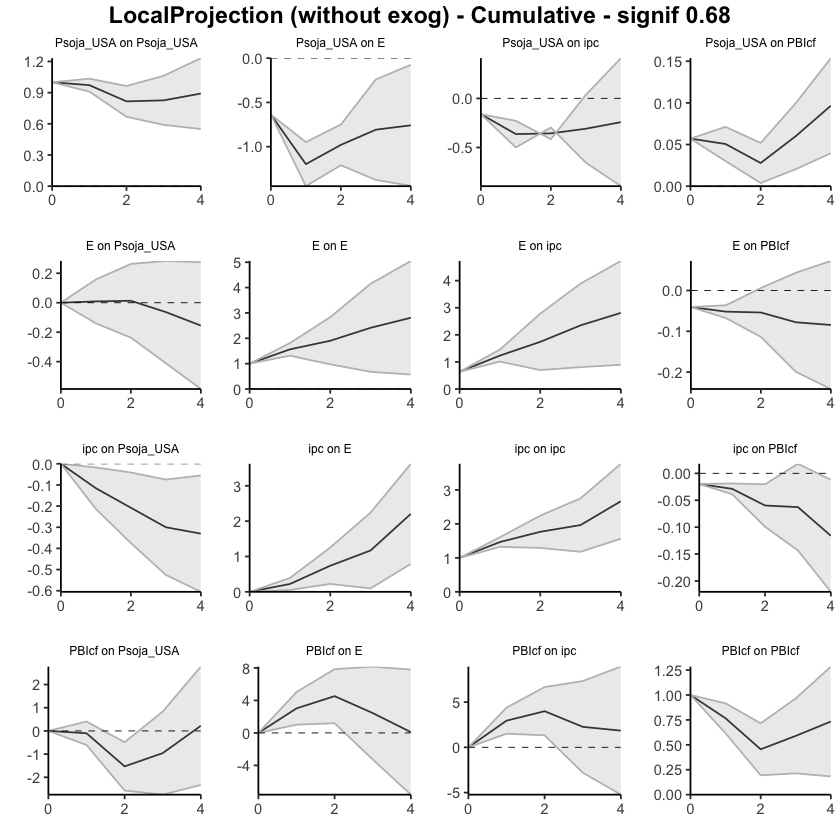

In [91]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1231520,-0.04013813,0.2864421
38,ipc,E,2,0.4636294,0.13835818,0.7889007
39,ipc,E,3,0.4665344,-0.07928987,1.0123586
40,ipc,E,4,1.0318972,0.73525001,1.3285444


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.0000000
52,PBIcf,E,1,2.623313,0.5395638,4.7070629
53,PBIcf,E,2,1.582622,0.2787913,2.8864527
54,PBIcf,E,3,-1.718219,-4.0596746,0.6232369
55,PBIcf,E,4,-2.256365,-4.2193267,-0.2934026


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.1777683,-0.17776825,-0.1777683
2,Pmaíz_USA,E,1,0.1158211,-0.12819854,0.3598407
3,Pmaíz_USA,E,2,0.6175310,0.22078547,1.0142766
4,Pmaíz_USA,E,3,0.3336108,0.04109177,0.6261299
5,Pmaíz_USA,E,4,0.2772857,0.07811326,0.4764582


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.014727752,0.014727752,0.01472775
12,Pmaíz_USA,PBIcf,1,0.006756939,-0.008505972,0.02201985
13,Pmaíz_USA,PBIcf,2,-0.028979408,-0.046253641,-0.01170517
14,Pmaíz_USA,PBIcf,3,-0.004135824,-0.030618553,0.02234690
15,Pmaíz_USA,PBIcf,4,0.036882494,0.012656265,0.06110872


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.08493801,-0.2368582,0.06698215
18,E,Pmaíz_USA,2,-0.03495170,-0.1927633,0.12285993
19,E,Pmaíz_USA,3,-0.05909315,-0.1496704,0.03148408
20,E,Pmaíz_USA,4,-0.09048241,-0.1992054,0.01824055


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.000000000
32,ipc,Pmaíz_USA,1,0.03740491,-0.07199802,0.146807849
33,ipc,Pmaíz_USA,2,-0.10635894,-0.22442489,0.011707002
34,ipc,Pmaíz_USA,3,-0.07843498,-0.15397540,-0.002894559
35,ipc,Pmaíz_USA,4,-0.04286487,-0.10301216,0.017282430


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.00000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.4142730,-0.98053582,0.1519897
48,PBIcf,Pmaíz_USA,2,-0.8530787,-1.36453178,-0.3416257
49,PBIcf,Pmaíz_USA,3,-0.2208464,-0.90577968,0.4640869
50,PBIcf,Pmaíz_USA,4,0.8416425,0.04852286,1.6347621


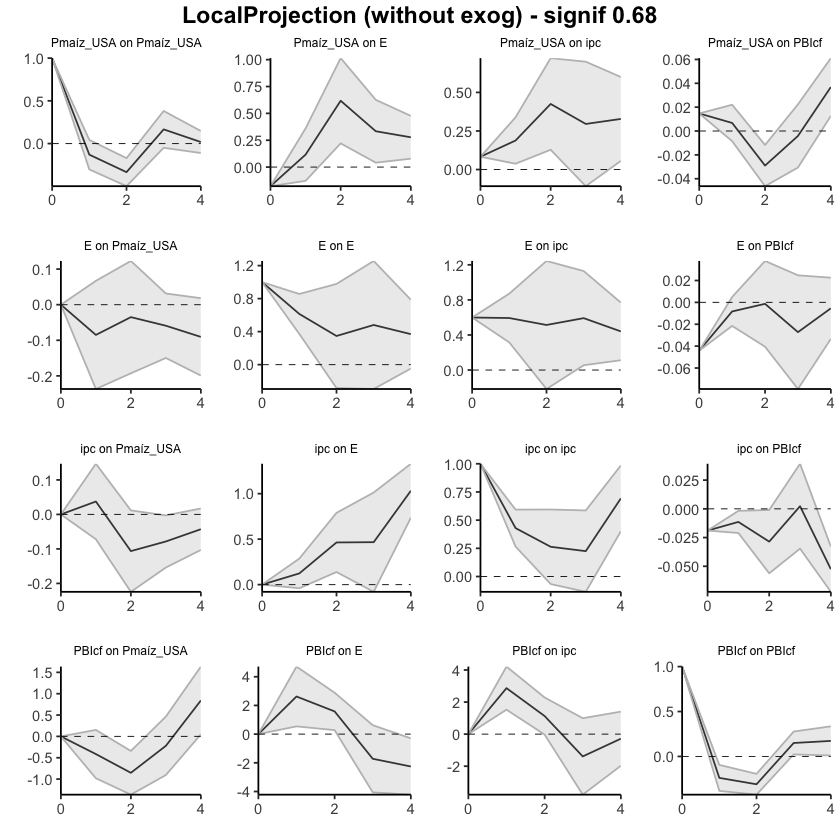

In [92]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1231520,-0.04013813,0.2864421
38,ipc,E,2,0.5867814,0.09822004,1.0753428
39,ipc,E,3,1.0533158,0.01893017,2.0877014
40,ipc,E,4,2.0852130,0.75418018,3.4162458


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,2.6233134,0.5395638,4.707063
53,PBIcf,E,2,4.2059353,0.8183551,7.593516
54,PBIcf,E,3,2.4877165,-3.2413195,8.216752
55,PBIcf,E,4,0.2313518,-7.4606462,7.923350


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,-0.17776825,-0.17776825,-0.1777683
2,Pmaíz_USA,E,1,-0.06194718,-0.30596679,0.1820724
3,Pmaíz_USA,E,2,0.55558386,-0.08518132,1.1963490
4,Pmaíz_USA,E,3,0.88919467,-0.04408955,1.8224789
5,Pmaíz_USA,E,4,1.16648042,0.03402371,2.2989371


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.014727752,0.01472775,0.01472775
12,Pmaíz_USA,PBIcf,1,0.021484691,0.00622178,0.03674760
13,Pmaíz_USA,PBIcf,2,-0.007494717,-0.04003186,0.02504243
14,Pmaíz_USA,PBIcf,3,-0.011630541,-0.07065041,0.04738933
15,Pmaíz_USA,PBIcf,4,0.025251953,-0.05799415,0.10849805


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.00000000
17,E,Pmaíz_USA,1,-0.08493801,-0.2368582,0.06698215
18,E,Pmaíz_USA,2,-0.11988971,-0.4296215,0.18984208
19,E,Pmaíz_USA,3,-0.17898286,-0.5792919,0.22132615
20,E,Pmaíz_USA,4,-0.26946527,-0.7784973,0.23956671


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.03740491,-0.07199802,0.1468078
33,ipc,Pmaíz_USA,2,-0.06895403,-0.29642291,0.1585149
34,ipc,Pmaíz_USA,3,-0.14738901,-0.45039832,0.1556203
35,ipc,Pmaíz_USA,4,-0.19025388,-0.55341048,0.1729027


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.4142730,-0.9805358,0.1519897
48,PBIcf,Pmaíz_USA,2,-1.2673518,-2.3450676,-0.1896360
49,PBIcf,Pmaíz_USA,3,-1.4881981,-3.2508473,0.2744510
50,PBIcf,Pmaíz_USA,4,-0.6465556,-3.2023244,1.9092131


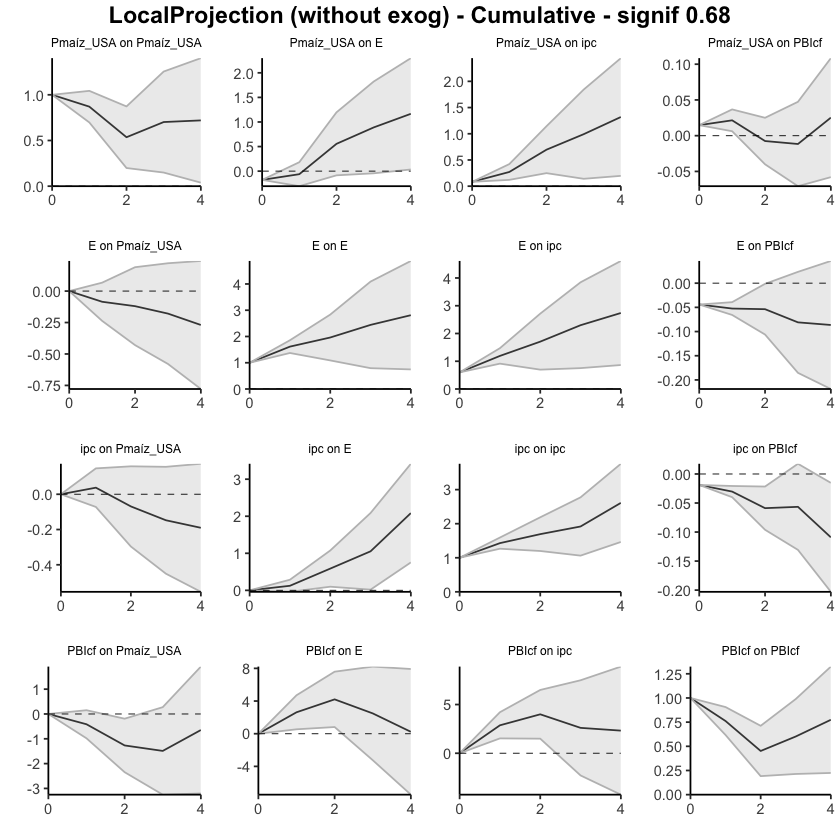

In [93]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1793683,-0.03383309,0.3925697
38,ipc,E,2,0.3986001,0.09612391,0.7010762
39,ipc,E,3,0.2507545,-0.12557347,0.6270825
40,ipc,E,4,0.9224028,0.60076843,1.2440372


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.00000000
52,PBIcf,E,1,2.693172,0.5965597,4.78978371
53,PBIcf,E,2,2.169960,0.9055679,3.43435220
54,PBIcf,E,3,-1.127383,-2.8441142,0.58934902
55,PBIcf,E,4,-1.983414,-3.8693373,-0.09749085


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4820745,-0.4820745,-0.48207451
2,Ptrigo_USA,E,1,-0.2271376,-0.3581044,-0.09617071
3,Ptrigo_USA,E,2,0.8150231,0.4871831,1.14286313
4,Ptrigo_USA,E,3,1.0306910,0.6932642,1.36811784
5,Ptrigo_USA,E,4,0.6304355,0.5736784,0.68719269


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.001563417,-0.001563417,-0.001563417
12,Ptrigo_USA,PBIcf,1,0.022527714,0.006171708,0.038883720
13,Ptrigo_USA,PBIcf,2,-0.042207243,-0.055905226,-0.028509259
14,Ptrigo_USA,PBIcf,3,-0.009761280,-0.016681357,-0.002841203
15,Ptrigo_USA,PBIcf,4,0.021106243,0.008066339,0.034146147


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.04848336,-0.2178325,0.12086580
18,E,Ptrigo_USA,2,-0.05792059,-0.2572759,0.14143476
19,E,Ptrigo_USA,3,-0.02711757,-0.1121631,0.05792800
20,E,Ptrigo_USA,4,-0.05335724,-0.1523843,0.04566978


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.000000000
32,ipc,Ptrigo_USA,1,0.01656848,-0.0904555,0.123592468
33,ipc,Ptrigo_USA,2,0.02169786,-0.1317433,0.175139050
34,ipc,Ptrigo_USA,3,-0.06622806,-0.1286321,-0.003824044
35,ipc,Ptrigo_USA,4,-0.11714432,-0.1742479,-0.060040740


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.16719355,-0.5976375,0.2632504
48,PBIcf,Ptrigo_USA,2,-0.06773939,-0.5663767,0.4308980
49,PBIcf,Ptrigo_USA,3,-0.06792468,-0.6102452,0.4743958
50,PBIcf,Ptrigo_USA,4,0.25465260,-0.4531495,0.9624547


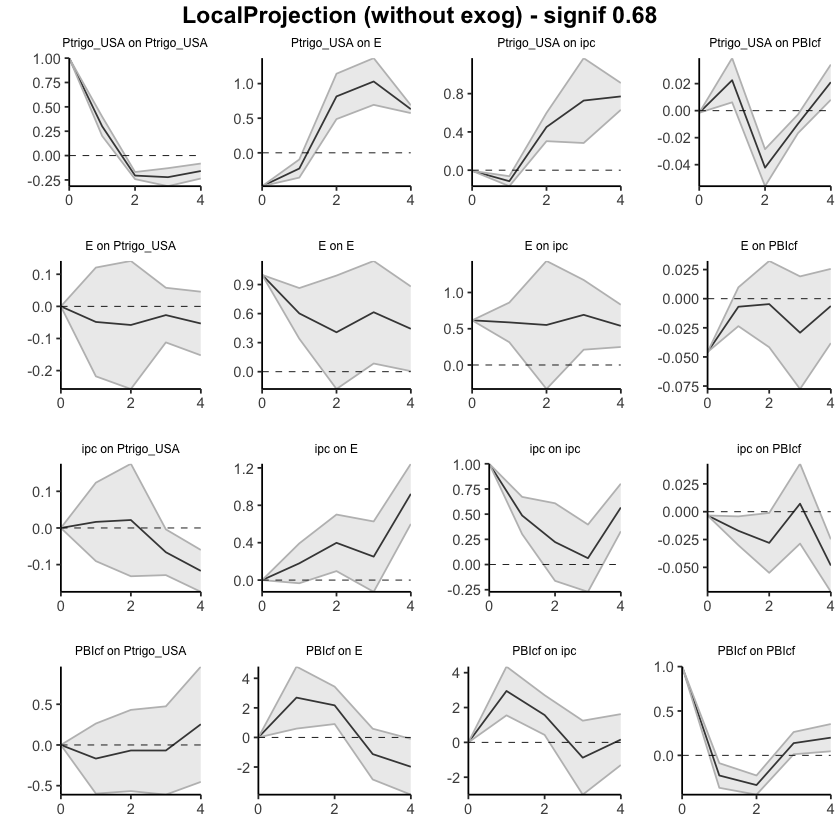

In [94]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1793683,-0.03383309,0.3925697
38,ipc,E,2,0.5779684,0.06229082,1.0936459
39,ipc,E,3,0.8287229,-0.06328265,1.7207284
40,ipc,E,4,1.7511257,0.53748578,2.9647656


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.693172,0.5965597,4.789784
53,PBIcf,E,2,4.863132,1.5021277,8.224136
54,PBIcf,E,3,3.735749,-1.3419865,8.813485
55,PBIcf,E,4,1.752335,-5.2113239,8.715994


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.4820745,-0.4820745,-0.4820745
2,Ptrigo_USA,E,1,-0.7092121,-0.8401789,-0.5782452
3,Ptrigo_USA,E,2,0.1058110,-0.3529958,0.5646179
4,Ptrigo_USA,E,3,1.1365020,0.3402683,1.9327358
5,Ptrigo_USA,E,4,1.7669376,0.9139467,2.6199284


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.001563417,-0.001563417,-0.001563417
12,Ptrigo_USA,PBIcf,1,0.020964297,0.004608291,0.037320303
13,Ptrigo_USA,PBIcf,2,-0.021242946,-0.051296935,0.008811043
14,Ptrigo_USA,PBIcf,3,-0.031004226,-0.067978292,0.005969840
15,Ptrigo_USA,PBIcf,4,-0.009897983,-0.059911953,0.040115987


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.04848336,-0.2178325,0.1208658
18,E,Ptrigo_USA,2,-0.10640394,-0.4751085,0.2623006
19,E,Ptrigo_USA,3,-0.13352151,-0.5872716,0.3202286
20,E,Ptrigo_USA,4,-0.18687875,-0.7396558,0.3658983


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,0.01656848,-0.0904555,0.1235925
33,ipc,Ptrigo_USA,2,0.03826635,-0.2221988,0.2987315
34,ipc,Ptrigo_USA,3,-0.02796172,-0.3508309,0.2949075
35,ipc,Ptrigo_USA,4,-0.14510604,-0.5250788,0.2348667


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.16719355,-0.5976375,0.2632504
48,PBIcf,Ptrigo_USA,2,-0.23493293,-1.1640143,0.6941484
49,PBIcf,Ptrigo_USA,3,-0.30285762,-1.7742595,1.1685442
50,PBIcf,Ptrigo_USA,4,-0.04820502,-2.2274089,2.1309989


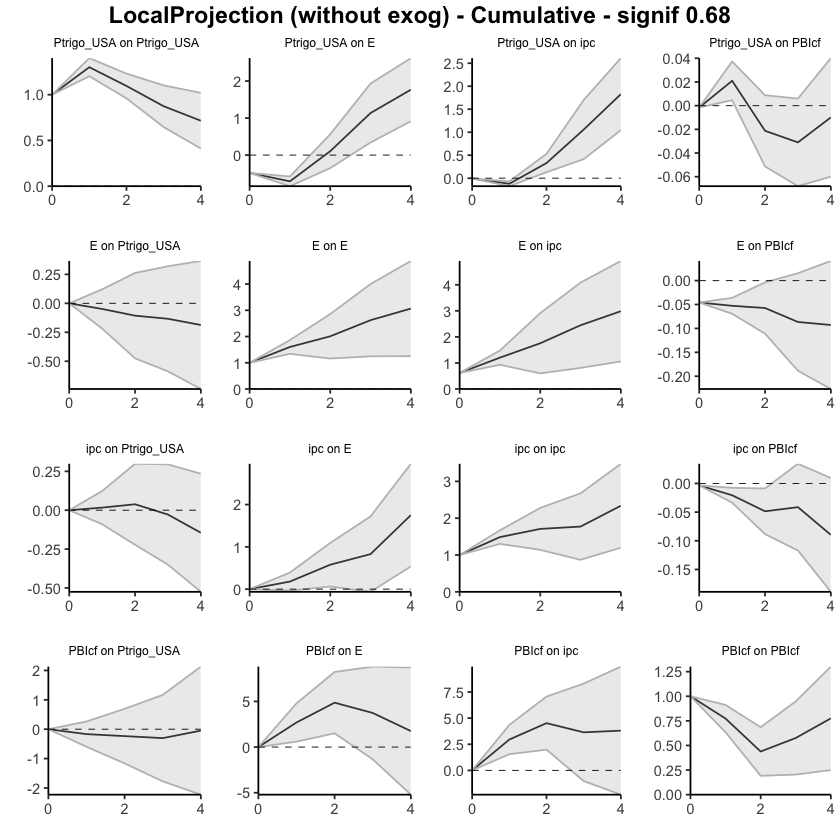

In [95]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1987. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.2641609,0.06717057,0.4611513
13,ipc,E,2,0.5371978,0.17273665,0.9016589
14,ipc,E,3,0.4024775,-0.18829765,0.9932526
15,ipc,E,4,1.0046347,0.63328810,1.3759813


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,3.018303,1.0092730,5.0273325
23,PBIcf,E,2,1.506700,0.1901214,2.8232782
24,PBIcf,E,3,-2.080742,-4.4737985,0.3123147
25,PBIcf,E,4,-2.345254,-4.3245093,-0.3659978


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6042767,0.60427667,0.6042767
2,E,ipc,1,0.5661122,0.35527404,0.7769504
3,E,ipc,2,0.4909317,-0.31001481,1.2918782
4,E,ipc,3,0.6109835,0.13230210,1.0896649
5,E,ipc,4,0.4394319,0.08508347,0.7937802


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIcf,ipc,1,2.9458170,1.5087565,4.3828775
28,PBIcf,ipc,2,1.0485150,-0.1822518,2.2792819
29,PBIcf,ipc,3,-1.7307449,-4.1218375,0.6603477
30,PBIcf,ipc,4,-0.4170579,-2.4320931,1.5979773


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.0448390944,-0.04483909,-0.044839094
7,E,PBIcf,1,-0.0098062838,-0.02439922,0.004786652
8,E,PBIcf,2,0.0004536618,-0.04230965,0.043216969
9,E,PBIcf,3,-0.0245014040,-0.08400703,0.035004218
10,E,PBIcf,4,-0.0055498998,-0.03936013,0.028260327


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.005919492,-0.005919492,-0.0059194919
17,ipc,PBIcf,1,-0.012177456,-0.024235507,-0.0001194052
18,ipc,PBIcf,2,-0.035310376,-0.066404105,-0.0042166475
19,ipc,PBIcf,3,-0.001160430,-0.043832670,0.0415118091
20,ipc,PBIcf,4,-0.051320392,-0.077291672,-0.0253491116


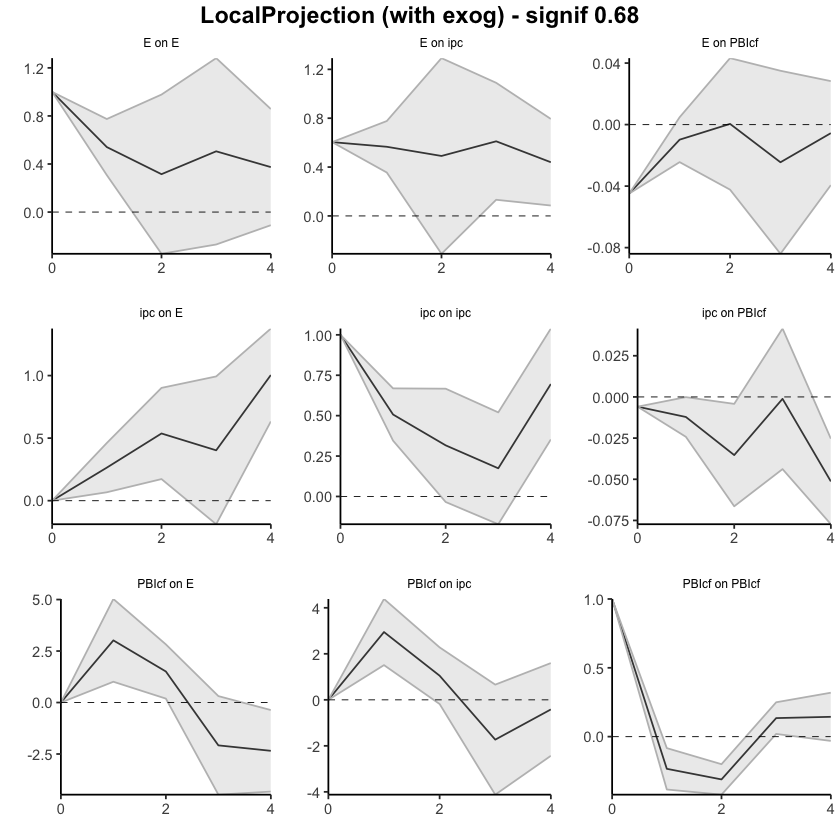

In [96]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.2641609,0.06717057,0.4611513
13,ipc,E,2,0.8013587,0.23990722,1.3628102
14,ipc,E,3,1.2038362,0.05160957,2.3560628
15,ipc,E,4,2.2084709,0.68489767,3.7320441


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.00000000,0.000000,0.000000
22,PBIcf,E,1,3.01830277,1.009273,5.027333
23,PBIcf,E,2,4.52500257,1.199394,7.850611
24,PBIcf,E,3,2.44426064,-3.274404,8.162925
25,PBIcf,E,4,0.09900711,-7.598913,7.796928


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6042767,0.6042767,0.6042767
2,E,ipc,1,1.1703889,0.9595507,1.3812271
3,E,ipc,2,1.6613206,0.6495359,2.6731053
4,E,ipc,3,2.2723041,0.7818380,3.7627701
5,E,ipc,4,2.7117359,0.8669215,4.5565504


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.945817,1.508757,4.382878
28,PBIcf,ipc,2,3.994332,1.326505,6.662159
29,PBIcf,ipc,3,2.263587,-2.795333,7.322507
30,PBIcf,ipc,4,1.846529,-5.227426,8.920484


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04483909,-0.04483909,-0.044839094
7,E,PBIcf,1,-0.05464538,-0.06923831,-0.040052442
8,E,PBIcf,2,-0.05419172,-0.11154796,0.003164527
9,E,PBIcf,3,-0.07869312,-0.19555499,0.038168745
10,E,PBIcf,4,-0.08424302,-0.23491511,0.066429072


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.005919492,-0.005919492,-0.005919492
17,ipc,PBIcf,1,-0.018096948,-0.030154999,-0.006038897
18,ipc,PBIcf,2,-0.053407324,-0.096559104,-0.010255545
19,ipc,PBIcf,3,-0.054567755,-0.140391774,0.031256264
20,ipc,PBIcf,4,-0.105888146,-0.217683446,0.005907153


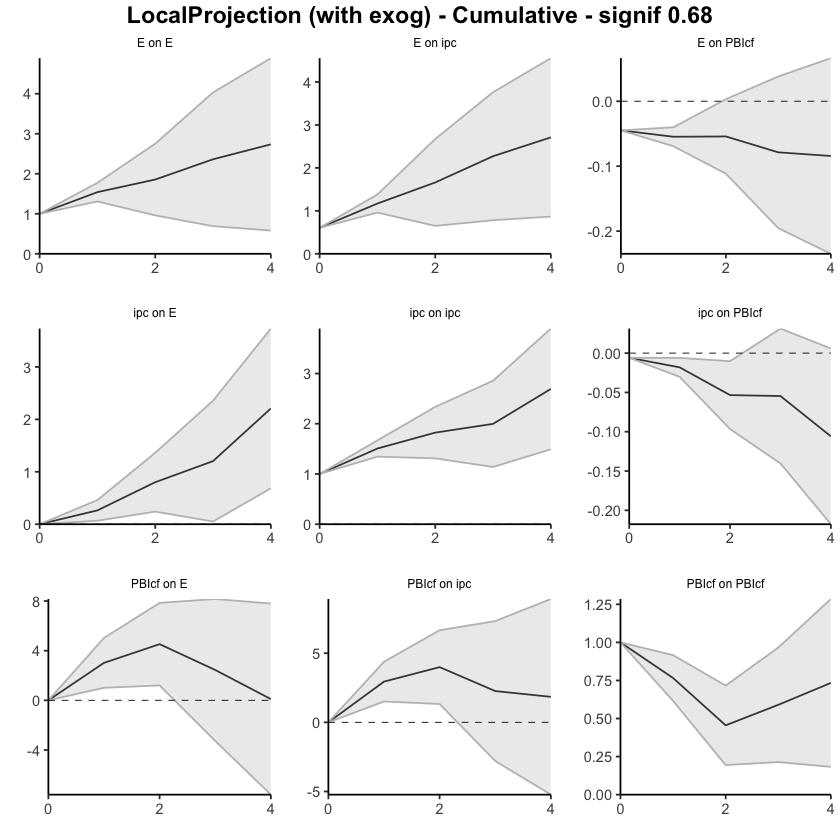

In [97]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.00000000
12,ipc,E,1,-0.058039772,-0.3346258,0.21854626
13,ipc,E,2,0.001502662,-0.2450839,0.24808924
14,ipc,E,3,-0.279144200,-0.5630853,0.00479689
15,ipc,E,4,0.002089040,-0.2968711,0.30104921


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.00000000,0.000000
22,PBIcf,E,1,3.468842,1.74564618,5.192038
23,PBIcf,E,2,1.207254,0.01869237,2.395815
24,PBIcf,E,3,-2.669285,-4.42447692,-0.914094
25,PBIcf,E,4,-2.546933,-3.98037740,-1.113489


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6209002,0.6209002,0.6209002
2,E,ipc,1,0.6490452,0.4506525,0.8474379
3,E,ipc,2,0.4712118,0.0834872,0.8589364
4,E,ipc,3,0.5407978,-0.4607189,1.5423145
5,E,ipc,4,0.5506500,0.1779332,0.9233668


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIcf,ipc,1,3.1506728,1.7411387,4.56020683
28,PBIcf,ipc,2,0.7346531,-0.3156507,1.78495689
29,PBIcf,ipc,3,-2.1810285,-4.4344851,0.07242804
30,PBIcf,ipc,4,-0.1012726,-1.2893774,1.08683225


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.041511821,-0.04151182,-0.04151182
7,E,PBIcf,1,-0.008971473,-0.03429279,0.01634985
8,E,PBIcf,2,0.006488023,-0.04585365,0.05882969
9,E,PBIcf,3,-0.019986781,-0.08007887,0.04010531
10,E,PBIcf,4,-0.006229747,-0.05308277,0.04062328


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.033715554,-0.03371555,-0.03371555
17,ipc,PBIcf,1,0.039647738,0.01980604,0.05948944
18,ipc,PBIcf,2,-0.027012073,-0.07380533,0.01978118
19,ipc,PBIcf,3,0.014481731,-0.03117184,0.06013530
20,ipc,PBIcf,4,0.004507164,-0.03635134,0.04536567


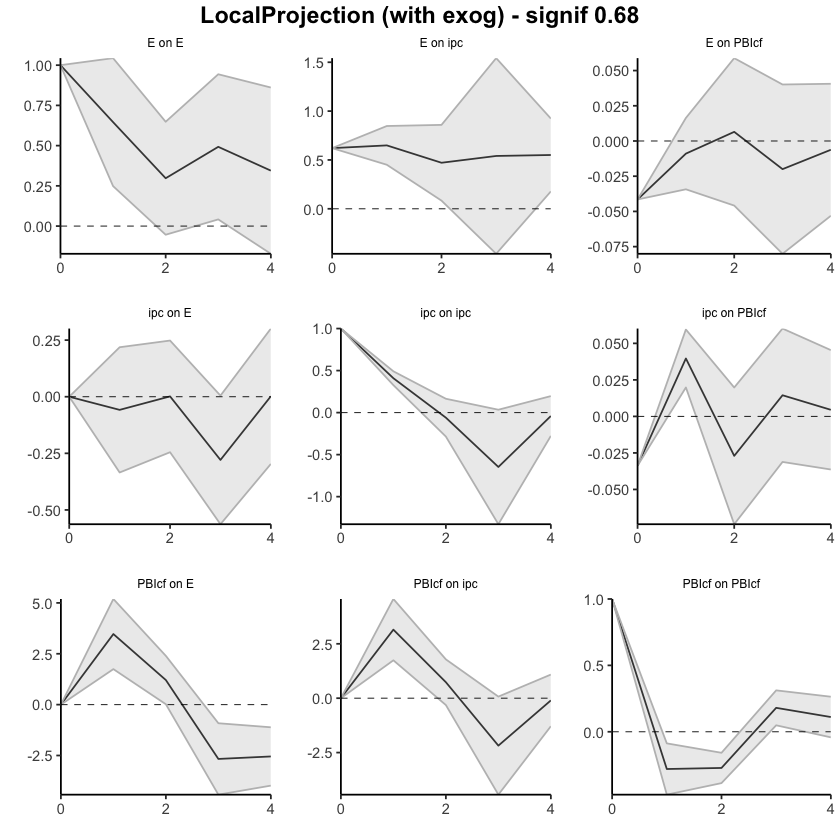

In [99]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.05803977,-0.3346258,0.2185463
13,ipc,E,2,-0.05653711,-0.5797097,0.4666355
14,ipc,E,3,-0.33568131,-1.1427950,0.4714324
15,ipc,E,4,-0.33359227,-1.4396661,0.7724816


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.000000,0.000000
22,PBIcf,E,1,3.4688419,1.745646,5.192038
23,PBIcf,E,2,4.6760955,1.764339,7.587853
24,PBIcf,E,3,2.0068101,-2.660138,6.673759
25,PBIcf,E,4,-0.5401233,-6.640516,5.560269


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6209002,0.6209002,0.6209002
2,E,ipc,1,1.2699453,1.0715526,1.4683380
3,E,ipc,2,1.7411572,1.1550398,2.3272745
4,E,ipc,3,2.2819550,0.6943210,3.8695890
5,E,ipc,4,2.8326050,0.8722541,4.7929558


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,3.150673,1.741139,4.560207
28,PBIcf,ipc,2,3.885326,1.425488,6.345164
29,PBIcf,ipc,3,1.704297,-3.008997,6.417592
30,PBIcf,ipc,4,1.603025,-4.298374,7.504424


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04151182,-0.04151182,-0.04151182
7,E,PBIcf,1,-0.05048329,-0.07580462,-0.02516197
8,E,PBIcf,2,-0.04399527,-0.12165826,0.03366772
9,E,PBIcf,3,-0.06398205,-0.20173713,0.07377303
10,E,PBIcf,4,-0.07021180,-0.25481991,0.11439631


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.033715554,-0.03371555,-0.03371555
17,ipc,PBIcf,1,0.005932185,-0.01390951,0.02577388
18,ipc,PBIcf,2,-0.021079889,-0.08771485,0.04555507
19,ipc,PBIcf,3,-0.006598157,-0.11888668,0.10569037
20,ipc,PBIcf,4,-0.002090993,-0.15523802,0.15105604


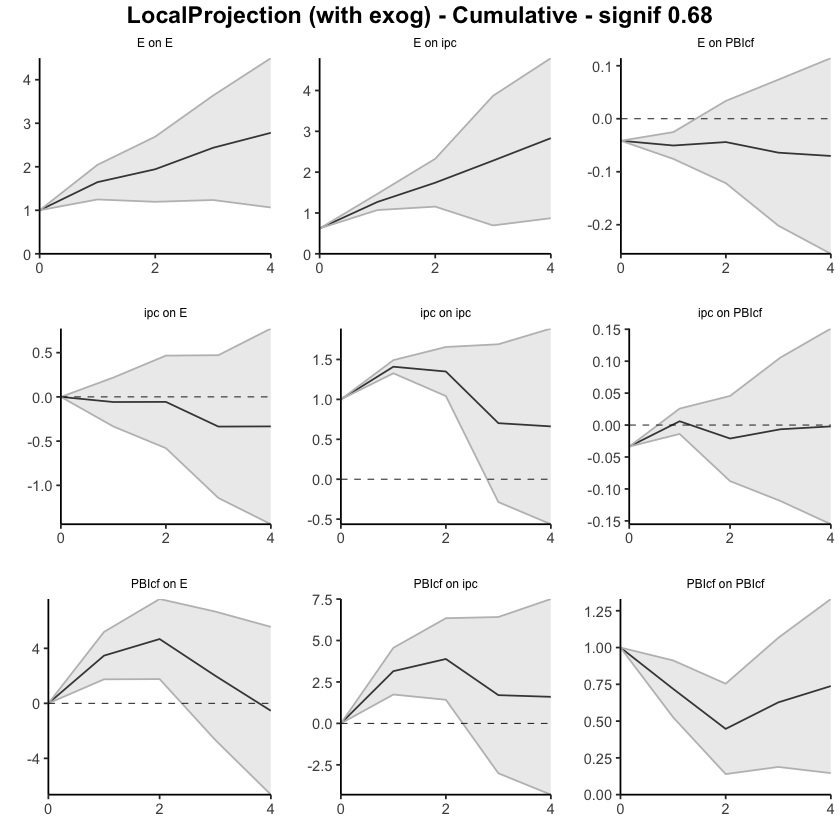

In [98]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1361585,-0.03746296,0.3097799
13,ipc,E,2,0.4714761,0.13974044,0.8032118
14,ipc,E,3,0.4580154,-0.09941790,1.0154487
15,ipc,E,4,1.0207100,0.71433042,1.3270897


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,2.623313,0.5395638,4.7070629
23,PBIcf,E,2,1.582622,0.2787913,2.8864527
24,PBIcf,E,3,-1.718219,-4.0596746,0.6232369
25,PBIcf,E,4,-2.256365,-4.2193267,-0.2934026


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5884879,0.58848786,0.5884879
2,E,ipc,1,0.5869172,0.31089134,0.8629430
3,E,ipc,2,0.5104649,-0.21558081,1.2365105
4,E,ipc,3,0.5904088,0.05843524,1.1223824
5,E,ipc,4,0.4331544,0.10873224,0.7575765


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.00000000,0.0000000
27,PBIcf,ipc,1,2.8683371,1.52533309,4.2113411
28,PBIcf,ipc,2,1.1283407,-0.02852222,2.2852037
29,PBIcf,ipc,3,-1.3900773,-3.77367084,0.9935162
30,PBIcf,ipc,4,-0.2843693,-1.97208880,1.4033501


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.0445205690,-0.04452057,-0.044520569
7,E,PBIcf,1,-0.0080437348,-0.02107764,0.004990169
8,E,PBIcf,2,-0.0008375154,-0.03966819,0.037993158
9,E,PBIcf,3,-0.0273317850,-0.07883186,0.024168293
10,E,PBIcf,4,-0.0049623482,-0.03262477,0.022700076


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.013950406,-0.01395041,-0.013950406
17,ipc,PBIcf,1,-0.012582143,-0.02294536,-0.002218923
18,ipc,PBIcf,2,-0.030084930,-0.05823280,-0.001937057
19,ipc,PBIcf,3,0.003031256,-0.03453689,0.040599400
20,ipc,PBIcf,4,-0.051710091,-0.07219132,-0.031228867


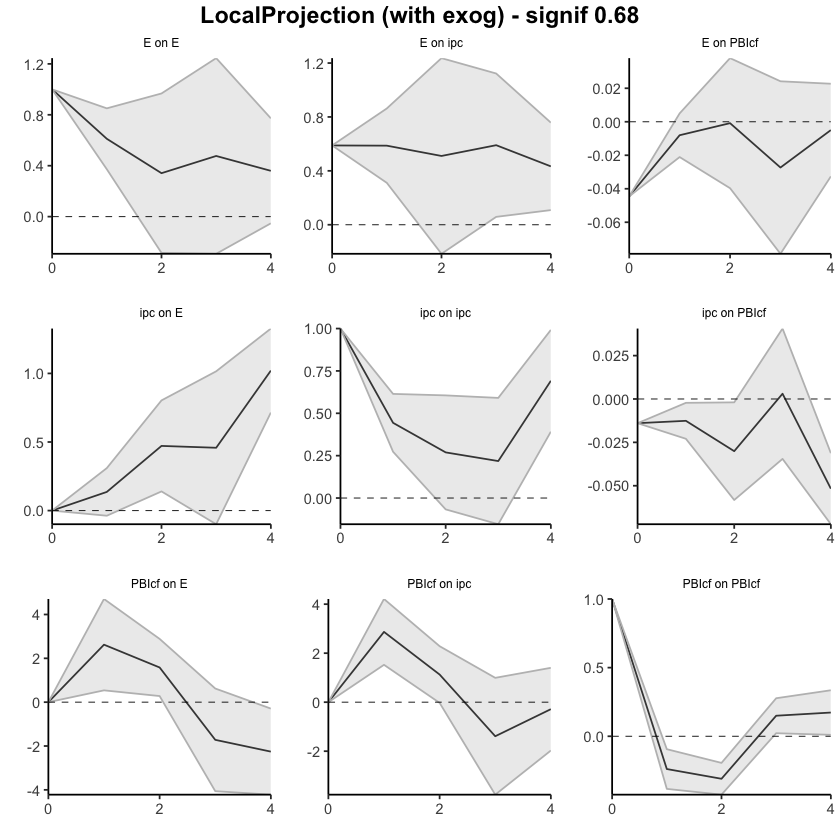

In [100]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.000000000,0.0000000
12,ipc,E,1,0.1361585,-0.037462956,0.3097799
13,ipc,E,2,0.6076346,0.102277482,1.1129917
14,ipc,E,3,1.0656500,0.002859579,2.1284404
15,ipc,E,4,2.0863600,0.717189998,3.4555301


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,2.6233134,0.5395638,4.707063
23,PBIcf,E,2,4.2059353,0.8183551,7.593516
24,PBIcf,E,3,2.4877165,-3.2413195,8.216752
25,PBIcf,E,4,0.2313518,-7.4606462,7.923350


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5884879,0.5884879,0.5884879
2,E,ipc,1,1.1754050,0.8993792,1.4514309
3,E,ipc,2,1.6858699,0.6837984,2.6879414
4,E,ipc,3,2.2762787,0.7422336,3.8103238
5,E,ipc,4,2.7094331,0.8509659,4.5679004


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.868337,1.525333,4.211341
28,PBIcf,ipc,2,3.996678,1.496811,6.496545
29,PBIcf,ipc,3,2.606601,-2.276860,7.490061
30,PBIcf,ipc,4,2.322231,-4.248949,8.893411


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04452057,-0.04452057,-0.044520569
7,E,PBIcf,1,-0.05256430,-0.06559821,-0.039530400
8,E,PBIcf,2,-0.05340182,-0.10526640,-0.001537242
9,E,PBIcf,3,-0.08073360,-0.18409826,0.022631051
10,E,PBIcf,4,-0.08569595,-0.21672303,0.045331127


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.01395041,-0.01395041,-0.013950406
17,ipc,PBIcf,1,-0.02653255,-0.03689577,-0.016169329
18,ipc,PBIcf,2,-0.05661748,-0.09512857,-0.018106386
19,ipc,PBIcf,3,-0.05358622,-0.12966546,0.022493014
20,ipc,PBIcf,4,-0.10529631,-0.20185678,-0.008735853


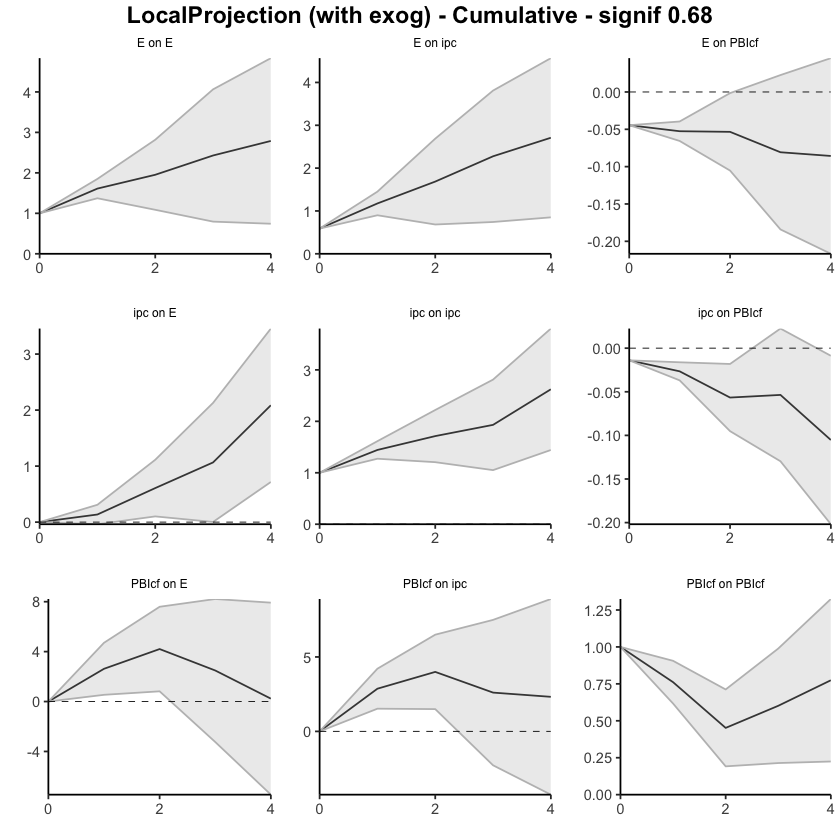

In [101]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1563865,-0.03892374,0.3516968
13,ipc,E,2,0.3800830,0.08839638,0.6717697
14,ipc,E,3,0.2603749,-0.10130364,0.6220534
15,ipc,E,4,0.9393280,0.63378684,1.2448691


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.00000000
22,PBIcf,E,1,2.693172,0.5965597,4.78978371
23,PBIcf,E,2,2.169960,0.9055679,3.43435220
24,PBIcf,E,3,-1.127383,-2.8441142,0.58934902
25,PBIcf,E,4,-1.983414,-3.8693373,-0.09749085


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5921334,0.5921334,0.5921334
2,E,ipc,1,0.5814606,0.3097817,0.8531394
3,E,ipc,2,0.5494725,-0.3265261,1.4254712
4,E,ipc,3,0.6886524,0.2120983,1.1652065
5,E,ipc,4,0.5262354,0.2378770,0.8145938


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.9510867,1.5520805,4.350093
28,PBIcf,ipc,2,1.5686402,0.4292922,2.707988
29,PBIcf,ipc,3,-0.8777965,-3.0007506,1.245158
30,PBIcf,ipc,4,0.1623383,-1.2990259,1.623702


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.043841571,-0.04384157,-0.043841571
7,E,PBIcf,1,-0.006922709,-0.02353663,0.009691209
8,E,PBIcf,2,-0.004600267,-0.04120499,0.032004455
9,E,PBIcf,3,-0.029117116,-0.07683736,0.018603134
10,E,PBIcf,4,-0.004733231,-0.03632883,0.026862372


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.011902494,-0.01190249,-0.0119024942
17,ipc,PBIcf,1,-0.015221503,-0.02698204,-0.0034609682
18,ipc,PBIcf,2,-0.025155858,-0.05113291,0.0008211966
19,ipc,PBIcf,3,0.006024272,-0.02876687,0.0408154159
20,ipc,PBIcf,4,-0.050091452,-0.07237673,-0.0278061746


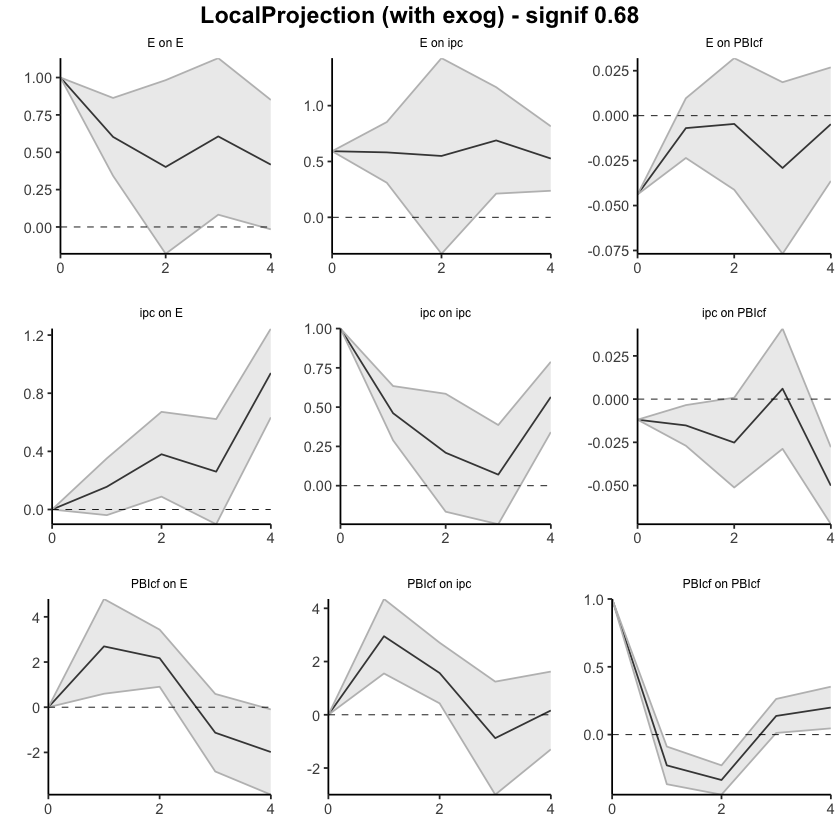

In [102]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1563865,-0.03892374,0.3516968
13,ipc,E,2,0.5364696,0.04947264,1.0234665
14,ipc,E,3,0.7968444,-0.05183100,1.6455199
15,ipc,E,4,1.7361724,0.58195583,2.8903890


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.693172,0.5965597,4.789784
23,PBIcf,E,2,4.863132,1.5021277,8.224136
24,PBIcf,E,3,3.735749,-1.3419865,8.813485
25,PBIcf,E,4,1.752335,-5.2113239,8.715994


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5921334,0.5921334,0.5921334
2,E,ipc,1,1.1735940,0.9019151,1.4452728
3,E,ipc,2,1.7230665,0.5753890,2.8707440
4,E,ipc,3,2.4117189,0.7874873,4.0359505
5,E,ipc,4,2.9379543,1.0253643,4.8505443


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.951087,1.552081,4.350093
28,PBIcf,ipc,2,4.519727,1.981373,7.058081
29,PBIcf,ipc,3,3.641930,-1.019378,8.303239
30,PBIcf,ipc,4,3.804269,-2.318404,9.926941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.04384157,-0.04384157,-0.043841571
7,E,PBIcf,1,-0.05076428,-0.06737820,-0.034150362
8,E,PBIcf,2,-0.05536455,-0.10858319,-0.002145907
9,E,PBIcf,3,-0.08448166,-0.18542055,0.016457227
10,E,PBIcf,4,-0.08921489,-0.22174939,0.043319599


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.01190249,-0.01190249,-0.011902494
17,ipc,PBIcf,1,-0.02712400,-0.03888453,-0.015363462
18,ipc,PBIcf,2,-0.05227986,-0.09001744,-0.014542266
19,ipc,PBIcf,3,-0.04625558,-0.11878432,0.026273150
20,ipc,PBIcf,4,-0.09634704,-0.19116105,-0.001533024


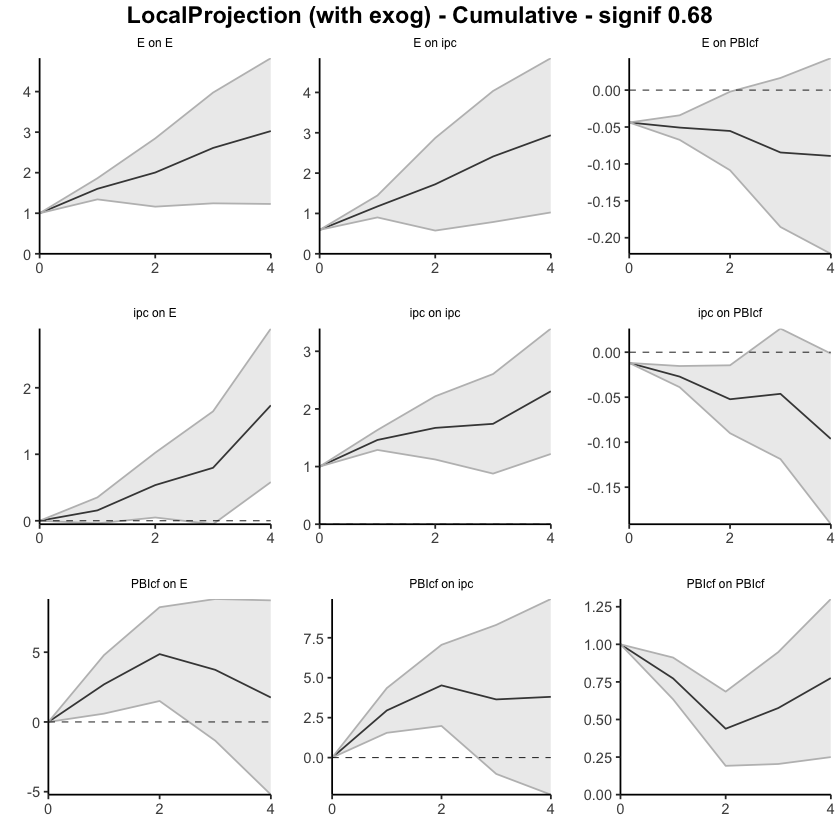

In [103]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

### 1935-1990. Todas endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1563739,-0.07636171,0.3891096
38,ipc,E,2,0.5699999,0.17835425,0.9616456
39,ipc,E,3,0.7144991,0.14604210,1.2829562
40,ipc,E,4,1.4037180,1.12275012,1.6846859


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.00000000
52,PBIcf,E,1,2.1493247,-0.2154009,4.51405019
53,PBIcf,E,2,2.4696987,0.9737608,3.96563672
54,PBIcf,E,3,0.3768888,-2.9567676,3.71054517
55,PBIcf,E,4,-2.3351221,-4.7277655,0.05752128


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.56141553,-0.5614155,-0.5614155
2,Psoja_USA,E,1,-0.05256501,-0.6016420,0.4965120
3,Psoja_USA,E,2,0.33622085,0.2641577,0.4082840
4,Psoja_USA,E,3,-0.02291269,-0.5263565,0.4805312
5,Psoja_USA,E,4,-0.32820399,-0.5531766,-0.1032314


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.04985414,0.04985414,0.049854142
12,Psoja_USA,PBIcf,1,-0.01907798,-0.04210703,0.003951059
13,Psoja_USA,PBIcf,2,-0.02143066,-0.02583216,-0.017029150
14,Psoja_USA,PBIcf,3,0.03458570,0.01348022,0.055691178
15,Psoja_USA,PBIcf,4,0.04245814,0.02508341,0.059832863


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.0000000,0.00000000
17,E,Psoja_USA,1,-0.006308251,-0.1564017,0.14378524
18,E,Psoja_USA,2,-0.028528318,-0.1465364,0.08947979
19,E,Psoja_USA,3,-0.036420427,-0.1745336,0.10169274
20,E,Psoja_USA,4,-0.042015645,-0.1498194,0.06578809


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Psoja_USA,1,-0.12687925,-0.22972489,-0.02403361
33,ipc,Psoja_USA,2,-0.07101557,-0.15472700,0.01269585
34,ipc,Psoja_USA,3,-0.03973276,-0.12983299,0.05036746
35,ipc,Psoja_USA,4,0.02270876,-0.05569297,0.10111048


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Psoja_USA,1,-0.03453322,-0.5341290,0.4650626
48,PBIcf,Psoja_USA,2,-1.17070515,-1.7580172,-0.5833931
49,PBIcf,Psoja_USA,3,0.17058441,-0.5832871,0.9244559
50,PBIcf,Psoja_USA,4,1.30049894,0.5437058,2.0572921


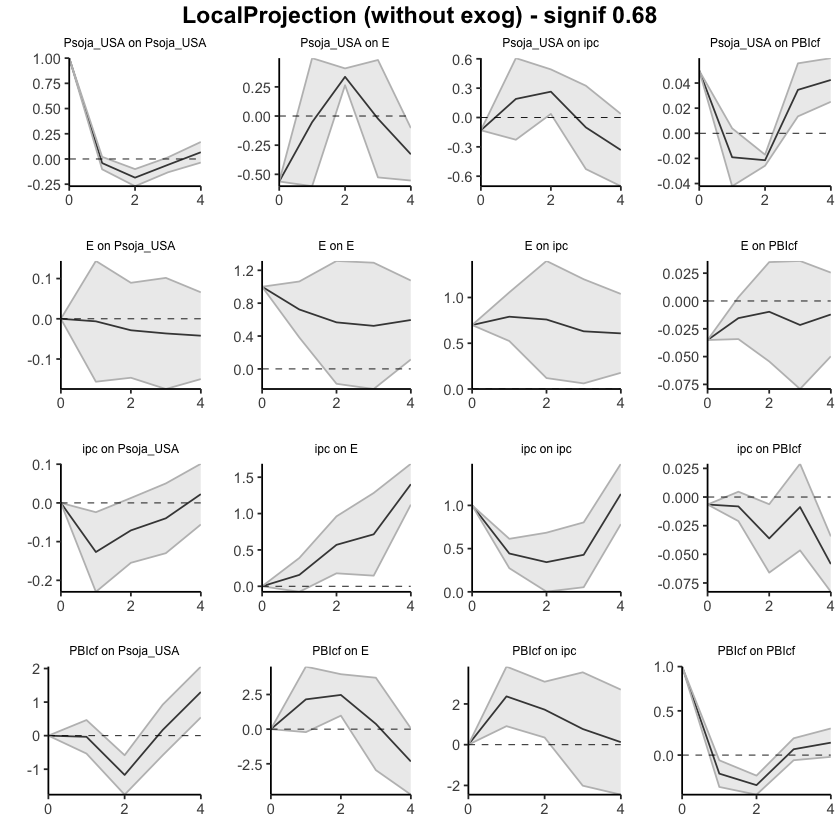

In [104]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Psoja_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1563739,-0.07636171,0.3891096
38,ipc,E,2,0.7263739,0.10199254,1.3507552
39,ipc,E,3,1.4408730,0.24803464,2.6337114
40,ipc,E,4,2.8445910,1.37078476,4.3183973


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.149325,-0.2154009,4.514050
53,PBIcf,E,2,4.619023,0.7583599,8.479687
54,PBIcf,E,3,4.995912,-2.1984077,12.190232
55,PBIcf,E,4,2.660790,-6.9261732,12.247753


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,0,-0.5614155,-0.5614155,-0.56141553
2,Psoja_USA,E,1,-0.6139805,-1.1630575,-0.06490354
3,Psoja_USA,E,2,-0.2777597,-0.8988998,0.34338043
4,Psoja_USA,E,3,-0.3006724,-1.4252564,0.82391158
5,Psoja_USA,E,4,-0.6288764,-1.9784330,0.72068020


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Psoja_USA,PBIcf,0,0.049854142,0.049854142,0.04985414
12,Psoja_USA,PBIcf,1,0.030776158,0.007747115,0.05380520
13,Psoja_USA,PBIcf,2,0.009345503,-0.018085045,0.03677605
14,Psoja_USA,PBIcf,3,0.043931204,-0.004604822,0.09246723
15,Psoja_USA,PBIcf,4,0.086389343,0.020478593,0.15230009


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Psoja_USA,0,0.000000000,0.0000000,0.0000000
17,E,Psoja_USA,1,-0.006308251,-0.1564017,0.1437852
18,E,Psoja_USA,2,-0.034836568,-0.3029382,0.2332650
19,E,Psoja_USA,3,-0.071256996,-0.4774718,0.3349578
20,E,Psoja_USA,4,-0.113272641,-0.6272911,0.4007459


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Psoja_USA,0,0.0000000,0.0000000,0.00000000
32,ipc,Psoja_USA,1,-0.1268793,-0.2297249,-0.02403361
33,ipc,Psoja_USA,2,-0.1978948,-0.3844519,-0.01133776
34,ipc,Psoja_USA,3,-0.2376276,-0.5142849,0.03902970
35,ipc,Psoja_USA,4,-0.2149188,-0.5699778,0.14014018


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Psoja_USA,0,0.00000000,0.000000,0.0000000
47,PBIcf,Psoja_USA,1,-0.03453322,-0.534129,0.4650626
48,PBIcf,Psoja_USA,2,-1.20523837,-2.292146,-0.1183304
49,PBIcf,Psoja_USA,3,-1.03465395,-2.875433,0.8061255
50,PBIcf,Psoja_USA,4,0.26584499,-2.331728,2.8634175


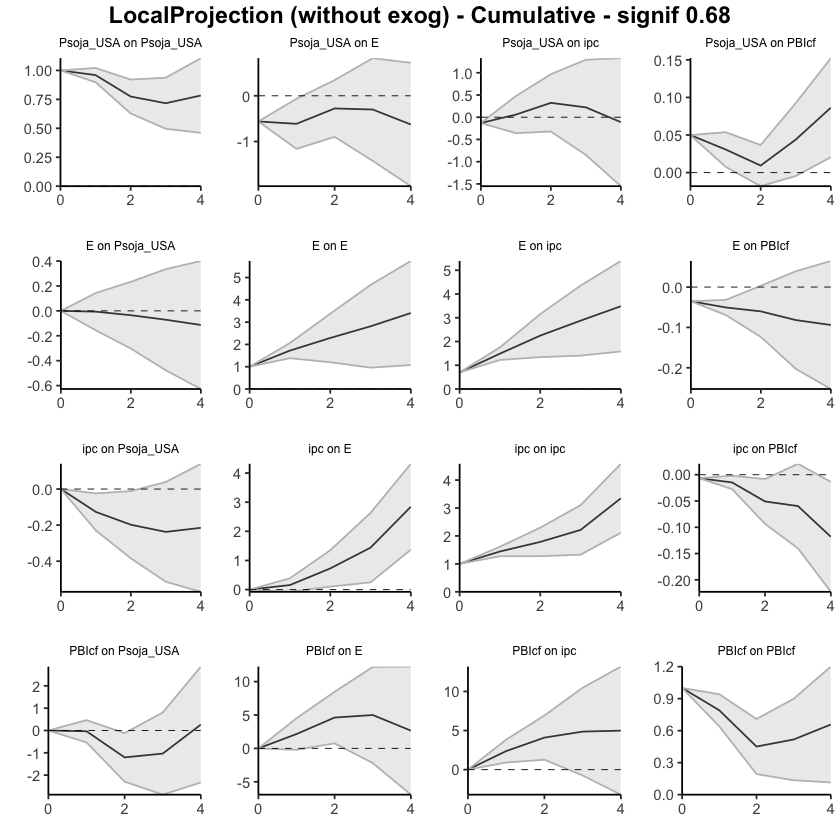

In [105]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Psoja_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1215527,-0.07990691,0.3230124
38,ipc,E,2,0.5923932,0.22657634,0.9582101
39,ipc,E,3,0.7572971,0.17490990,1.3396843
40,ipc,E,4,1.3697600,1.12382191,1.6156980


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.000000
52,PBIcf,E,1,2.3147257,0.1086941,4.520757
53,PBIcf,E,2,2.8438506,1.3197249,4.367976
54,PBIcf,E,3,0.4723649,-2.6210279,3.565758
55,PBIcf,E,4,-2.5965476,-4.9747272,-0.218368


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.04065510,0.04065510,0.0406551
2,Pmaíz_USA,E,1,0.51182263,0.09522495,0.9284203
3,Pmaíz_USA,E,2,0.55797051,0.02259831,1.0933427
4,Pmaíz_USA,E,3,0.04071676,-0.73698121,0.8184147
5,Pmaíz_USA,E,4,0.19503637,-0.22742464,0.6174974


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.0069273278,0.006927328,0.006927328
12,Pmaíz_USA,PBIcf,1,-0.0029965158,-0.021948296,0.015955265
13,Pmaíz_USA,PBIcf,2,-0.0245253886,-0.050307512,0.001256734
14,Pmaíz_USA,PBIcf,3,0.0005898957,-0.042710063,0.043889855
15,Pmaíz_USA,PBIcf,4,0.0353836936,0.006584657,0.064182731


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.04346377,-0.1988215,0.1118940
18,E,Pmaíz_USA,2,-0.04244196,-0.1855999,0.1007160
19,E,Pmaíz_USA,3,-0.01549399,-0.1338453,0.1028573
20,E,Pmaíz_USA,4,-0.02707650,-0.1681277,0.1139747


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.00000000
32,ipc,Pmaíz_USA,1,0.04273010,-0.06981738,0.15527758
33,ipc,Pmaíz_USA,2,-0.08201847,-0.17930870,0.01527176
34,ipc,Pmaíz_USA,3,-0.01746104,-0.09862088,0.06369879
35,ipc,Pmaíz_USA,4,0.04170894,-0.04265808,0.12607596


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.2982750,-0.8443688,0.2478188
48,PBIcf,Pmaíz_USA,2,-0.6715610,-1.2111465,-0.1319754
49,PBIcf,Pmaíz_USA,3,-0.5175573,-1.2710669,0.2359523
50,PBIcf,Pmaíz_USA,4,1.0011473,0.2820959,1.7201987


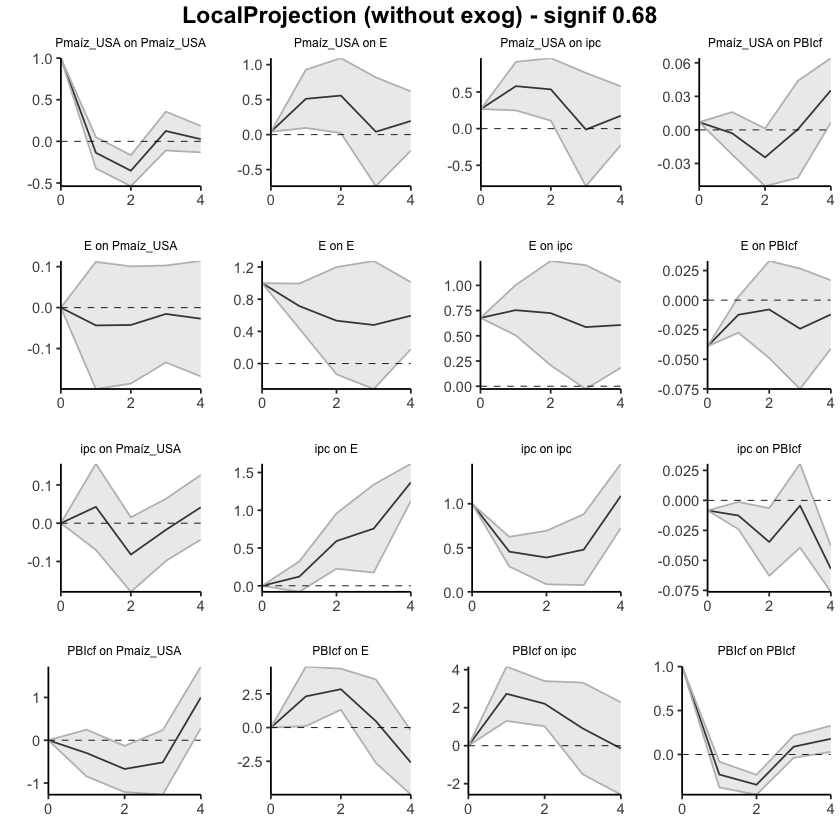

In [106]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Pmaíz_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1215527,-0.07990691,0.3230124
38,ipc,E,2,0.7139459,0.14666944,1.2812224
39,ipc,E,3,1.4712430,0.32157934,2.6209067
40,ipc,E,4,2.8410030,1.44540125,4.2366047


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.314726,0.1086941,4.520757
53,PBIcf,E,2,5.158576,1.4284190,8.888734
54,PBIcf,E,3,5.630941,-1.1926089,12.454491
55,PBIcf,E,4,3.034394,-6.1673361,12.236123


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Pmaíz_USA,E,0,0.0406551,0.0406551,0.0406551
2,Pmaíz_USA,E,1,0.5524777,0.1358800,0.9690754
3,Pmaíz_USA,E,2,1.1104482,0.1584783,2.0624181
4,Pmaíz_USA,E,3,1.1511650,-0.5785029,2.8808328
5,Pmaíz_USA,E,4,1.3462014,-0.8059275,3.4983302


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Pmaíz_USA,PBIcf,0,0.006927328,0.006927328,0.006927328
12,Pmaíz_USA,PBIcf,1,0.003930812,-0.015020969,0.022882592
13,Pmaíz_USA,PBIcf,2,-0.020594577,-0.065328480,0.024139327
14,Pmaíz_USA,PBIcf,3,-0.020004681,-0.108038544,0.068029182
15,Pmaíz_USA,PBIcf,4,0.015379013,-0.101453887,0.132211912


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Pmaíz_USA,0,0.00000000,0.0000000,0.0000000
17,E,Pmaíz_USA,1,-0.04346377,-0.1988215,0.1118940
18,E,Pmaíz_USA,2,-0.08590572,-0.3844214,0.2126099
19,E,Pmaíz_USA,3,-0.10139971,-0.5182666,0.3154672
20,E,Pmaíz_USA,4,-0.12847621,-0.6863943,0.4294419


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Pmaíz_USA,0,0.00000000,0.00000000,0.0000000
32,ipc,Pmaíz_USA,1,0.04273010,-0.06981738,0.1552776
33,ipc,Pmaíz_USA,2,-0.03928837,-0.24912607,0.1705493
34,ipc,Pmaíz_USA,3,-0.05674941,-0.34774695,0.2342481
35,ipc,Pmaíz_USA,4,-0.01504047,-0.39040504,0.3603241


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Pmaíz_USA,0,0.000000,0.0000000,0.0000000
47,PBIcf,Pmaíz_USA,1,-0.298275,-0.8443688,0.2478188
48,PBIcf,Pmaíz_USA,2,-0.969836,-2.0555153,0.1158434
49,PBIcf,Pmaíz_USA,3,-1.487393,-3.3265822,0.3517956
50,PBIcf,Pmaíz_USA,4,-0.486246,-3.0444863,2.0719943


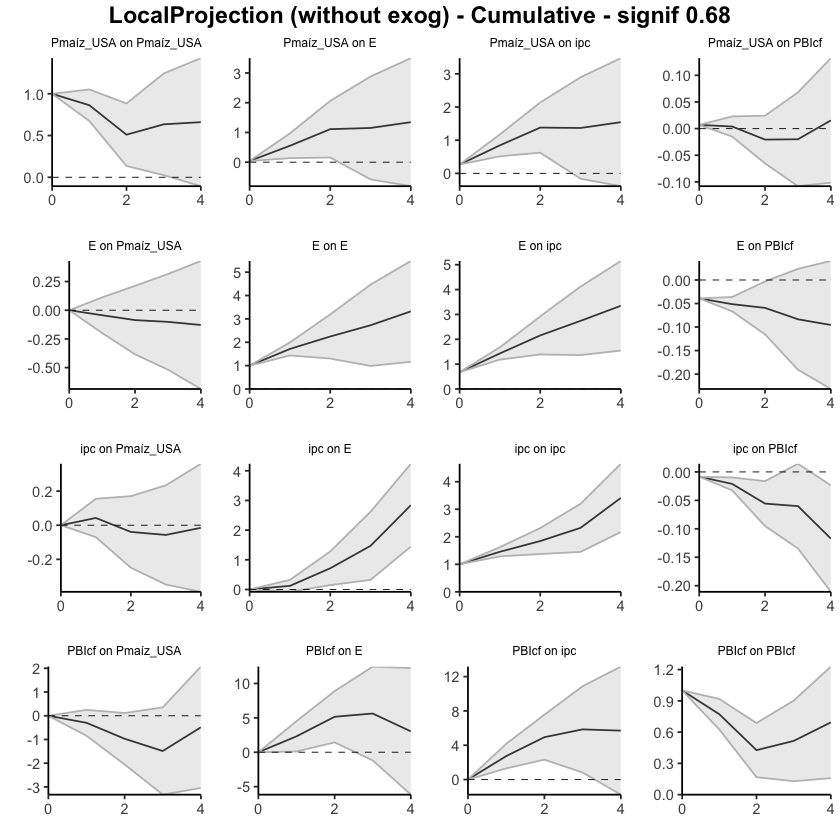

In [107]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Pmaíz_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.0000000
37,ipc,E,1,0.1476690,-0.09402813,0.3893660
38,ipc,E,2,0.5100993,0.17718740,0.8430111
39,ipc,E,3,0.6024169,0.04829375,1.1565400
40,ipc,E,4,1.2642852,0.98580223,1.5427683


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.0000000,0.0000000,0.00000000
52,PBIcf,E,1,2.5712495,0.3298564,4.81264267
53,PBIcf,E,2,3.3898121,1.8188554,4.96076873
54,PBIcf,E,3,0.8127283,-1.8046850,3.43014158
55,PBIcf,E,4,-2.4869620,-4.9205166,-0.05340744


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.04333376,-0.04333376,-0.04333376
2,Ptrigo_USA,E,1,0.37383134,-0.01735210,0.76501479
3,Ptrigo_USA,E,2,0.99829115,0.43356956,1.56301274
4,Ptrigo_USA,E,3,0.84239575,0.01406117,1.67073032
5,Ptrigo_USA,E,4,0.68141398,0.42082089,0.94200707


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.015577337,-0.015577337,-0.01557734
12,Ptrigo_USA,PBIcf,1,0.008646388,-0.014109396,0.03140217
13,Ptrigo_USA,PBIcf,2,-0.041919075,-0.071026311,-0.01281184
14,Ptrigo_USA,PBIcf,3,-0.009149043,-0.042307035,0.02400895
15,Ptrigo_USA,PBIcf,4,0.019200084,-0.007363023,0.04576319


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.000000000,0.0000000,0.00000000
17,E,Ptrigo_USA,1,-0.056284793,-0.2339966,0.12142704
18,E,Ptrigo_USA,2,-0.071147586,-0.2647494,0.12245426
19,E,Ptrigo_USA,3,-0.014105901,-0.1189018,0.09069001
20,E,Ptrigo_USA,4,0.007132779,-0.1355318,0.14979735


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,0.004978952,-0.1117226,0.1216805
33,ipc,Ptrigo_USA,2,0.041996297,-0.1017274,0.1857200
34,ipc,Ptrigo_USA,3,-0.029477214,-0.1033611,0.0444067
35,ipc,Ptrigo_USA,4,-0.076409682,-0.1651124,0.0122930


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.17820430,-0.6117154,0.2553068
48,PBIcf,Ptrigo_USA,2,0.04444023,-0.4668760,0.5557564
49,PBIcf,Ptrigo_USA,3,-0.28646026,-0.8286148,0.2556943
50,PBIcf,Ptrigo_USA,4,0.21675079,-0.4494523,0.8829539


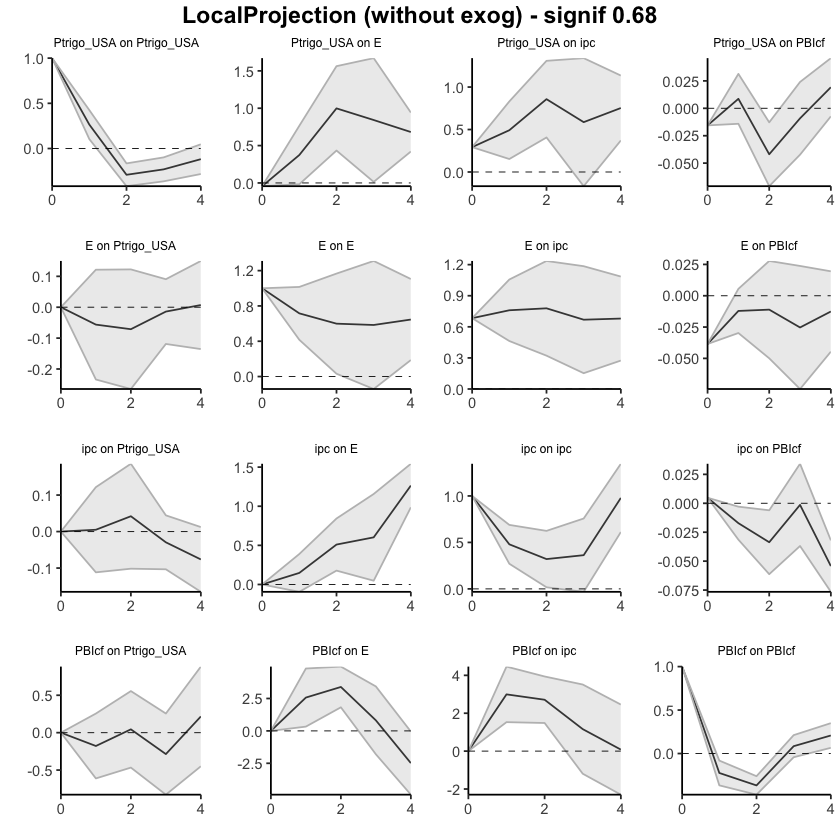

In [108]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.000000
37,ipc,E,1,0.1476690,-0.09402813,0.389366
38,ipc,E,2,0.6577682,0.08315927,1.232377
39,ipc,E,3,1.2601851,0.13145303,2.388917
40,ipc,E,4,2.5244704,1.11725526,3.931685


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.571250,0.3298564,4.812643
53,PBIcf,E,2,5.961062,2.1487118,9.773411
54,PBIcf,E,3,6.773790,0.3440268,13.203553
55,PBIcf,E,4,4.286828,-4.5764898,13.150146


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,-0.04333376,-0.04333376,-0.04333376
2,Ptrigo_USA,E,1,0.33049758,-0.06068586,0.72168102
3,Ptrigo_USA,E,2,1.32878873,0.37288370,2.28469376
4,Ptrigo_USA,E,3,2.17118448,0.38694487,3.95542409
5,Ptrigo_USA,E,4,2.85259846,0.80776576,4.89743115


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.015577337,-0.01557734,-0.015577337
12,Ptrigo_USA,PBIcf,1,-0.006930948,-0.02968673,0.015824836
13,Ptrigo_USA,PBIcf,2,-0.048850024,-0.10071304,0.003012997
14,Ptrigo_USA,PBIcf,3,-0.057999067,-0.14302008,0.027021945
15,Ptrigo_USA,PBIcf,4,-0.038798983,-0.15038310,0.072785136


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.05628479,-0.2339966,0.1214270
18,E,Ptrigo_USA,2,-0.12743238,-0.4987461,0.2438813
19,E,Ptrigo_USA,3,-0.14153828,-0.6176479,0.3345713
20,E,Ptrigo_USA,4,-0.13440550,-0.7531797,0.4843687


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.000000000,0.0000000,0.0000000
32,ipc,Ptrigo_USA,1,0.004978952,-0.1117226,0.1216805
33,ipc,Ptrigo_USA,2,0.046975248,-0.2134499,0.3074004
34,ipc,Ptrigo_USA,3,0.017498034,-0.3168111,0.3518071
35,ipc,Ptrigo_USA,4,-0.058911647,-0.4819234,0.3641001


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,-0.1782043,-0.6117154,0.2553068
48,PBIcf,Ptrigo_USA,2,-0.1337641,-1.0785914,0.8110633
49,PBIcf,Ptrigo_USA,3,-0.4202243,-1.9072062,1.0667576
50,PBIcf,Ptrigo_USA,4,-0.2034735,-2.3566585,1.9497114


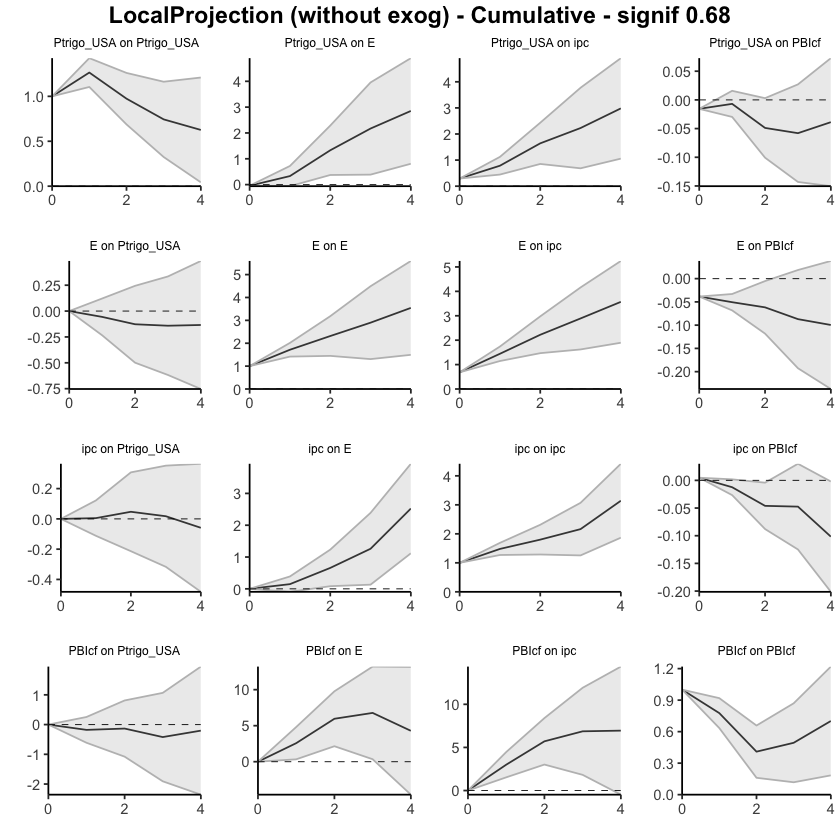

In [109]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1432645,-0.5358589,0.24932981
38,ipc,E,2,-0.3053891,-0.6620353,0.05125714
39,ipc,E,3,-1.5047232,-2.0789619,-0.93048444
40,ipc,E,4,-0.5650529,-0.9308183,-0.19928758


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.0000000
52,PBIcf,E,1,2.697545,0.7630763,4.6320141
53,PBIcf,E,2,2.671836,1.1391069,4.2045645
54,PBIcf,E,3,-1.033019,-2.5155195,0.4494817
55,PBIcf,E,4,-3.563740,-4.8766539,-2.2508261


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,0.0876730,0.08767300,0.0876730
2,Ptrigo_USA,E,1,0.3206979,-0.82263816,1.4640339
3,Ptrigo_USA,E,2,0.9300610,0.34153997,1.5185820
4,Ptrigo_USA,E,3,0.6586064,-0.14282153,1.4600344
5,Ptrigo_USA,E,4,0.4329172,0.00449936,0.8613351


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.02465295,-0.024652946,-0.024652946
12,Ptrigo_USA,PBIcf,1,0.01721726,-0.018748921,0.053183450
13,Ptrigo_USA,PBIcf,2,-0.04699099,-0.087868429,-0.006113556
14,Ptrigo_USA,PBIcf,3,-0.01448486,-0.067432203,0.038462483
15,Ptrigo_USA,PBIcf,4,0.03355315,-0.001270083,0.068376378


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.00000000,0.00000000
17,E,Ptrigo_USA,1,-0.05333072,-0.21002593,0.10336448
18,E,Ptrigo_USA,2,-0.12479746,-0.27407892,0.02448399
19,E,Ptrigo_USA,3,-0.02866280,-0.16009217,0.10276656
20,E,Ptrigo_USA,4,0.07361363,-0.01670368,0.16393094


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.000000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.08022899,-0.174451328,0.01399336
33,ipc,Ptrigo_USA,2,-0.07335179,-0.164653334,0.01794976
34,ipc,Ptrigo_USA,3,-0.02968061,-0.138081962,0.07872073
35,ipc,Ptrigo_USA,4,0.05967290,0.002955444,0.11639036


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.0000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.1317258,-0.2594339,0.5228855
48,PBIcf,Ptrigo_USA,2,-0.1461340,-0.7105138,0.4182458
49,PBIcf,Ptrigo_USA,3,-0.3097079,-1.0515640,0.4321482
50,PBIcf,Ptrigo_USA,4,0.6576383,-0.1471996,1.4624762


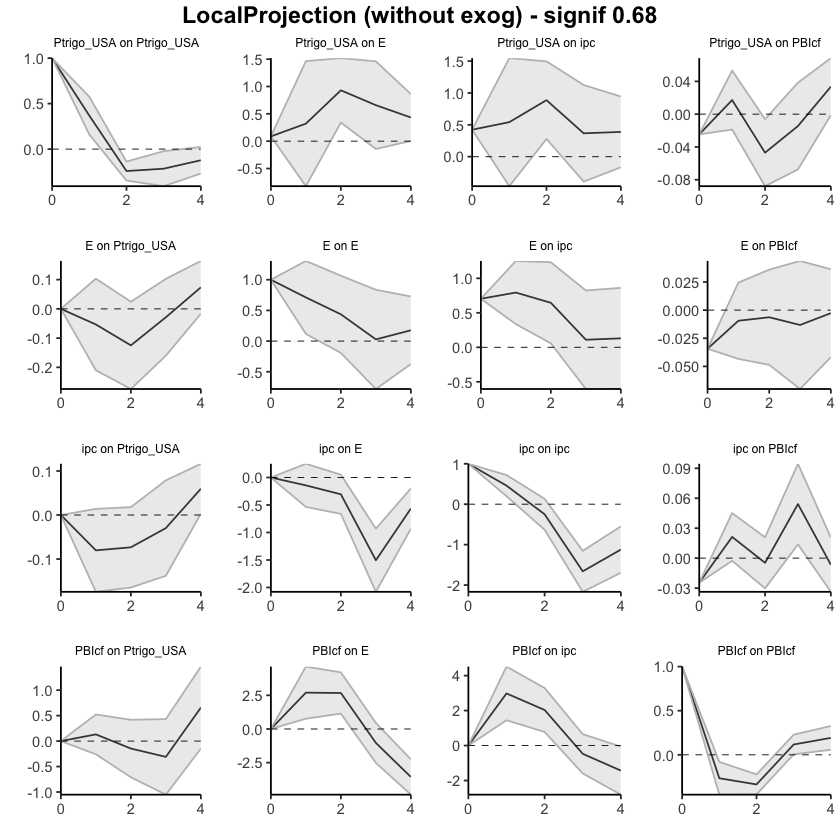

In [110]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"Ptrigo_USA, E, ipc, PBIcf",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.0000000
37,ipc,E,1,-0.1432645,-0.5358589,0.2493298
38,ipc,E,2,-0.4486536,-1.1978942,0.3005870
39,ipc,E,3,-1.9533768,-3.2768561,-0.6298975
40,ipc,E,4,-2.5184298,-4.2076744,-0.8291851


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIcf,E,0,0.000000,0.0000000,0.000000
52,PBIcf,E,1,2.697545,0.7630763,4.632014
53,PBIcf,E,2,5.369381,1.9021832,8.836579
54,PBIcf,E,3,4.336362,-0.6133363,9.286060
55,PBIcf,E,4,0.772622,-5.4899902,7.035234


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Ptrigo_USA,E,0,0.0876730,0.0876730,0.087673
2,Ptrigo_USA,E,1,0.4083709,-0.7349652,1.551707
3,Ptrigo_USA,E,2,1.3384319,-0.3934252,3.070289
4,Ptrigo_USA,E,3,1.9970383,-0.5362467,4.530323
5,Ptrigo_USA,E,4,2.4299555,-0.5317474,5.391658


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,Ptrigo_USA,PBIcf,0,-0.024652946,-0.02465295,-0.02465295
12,Ptrigo_USA,PBIcf,1,-0.007435681,-0.04340187,0.02853050
13,Ptrigo_USA,PBIcf,2,-0.054426673,-0.13127030,0.02241695
14,Ptrigo_USA,PBIcf,3,-0.068911533,-0.19870250,0.06087943
15,Ptrigo_USA,PBIcf,4,-0.035358386,-0.19997258,0.12925581


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,E,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
17,E,Ptrigo_USA,1,-0.05333072,-0.2100259,0.1033645
18,E,Ptrigo_USA,2,-0.17812818,-0.4841048,0.1278485
19,E,Ptrigo_USA,3,-0.20679099,-0.6441970,0.2306150
20,E,Ptrigo_USA,4,-0.13317736,-0.6609007,0.3945460


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
31,ipc,Ptrigo_USA,0,0.00000000,0.0000000,0.00000000
32,ipc,Ptrigo_USA,1,-0.08022899,-0.1744513,0.01399336
33,ipc,Ptrigo_USA,2,-0.15358077,-0.3391047,0.03194312
34,ipc,Ptrigo_USA,3,-0.18326139,-0.4771866,0.11066385
35,ipc,Ptrigo_USA,4,-0.12358848,-0.4742312,0.22705422


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,PBIcf,Ptrigo_USA,0,0.00000000,0.0000000,0.0000000
47,PBIcf,Ptrigo_USA,1,0.13172584,-0.2594339,0.5228855
48,PBIcf,Ptrigo_USA,2,-0.01440817,-0.9699477,0.9411313
49,PBIcf,Ptrigo_USA,3,-0.32411611,-2.0215117,1.3732795
50,PBIcf,Ptrigo_USA,4,0.33352218,-2.1687113,2.8357557


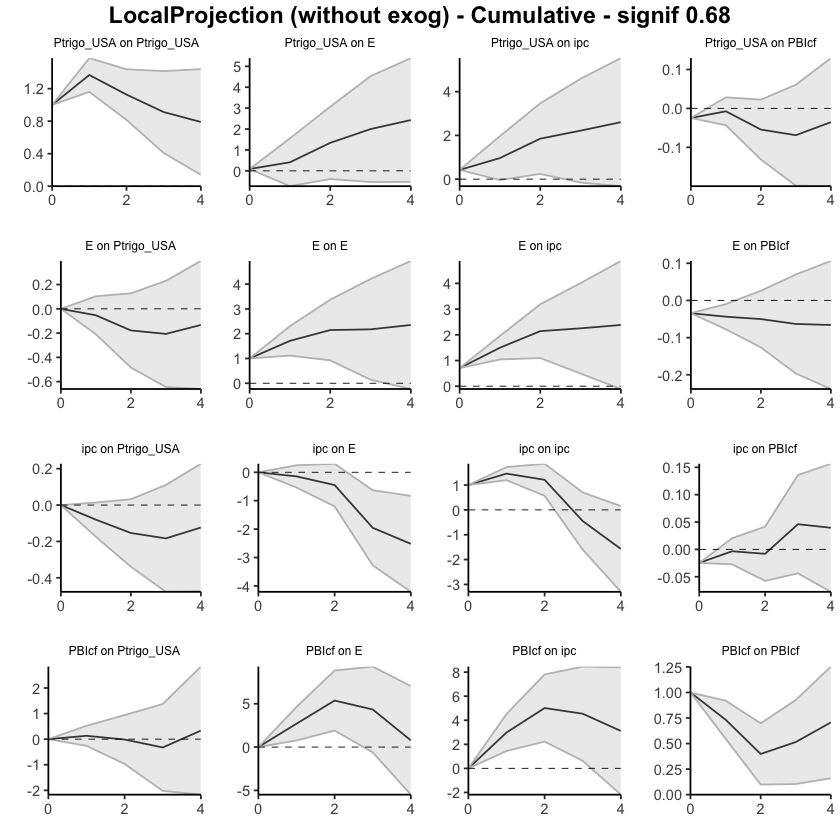

In [111]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("Ptrigo_USA", "E", "ipc", "PBIcf"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

### 1935-1990. 1 exógena y el resto endógenas

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.1828930,-0.0790194,0.4448055
13,ipc,E,2,0.6004719,0.1903688,1.0105750
14,ipc,E,3,0.7191493,0.1095605,1.3287381
15,ipc,E,4,1.3749065,1.0644174,1.6853956


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.00000000
22,PBIcf,E,1,2.1493247,-0.2154009,4.51405019
23,PBIcf,E,2,2.4696987,0.9737608,3.96563672
24,PBIcf,E,3,0.3768888,-2.9567676,3.71054517
25,PBIcf,E,4,-2.3351221,-4.7277655,0.05752128


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6809147,0.68091467,0.6809147
2,E,ipc,1,0.7770594,0.51728062,1.0368383
3,E,ipc,2,0.7495140,0.11871597,1.3803120
4,E,ipc,3,0.6210982,0.06472392,1.1774725
5,E,ipc,4,0.5874176,0.16848243,1.0063528


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.3715375,0.9099693,3.833106
28,PBIcf,ipc,2,1.7209890,0.3515239,3.090454
29,PBIcf,ipc,3,0.7700204,-2.0121336,3.552174
30,PBIcf,ipc,4,0.1246745,-2.4526318,2.701981


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.037154869,-0.03715487,-0.037154869
7,E,PBIcf,1,-0.014824906,-0.03309589,0.003446078
8,E,PBIcf,2,-0.008313651,-0.05219793,0.035570623
9,E,PBIcf,3,-0.021564299,-0.07818394,0.035055342
10,E,PBIcf,4,-0.011390675,-0.04822880,0.025447452


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.005792836,0.005792836,0.005792836
17,ipc,PBIcf,1,-0.010780000,-0.025461935,0.003901935
18,ipc,PBIcf,2,-0.040317165,-0.071490013,-0.009144317
19,ipc,PBIcf,3,-0.007946888,-0.047261027,0.031367251
20,ipc,PBIcf,4,-0.056806197,-0.082977512,-0.030634883


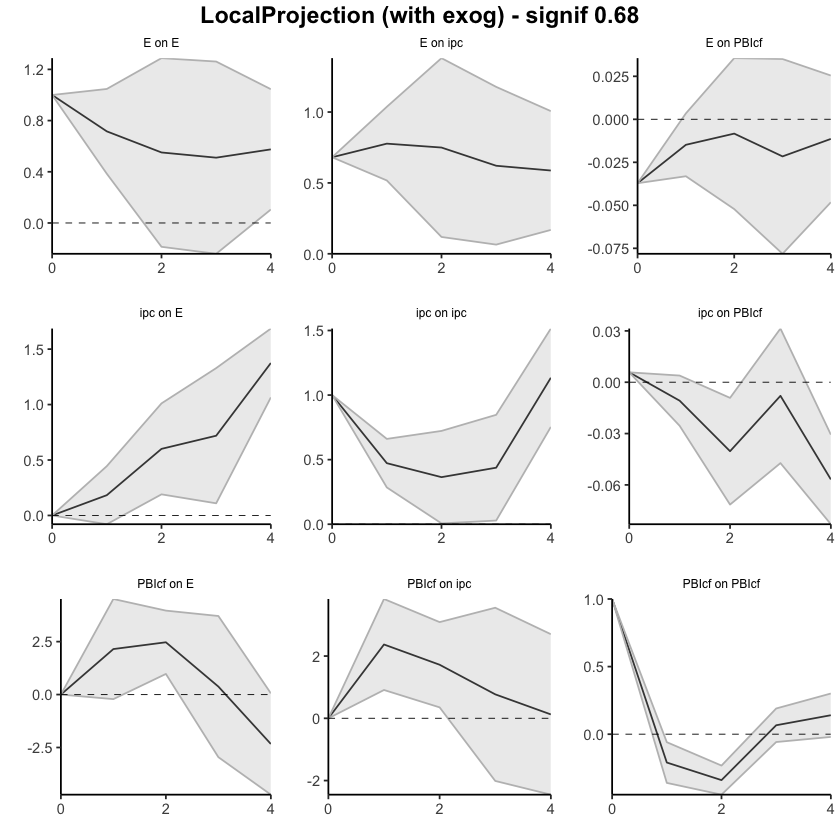

In [112]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.1828930,-0.0790194,0.4448055
13,ipc,E,2,0.7833649,0.1113494,1.4553804
14,ipc,E,3,1.5025142,0.2209100,2.7841185
15,ipc,E,4,2.8774207,1.2853273,4.4695141


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.149325,-0.2154009,4.514050
23,PBIcf,E,2,4.619023,0.7583599,8.479687
24,PBIcf,E,3,4.995912,-2.1984077,12.190232
25,PBIcf,E,4,2.660790,-6.9261732,12.247753


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6809147,0.6809147,0.6809147
2,E,ipc,1,1.4579741,1.1981953,1.7177529
3,E,ipc,2,2.2074881,1.3169113,3.0980649
4,E,ipc,3,2.8285863,1.3816352,4.2755374
5,E,ipc,4,3.4160039,1.5501176,5.2818902


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.371538,0.9099693,3.833106
28,PBIcf,ipc,2,4.092527,1.2614932,6.923560
29,PBIcf,ipc,3,4.862547,-0.7506404,10.475734
30,PBIcf,ipc,4,4.987221,-3.2032722,13.177715


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03715487,-0.03715487,-0.037154869
7,E,PBIcf,1,-0.05197978,-0.07025076,-0.033708791
8,E,PBIcf,2,-0.06029343,-0.12244869,0.001861832
9,E,PBIcf,3,-0.08185773,-0.20063263,0.036917175
10,E,PBIcf,4,-0.09324840,-0.24886143,0.062364626


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,0.005792836,0.005792836,0.0057928362
17,ipc,PBIcf,1,-0.004987164,-0.019669099,0.0096947715
18,ipc,PBIcf,2,-0.045304329,-0.091159112,0.0005504544
19,ipc,PBIcf,3,-0.053251216,-0.138420138,0.0319177056
20,ipc,PBIcf,4,-0.110057414,-0.221397650,0.0012828226


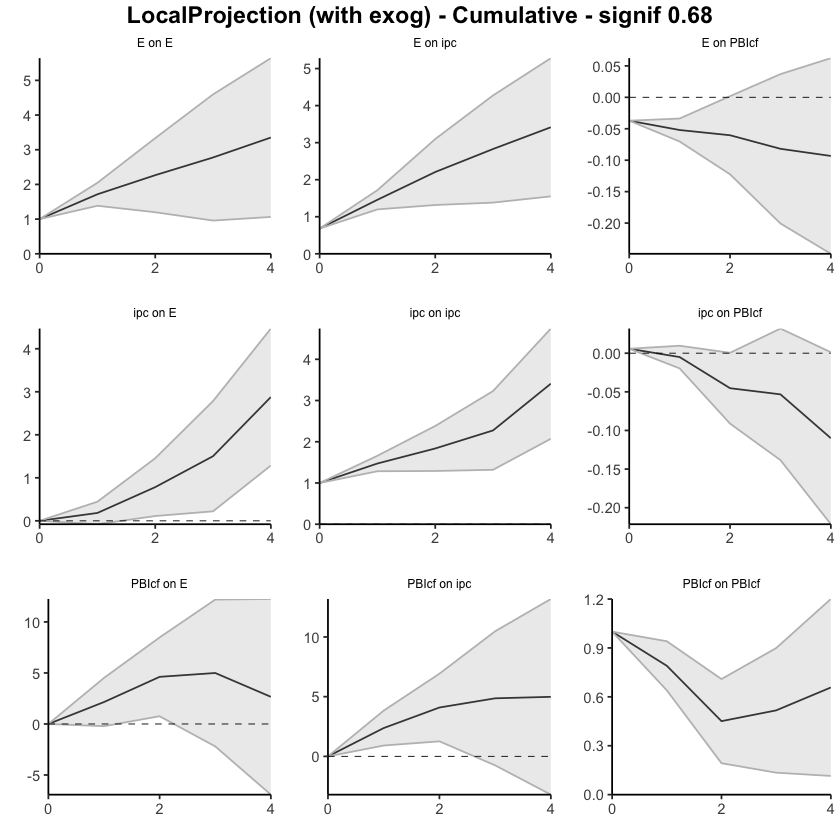

In [113]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1941636,-0.6760908,0.28776362
13,ipc,E,2,-0.1662600,-0.5298001,0.19728018
14,ipc,E,3,-1.2205793,-1.8616584,-0.57950010
15,ipc,E,4,-0.4604455,-0.8294392,-0.09145171


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,2.556605,-0.2400196,5.3532305
23,PBIcf,E,2,1.969277,0.7290914,3.2094627
24,PBIcf,E,3,-2.031349,-3.7721291,-0.2905693
25,PBIcf,E,4,-3.641217,-5.0876766,-2.1947582


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6978464,0.69784638,0.6978464
2,E,ipc,1,0.8305367,0.48869802,1.1723754
3,E,ipc,2,0.6906829,0.05262916,1.3287366
4,E,ipc,3,0.1372530,-0.61317432,0.8876803
5,E,ipc,4,0.1642667,-0.72436236,1.0528958


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.0000000
27,PBIcf,ipc,1,2.603703,1.1414567,4.0659494
28,PBIcf,ipc,2,1.296211,0.4470135,2.1454081
29,PBIcf,ipc,3,-1.180233,-2.6206074,0.2601404
30,PBIcf,ipc,4,-1.366171,-3.2804404,0.5480975


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.033660354,-0.03366035,-0.03366035
7,E,PBIcf,1,-0.013518240,-0.04193717,0.01490069
8,E,PBIcf,2,-0.004723254,-0.05131404,0.04186753
9,E,PBIcf,3,-0.008532668,-0.06636833,0.04930300
10,E,PBIcf,4,-0.003858430,-0.04723588,0.03951902


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.022411147,-0.022411147,-0.022411147
17,ipc,PBIcf,1,0.037631782,0.017618119,0.057645444
18,ipc,PBIcf,2,-0.030544198,-0.063080352,0.001991955
19,ipc,PBIcf,3,0.031946710,-0.008498392,0.072391812
20,ipc,PBIcf,4,0.005097763,-0.025937613,0.036133138


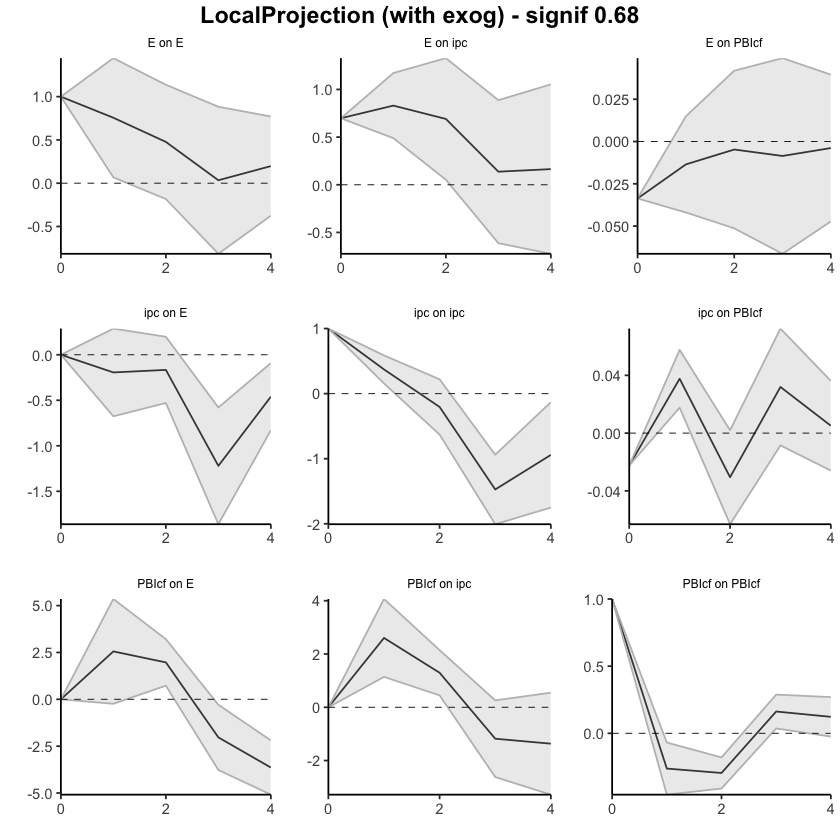

In [117]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.1941636,-0.6760908,0.2877636
13,ipc,E,2,-0.3604236,-1.2058909,0.4850438
14,ipc,E,3,-1.5810028,-3.0675494,-0.0944563
15,ipc,E,4,-2.0414483,-3.8969886,-0.1859080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.556605,-0.2400196,5.353230
23,PBIcf,E,2,4.525882,0.4890718,8.562693
24,PBIcf,E,3,2.494533,-3.2830572,8.272124
25,PBIcf,E,4,-1.146684,-8.3707338,6.077366


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6978464,0.69784638,0.6978464
2,E,ipc,1,1.5283831,1.18654440,1.8702218
3,E,ipc,2,2.2190660,1.23917356,3.1989584
4,E,ipc,3,2.3563190,0.62599924,4.0866388
5,E,ipc,4,2.5205857,-0.09836312,5.1395346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.603703,1.141457,4.065949
28,PBIcf,ipc,2,3.899914,1.588470,6.211358
29,PBIcf,ipc,3,2.719680,-1.032137,6.471498
30,PBIcf,ipc,4,1.353509,-4.312577,7.019595


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03366035,-0.03366035,-0.03366035
7,E,PBIcf,1,-0.04717859,-0.07559753,-0.01875966
8,E,PBIcf,2,-0.05190185,-0.12691157,0.02310787
9,E,PBIcf,3,-0.06043452,-0.19327990,0.07241087
10,E,PBIcf,4,-0.06429295,-0.24051578,0.11192989


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.02241115,-0.022411147,-0.02241115
17,ipc,PBIcf,1,0.01522064,-0.004793027,0.03523430
18,ipc,PBIcf,2,-0.01532356,-0.067873379,0.03722625
19,ipc,PBIcf,3,0.01662315,-0.076371771,0.10961806
20,ipc,PBIcf,4,0.02172091,-0.102309384,0.14575120


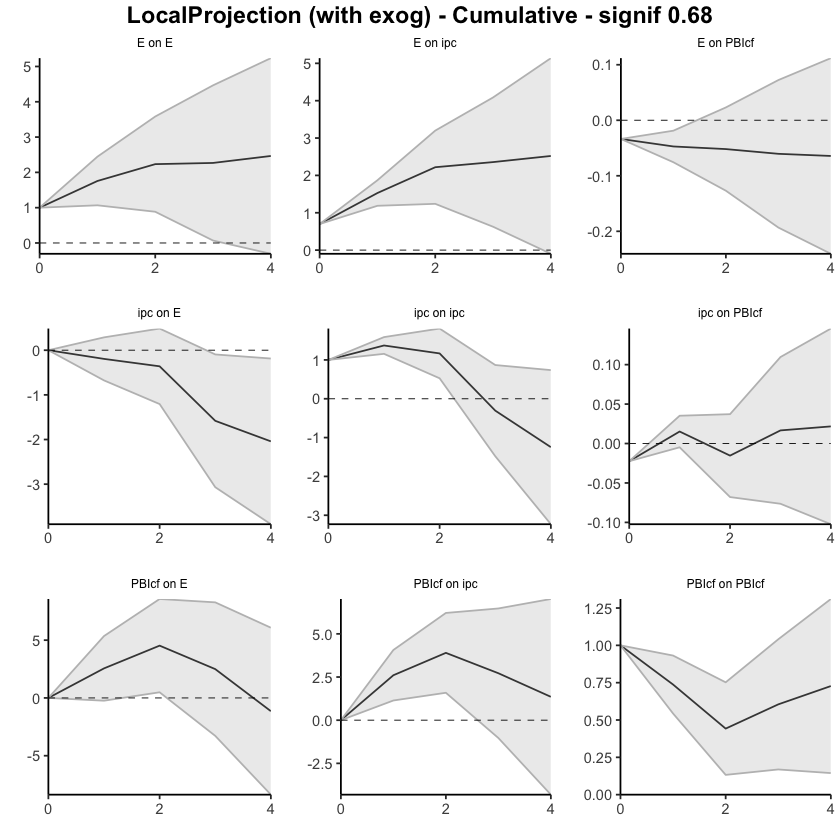

In [114]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.4549027,-0.9813030,0.07149764
13,ipc,E,2,-0.2203013,-0.6480212,0.20741864
14,ipc,E,3,-1.3184442,-1.7728027,-0.86408569
15,ipc,E,4,-0.2934229,-0.7785321,0.19168621


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.00000000,0.0000000
22,PBIcf,E,1,2.379041,0.05859703,4.6994859
23,PBIcf,E,2,1.511076,0.26800285,2.7541486
24,PBIcf,E,3,-1.049487,-3.10339890,1.0044245
25,PBIcf,E,4,-2.062221,-3.60418349,-0.5202588


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.64508845,0.6450884,0.6450884
2,E,ipc,1,0.71019772,0.2607016,1.1596938
3,E,ipc,2,0.47776525,-0.2585139,1.2140444
4,E,ipc,3,0.04471351,-0.9906330,1.0800601
5,E,ipc,4,0.07981461,-0.9503428,1.1099720


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.00000000,0.00000000,0.000000
27,PBIcf,ipc,1,2.69551896,1.29153434,4.099504
28,PBIcf,ipc,2,1.33923818,-0.01086316,2.689340
29,PBIcf,ipc,3,-0.52547542,-2.73215266,1.681202
30,PBIcf,ipc,4,-0.03630247,-1.32896959,1.256365


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.028723139,-0.02872314,-0.02872314
7,E,PBIcf,1,-0.011450238,-0.04209567,0.01919519
8,E,PBIcf,2,-0.004396481,-0.03977546,0.03098250
9,E,PBIcf,3,-0.011897999,-0.07646586,0.05266986
10,E,PBIcf,4,-0.014988491,-0.05515592,0.02517893


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.02943396,-0.02943396,-0.02943396
17,ipc,PBIcf,1,0.04808554,0.02777298,0.06839810
18,ipc,PBIcf,2,-0.06119546,-0.08660331,-0.03578762
19,ipc,PBIcf,3,0.02093426,-0.02726018,0.06912870
20,ipc,PBIcf,4,-0.02407173,-0.05370948,0.00556602


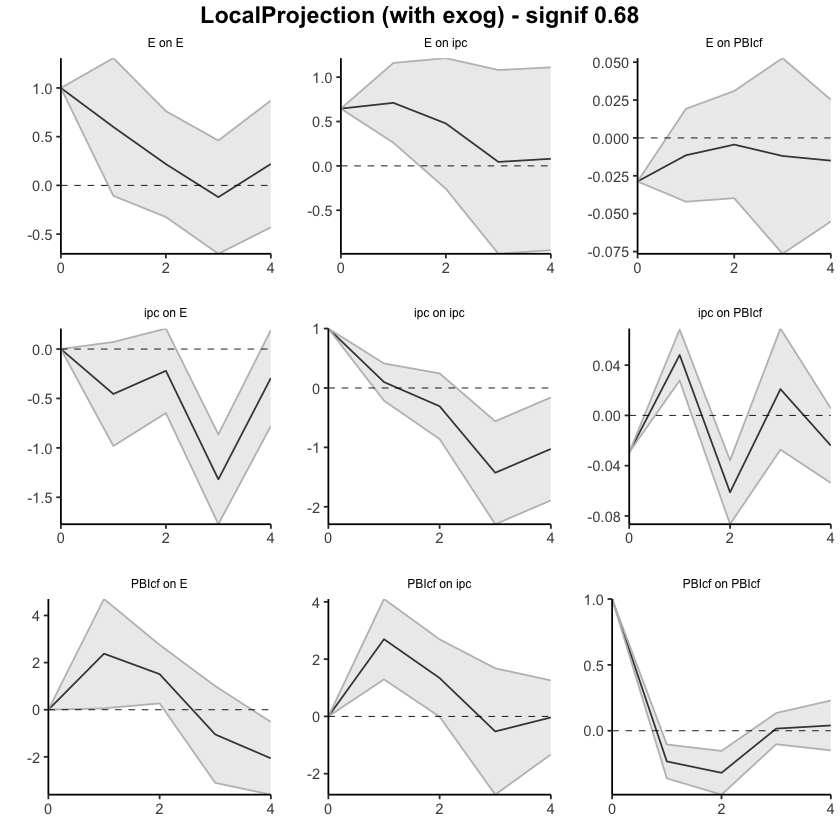

In [115]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.000000,0.00000000
12,ipc,E,1,-0.4549027,-0.981303,0.07149764
13,ipc,E,2,-0.6752040,-1.629324,0.27891629
14,ipc,E,3,-1.9936482,-3.402127,-0.58516940
15,ipc,E,4,-2.2870711,-4.180659,-0.39348319


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.00000000,0.000000
22,PBIcf,E,1,2.3790415,0.05859703,4.699486
23,PBIcf,E,2,3.8901172,0.32659988,7.453635
24,PBIcf,E,3,2.8406300,-2.77679902,8.458059
25,PBIcf,E,4,0.7784088,-6.38098252,7.937800


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6450884,0.6450884,0.6450884
2,E,ipc,1,1.3552862,0.9057901,1.8047822
3,E,ipc,2,1.8330514,0.6472762,3.0188267
4,E,ipc,3,1.8777649,-0.3433569,4.0988867
5,E,ipc,4,1.9575795,-1.2936997,5.2088587


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.695519,1.291534,4.099504
28,PBIcf,ipc,2,4.034757,1.280671,6.788843
29,PBIcf,ipc,3,3.509282,-1.451481,8.470045
30,PBIcf,ipc,4,3.472979,-2.780451,9.726410


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.02872314,-0.02872314,-0.028723139
7,E,PBIcf,1,-0.04017338,-0.07081880,-0.009527948
8,E,PBIcf,2,-0.04456986,-0.11059427,0.021454553
9,E,PBIcf,3,-0.05646786,-0.18706013,0.074124417
10,E,PBIcf,4,-0.07145635,-0.24221605,0.099303350


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.02943396,-0.029433957,-0.029433957
17,ipc,PBIcf,1,0.01865158,-0.001660976,0.038964146
18,ipc,PBIcf,2,-0.04254388,-0.088264287,0.003176529
19,ipc,PBIcf,3,-0.02160961,-0.115524463,0.072305234
20,ipc,PBIcf,4,-0.04568135,-0.169233948,0.077871254


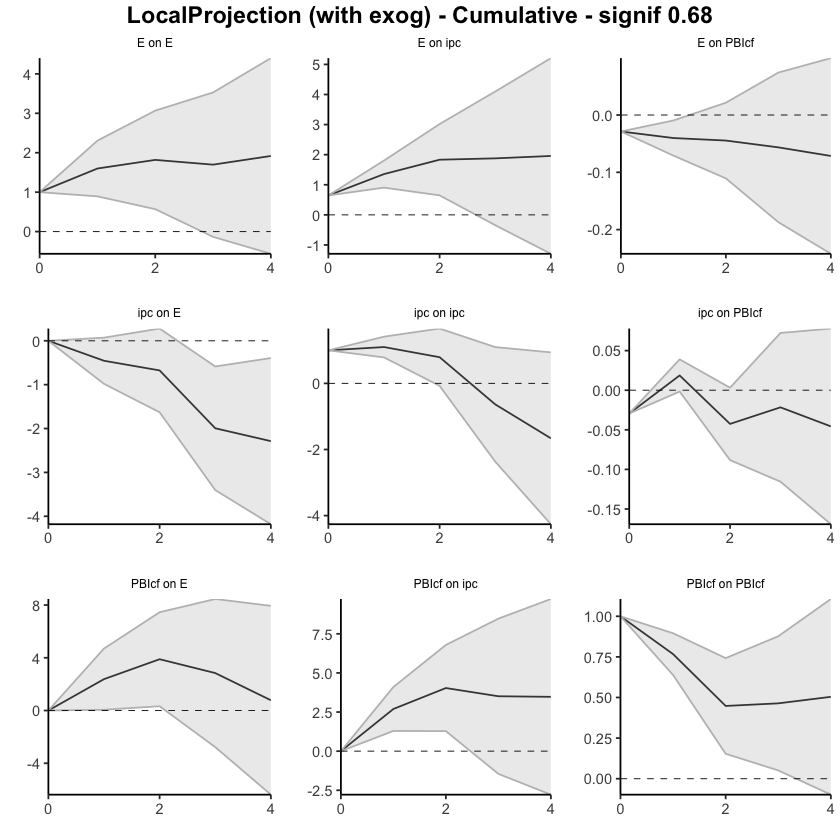

In [116]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Psoja_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1342628,-0.07931007,0.3478357
13,ipc,E,2,0.6080087,0.23382292,0.9821945
14,ipc,E,3,0.7598909,0.16051790,1.3592638
15,ipc,E,4,1.3555024,1.09650581,1.6144990


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,2.3147257,0.1086941,4.520757
23,PBIcf,E,2,2.8438506,1.3197249,4.367976
24,PBIcf,E,3,0.4723649,-2.6210279,3.565758
25,PBIcf,E,4,-2.5965476,-4.9747272,-0.218368


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6787815,0.67878145,0.6787815
2,E,ipc,1,0.7550830,0.50632321,1.0038428
3,E,ipc,2,0.7255673,0.20766584,1.2434688
4,E,ipc,3,0.5872182,-0.02744179,1.2018782
5,E,ipc,4,0.6089202,0.18477189,1.0330685


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.000000,0.000000
27,PBIcf,ipc,1,2.7328164,1.302609,4.163024
28,PBIcf,ipc,2,2.2092260,1.020847,3.397605
29,PBIcf,ipc,3,0.9086758,-1.504985,3.322337
30,PBIcf,ipc,4,-0.1457028,-2.576896,2.285490


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03894441,-0.03894441,-0.038944411
7,E,PBIcf,1,-0.01238933,-0.02762498,0.002846315
8,E,PBIcf,2,-0.00800737,-0.04911464,0.033099903
9,E,PBIcf,3,-0.02419714,-0.07522190,0.026827622
10,E,PBIcf,4,-0.01223327,-0.04118980,0.016723269


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.002907646,-0.002907646,-0.002907646
17,ipc,PBIcf,1,-0.013888937,-0.025985748,-0.001792126
18,ipc,PBIcf,2,-0.036549036,-0.065376968,-0.007721105
19,ipc,PBIcf,3,-0.003944910,-0.039570710,0.031680890
20,ipc,PBIcf,4,-0.056120235,-0.076057627,-0.036182842


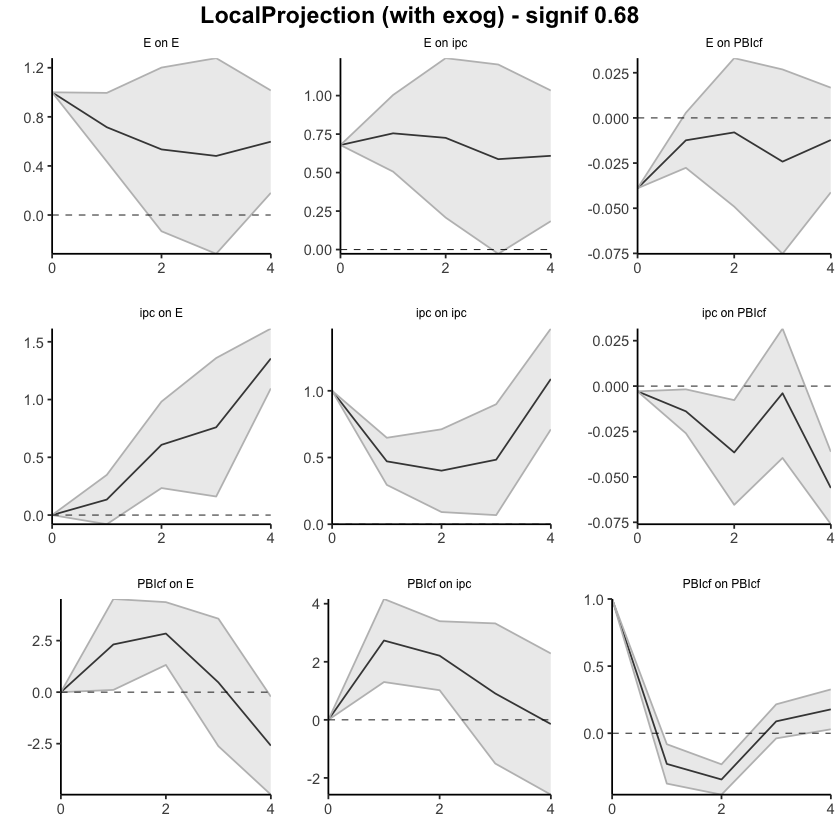

In [118]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1342628,-0.07931007,0.3478357
13,ipc,E,2,0.7422715,0.15451285,1.3300302
14,ipc,E,3,1.5021624,0.31503075,2.6892940
15,ipc,E,4,2.8576648,1.41153656,4.3037930


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.314726,0.1086941,4.520757
23,PBIcf,E,2,5.158576,1.4284190,8.888734
24,PBIcf,E,3,5.630941,-1.1926089,12.454491
25,PBIcf,E,4,3.034394,-6.1673361,12.236123


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6787815,0.6787815,0.6787815
2,E,ipc,1,1.4338645,1.1851047,1.6826242
3,E,ipc,2,2.1594318,1.3927705,2.9260931
4,E,ipc,3,2.7466500,1.3653287,4.1279712
5,E,ipc,4,3.3555701,1.5501006,5.1610397


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.732816,1.3026091,4.163024
28,PBIcf,ipc,2,4.942042,2.3234557,7.560629
29,PBIcf,ipc,3,5.850718,0.8184703,10.882966
30,PBIcf,ipc,4,5.705015,-1.7584255,13.168456


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03894441,-0.03894441,-0.038944411
7,E,PBIcf,1,-0.05133374,-0.06656939,-0.036098096
8,E,PBIcf,2,-0.05934111,-0.11568403,-0.002998193
9,E,PBIcf,3,-0.08353825,-0.19090593,0.023829429
10,E,PBIcf,4,-0.09577152,-0.23209573,0.040552698


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.002907646,-0.002907646,-0.002907646
17,ipc,PBIcf,1,-0.016796582,-0.028893394,-0.004699771
18,ipc,PBIcf,2,-0.053345619,-0.094270361,-0.012420876
19,ipc,PBIcf,3,-0.057290529,-0.133841071,0.019260014
20,ipc,PBIcf,4,-0.113410763,-0.209898699,-0.016922828


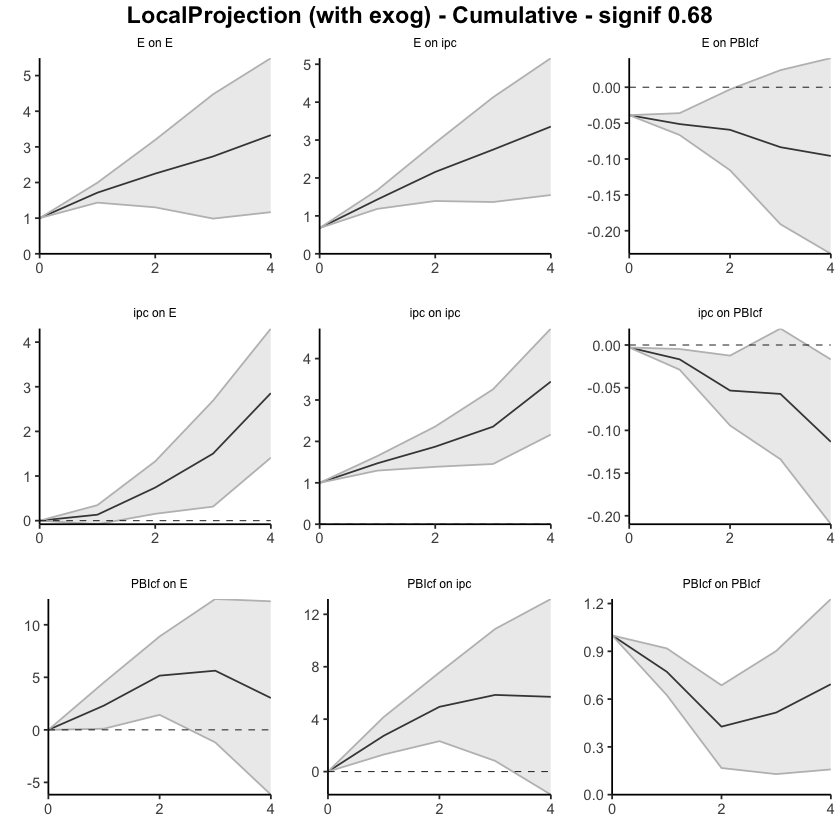

In [119]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.3691962,-0.7281404,-0.01025206
13,ipc,E,2,-0.2197646,-0.7002630,0.26073388
14,ipc,E,3,-1.1858277,-1.6353298,-0.73632565
15,ipc,E,4,-0.2663254,-0.6628047,0.13015380


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,1.955212,-0.0349572,3.945382
23,PBIcf,E,2,1.529429,0.2894530,2.769405
24,PBIcf,E,3,-0.610229,-2.3288515,1.108394
25,PBIcf,E,4,-2.670218,-3.7740557,-1.566380


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.66147594,0.6614759,0.6614759
2,E,ipc,1,0.66776545,0.2772663,1.0582646
3,E,ipc,2,0.25759419,-0.2799167,0.7951051
4,E,ipc,3,-0.17133161,-1.4792362,1.1365730
5,E,ipc,4,-0.04078994,-0.9869098,0.9053299


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIcf,ipc,1,2.5807203,1.2041657,3.9572749
28,PBIcf,ipc,2,1.3837123,0.1495622,2.6178623
29,PBIcf,ipc,3,-0.2060729,-16.8882522,16.4761065
30,PBIcf,ipc,4,-0.3297594,-1.6057381,0.9462193


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.033748246,-0.03374825,-0.03374825
7,E,PBIcf,1,-0.005218825,-0.04023346,0.02979581
8,E,PBIcf,2,-0.005429482,-0.03659763,0.02573867
9,E,PBIcf,3,-0.012943609,-0.07790089,0.05201367
10,E,PBIcf,4,-0.011407771,-0.04793324,0.02511770


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04210439,-0.04210439,-0.0421043896
17,ipc,PBIcf,1,0.04631749,0.02387333,0.0687616537
18,ipc,PBIcf,2,-0.05223295,-0.07035607,-0.0341098410
19,ipc,PBIcf,3,0.03172556,-0.01209316,0.0755442911
20,ipc,PBIcf,4,-0.02563811,-0.05099424,-0.0002819848


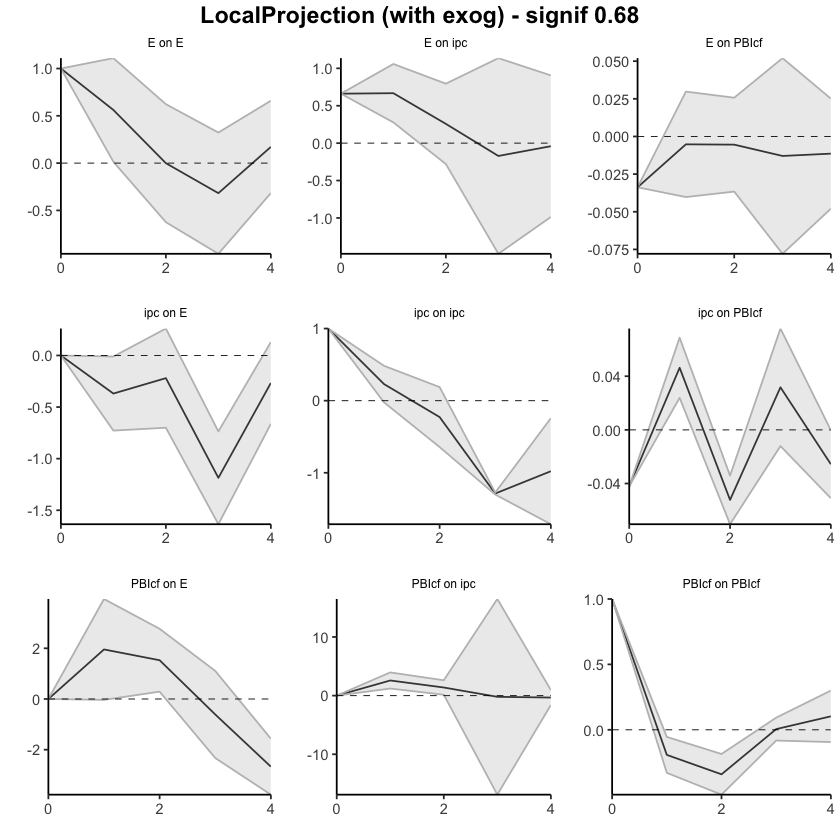

In [120]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.3691962,-0.7281404,-0.01025206
13,ipc,E,2,-0.5889608,-1.4284034,0.25048182
14,ipc,E,3,-1.7747885,-3.0637332,-0.48584383
15,ipc,E,4,-2.0411139,-3.7265379,-0.35569003


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.000000
22,PBIcf,E,1,1.9552123,-0.0349572,3.945382
23,PBIcf,E,2,3.4846414,0.2544958,6.714787
24,PBIcf,E,3,2.8744124,-2.0743557,7.823180
25,PBIcf,E,4,0.2041944,-5.8484114,6.256800


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6614759,0.6614759,0.6614759
2,E,ipc,1,1.3292414,0.9387422,1.7197406
3,E,ipc,2,1.5868356,0.6588255,2.5148457
4,E,ipc,3,1.4155040,-0.8204107,3.6514187
5,E,ipc,4,1.3747140,-1.8073205,4.5567486


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.580720,1.204166,3.957275
28,PBIcf,ipc,2,3.964433,1.353728,6.575137
29,PBIcf,ipc,3,3.758360,-15.534524,23.051244
30,PBIcf,ipc,4,3.428600,-17.140262,23.997463


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03374825,-0.03374825,-0.033748246
7,E,PBIcf,1,-0.03896707,-0.07398171,-0.003952435
8,E,PBIcf,2,-0.04439655,-0.11057934,0.021786231
9,E,PBIcf,3,-0.05734016,-0.18848023,0.073799902
10,E,PBIcf,4,-0.06874793,-0.23641347,0.098917600


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.042104390,-0.04210439,-0.042104390
17,ipc,PBIcf,1,0.004213103,-0.01823106,0.026657264
18,ipc,PBIcf,2,-0.048019852,-0.08858713,-0.007452577
19,ipc,PBIcf,3,-0.016294287,-0.10068029,0.068091714
20,ipc,PBIcf,4,-0.041932402,-0.15167453,0.067809729


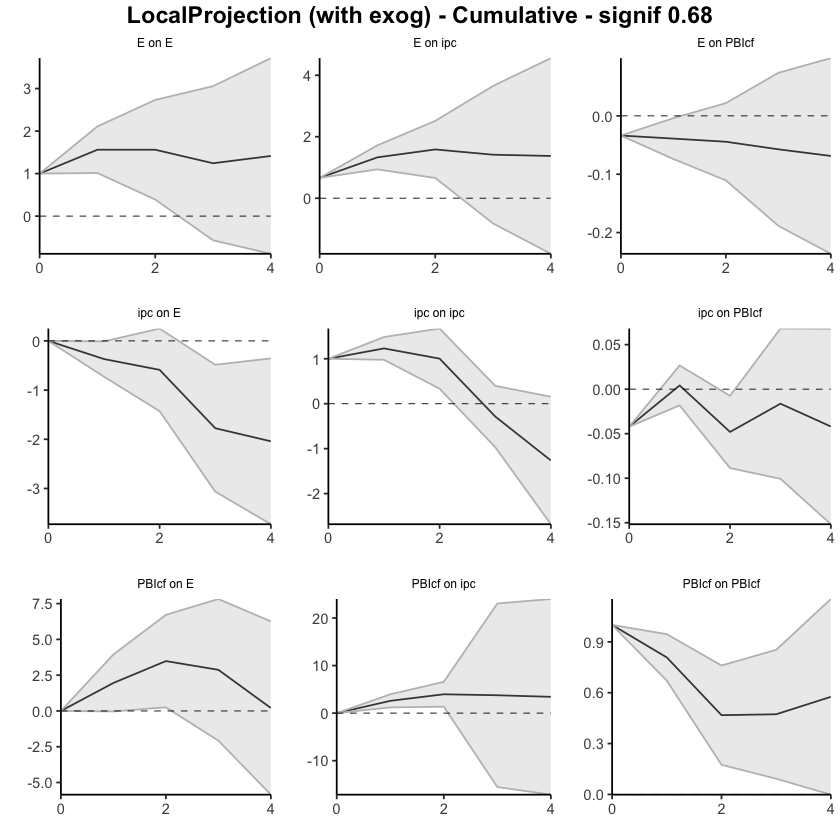

In [121]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Pmaíz_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1290492,-0.09641678,0.3545153
13,ipc,E,2,0.4855519,0.16401615,0.8070877
14,ipc,E,3,0.5965315,0.06136239,1.1317007
15,ipc,E,4,1.2822946,1.02143418,1.5431550


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.00000000
22,PBIcf,E,1,2.5712495,0.3298564,4.81264267
23,PBIcf,E,2,3.3898121,1.8188554,4.96076873
24,PBIcf,E,3,0.8127283,-1.8046850,3.43014158
25,PBIcf,E,4,-2.4869620,-4.9205166,-0.05340744


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6819322,0.6819322,0.6819322
2,E,ipc,1,0.7593395,0.4628452,1.0558337
3,E,ipc,2,0.7784596,0.3218478,1.2350715
4,E,ipc,3,0.6683799,0.1524257,1.1843340
5,E,ipc,4,0.6784191,0.2735393,1.0832989


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.00000000,0.000000,0.000000
27,PBIcf,ipc,1,2.99557096,1.529778,4.461364
28,PBIcf,ipc,2,2.71209637,1.484291,3.939901
29,PBIcf,ipc,3,1.16088505,-1.193636,3.515406
30,PBIcf,ipc,4,0.07970442,-2.297749,2.457158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03843795,-0.03843795,-0.038437947
7,E,PBIcf,1,-0.01212704,-0.02974102,0.005486937
8,E,PBIcf,2,-0.01106782,-0.04989141,0.027755765
9,E,PBIcf,3,-0.02532195,-0.07439532,0.023751412
10,E,PBIcf,4,-0.01247650,-0.04452571,0.019572717


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.002445001,-0.002445001,-0.002445001
17,ipc,PBIcf,1,-0.015558564,-0.028789284,-0.002327844
18,ipc,PBIcf,2,-0.031005086,-0.057847900,-0.004162271
19,ipc,PBIcf,3,-0.001999361,-0.036616513,0.032617790
20,ipc,PBIcf,4,-0.055777402,-0.076999750,-0.034555054


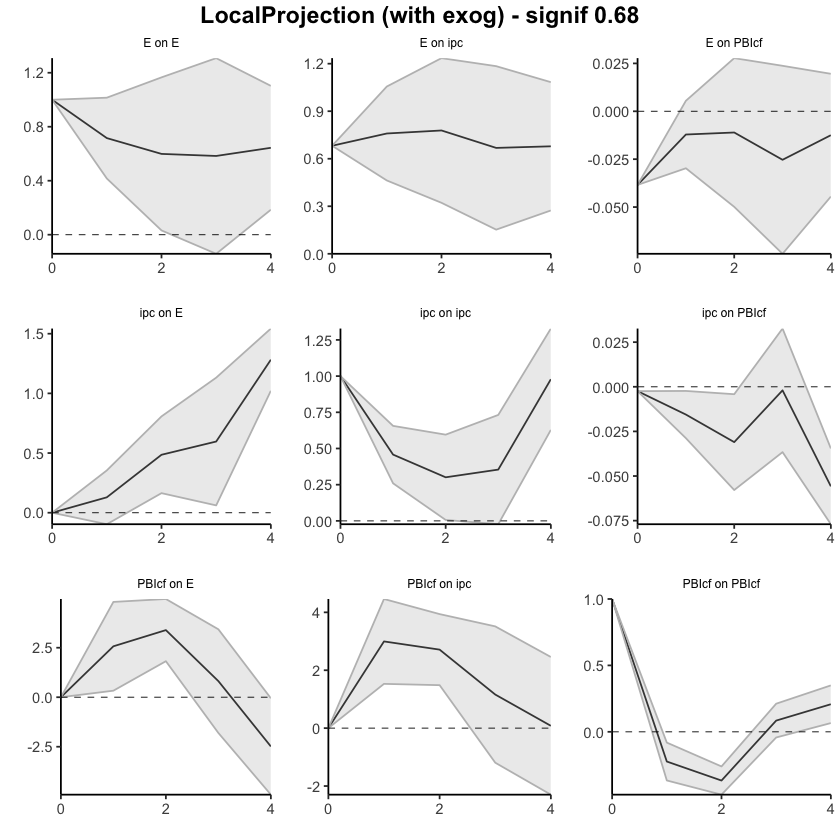

In [122]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,0.1290492,-0.09641678,0.3545153
13,ipc,E,2,0.6146012,0.06759936,1.1616030
14,ipc,E,3,1.2111327,0.12896175,2.2933036
15,ipc,E,4,2.4934273,1.15039594,3.8364586


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.571250,0.3298564,4.812643
23,PBIcf,E,2,5.961062,2.1487118,9.773411
24,PBIcf,E,3,6.773790,0.3440268,13.203553
25,PBIcf,E,4,4.286828,-4.5764898,13.150146


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6819322,0.6819322,0.6819322
2,E,ipc,1,1.4412717,1.1447775,1.7377659
3,E,ipc,2,2.2197313,1.4666252,2.9728374
4,E,ipc,3,2.8881112,1.6190510,4.1571714
5,E,ipc,4,3.5665303,1.8925903,5.2404703


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.995571,1.5297779,4.461364
28,PBIcf,ipc,2,5.707667,3.0140691,8.401266
29,PBIcf,ipc,3,6.868552,1.8204333,11.916671
30,PBIcf,ipc,4,6.948257,-0.4773159,14.373829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03843795,-0.03843795,-0.038437947
7,E,PBIcf,1,-0.05056499,-0.06817897,-0.032951010
8,E,PBIcf,2,-0.06163281,-0.11807038,-0.005195245
9,E,PBIcf,3,-0.08695476,-0.19246569,0.018556168
10,E,PBIcf,4,-0.09943126,-0.23699141,0.038128885


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.002445001,-0.002445001,-0.002445001
17,ipc,PBIcf,1,-0.018003565,-0.031234285,-0.004772845
18,ipc,PBIcf,2,-0.049008651,-0.089082185,-0.008935116
19,ipc,PBIcf,3,-0.051008012,-0.125698698,0.023682674
20,ipc,PBIcf,4,-0.106785414,-0.202698448,-0.010872380


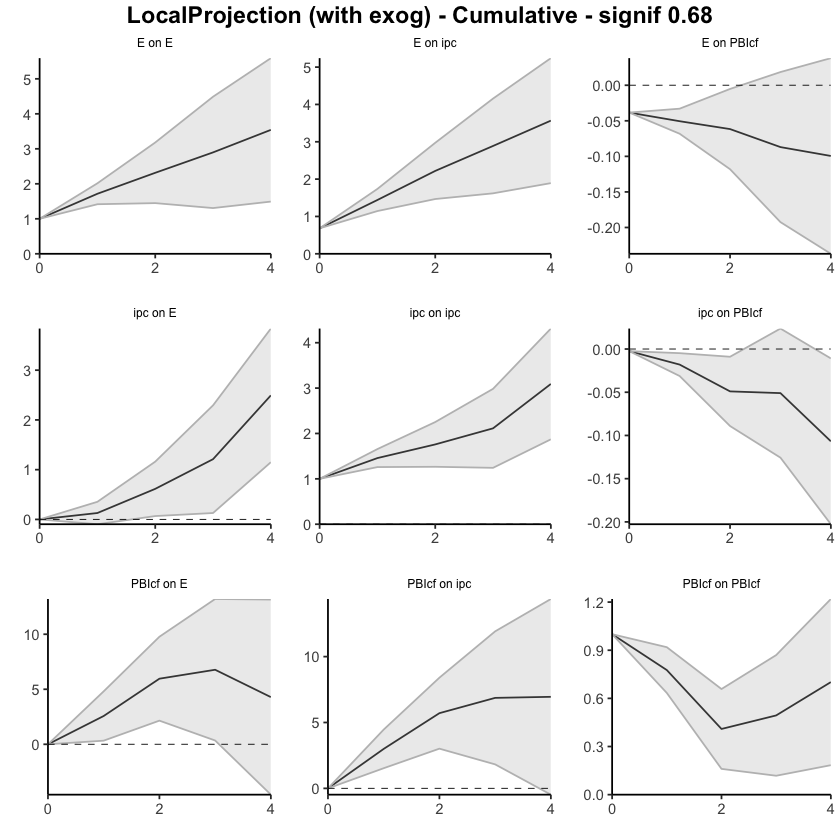

In [123]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1583813,-0.5401351,0.22337257
13,ipc,E,2,-0.3203617,-0.6684188,0.02769527
14,ipc,E,3,-1.4989342,-2.0648652,-0.93300328
15,ipc,E,4,-0.5450822,-0.9034901,-0.18667422


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.0000000
22,PBIcf,E,1,2.697545,0.7630763,4.6320141
23,PBIcf,E,2,2.671836,1.1391069,4.2045645
24,PBIcf,E,3,-1.033019,-2.5155195,0.4494817
25,PBIcf,E,4,-3.563740,-4.8766539,-2.2508261


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.7068492,0.70684918,0.7068492
2,E,ipc,1,0.7947635,0.33604319,1.2534837
3,E,ipc,2,0.6442607,0.05554003,1.2329814
4,E,ipc,3,0.1050013,-0.61050760,0.8205102
5,E,ipc,4,0.1270560,-0.60614777,0.8602598


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.00000000
27,PBIcf,ipc,1,2.9811258,1.4458907,4.51636089
28,PBIcf,ipc,2,2.0347549,0.7778841,3.29162574
29,PBIcf,ipc,3,-0.4729952,-1.5975396,0.65154915
30,PBIcf,ipc,4,-1.4334664,-2.8095163,-0.05741647


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.034490822,-0.03449082,-0.03449082
7,E,PBIcf,1,-0.009357555,-0.04333022,0.02461511
8,E,PBIcf,2,-0.006320103,-0.04868692,0.03604671
9,E,PBIcf,3,-0.013056628,-0.07008483,0.04397158
10,E,PBIcf,4,-0.002741306,-0.04189888,0.03641627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.030245707,-0.03024571,-0.03024571
17,ipc,PBIcf,1,0.022752578,-0.00013222,0.04563738
18,ipc,PBIcf,2,-0.002803745,-0.02774236,0.02213487
19,ipc,PBIcf,3,0.053504484,0.01374786,0.09326111
20,ipc,PBIcf,4,-0.007683528,-0.03405936,0.01869231


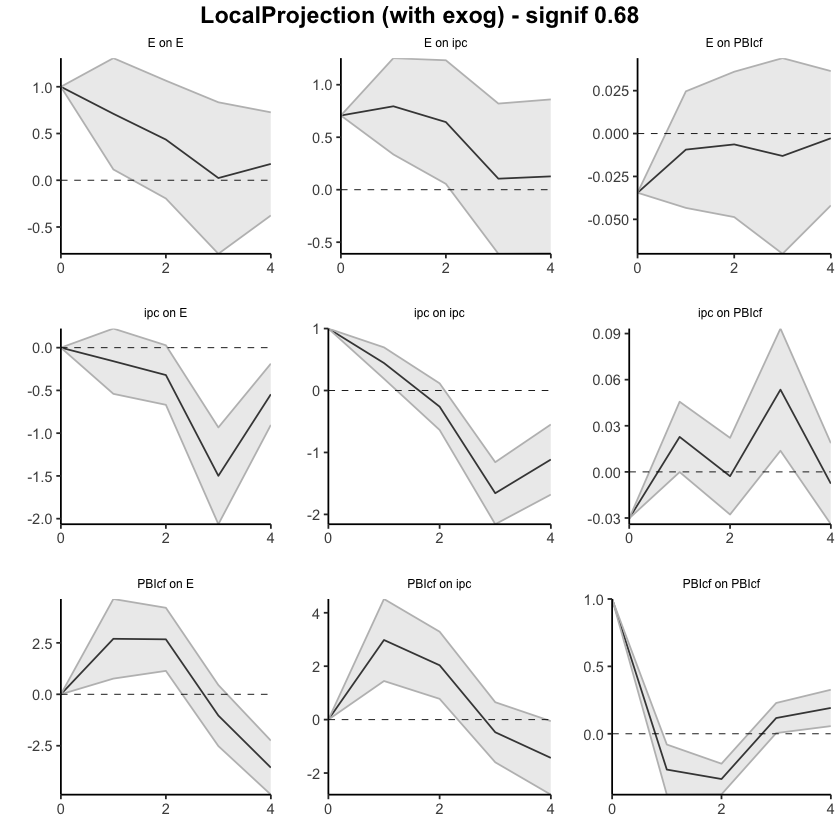

In [125]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.1583813,-0.5401351,0.2233726
13,ipc,E,2,-0.4787430,-1.2085538,0.2510678
14,ipc,E,3,-1.9776772,-3.2734190,-0.6819354
15,ipc,E,4,-2.5227594,-4.1769092,-0.8686097


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.697545,0.7630763,4.632014
23,PBIcf,E,2,5.369381,1.9021832,8.836579
24,PBIcf,E,3,4.336362,-0.6133363,9.286060
25,PBIcf,E,4,0.772622,-5.4899902,7.035234


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.7068492,0.7068492,0.7068492
2,E,ipc,1,1.5016126,1.0428924,1.9603329
3,E,ipc,2,2.1458733,1.0984324,3.1933142
4,E,ipc,3,2.2508746,0.4879248,4.0138244
5,E,ipc,4,2.3779306,-0.1182230,4.8740842


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.981126,1.4458907,4.516361
28,PBIcf,ipc,2,5.015881,2.2237748,7.807987
29,PBIcf,ipc,3,4.542885,0.6262352,8.459536
30,PBIcf,ipc,4,3.109419,-2.1832812,8.402119


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.03449082,-0.03449082,-0.03449082
7,E,PBIcf,1,-0.04384838,-0.07782104,-0.00987571
8,E,PBIcf,2,-0.05016848,-0.12650796,0.02617100
9,E,PBIcf,3,-0.06322511,-0.19659279,0.07014258
10,E,PBIcf,4,-0.06596641,-0.23849168,0.10655885


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.030245707,-0.03024571,-0.03024571
17,ipc,PBIcf,1,-0.007493129,-0.03037793,0.01539167
18,ipc,PBIcf,2,-0.010296875,-0.05812028,0.03752653
19,ipc,PBIcf,3,0.043207609,-0.04437242,0.13078764
20,ipc,PBIcf,4,0.035524081,-0.07843178,0.14947995


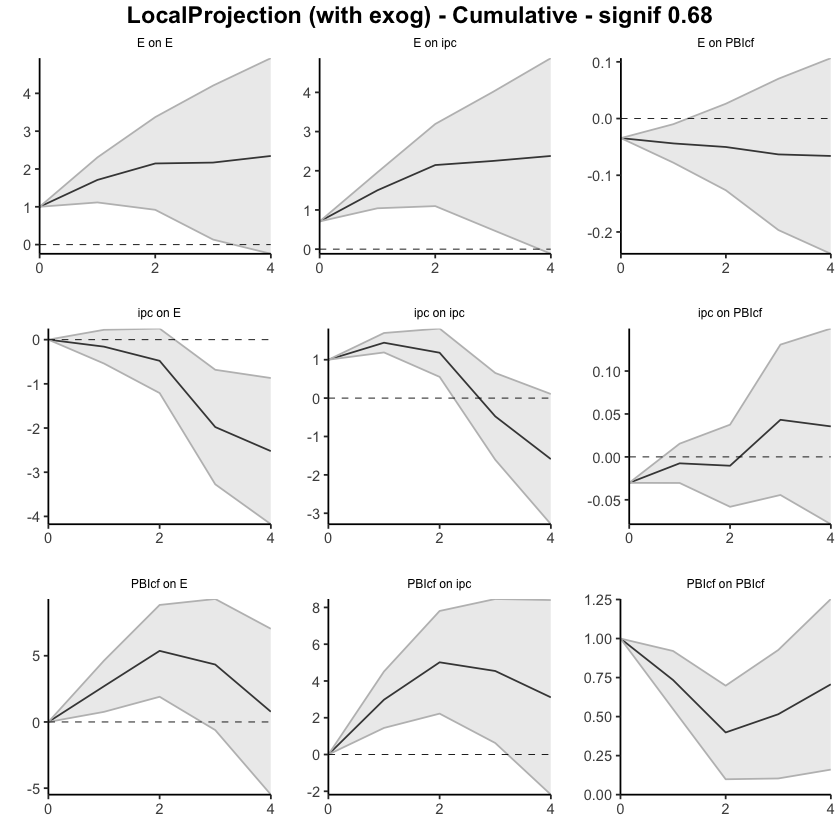

In [124]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.000000000
12,ipc,E,1,-0.2867396,-0.7125593,0.139080067
13,ipc,E,2,-0.2555018,-0.6504864,0.139482720
14,ipc,E,3,-1.5276116,-1.8476460,-1.207577206
15,ipc,E,4,-0.3321651,-0.6610647,-0.003265568


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.0000000,0.0000000,0.0000000
22,PBIcf,E,1,2.1582932,0.4056127,3.9109736
23,PBIcf,E,2,1.5134626,0.1914716,2.8354536
24,PBIcf,E,3,0.2473029,-1.3651432,1.8597491
25,PBIcf,E,4,-2.0392675,-3.4910348,-0.5875002


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.67217080,0.6721708,0.6721708
2,E,ipc,1,0.66877491,0.3232712,1.0142786
3,E,ipc,2,0.23985749,-0.3342723,0.8139873
4,E,ipc,3,-0.22524681,-0.6514441,0.2009505
5,E,ipc,4,0.02693853,-1.6020857,1.6559627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.0000000,0.0000000,0.000000
27,PBIcf,ipc,1,2.6026340,1.4236955,3.781572
28,PBIcf,ipc,2,1.3106015,-0.0326012,2.653804
29,PBIcf,ipc,3,0.3407097,-4.4677661,5.149185
30,PBIcf,ipc,4,0.4412448,-1.0483236,1.930813


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.028908928,-0.02890893,-0.02890893
7,E,PBIcf,1,-0.006318556,-0.04270255,0.03006544
8,E,PBIcf,2,-0.009193440,-0.05222100,0.03383412
9,E,PBIcf,3,-0.007133594,-0.08938052,0.07511333
10,E,PBIcf,4,-0.009678328,-0.04620198,0.02684532


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.04294845,-0.04294845,-0.042948449
17,ipc,PBIcf,1,0.04078495,0.01835768,0.063212219
18,ipc,PBIcf,2,-0.03923714,-0.06556587,-0.012908411
19,ipc,PBIcf,3,0.04760795,-0.00969833,0.104914228
20,ipc,PBIcf,4,-0.02906455,-0.05217562,-0.005953486


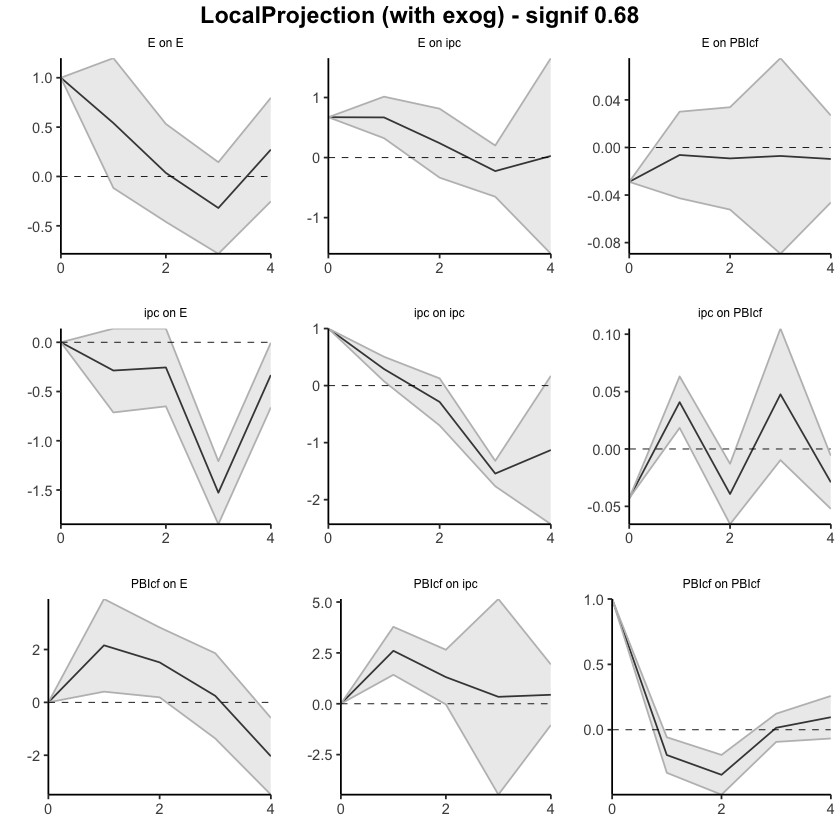

In [126]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIcf",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,-0.2867396,-0.7125593,0.1390801
13,ipc,E,2,-0.5422415,-1.3630457,0.2785628
14,ipc,E,3,-2.0698531,-3.2106917,-0.9290144
15,ipc,E,4,-2.4020182,-3.8717564,-0.9322800


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIcf,E,0,0.000000,0.0000000,0.000000
22,PBIcf,E,1,2.158293,0.4056127,3.910974
23,PBIcf,E,2,3.671756,0.5970843,6.746427
24,PBIcf,E,3,3.919059,-0.7680589,8.606176
25,PBIcf,E,4,1.879791,-4.2590937,8.018676


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6721708,0.672170795,0.6721708
2,E,ipc,1,1.3409457,0.995442029,1.6864494
3,E,ipc,2,1.5808032,0.661169697,2.5004367
4,E,ipc,3,1.3555564,0.009725556,2.7013872
5,E,ipc,4,1.3824949,-1.592360123,4.3573499


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIcf,ipc,0,0.000000,0.000000,0.000000
27,PBIcf,ipc,1,2.602634,1.423696,3.781572
28,PBIcf,ipc,2,3.913235,1.391094,6.435377
29,PBIcf,ipc,3,4.253945,-3.076672,11.584562
30,PBIcf,ipc,4,4.695190,-4.124995,13.515375


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIcf,0,-0.02890893,-0.02890893,-0.028908928
7,E,PBIcf,1,-0.03522748,-0.07161148,0.001156511
8,E,PBIcf,2,-0.04442092,-0.12383248,0.034990629
9,E,PBIcf,3,-0.05155452,-0.21321300,0.110103959
10,E,PBIcf,4,-0.06123285,-0.25941497,0.136949282


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIcf,0,-0.042948449,-0.04294845,-0.042948449
17,ipc,PBIcf,1,-0.002163502,-0.02459077,0.020263770
18,ipc,PBIcf,2,-0.041400644,-0.09015665,0.007355358
19,ipc,PBIcf,3,0.006207305,-0.09985498,0.112269586
20,ipc,PBIcf,4,-0.022857250,-0.15203060,0.106316100


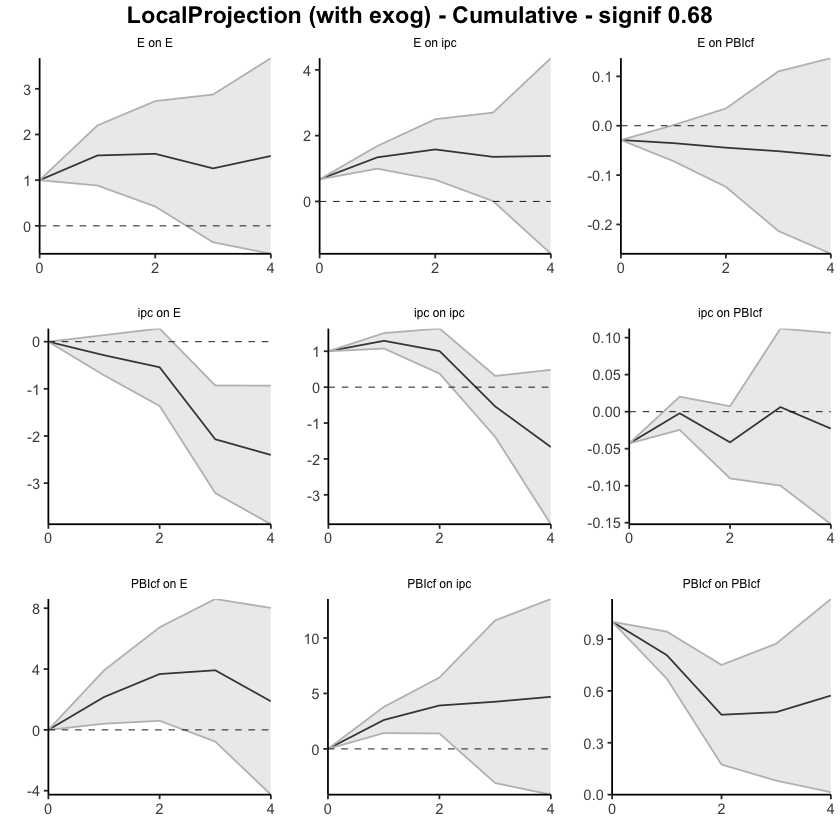

In [127]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIcf"), exog=c("Ptrigo_USA"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)